# ML clássico x Quantum-Enhanced ML na detecção de fraude em cartão de crédito

**TCC — Eric Costa Ciciliotti**

Compara dois pares de algoritmos da mesma família, um clássico e um quântico:

| Par | Clássico | Quântico |
|---|---|---|
| Máquinas de vetores de suporte | SVM (kernel RBF) | QSVM (kernel quântico de fidelidade) |
| Boosting | AdaBoost (*stumps*) | Quantum AdaBoost (classificadores variacionais fracos) |

**Dataset:** *Credit Card Fraud Detection* (ULB / Kaggle), com 284.807 transações e 492 fraudes (0,17%).

**Roteiro:**
1. Setup
2. Coleta e carregamento
3. Divisão treino/validação/teste (com a remoção de duplicatas)
4. Análise exploratória e pré-processamento (só no treino)
5. Treinamento
6. Ajuste de hiperparâmetros
7. Avaliação
8. Diagnóstico de overfitting/underfitting
9. Modelo final
10. Ruído quântico

**Como ler.** A partir da Seção 3, cada subseção abre com uma linha **"Papel no experimento"**, que diz se ela:
- **muda os dados** (remove linhas, divide, transforma colunas);
- **define opções do grid** (quais valores de um hiperparâmetro serão testados; quem escolhe entre eles é a
  validação cruzada);
- ou **só ilustra ou verifica** (gráficos, comparações e provas que ajudam a entender ou a confiar no protocolo,
  mas que não entram no pipeline nem no modelo).

O código reutilizável (transformers, modelos quânticos, métricas) fica no pacote `src/fraud_qml`, coberto por testes
`pytest`. Este notebook contém só o experimento e sua interpretação. As decisões de desenho, e o porquê de cada
uma, estão no `PLAN.md`.

## 1. Setup

### O que esta seção faz
- Importa as bibliotecas e as constantes do protocolo, que ficam em `fraud_qml.config`.
- Registra as versões exatas do ambiente.
- **Mede o custo da simulação quântica antes de qualquer desenho de experimento.**

### Por que o código de infraestrutura mora num pacote, e não no notebook
Quatro motivos:
- Os modelos quânticos deste trabalho são classes próprias, compatíveis com o scikit-learn. Código assim precisa de
  **teste automatizado**: um erro silencioso num kernel quântico invalida todos os resultados.
- O notebook fica legível: cada célula conta um passo do experimento, e não detalhes de implementação.
- O pacote é instalado em modo editável (`pip install -e .`). Uma correção no módulo vale imediatamente no notebook
  e nos testes.
- **Alternativa descartada:** notebook único e autocontido, como no trabalho anterior. É mais simples de
  compartilhar, mas deixaria as classes quânticas sem teste.

### Por que medir o custo já na primeira seção
Num projeto clássico, o custo raramente decide o desenho. Aqui ele decide:
- **QSVM:** cada amostra vira um *statevector*, isto é, a simulação de um circuito. Prever as ~56 mil transações
  do teste significa ~56 mil simulações.
- **Quantum AdaBoost:** cada rodada treina um circuito variacional. Cada passo do otimizador simula o circuito para
  todas as amostras de treino.

Medir agora diz quantos pontos o GridSearch da Seção 6 comporta. O conteúdo dos dados não altera o tempo de
simulação, só o formato (amostras × qubits). Por isso o benchmark usa dados sintéticos e pode vir antes do
carregamento.

In [1]:
# Verificação do kernel. Sem ela, rodar com o Python errado falha na célula seguinte com um
# ImportError confuso; aqui a mensagem já diz o que está errado e como corrigir.
import importlib.util
import sys

if importlib.util.find_spec("fraud_qml") is None:
    raise RuntimeError(
        f"Kernel errado ({sys.executable}). Este notebook precisa do ambiente do projeto (.venv). "
        "No VS Code: 'Select Kernel' (canto superior direito) → 'Python Environments' → '.venv (Python 3.12)'."
    )
print(f"Kernel correto: {sys.executable}")

Kernel correto: C:\Users\Erike\Documents\Faculdade\TCC\ML-x-QML\.venv\Scripts\python.exe


In [2]:
# Bibliotecas padrão
import subprocess
import sys
from collections import Counter
from dataclasses import asdict, replace
from itertools import combinations

from IPython.display import display

# Numéricas, tabulares e ML clássico
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Rectangle
from matplotlib.ticker import FuncFormatter
import numpy as np
import pandas as pd
from imblearn.pipeline import Pipeline as ImbPipeline
from scipy.stats import chi2_contingency, spearmanr
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, RobustScaler, StandardScaler
from sklearn.svm import SVC

# Computação quântica (Qiskit 2.x: feature maps e ansätze são funções que devolvem circuitos)
from qiskit import QuantumCircuit
from qiskit.circuit.library import real_amplitudes, zz_feature_map
from qiskit.quantum_info import SparsePauliOp
from qiskit_aer.primitives import EstimatorV2
from qiskit_machine_learning.kernels import FidelityStatevectorKernel

# Infraestrutura do projeto (src/fraud_qml)
from fraud_qml import config, tuning
from fraud_qml.data import (
    FRAUD_LABEL,
    LEGITIMATE_LABEL,
    PCA_FEATURE_COLUMNS,
    RAW_FEATURE_COLUMNS,
    TARGET_COLUMN,
    load_raw_dataset,
    remove_exact_duplicates,
    summarize_duplicates,
    validate_raw_contract,
    verify_dataset_integrity,
)
from fraud_qml.evaluation import (
    best_threshold_accuracy,
    bootstrap_pr_auc,
    compute_classification_metrics,
    percentile_interval,
    precision_at_prevalence,
    undersampling_corrected_probability,
)
from fraud_qml.features import (
    AUXILIARY_COLUMNS,
    MODEL_FEATURE_COLUMNS,
    SECONDS_PER_DAY,
    SECONDS_PER_HOUR,
    engineer_features,
    hour_of_day,
)
from fraud_qml.models import (
    InputEncoding,
    ModelSettings,
    ScoredFit,
    build_pipeline,
    build_adaboost_pipeline,
    build_dummy_pipeline,
    build_qsvm_pipeline,
    build_quantum_adaboost_pipeline,
    build_svm_pipeline,
    build_weak_quantum_classifier_pipeline,
    fit_and_score,
    quantum_encoding_steps,
    replay_boosting,
)
from fraud_qml.preprocessing import (
    ScalerName,
    build_amplitude_preprocessor,
    build_angle_preprocessor,
    make_undersampler,
)
from fraud_qml.quantum.diagnostics import (
    AngleConfiguration,
    EncodingConfiguration,
    KernelSubsample,
    amplitude_alignment_sweep,
    angle_alignment_sweep,
    weak_classifier_encoding_sweep,
)
from fraud_qml.quantum.encodings import build_angle_feature_map
from fraud_qml.quantum.kernels import (
    amplitude_kernel_matrix,
    angle_kernel_matrix,
    centered_kernel_target_alignment,
    off_diagonal_values,
)
from fraud_qml.quantum.variational import DEFAULT_MAX_ITERATIONS, build_ansatz
from fraud_qml.plotting import CLASS_COLORS, CLASS_NAMES, NEUTRAL_SERIES_COLOR, apply_plot_style
from fraud_qml.environment import collect_versions, current_git_commit
from fraud_qml.profiling import CostMeter
from fraud_qml.tuning import (
    CONFIGURATION_COLUMNS,
    INPUT_COLUMNS,
    GridSearchResult,
    SearchSpace,
    cached_grid_search,
    configuration_from_row,
    cv_folds,
    project_grid_seconds,
    project_search_spaces,
    run_grid_search,
    summarize_grid,
    write_grid_report,
)
from fraud_qml.splitting import (
    TEST_NAME,
    TRAIN_NAME,
    VALIDATION_NAME,
    STRATIFICATION_TOLERANCE_ROWS,
    find_cross_split_groups,
    stratified_three_way_split,
    validate_split,
)

pd.set_option("display.float_format", "{:,.4f}".format)
apply_plot_style()

In [3]:
# As constantes vêm do pacote para que notebook e testes usem exatamente os mesmos valores
protocol = pd.Series(
    {
        "RANDOM_STATE": config.RANDOM_STATE,
        "UNDERSAMPLING_SEEDS": config.UNDERSAMPLING_SEEDS,
        "Divisão treino/validação/teste": (config.TRAIN_SIZE, config.VALIDATION_SIZE, config.TEST_SIZE),
        "N_QUBITS (orçamento comum)": config.N_QUBITS,
        "N_JOBS (núcleos disponíveis)": config.N_JOBS,
        "Dataset": config.DATA_PATH.name,
        "Dataset encontrado": config.DATA_PATH.is_file(),
    },
    name="valor",
)
protocol.to_frame()

,valor
RANDOM_STATE,42
UNDERSAMPLING_SEEDS,"(42, 7, 123, 2024, 31415)"
Divisão treino/validação/teste,"(0.6, 0.2, 0.2)"
N_QUBITS (orçamento comum),5
N_JOBS (núcleos disponíveis),12
Dataset,creditcard.csv.zip
Dataset encontrado,True


In [4]:
# Versões e commit acompanham cada resultado salvo: sem isso, um número do TCC não é reproduzível
environment = pd.Series(collect_versions(), name="versão")
environment["commit"] = current_git_commit(config.PROJECT_ROOT) or "sem commit ainda"
environment["executável"] = sys.executable
environment.to_frame()

,versão
python,3.12.14
numpy,2.5.3
pandas,3.0.6
scipy,1.18.1
scikit-learn,1.9.1
imbalanced-learn,0.14.2
qiskit,2.5.2
qiskit-aer,0.17.2
qiskit-machine-learning,0.9.1
matplotlib,3.11.2


### 1.1 Benchmark de custo da simulação

Os tamanhos usados nas extrapolações vêm do protocolo:
- **Treino balanceado:** o treino terá ~284 fraudes (60% das 473 que sobram após remover duplicatas). O undersampling
  sorteia o mesmo número de legítimas, então são ≈ **568 amostras**.
- **Validação e teste:** ≈ **56.746 transações** cada, com a proporção real.

Três medições:
1. **Kernel quântico (QSVM):** matriz de Gram treino × treino para tamanhos crescentes, mais o kernel cruzado
   "muitas amostras × treino", que é o formato da predição.
2. **Circuito variacional (Quantum AdaBoost):** uma avaliação de ⟨Z⟩ para as 568 amostras. É o que cada passo do
   otimizador faz.
3. **SVM clássico** nos mesmos formatos, como ordem de grandeza de comparação.

O tempo é medido com `CostMeter(trace_python_memory=False)`. O `tracemalloc` intercepta cada alocação do Python e
deixaria o código mais lento do que ele é.

In [5]:
BALANCED_TRAIN_ROWS: int = 568
EVALUATION_ROWS: int = 56_746
GRAM_BENCHMARK_SIZES: tuple[int, ...] = (100, 300, 600)
CROSS_KERNEL_BENCHMARK_ROWS: int = 2_000

rng = np.random.default_rng(config.RANDOM_STATE)
benchmark_feature_map = zz_feature_map(config.N_QUBITS, reps=2, entanglement="linear")
quantum_kernel = FidelityStatevectorKernel(feature_map=benchmark_feature_map)


def synthetic_angles(n_rows: int) -> np.ndarray:
    """Dados sintéticos no intervalo de ângulos; só o formato importa para o tempo de simulação."""
    return rng.uniform(0.0, np.pi, size=(n_rows, config.N_QUBITS))


gram_rows: list[dict[str, float]] = []
for n_rows in GRAM_BENCHMARK_SIZES:
    # Dados novos a cada tamanho: o kernel guarda statevectors em cache, e reaproveitar
    # amostras mediria o cache, não a simulação
    samples = synthetic_angles(n_rows)
    with CostMeter(trace_python_memory=False) as meter:
        quantum_kernel.evaluate(x_vec=samples)
    gram_rows.append(
        {"amostras": n_rows, "segundos": meter.report.wall_seconds, "pico RSS (MiB)": meter.report.rss_peak_increase_mib}
    )

gram_benchmark = pd.DataFrame(gram_rows).set_index("amostras")
gram_benchmark

,segundos,pico RSS (MiB)
amostras,,
100,0.2248,0.9648
300,1.0258,0.0898
600,3.1024,3.1016


In [6]:
# Kernel cruzado: é o formato da predição (cada linha a classificar contra o treino).
# O custo por linha medido aqui é extrapolado linearmente para a validação/teste inteiros.
many_rows = synthetic_angles(CROSS_KERNEL_BENCHMARK_ROWS)
train_rows = synthetic_angles(BALANCED_TRAIN_ROWS)
with CostMeter(trace_python_memory=False) as meter:
    quantum_kernel.evaluate(x_vec=many_rows, y_vec=train_rows)

seconds_per_predicted_row = meter.report.wall_seconds / CROSS_KERNEL_BENCHMARK_ROWS
qsvm_prediction_seconds = seconds_per_predicted_row * EVALUATION_ROWS
print(f"Kernel cruzado {CROSS_KERNEL_BENCHMARK_ROWS} × {BALANCED_TRAIN_ROWS}: {meter.report.wall_seconds:.2f} s")
print(f"Estimativa para prever {EVALUATION_ROWS:,} linhas com o QSVM: {qsvm_prediction_seconds / 60:.1f} min")

Kernel cruzado 2000 × 568: 11.00 s
Estimativa para prever 56,746 linhas com o QSVM: 5.2 min


In [7]:
def build_variational_circuit(n_qubits: int, ansatz_reps: int) -> tuple[QuantumCircuit, np.ndarray, np.ndarray]:
    """Monta feature map + ansatz e devolve as posições dos parâmetros de dados e de pesos.

    O Qiskit ordena os parâmetros do circuito composto pelo nome. Por isso a matriz de
    valores é montada pelas posições, e não pela ordem de criação: assim não dá para
    trocar um ângulo de dado por um peso sem perceber.
    """
    feature_map = zz_feature_map(n_qubits, reps=2, entanglement="linear")
    ansatz = real_amplitudes(n_qubits, reps=ansatz_reps)
    circuit = feature_map.compose(ansatz)
    positions = {parameter: index for index, parameter in enumerate(circuit.parameters)}
    data_positions = np.array([positions[p] for p in feature_map.parameters])
    weight_positions = np.array([positions[p] for p in ansatz.parameters])
    return circuit, data_positions, weight_positions


BENCHMARK_ANSATZ_REPS: int = 1
variational_circuit, data_positions, weight_positions = build_variational_circuit(config.N_QUBITS, BENCHMARK_ANSATZ_REPS)
# ⟨Z⟩ no qubit 0 (o caractere mais à direita no Qiskit) é a saída do classificador
readout_observable = SparsePauliOp("I" * (config.N_QUBITS - 1) + "Z")
estimator = EstimatorV2()

weights = rng.uniform(-np.pi, np.pi, size=weight_positions.size)
parameter_values = np.empty((BALANCED_TRAIN_ROWS, variational_circuit.num_parameters))
parameter_values[:, data_positions] = train_rows
parameter_values[:, weight_positions] = weights

# A primeira chamada paga custos únicos (inicialização do Aer); ela é descartada da medição
estimator.run([(variational_circuit, readout_observable, parameter_values)]).result()
with CostMeter(trace_python_memory=False) as meter:
    expectations = estimator.run([(variational_circuit, readout_observable, parameter_values)]).result()[0].data.evs

seconds_per_forward_pass = meter.report.wall_seconds
print(f"Uma avaliação do circuito para {BALANCED_TRAIN_ROWS} amostras: {seconds_per_forward_pass * 1000:.1f} ms")
print(f"Saídas ⟨Z⟩ em [{expectations.min():.3f}, {expectations.max():.3f}] (formato {expectations.shape})")

Uma avaliação do circuito para 568 amostras: 173.9 ms
Saídas ⟨Z⟩ em [-0.752, 0.735] (formato (568,))


In [8]:
# Ordem de grandeza do SVM clássico nos mesmos formatos, para comparação
labels = rng.integers(0, 2, size=BALANCED_TRAIN_ROWS)
classical_svm = SVC(kernel="rbf")
with CostMeter(trace_python_memory=False) as fit_meter:
    classical_svm.fit(train_rows, labels)
evaluation_rows = synthetic_angles(EVALUATION_ROWS)
with CostMeter(trace_python_memory=False) as predict_meter:
    classical_svm.decision_function(evaluation_rows)
print(f"SVM clássico: treino {fit_meter.report.wall_seconds * 1000:.1f} ms | "
      f"predição de {EVALUATION_ROWS:,} linhas {predict_meter.report.wall_seconds:.2f} s")

SVM clássico: treino 29.8 ms | predição de 56,746 linhas 1.79 s


In [9]:
# Extrapolação para o experimento. Os valores do Quantum AdaBoost são hipóteses de trabalho
# (100 passos do COBYLA por classificador fraco, 20 rodadas, 5 folds); a Seção 6 os ajusta.
HYPOTHETICAL_OPTIMIZER_STEPS: int = 100
HYPOTHETICAL_BOOSTING_ROUNDS: int = 20
CV_FOLDS: int = 5
fold_train_fraction = (CV_FOLDS - 1) / CV_FOLDS

gram_seconds_568 = np.interp(BALANCED_TRAIN_ROWS, gram_benchmark.index, gram_benchmark["segundos"])
qadaboost_fit_seconds = (
    seconds_per_forward_pass * fold_train_fraction * HYPOTHETICAL_OPTIMIZER_STEPS * HYPOTHETICAL_BOOSTING_ROUNDS
)
qadaboost_prediction_seconds = (
    seconds_per_forward_pass / BALANCED_TRAIN_ROWS * EVALUATION_ROWS * HYPOTHETICAL_BOOSTING_ROUNDS
)

cost_estimates = pd.DataFrame(
    {
        "operação": [
            "QSVM: Gram do treino (568 × 568)",
            f"QSVM: prever {EVALUATION_ROWS:,} linhas",
            "QAdaBoost: 1 fit em um fold (hipótese)",
            "QAdaBoost: 1 ponto do grid com 5 folds (hipótese)",
            f"QAdaBoost: prever {EVALUATION_ROWS:,} linhas (hipótese)",
            "SVM clássico: fit + predição",
        ],
        "minutos": [
            gram_seconds_568 / 60,
            qsvm_prediction_seconds / 60,
            qadaboost_fit_seconds / 60,
            qadaboost_fit_seconds * CV_FOLDS / 60,
            qadaboost_prediction_seconds / 60,
            (fit_meter.report.wall_seconds + predict_meter.report.wall_seconds) / 60,
        ],
    }
).set_index("operação")
cost_estimates

,minutos
operação,
QSVM: Gram do treino (568 × 568),0.0480
"QSVM: prever 56,746 linhas",5.2027
QAdaBoost: 1 fit em um fold (hipótese),4.6383
QAdaBoost: 1 ponto do grid com 5 folds (hipótese),23.1913
"QAdaBoost: prever 56,746 linhas (hipótese)",5.7923
SVM clássico: fit + predição,0.0303


### 1.2 Leitura do benchmark

O dataset foi encontrado e há 12 núcleos disponíveis.

**Custo por operação:**

| Operação | Custo medido |
|---|---|
| 1 statevector (5 qubits, ZZ com reps=2) | ≈ 4 ms (2.568 statevectors em 10 a 12 s) |
| Gram do treino balanceado (568 × 568) | ≈ 3 s |
| QSVM: prever 56.746 linhas | ≈ 5 min |
| 1 avaliação do circuito variacional nas 568 amostras | ≈ 0,2 s |
| SVM clássico: treino | ≈ 40 ms |
| SVM clássico: prever 56.746 linhas | 2 s |

Os tempos mudam alguns por cento de uma execução para outra. A tabela usa valores arredondados; as saídas
acima mostram os desta execução.

**O que isso significa para o desenho:**

1. **O QSVM é barato de treinar e caro de prever.**
   - O custo cresce **linearmente** com o número de amostras: cada amostra vira um circuito simulado.
   - O produto interno entre statevectors de 32 amplitudes custa microssegundos. O tempo está em **montar e simular
     cada circuito**.
   - Consequência 1: o GridSearch do QSVM, feito no treino balanceado, comporta um grid **amplo** (scalers, ranges,
     feature maps, C).
   - Consequência 2: cada avaliação na validação ou no teste reais custa ~5 min. Por isso só os vencedores de cada
     grid vão para a validação.
2. **O Quantum AdaBoost é o gargalo do projeto.**
   - Hipótese de trabalho: 100 passos do otimizador, 20 rodadas e 5 folds.
   - Nessa hipótese, **cada ponto do grid custa de 20 a 30 min**. Um grid de 6 a 10 pontos leva de 2 a 5 horas.
   - Por isso o grid dele é pequeno e cacheado em disco.
   - O classificador fraco *deve* ser fraco (poucos passos, circuito raso). Isso é teoria do boosting e, ao mesmo
     tempo, economia.
3. **O custo computacional já é um resultado do TCC.**
   - O SVM clássico treina em menos de 0,1 s e prevê 56 mil linhas em 2 s: **de 100 a mais de 10.000 vezes mais barato**
     que as contrapartes quânticas.
   - Isso ainda em simulação ideal e sem fila de hardware (Havenstein et al., 2018).
4. **Memória não é o limite nesta escala. O número de qubits é.**
   - Um statevector de *n* qubits ocupa 16 · 2ⁿ bytes (2ⁿ números complexos de 16 bytes).
   - Com 5 qubits são 512 bytes. Os aumentos de RSS medidos (até cerca de 3 MiB) são ruído do processo.
   - Com 30 qubits seriam 16 GiB, toda a RAM desta máquina.
   - O custo exponencial está no número de qubits, não no número de amostras. É exatamente por isso que a
     literatura reduz a dimensionalidade antes da codificação (Seção 4).

**Atualização (Seção 5.4).** Os tempos acima são do caminho **circuito a circuito**, o que existia quando esta
seção foi escrita. A Seção 5 passou a simular os estados em lote e a aplicar o ansatz como matriz: pontuar a
validação com o QSVM leva menos de 20 s, e não 5 min, e um ajuste do Quantum AdaBoost leva segundos. Com isso, três
frases desta leitura deixam de valer como estão: "só os vencedores de cada grid vão para a validação", "cada ponto
do grid custa de 20 a 30 min" e "de 100 a mais de 10.000 vezes mais barato". O que continua valendo: o custo cresce
com o número de linhas simuladas e dobra a cada qubit a mais. A leitura do custo na Seção 5.4 refaz a conta.

**Otimização registrada para a Seção 5:** o kernel do `qiskit-machine-learning` simula um circuito por vez em
Python. Se a predição de ~5 min por modelo virar gargalo, é possível simular os statevectors em lote no Aer.
O resultado matemático é idêntico e só muda a velocidade; um teste automatizado vai comparar as duas
implementações.

## 2. Coleta e carregamento

### Origem dos dados
O *Credit Card Fraud Detection* reúne transações reais de portadores de cartão europeus, feitas em **dois dias de
setembro de 2013**. Foi coletado pela Worldline em parceria com o Machine Learning Group da Université Libre de
Bruxelles (Dal Pozzolo et al., 2015) e está disponível publicamente no Kaggle.

### O que esta seção faz, e o que ela deliberadamente não faz
- **Verifica a identidade do arquivo.** O SHA-256 do CSV é comparado com o do original do Kaggle. Assim, qualquer
  pessoa (inclusive a banca) sabe que os números do TCC saíram exatamente deste arquivo.
- **Verifica o contrato dos dados:**
  - número de linhas e de fraudes;
  - nomes e ordem das colunas;
  - tipos numéricos;
  - ausência de valores faltantes;
  - rótulos em {0, 1}.
- Se algo divergir, o código **para com uma mensagem clara** em vez de seguir produzindo números diferentes em
  silêncio. Todas as violações são listadas de uma vez.
- **Apresenta as variáveis** pelo que a documentação do dataset diz delas.
- **Não descreve o conteúdo.** Faixas, médias e assimetria das features são exploração, e a exploração só
  acontece depois do split, no conjunto de treino (Seção 4).
- **Não transforma nada.** A remoção de duplicatas e o split ficam na Seção 3; a engenharia de features, na
  Seção 4. Separar *carregar* de *transformar* mantém o dado bruto disponível como referência.

In [10]:
with CostMeter() as load_meter:
    dataset_sha256 = verify_dataset_integrity(config.DATA_PATH)
    raw_df = load_raw_dataset(config.DATA_PATH)
validate_raw_contract(raw_df)

print(f"SHA-256 do CSV: {dataset_sha256[:16]}… — idêntico ao arquivo original do Kaggle")
print(f"Contrato cumprido: {raw_df.shape[0]:,} linhas × {raw_df.shape[1]} colunas")
print(f"Verificação + leitura: {load_meter.report.wall_seconds:.1f} s | "
      f"DataFrame em memória: {raw_df.memory_usage(deep=True).sum() / 1024**2:.1f} MiB")

SHA-256 do CSV: 76274b691b16a6c4… — idêntico ao arquivo original do Kaggle
Contrato cumprido: 284,807 linhas × 31 colunas
Verificação + leitura: 2.9 s | DataFrame em memória: 67.4 MiB


In [11]:
# O formato da tabela (tipos e contagens), sem exibir valores: olhar o conteúdo é exploração e fica para a Seção 4
pd.DataFrame({"tipo": raw_df.dtypes.astype(str), "valores não nulos": raw_df.notna().sum()}).loc[
    ["Time", "V1", "V28", "Amount", TARGET_COLUMN]
].style.set_caption("Formato das colunas (primeira e última V como exemplo)")

,tipo,valores não nulos
Time,float64,284807
V1,float64,284807
V28,float64,284807
Amount,float64,284807
Class,int64,284807


### Dicionário de variáveis

Por confidencialidade, 28 das 30 variáveis preditoras não chegam em sua forma original. O banco aplicou uma
**Análise de Componentes Principais (PCA)** às variáveis reais (que nunca foram divulgadas) e publicou apenas os
componentes, `V1` a `V28`. Duas consequências acompanham o trabalho todo:
- **Não há interpretação de negócio para `V1`–`V28`.** Mesmo quando uma delas separa bem as fraudes (Seção 4.5),
  não dá para saber *o que* ela mede.
- **Elas já são descorrelacionadas entre si e centradas em zero**, porque é isso que o PCA produz. Isso vai pesar na
  discussão sobre aplicar um segundo PCA para caber nos qubits (Seção 4).

In [12]:
# Só o que a documentação do dataset diz de cada variável. Faixas e estatísticas são exploração:
# ficam para a Seção 4, calculadas só no treino
variable_dictionary = pd.DataFrame(
    [
        {
            "variável": "Time",
            "papel": "feature",
            "significado": "segundos desde a 1ª transação do conjunto (não é hora do dia)",
        },
        {
            "variável": "V1 … V28",
            "papel": "feature",
            "significado": "componentes de PCA das variáveis originais (anonimizadas)",
        },
        {
            "variável": "Amount",
            "papel": "feature",
            "significado": "valor da transação (moeda não informada no dataset)",
        },
        {
            "variável": TARGET_COLUMN,
            "papel": "alvo (rótulo)",
            "significado": f"{FRAUD_LABEL} = fraude, {LEGITIMATE_LABEL} = legítima",
        },
    ]
).set_index("variável")
variable_dictionary

,papel,significado
variável,,
Time,feature,segundos desde a 1ª transação do conjunto (não...
V1 … V28,feature,componentes de PCA das variáveis originais (an...
Amount,feature,valor da transação (moeda não informada no dat...
Class,alvo (rótulo),"1 = fraude, 0 = legítima"


In [13]:
class_counts = raw_df[TARGET_COLUMN].value_counts().sort_index()
class_summary = pd.DataFrame(
    {"transações": class_counts, "proporção (%)": class_counts / len(raw_df) * 100}
).rename(index={LEGITIMATE_LABEL: "legítima", FRAUD_LABEL: "fraude"})

legitimate_per_fraud = class_counts[LEGITIMATE_LABEL] / class_counts[FRAUD_LABEL]
always_legitimate_accuracy = class_counts[LEGITIMATE_LABEL] / len(raw_df)

print(f"1 fraude a cada {legitimate_per_fraud:,.0f} transações legítimas")
print(f"Acurácia de um 'modelo' que responde sempre 'legítima': {always_legitimate_accuracy:.4%}")
class_summary.style.format({"proporção (%)": "{:.4f}"}).set_caption("Contagem de classes na base original (contrato)")

1 fraude a cada 578 transações legítimas
Acurácia de um 'modelo' que responde sempre 'legítima': 99.8273%


,transações,proporção (%)
Class,,
legítima,284315,99.8273
fraude,492,0.1727


### 2.1 Leitura dos dados carregados

**Integridade.** O CSV é byte a byte o original do Kaggle, e todo o contrato foi cumprido:
- 284.807 linhas, 31 colunas numéricas, na ordem esperada;
- nenhum valor ausente;
- 492 fraudes, rótulos só 0 e 1.

O passo "eliminação de valores nulos" da metodologia do TCC fica, portanto, **verificado e vazio**: não há nulos a
remover. Esse fato é garantido por código, não por suposição.

**Desbalanceamento extremo.**
- Há 1 fraude a cada 578 transações legítimas (0,17%).
- Um "modelo" que responde sempre "legítima" tem **99,83% de acurácia** e detecta **zero** fraudes. Por isso a
  acurácia só é interpretada ao lado de precisão, recall, F1, MCC e PR-AUC (Seção 7).
- Consequência para o undersampling: igualar as classes significa treinar com **~0,17% das transações legítimas**,
  o preço imposto pelo custo da simulação quântica.

**O que esta seção não olhou, de propósito.** Faixas, médias, caudas e assimetria das features são **exploração**,
e a exploração só acontece depois do split, no conjunto de treino (Seção 4). Daqui saem só as contagens do
contrato. A única coisa dita sobre o conteúdo vem da documentação do dataset: `Time` são segundos corridos desde a
primeira transação, ao longo de dois dias, e não a hora do dia.

## 3. Divisão treino / validação / teste

### O que esta seção faz
- **Remove as duplicatas exatas.** Além do contrato da Seção 2, é a única operação feita na base inteira.
- Divide a base deduplicada em **treino (60%)**, **validação (20%)** e **teste (20%)**, estratificando pelo rótulo.
- Verifica o split com `assert`s e procura **quase-duplicatas** que atravessem as partes.

### Por que dividir antes de explorar
Vazamento não é só ajustar um scaler com linhas de teste. Há uma forma mais sutil: **decidir** olhando dados que
deveriam estar isolados. Se a exploração é feita na base inteira, cada escolha que sai dela (qual transformação
aplicar, quais features parecem úteis, que opções entram no grid) carrega informação da validação e do teste, mesmo
que nenhum parâmetro seja reaproveitado. Os guias do scikit-learn (*Common pitfalls*, 12.2) e do imbalanced-learn
(*Common pitfalls*, 9.1) pedem a mesma coisa: separar primeiro.

A regra deste notebook:
- **Na base inteira:** só o contrato dos dados (Seção 2) e a remoção de duplicatas (3.1), que precisa vir antes do
  split para que uma cópia não fique no treino e outra no teste.
- **Depois do split:** de validação e teste só se **contam** linhas e rótulos e se fazem checagens de integridade
  (3.3.1). Toda a exploração (Seção 4) usa só o treino.
- **Dentro do pipeline:** tudo que aprende com os dados (scaler, PCA, seleção, undersampling), reajustado em cada
  fold.

> **Histórico.** Uma versão anterior deste notebook fazia a análise exploratória antes do split. A ordem foi
> corrigida em 2026-10-07 (CC7 em `methodological_issues.md`).

### Cada parte tem um papel

| Parte | Para que serve | Proporção de fraudes | Onde é usada |
|---|---|---|---|
| Treino (60%) | Explorar os dados, ajustar o pipeline (undersampling → scaler → redutor → modelo) e rodar a validação cruzada que escolhe os hiperparâmetros | real no split; 50% depois do undersampling | Seções 4 a 8 |
| Validação (20%) | Comparar modelos e escolher o limiar de decisão | real (~0,17%) | Seções 5 a 8 |
| Teste (20%) | **Uma única** avaliação do modelo final | real (~0,17%) | só na Seção 9 |

Por que não bastam treino e teste? A validação cruzada roda no treino **balanceado**, em que a ROC-AUC é válida,
mas a PR-AUC, a precisão e o limiar dependem da proporção real. Essas escolhas precisam de um conjunto com 0,17%
de fraudes que o modelo não viu. E essas escolhas deixam o score da validação otimista (o vencedor foi escolhido
olhando para ele), por isso o teste fica separado e é usado uma vez só.

### 3.1 Duplicatas

> **Papel no experimento:** **muda os dados.** Remove as cópias exatas da base, antes do split.

O TCC V4 argumentava por **manter** as duplicatas: sem um identificador de transação, não dá para saber se duas
linhas iguais são um erro de coleta ou duas compras legítimas idênticas. O argumento é razoável para um modelo
treinado com 170 mil linhas. Neste trabalho ele não se sustenta, por causa do vazamento:

- Se uma linha e sua cópia caem uma no treino e outra no teste, o modelo é avaliado numa transação que **já viu**.
  O acerto nela mede memória, não generalização.
- O efeito é pequeno na base inteira, mas aqui o treino terá ~568 linhas. Cada fraude repetida pesa muito mais.

A célula abaixo mede o tamanho do problema.

In [14]:
duplicate_summary = summarize_duplicates(raw_df)
legitimate_extra_copies = duplicate_summary.extra_copies - duplicate_summary.fraud_extra_copies

pd.Series(
    {
        "linhas que têm cópia idêntica": duplicate_summary.rows_in_duplicate_groups,
        "cópias extras (seriam removidas)": duplicate_summary.extra_copies,
        "  das quais fraudes": duplicate_summary.fraud_extra_copies,
        "% das fraudes que são cópias": duplicate_summary.fraud_extra_copies / class_counts[FRAUD_LABEL] * 100,
        "% das legítimas que são cópias": legitimate_extra_copies / class_counts[LEGITIMATE_LABEL] * 100,
        "grupos com mesmas features e rótulos diferentes": duplicate_summary.conflicting_label_groups,
    },
    name="valor",
).to_frame().style.format("{:,.2f}").set_caption("Duplicatas exatas na base original")

,valor
linhas que têm cópia idêntica,"1,854.00"
cópias extras (seriam removidas),"1,081.00"
das quais fraudes,19.00
% das fraudes que são cópias,3.86
% das legítimas que são cópias,0.37
grupos com mesmas features e rótulos diferentes,0.00


In [15]:
# Chance de as duas cópias de um par caírem em conjuntos DIFERENTES num split 60/20/20:
# 1 − P(ambas no treino) − P(ambas na validação) − P(ambas no teste)
split_fractions = np.array([config.TRAIN_SIZE, config.VALIDATION_SIZE, config.TEST_SIZE])
pair_straddles_split = 1 - np.sum(split_fractions**2)
print(f"Probabilidade de um par duplicado ficar separado entre conjuntos: {pair_straddles_split:.0%}")

clean_df = remove_exact_duplicates(raw_df)
assert not clean_df.duplicated().any()
assert duplicate_summary.conflicting_label_groups == 0, "features idênticas com rótulos diferentes exigiriam outra regra"

clean_class_counts = clean_df[TARGET_COLUMN].value_counts()
print(f"Após remover duplicatas: {len(clean_df):,} transações, {clean_class_counts[FRAUD_LABEL]} fraudes "
      f"({clean_class_counts[FRAUD_LABEL] / len(clean_df):.4%})")

Probabilidade de um par duplicado ficar separado entre conjuntos: 56%


Após remover duplicatas: 283,726 transações, 473 fraudes (0.1667%)


### 3.2 Por que o split vem antes do balanceamento

> **Papel no experimento:** **só ilustra ou verifica.** Nada daqui entra no pipeline nem no modelo. O classificador do gráfico é hipotético; a subseção justifica a ordem do protocolo.

Os artigos de QML neste dataset (El Alami, EA1; Grossi, GR1) balanceiam **antes** de dividir, e o teste fica
balanceado (50/50 no El Alami, ~52/48 no Grossi). O problema não é só de "realismo": a **precisão** muda com a
proporção de fraudes, mesmo com o mesmo modelo. Recall e taxa de falsos positivos são calculados dentro de cada
classe e não mudam com a proporção; a precisão mistura as duas classes.

O gráfico aplica a fórmula (`precision_at_prevalence`, com teste) a um classificador hipotético com recall de 90%.
A "proporção real" é a da base deduplicada: uma contagem de rótulos, como as do contrato.

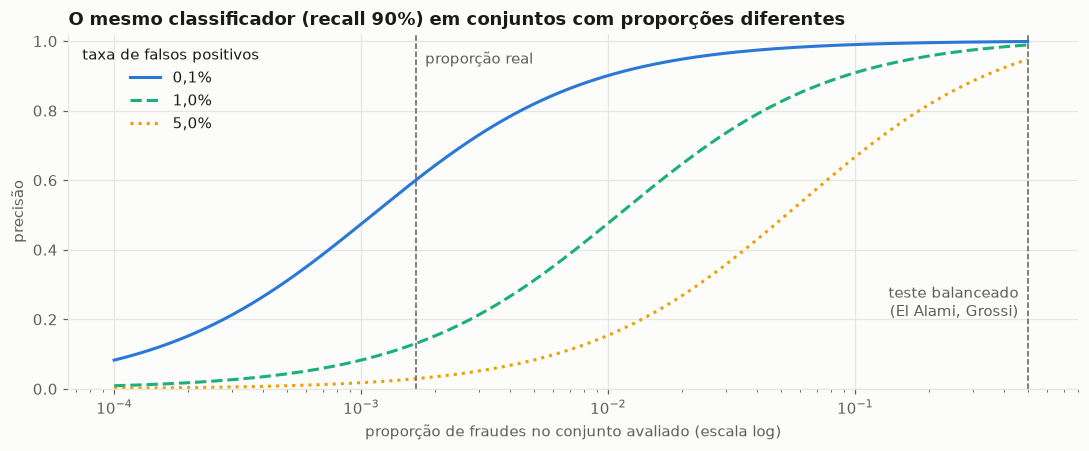

,teste 50/50,"proporção real (0,1667%)"
taxa de falsos positivos,,
0.1%,0.999,0.600
1.0%,0.989,0.131
5.0%,0.947,0.029


In [16]:
ILLUSTRATIVE_RECALL: float = 0.9
ILLUSTRATIVE_FALSE_POSITIVE_RATES: tuple[float, ...] = (0.001, 0.01, 0.05)
BALANCED_PREVALENCE: float = 0.5
FALSE_POSITIVE_STYLES: dict[float, dict[str, str]] = {
    0.001: {"color": "#2a78d6", "linestyle": "-"},
    0.01: {"color": "#1baf7a", "linestyle": "--"},
    0.05: {"color": "#eda100", "linestyle": ":"},
}

real_prevalence = clean_df[TARGET_COLUMN].mean()
prevalence_grid = np.logspace(-4, np.log10(BALANCED_PREVALENCE), 200)

fig, ax = plt.subplots(figsize=(10, 4.2))
for false_positive_rate, style in FALSE_POSITIVE_STYLES.items():
    precision_curve = precision_at_prevalence(ILLUSTRATIVE_RECALL, false_positive_rate, prevalence_grid)
    # Cor e estilo de linha diferentes por curva: a legenda não depende só da cor
    ax.plot(prevalence_grid, precision_curve, label=f"{false_positive_rate:.1%}".replace(".", ","), **style)
# Rótulos das linhas verticais onde não há curvas: no alto, à direita da proporção real; embaixo, à esquerda do 50/50
for prevalence, label, height, offset, alignment in (
    (real_prevalence, "proporção real", 0.97, 6, "left"),
    (BALANCED_PREVALENCE, "teste balanceado\n(El Alami, Grossi)", 0.3, -6, "right"),
):
    ax.axvline(prevalence, color="#5f5e58", linewidth=1, linestyle="--")
    ax.annotate(label, xy=(prevalence, height), xytext=(offset, 0), textcoords="offset points", ha=alignment, va="top",
                color="#5f5e58")
ax.legend(title="taxa de falsos positivos", loc="upper left")
ax.set_xscale("log")
ax.set_xlim(right=BALANCED_PREVALENCE * 1.6)
ax.set(title=f"O mesmo classificador (recall {ILLUSTRATIVE_RECALL:.0%}) em conjuntos com proporções diferentes",
       xlabel="proporção de fraudes no conjunto avaliado (escala log)", ylabel="precisão", ylim=(0, 1.02))
plt.tight_layout()
plt.show()

precision_by_prevalence = pd.DataFrame(
    {
        "teste 50/50": [float(precision_at_prevalence(ILLUSTRATIVE_RECALL, rate, BALANCED_PREVALENCE))
                        for rate in ILLUSTRATIVE_FALSE_POSITIVE_RATES],
        f"proporção real ({real_prevalence:.4%})".replace(".", ","): [float(precision_at_prevalence(ILLUSTRATIVE_RECALL, rate, real_prevalence))
                                                   for rate in ILLUSTRATIVE_FALSE_POSITIVE_RATES],
    },
    index=pd.Index([f"{rate:.1%}" for rate in ILLUSTRATIVE_FALSE_POSITIVE_RATES], name="taxa de falsos positivos"),
)
precision_by_prevalence.style.format("{:.3f}").set_caption(
    f"Precisão do mesmo classificador (recall {ILLUSTRATIVE_RECALL:.0%}) nas duas proporções"
)

### 3.3 O split

> **Papel no experimento:** **muda os dados.** Define as três partes (treino, validação e teste) usadas até o fim.

**Como.** O `train_test_split` do scikit-learn só divide em duas partes por chamada. O
`stratified_three_way_split` faz em dois estágios: primeiro separa o teste (20%); depois tira a validação do
restante, com a fração reescalada (0,2 / 0,8 = 25% do restante) para que cada parte tenha a fração pedida **da base
inteira**. Os dois estágios são estratificados pelo rótulo.

**Por que estratificar.** Com 473 fraudes, um sorteio simples de 20% dá, em média, 94,6 fraudes, mas pode dar
bem menos ou bem mais. A estratificação fixa a contagem de cada classe em cada parte (a menos de arredondamento).

**O que o `validate_split` verifica** (e lista todas as violações juntas, como o contrato da Seção 2):
- **disjunção:** nenhuma linha em duas partes;
- **cobertura:** a união das partes é exatamente a base;
- **tamanho** de cada parte e **contagem de cada classe**, a menos de 2 linhas (cada estágio arredonda no máximo
  1 linha por classe).

O split é feito nas **colunas originais**. As features dos modelos só são criadas na Seção 4, depois de a
exploração do treino dizer quais transformações fazem sentido. O índice original é preservado: cada linha continua
rastreável até o arquivo bruto. O `fingerprint` (hash dos índices de cada parte) vai para os resultados salvos, para
que números de sessões diferentes só sejam comparados quando o split for o mesmo.

In [17]:
SPLIT_LABELS: dict[str, str] = {TRAIN_NAME: "treino", VALIDATION_NAME: "validação", TEST_NAME: "teste"}
SPLIT_FRACTIONS: dict[str, float] = {
    TRAIN_NAME: config.TRAIN_SIZE, VALIDATION_NAME: config.VALIDATION_SIZE, TEST_NAME: config.TEST_SIZE
}

dataset_split = stratified_three_way_split(clean_df, random_state=config.RANDOM_STATE)
validate_split(clean_df, dataset_split)  # levanta SplitError listando todas as violações
split_parts = dataset_split.parts()
# Sufixo _raw: colunas originais. As features dos modelos são criadas na Seção 4, a partir do treino
train_raw_df, validation_raw_df, test_raw_df = dataset_split.train, dataset_split.validation, dataset_split.test

# As garantias centrais, explícitas no notebook (o validate_split já as verifica, junto com os tamanhos)
total_frauds = int(clean_df[TARGET_COLUMN].sum())
assert all(first.index.intersection(second.index).empty for first, second in combinations(split_parts.values(), 2)), \
    "linha em duas partes"
assert sum(len(part) for part in split_parts.values()) == len(clean_df), "linhas perdidas ou repetidas"
for name in (VALIDATION_NAME, TEST_NAME):
    # Nenhum balanceamento antes do split: validação e teste têm a fração esperada das fraudes, não a metade das linhas
    assert abs(split_parts[name][TARGET_COLUMN].sum() - SPLIT_FRACTIONS[name] * total_frauds) < STRATIFICATION_TOLERANCE_ROWS

# Nesta seção e na 4, de validação e teste só se contam linhas e rótulos e se fazem checagens de integridade
# (3.3.1). Nenhuma exploração sai deles: a validação só entra na Seção 5, para avaliar, e o teste, na Seção 9
print(f"Split válido. Fingerprint: {dataset_split.fingerprint()[:16]}…")

split_summary = pd.DataFrame(
    {
        "linhas": [len(part) for part in split_parts.values()],
        "fraudes": [int(part[TARGET_COLUMN].sum()) for part in split_parts.values()],
        "fraudes se a fração fosse exata": [SPLIT_FRACTIONS[name] * total_frauds for name in split_parts],
    },
    index=[SPLIT_LABELS[name] for name in split_parts],
)
split_summary.loc["base inteira"] = [len(clean_df), total_frauds, float(total_frauds)]
split_summary["% da base"] = split_summary["linhas"] / len(clean_df) * 100
split_summary["% de fraudes"] = split_summary["fraudes"] / split_summary["linhas"] * 100
split_summary.style.format(
    {"linhas": "{:,.0f}", "fraudes": "{:.0f}", "fraudes se a fração fosse exata": "{:.1f}",
     "% da base": "{:.1f}", "% de fraudes": "{:.4f}"}
).set_caption("Split estratificado 60/20/20 da base deduplicada")

Split válido. Fingerprint: 04d958c0d5744326…


,linhas,fraudes,fraudes se a fração fosse exata,% da base,% de fraudes
treino,"170,235",284,283.8,60.0,0.1668
validação,"56,745",94,94.6,20.0,0.1657
teste,"56,746",95,94.6,20.0,0.1674
base inteira,"283,726",473,473.0,100.0,0.1667


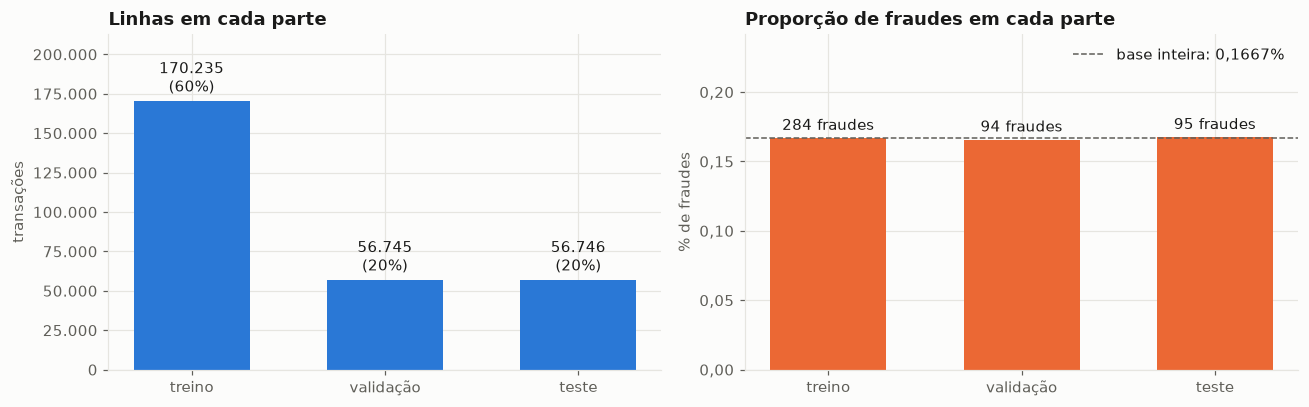

In [18]:
def brazilian_integer(value: int) -> str:
    """Inteiro com ponto como separador de milhar."""
    return f"{value:,}".replace(",", ".")


split_names = [SPLIT_LABELS[name] for name in split_parts]
fig, (rows_ax, rate_ax) = plt.subplots(1, 2, figsize=(12, 3.8))

row_bars = rows_ax.bar(split_names, split_summary.loc[split_names, "linhas"], color=NEUTRAL_SERIES_COLOR, width=0.6)
rows_ax.bar_label(row_bars, labels=[f"{brazilian_integer(int(n))}\n({share:.0f}%)" for n, share in
                                    split_summary.loc[split_names, ["linhas", "% da base"]].to_numpy()], padding=3)
rows_ax.set(title="Linhas em cada parte", ylabel="transações", ylim=(0, split_summary.loc["treino", "linhas"] * 1.25))

rate_bars = rate_ax.bar(split_names, split_summary.loc[split_names, "% de fraudes"], color=CLASS_COLORS[FRAUD_LABEL], width=0.6)
rate_ax.bar_label(rate_bars, labels=[f"{int(n)} fraudes" for n in split_summary.loc[split_names, "fraudes"]], padding=3)
rate_ax.axhline(real_prevalence * 100, color="#5f5e58", linewidth=1, linestyle="--",
                label=f"base inteira: {real_prevalence:.4%}".replace(".", ","))
rate_ax.legend(loc="upper right")
rate_ax.set(title="Proporção de fraudes em cada parte", ylabel="% de fraudes", ylim=(0, real_prevalence * 100 * 1.45))
rows_ax.yaxis.set_major_formatter(FuncFormatter(lambda value, _: brazilian_integer(int(value))))
rate_ax.yaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value:.2f}".replace(".", ",")))
plt.tight_layout()
plt.show()

#### 3.3.1 Duas checagens de integridade do split

> **Papel no experimento:** **só ilustra ou verifica.** Nada daqui entra no pipeline nem no modelo. São verificações do split; o split temporal da tabela é uma alternativa descartada, não usada.

**Quase-duplicatas.** A Seção 3.1 removeu as linhas idênticas em **todas** as colunas. Sobram linhas iguais em
tudo menos o `Time`: a mesma compra (mesmas `V1`–`V28` e mesmo `Amount`) repetida em outro horário. Se uma cópia
fica no treino e outra na validação, o modelo seria avaliado numa transação praticamente já vista. A célula conta
quantos desses grupos atravessam o split e estima quantas dessas linhas chegam de fato ao treino **depois** do
undersampling, que é o que o modelo vê.

**Os dois dias da coleta.** O split é aleatório, não temporal: cada parte mistura transações dos dois dias. A
primeira tabela conta quantas linhas de cada dia caíram em cada parte; para isso lê o `Time` das três partes, e
nada mais delas. A segunda mostra como ficaria a alternativa, um split temporal 60/20/20, **simulado só com as
linhas de treino** ordenadas no tempo: as taxas de fraude por janela são exploração, e exploração só usa o treino.
A discussão está na leitura (3.4).

In [19]:
NEAR_DUPLICATE_KEY: list[str] = [*PCA_FEATURE_COLUMNS, "Amount"]
crossing = find_cross_split_groups(dataset_split, NEAR_DUPLICATE_KEY)

train_frauds = int(train_raw_df[TARGET_COLUMN].sum())
train_legitimate = len(train_raw_df) - train_frauds
# O undersampling sorteia tantas legítimas quanto há fraudes: cada legítima do treino tem essa chance de ser usada
legitimate_keep_probability = train_frauds / train_legitimate
expected_crossing_rows_seen = crossing.rows_by_split[TRAIN_NAME] * legitimate_keep_probability

print(f"Quase-duplicatas (mesmas V1–V28 e Amount) que atravessam o split: {crossing.groups:,} grupos, {crossing.rows:,} linhas")
print(f"  por classe: {crossing.rows_by_label}  |  por parte: {crossing.rows_by_split}")
print(f"  chance de uma legítima do treino sobreviver ao undersampling: {legitimate_keep_probability:.4%}")
print(f"  linhas desses grupos que o modelo vê no treino, em média: {expected_crossing_rows_seen:.1f}")

# Checagem de integridade: o Time das três partes é lido só para contar quantas linhas de cada dia caíram em cada uma
split_names = [SPLIT_LABELS[name] for name in split_parts]
collection_day = (clean_df["Time"] // SECONDS_PER_DAY).astype(int).add(1).rename("dia da coleta")
membership_labels = dataset_split.membership().map(SPLIT_LABELS)
day_mix = pd.crosstab(membership_labels, collection_day.loc[membership_labels.index], normalize="index") * 100
day_mix = day_mix.loc[split_names].rename(columns=lambda day: f"% das linhas do dia {day}")

# Como ficaria um split temporal 60/20/20, simulado SÓ com as linhas de treino ordenadas no tempo (CC12; não é usado)
TEMPORAL_WINDOWS: list[str] = ["primeiros 60% do tempo", "20% seguintes", "últimos 20%"]
time_ordered = train_raw_df.sort_values("Time", kind="stable")
temporal_bounds = [0, *(np.cumsum([config.TRAIN_SIZE, config.VALIDATION_SIZE]) * len(time_ordered)).astype(int),
                   len(time_ordered)]
temporal_parts = {name: time_ordered.iloc[start:end]
                  for name, start, end in zip(TEMPORAL_WINDOWS, temporal_bounds[:-1], temporal_bounds[1:])}
temporal_summary = pd.DataFrame(
    {
        "início (h)": [part["Time"].min() / SECONDS_PER_HOUR for part in temporal_parts.values()],
        "fim (h)": [part["Time"].max() / SECONDS_PER_HOUR for part in temporal_parts.values()],
        "fraudes": [int(part[TARGET_COLUMN].sum()) for part in temporal_parts.values()],
        "% de fraudes": [part[TARGET_COLUMN].mean() * 100 for part in temporal_parts.values()],
    },
    index=list(temporal_parts),
)
temporal_summary["duração (h)"] = temporal_summary["fim (h)"] - temporal_summary["início (h)"]

display(day_mix.style.format("{:.1f}").set_caption("Composição de cada parte por dia da coleta"))
temporal_summary.style.format("{:.1f}", subset=["início (h)", "fim (h)", "duração (h)"]).format(
    {"fraudes": "{:.0f}", "% de fraudes": "{:.4f}"}
).set_caption("Alternativa descartada: split temporal 60/20/20, simulado dentro do treino (horas desde a primeira transação)")

Quase-duplicatas (mesmas V1–V28 e Amount) que atravessam o split: 2,770 grupos, 8,960 linhas
  por classe: {0: 8960}  |  por parte: {'train': 4548, 'validation': 2194, 'test': 2218}
  chance de uma legítima do treino sobreviver ao undersampling: 0.1671%
  linhas desses grupos que o modelo vê no treino, em média: 7.6


dia da coleta,% das linhas do dia 1,% das linhas do dia 2
split,,
treino,50.7,49.3
validação,51.0,49.0
teste,51.1,48.9


,início (h),fim (h),fraudes,% de fraudes,duração (h)
primeiros 60% do tempo,0.000000,33.486667,199,0.1948,33.486667
20% seguintes,33.486944,40.377778,41,0.1204,6.890833
últimos 20%,40.378056,47.996667,44,0.1292,7.618611


### 3.4 Leitura dos resultados

**Duplicatas: removidas, e com mais motivo do que parecia.**
- Há 1.081 cópias extras. **3,9% das fraudes são cópias, contra 0,37% das legítimas**, ou seja, fraudes se repetem
  ~10× mais. Uma explicação plausível é a mesma cobrança fraudulenta registrada mais de uma vez.
- Nenhum grupo tem features iguais com rótulos diferentes, então a remoção não esconde nenhuma contradição.
- Num split 60/20/20, **56% dos pares duplicados** ficariam separados entre conjuntos. Sem a remoção, mais da metade
  das fraudes repetidas seria "testada" com uma cópia vista no treino.
- Resultado: 283.726 transações e 473 fraudes (0,1667%).

**A precisão depende da proporção de fraudes, e é por isso que o split vem antes do balanceamento.** O mesmo
classificador (recall 90%, 1% de falsos positivos) tem precisão **0,989** num teste 50/50 e **0,131** na proporção
real. Com 5% de falsos positivos, 0,947 contra 0,029. A precisão de 1,00 do El Alami (EA1), medida num teste 50/50, e
a acurácia do Grossi (GR1), num teste de ~52/48, não dizem nada sobre o cenário real.

**O split saiu como planejado.** 170.235 / 56.745 / 56.746 linhas (60,0 / 20,0 / 20,0%) e 284 / 94 / 95 fraudes. A
proporção de fraudes fica entre 0,1657% e 0,1674% nas três partes, contra 0,1667% na base inteira; o
`validate_split` e os `assert`s passaram.

**Quase-duplicatas existem, mas não contaminam.** 2.770 grupos (8.960 linhas) com as mesmas `V1`–`V28` e o mesmo
`Amount` atravessam o split, **todos de legítimas** (nenhuma fraude). O undersampling mantém 0,1671% das legítimas
do treino, então, em média, só 7,6 dessas linhas chegam ao modelo. Fica registrado (CC13); não há o que corrigir.

**O split aleatório mistura os dois dias, e o split temporal não seria melhor com estes dados.** Cada parte tem
entre 50,7% e 51,1% de linhas do dia 1. O split aleatório mede o desempenho em transações **do mesmo período** do
treino; um split temporal (treinar no passado, avaliar no futuro) mediria também a degradação ao longo do tempo. Com
48 horas de dados, porém, as janelas de validação e de teste seriam curtas e tardias. Simulado dentro do treino, um
split temporal 60/20/20 deixaria as duas últimas janelas com 6,9 e 7,6 horas (33,5–40,4 h e 40,4–48,0 h, isto é, da
manhã do dia 2 até a meia-noite): **nenhuma das duas cobriria a madrugada**, onde estão os picos de fraude (4.3).
Elas teriam 41 e 44 fraudes do treino, com taxas de 0,1204% e 0,1292%, contra 0,1948% nos primeiros 60% do tempo. A
diferença medida misturaria o horário com a passagem do tempo, sem separar um do outro. Além disso, o protocolo
aprovado e a literatura comparada usam o split aleatório estratificado. É uma limitação declarada (CC12): os
resultados não estimam a degradação ao longo do tempo.

**O que muda na Seção 4:** a exploração usa só as 170.235 linhas de treino (`train_raw_df`). De validação e teste,
até aqui, só foram lidos contagens e rótulos e feitas duas checagens de integridade: a de quase-duplicatas e a de
dias, que lê o `Time` das três partes só para contar linhas por dia.

## 4. Análise exploratória e pré-processamento (só no treino)

Tudo nesta seção usa **apenas as linhas de treino**. A seção tem duas partes:
- **4.1 a 4.5:** escalas, `Amount`, `Time` e as features que mais separam fraude de legítima. No meio, as
  transformações **linha a linha**, decididas aqui e aplicadas depois às três partes.
- **4.6 em diante:** escalonamento (Standard, Robust, MinMax), codificação quântica (ângulo × amplitude), seleção de
  features e undersampling, no **treino balanceado**, que é o que os modelos vão ver.

### O que sai daqui, e o que não sai
- **Sai:** decisões de desenho. Quais transformações linha a linha aplicar e quais opções entram no grid da Seção 6.
- **Não sai:** nenhum valor ajustado. Médias, eixos de PCA e features escolhidas aqui não são reaproveitados: o
  pipeline reajusta tudo em cada fold, e a escolha entre as opções é da validação cruzada.

O ranking de informação mútua, por exemplo, **mostra** quais features separam as classes, mas não **escolhe**
nenhuma. A seleção de features é refeita dentro do pipeline.

**Conhecimento prévio, declarado.** O Trabalho Humberto já explorou esta base inteira, e duas ideias vieram de
lá para o plano antes desta seção existir: o `log1p(Amount)` e a hora em seno/cosseno. Uma versão anterior deste
notebook também explorou a base inteira (CC7). Não dá para "desver" isso. O que esta seção garante é que cada
número e cada justificativa do TCC saem **só do treino**, e que nenhum valor ajustado fora do pipeline chega aos
modelos.

### 4.1 Escalas e caudas

> **Papel no experimento:** **só ilustra ou verifica.** Nada daqui entra no pipeline nem no modelo. Mostra por que o escalonamento é necessário; os scalers em si moram no pipeline.

Antes de qualquer transformação, a pergunta é em que escala cada variável chega. Métodos que medem distância ou
variância (SVM com kernel RBF, kernels quânticos, PCA) são dominados pela variável de maior escala, e um único
valor extremo muda o mínimo ou o máximo de uma coluna inteira.

**Os termos da tabela:**
- **Média:** a soma dos valores dividida pela quantidade.
- **Desvio padrão** (*standard deviation*, abreviado *std* nas bibliotecas): o tamanho típico da distância de cada
  valor até a média. Conta: subtrai a média de cada valor, eleva ao quadrado, tira a média desses quadrados e a
  raiz. Exemplo: os valores 2, 4, 4, 4, 5, 5, 7 e 9 têm média 5 e desvio padrão 2; os valores 1, 9, 2 e 8 têm a
  mesma média e desvio padrão 3,54, porque estão mais espalhados. É a "escala" de uma coluna.
- **Mínimo e máximo:** o menor e o maior valor da coluna.
- **Extremo, em desvios da média:** a que distância da média fica o valor mais afastado dela, medida em desvios
  padrão. Numa distribuição normal, passar de 4 ou 5 desvios já é raríssimo; valores muito acima disso indicam uma
  **cauda longa**, isto é, alguns pontos muito distantes do resto.

Os dois maiores valores das colunas de desvio padrão e de extremo aparecem destacados em ciano escuro.

**Todas as 30 colunas de entrada, e não algumas escolhidas.** Uma versão anterior desta análise mostrava `Time`,
`Amount`, `V1` e `V14`. A `V14` estava ali porque já sabíamos, da base inteira e do trabalho anterior, que ela separa
fraudes: escolher o que olhar a partir desse conhecimento é a mesma falha do CC7 em escala menor. E a escolha mudava
o resultado: a razão de escala entre `Time` e "as `V`" dependia de qual `V` entrava no denominador (NC12). Daqui em
diante, a exploração mostra todas as colunas ou seleciona a partir de uma saída já calculada no treino (como o
ranking da 4.5).

In [20]:
# Nomes das estatísticas em português: o leitor não precisa conhecer as abreviações do pandas (mean, std...)
SCALE_STATISTICS: dict[str, str] = {"mean": "média", "std": "desvio padrão", "min": "mínimo", "max": "máximo"}
EXTREME_COLUMN: str = "extremo (desvios da média)"
# Ciano escuro com texto branco fixo: não é o azul das legítimas nem o laranja das fraudes, e o contraste (7,3:1) não
# depende do tema do editor. Sem fixar o texto, o tema claro poria texto preto sobre o fundo escuro (2,4:1)
HIGHLIGHT_COLOR: str = "#006161"
HIGHLIGHT_TEXT_COLOR: str = "#ffffff"
HIGHLIGHTED_PER_COLUMN: int = 2

# Todas as colunas de entrada, na ordem do arquivo: nenhuma escolhida a partir do que já se sabia da base inteira
train_scales = train_raw_df[list(RAW_FEATURE_COLUMNS)].describe().T[list(SCALE_STATISTICS)].rename(columns=SCALE_STATISTICS)
# A que distância da média (em desvios padrão) fica o valor mais extremo de cada coluna: mede o peso da cauda
train_scales[EXTREME_COLUMN] = (
    np.maximum((train_scales["máximo"] - train_scales["média"]).abs(), (train_scales["mínimo"] - train_scales["média"]).abs())
    / train_scales["desvio padrão"]
)
v_std = train_scales.loc[list(PCA_FEATURE_COLUMNS), "desvio padrão"]
v_extreme = train_scales.loc[list(PCA_FEATURE_COLUMNS), EXTREME_COLUMN]
train_pca_values = train_raw_df[list(PCA_FEATURE_COLUMNS)]

print(f"Treino: {len(train_raw_df):,} linhas, {train_frauds} fraudes")
print(f"Desvio padrão das 28 V: de {v_std.min():.2f} ({v_std.idxmin()}) a {v_std.max():.2f} ({v_std.idxmax()})")
for column in ("Time", "Amount"):
    column_std = train_scales.loc[column, "desvio padrão"]
    print(f"Desvio padrão de {column} ÷ desvio padrão das V: de {column_std / v_std.max():,.0f}× a {column_std / v_std.min():,.0f}×")
print(f"Faixa de V1–V28 no treino: [{train_pca_values.min().min():,.1f}; {train_pca_values.max().max():,.1f}]")
print(f"Valor mais extremo de cada V: de {v_extreme.min():.0f} a {v_extreme.max():.0f} desvios da média "
      f"(mediana {v_extreme.median():.0f}); em {(v_extreme > 10).sum()} das 28 passa de 10")
print(f"Período coberto pelo treino: {train_raw_df['Time'].max() / SECONDS_PER_HOUR:.1f} horas")


def highlight_largest(column: pd.Series) -> list[str]:
    """Destaque (fundo ciano escuro, texto branco) nos maiores valores da coluna."""
    largest = column.nlargest(HIGHLIGHTED_PER_COLUMN).index
    style = f"background-color: {HIGHLIGHT_COLOR}; color: {HIGHLIGHT_TEXT_COLOR}"
    return [style if row in largest else "" for row in column.index]


train_scales.style.format("{:,.2f}").apply(highlight_largest, subset=["desvio padrão", EXTREME_COLUMN]).set_caption(
    "Escala das 30 colunas de entrada, no treino (destaque: os 2 maiores desvios padrão e as 2 caudas mais extremas)"
)

Treino: 170,235 linhas, 284 fraudes
Desvio padrão das 28 V: de 0.33 (V28) a 1.95 (V1)
Desvio padrão de Time ÷ desvio padrão das V: de 24,345× a 142,653×
Desvio padrão de Amount ÷ desvio padrão das V: de 126× a 740×
Faixa de V1–V28 no treino: [-73.2; 39.4]
Valor mais extremo de cada V: de 6 a 102 desvios da média (mediana 20); em 23 das 28 passa de 10
Período coberto pelo treino: 48.0 horas


,média,desvio padrão,mínimo,máximo,extremo (desvios da média)
Time,"94,935.86","47,513.48",0.00,"172,788.00",2.00
V1,0.00,1.95,-56.41,2.45,28.90
V2,-0.01,1.66,-72.72,21.47,43.85
V3,0.00,1.50,-31.81,9.38,21.15
V4,-0.00,1.42,-5.60,16.88,11.90
V5,0.01,1.36,-32.09,34.80,25.56
V6,-0.00,1.32,-26.16,21.39,19.77
V7,0.00,1.20,-41.51,34.30,34.63
V8,0.00,1.17,-73.22,19.59,62.69
V9,-0.00,1.10,-13.43,15.59,14.24


### 4.2 `Amount`: o valor da transação

> **Papel no experimento:** **só ilustra ou verifica.** Nada daqui entra no pipeline nem no modelo. A análise **fundamenta** uma transformação, o `log1p(Amount)`, que é aplicada aos dados na 4.4. Os gráficos e o corte do eixo são só para visualizar.

Duas perguntas guiam a análise:
- `Amount` é assimétrica, a ponto de pedir uma transformação?
- Fraude e legítima têm valores diferentes?

**Os termos da tabela.** Cada coluna descreve **só as transações de uma classe** (legítimas ou fraudes).
- **Média:** a soma dos valores dividida pela quantidade.
- **Mediana:** o valor do meio. Metade das transações tem valor abaixo dela, e metade acima. Ao contrário da média,
  ela não é puxada por poucos valores muito altos.
- **Percentil:** o percentil *p* é o valor abaixo do qual ficam *p*% dos dados. A mediana é o percentil 50. Exemplo
  com os dados: o percentil 99 das legítimas é 1.008,99, então 99% das legítimas têm valor de até 1.008,99, e só 1%
  passa disso.
- **As porcentagens são de cada classe, e não da base.** "% com valor = 0" na coluna "fraude" é a fração **das
  fraudes** cujo `Amount` é zero; na coluna "legítima", a fração das legítimas.
- **Assimetria** (*skewness*): mede o quanto a distribuição pende para um lado. Zero é simétrica; um valor positivo
  indica uma cauda longa à direita, isto é, poucos valores muito altos e a maioria baixa.

**Por que o gráfico da esquerda corta o eixo no percentil 99.** O maior valor do treino é 19.656,53. Com o eixo indo
até ele, cada uma das 60 barras do histograma teria 328 de largura, e 94,3% das transações cairiam na primeira
barra: o gráfico viraria uma barra só. Cortando no percentil 99, o eixo mostra o formato onde estão 99% dos dados.
Os valores acima do corte **não são descartados**: ficam empilhados na última barra (o pico na borda direita).
- O corte é o **maior** dos percentis 99 das duas classes (1.391,70, o das fraudes), e não o do treino inteiro
  (1.011,16). Como 99,8% das linhas são legítimas, o percentil do treino inteiro é, na prática, o das legítimas, e
  empilharia 1,76% das fraudes na borda, em vez de 1,06%.
- 99, e não 95 ou 99,9, é um compromisso: mostra quase todos os dados e tira só a cauda extrema. Nenhuma conclusão
  depende desse número, e o gráfico da direita, em escala log, não precisa de corte: comprimir a cauda é justamente
  o que o `log1p` faz.

As distribuições são comparadas por **densidade** (proporção dentro de cada classe), e não por contagem. Com
centenas de legítimas para cada fraude, um histograma de contagens mostraria só as legítimas.

In [21]:
def amount_profile(amounts: pd.Series) -> dict[str, float]:
    """Resumo de uma distribuição de valores, com foco na cauda e nos valores muito baixos.

    Os rótulos são frases, e não abreviações, para a tabela ser lida sem conhecer os termos de antemão.
    """
    return {
        "valor médio (média)": amounts.mean(),
        "valor do meio (mediana: metade abaixo, metade acima)": amounts.median(),
        "percentil 99 (99% das transações têm valor até aqui)": amounts.quantile(0.99),
        "maior valor": amounts.max(),
        "% das transações com valor = 0": (amounts == 0).mean() * 100,
        "% das transações com valor até 1,00": (amounts <= 1).mean() * 100,
        "% das transações com valor = 1,00": (amounts == 1).mean() * 100,
        "% das transações com valor = 99,99": (amounts == 99.99).mean() * 100,
        "assimetria (0 = simétrica; positiva = cauda longa à direita)": amounts.skew(),
    }


pd.DataFrame(
    {CLASS_NAMES[label]: amount_profile(group["Amount"]) for label, group in train_raw_df.groupby(TARGET_COLUMN)}
).style.format("{:,.2f}").set_caption(
    "Valor da transação (Amount) por classe, no treino. Cada coluna descreve só as transações daquela classe, "
    "e cada % é sobre a própria classe"
)

,legítima,fraude
valor médio (média),88.11,118.87
"valor do meio (mediana: metade abaixo, metade acima)",22.05,11.86
percentil 99 (99% das transações têm valor até aqui),"1,008.99","1,391.70"
maior valor,"19,656.53","2,125.87"
% das transações com valor = 0,0.63,5.28
"% das transações com valor até 1,00",10.61,33.45
"% das transações com valor = 1,00",4.72,21.48
"% das transações com valor = 99,99",0.10,6.34
assimetria (0 = simétrica; positiva = cauda longa à direita),15.22,4.16


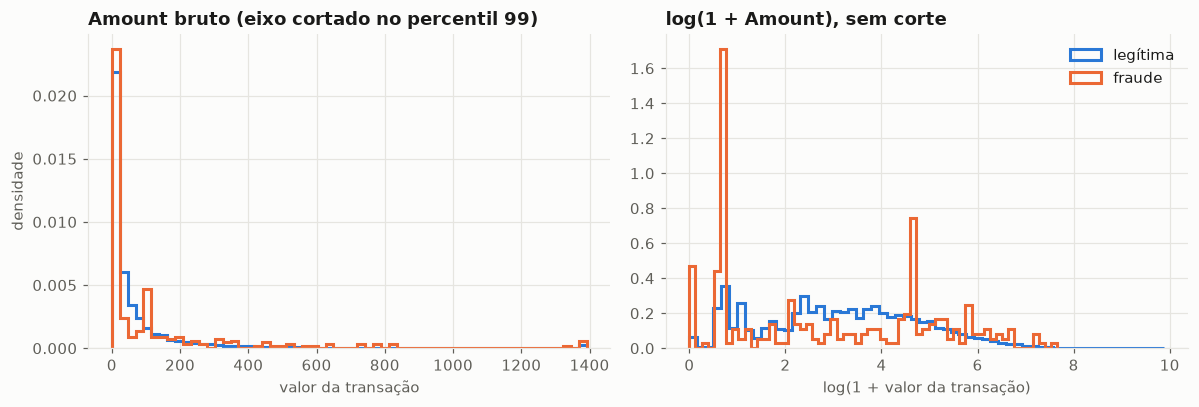

In [22]:
fig, (raw_ax, log_ax) = plt.subplots(1, 2, figsize=(11, 3.8))
# Corte no MAIOR percentil 99 entre as classes: o percentil do treino inteiro é, na prática, o das legítimas,
# e empilharia parte das fraudes na borda do gráfico
amount_clip = train_raw_df.groupby(TARGET_COLUMN)["Amount"].quantile(0.99).max()

for label, group in train_raw_df.groupby(TARGET_COLUMN):
    style = {"color": CLASS_COLORS[label], "label": CLASS_NAMES[label], "histtype": "step", "linewidth": 2, "density": True}
    raw_ax.hist(group["Amount"].clip(upper=amount_clip), bins=60, **style)
    log_ax.hist(np.log1p(group["Amount"]), bins=60, **style)

raw_ax.set(title="Amount bruto (eixo cortado no percentil 99)", xlabel="valor da transação", ylabel="densidade")
log_ax.set(title="log(1 + Amount), sem corte", xlabel="log(1 + valor da transação)")
log_ax.legend()
plt.tight_layout()
plt.show()

### 4.3 `Time`: de segundos corridos para hora do dia

> **Papel no experimento:** **só ilustra ou verifica.** Nada daqui entra no pipeline nem no modelo. A análise **fundamenta** a hora em seno e cosseno, aplicada aos dados na 4.4.

`Time` conta segundos desde a primeira transação, ao longo de dois dias. O que pode se repetir no futuro é a
**hora do dia**, e não o "segundo 93.000 da coleta".

O dataset não informa a que horas foi a primeira transação. A conversão supõe que `Time = 0` é meia-noite, e o
volume por hora permite checar essa suposição: se ela estiver certa, o vale de movimento cai na madrugada.

Os dois gráficos têm medidas diferentes (contagem e taxa). Por isso ficam em painéis separados, e não em dois eixos
y no mesmo gráfico. A última célula compara a taxa de fraude entre os dois dias da coleta.

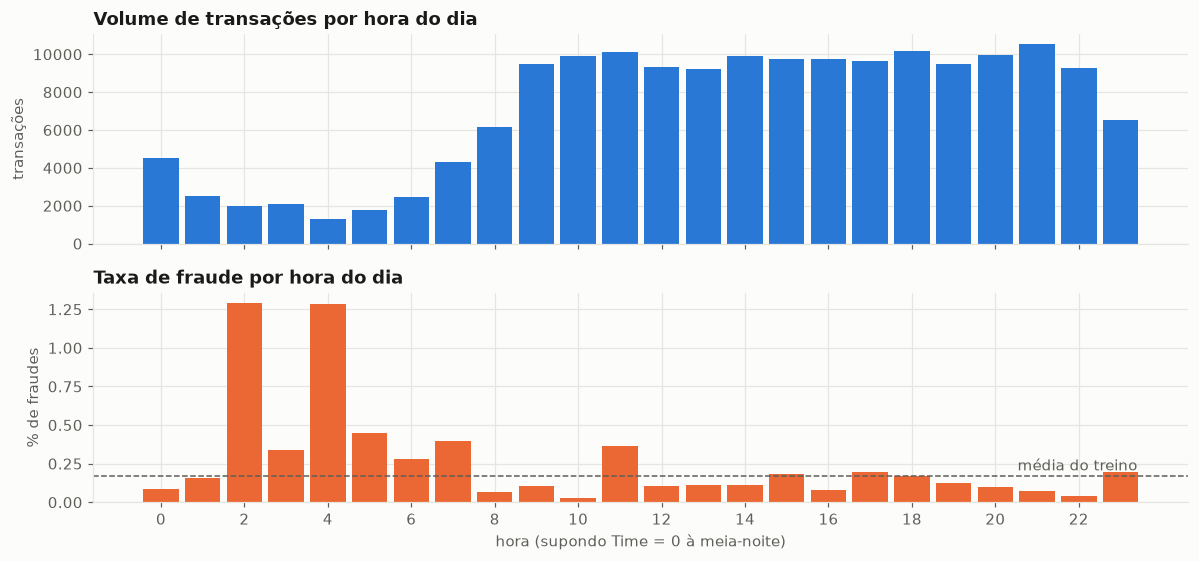

,transações,fraudes,taxa de fraude (%)
hour,,,
2,2012,26,1.29
4,1325,17,1.28
5,1785,8,0.45
7,4308,17,0.39


In [23]:
train_fraud_rate_percent = train_frauds / len(train_raw_df) * 100
hourly = (
    train_raw_df.assign(hour=np.floor(hour_of_day(train_raw_df["Time"])).astype(int))
    .groupby("hour")[TARGET_COLUMN]
    .agg(transações="size", fraudes="sum")
)
hourly["taxa de fraude (%)"] = hourly["fraudes"] / hourly["transações"] * 100

fig, (volume_ax, rate_ax) = plt.subplots(2, 1, figsize=(11, 5.2), sharex=True)
volume_ax.bar(hourly.index, hourly["transações"], color=NEUTRAL_SERIES_COLOR, width=0.85)
volume_ax.set(title="Volume de transações por hora do dia", ylabel="transações")
rate_ax.bar(hourly.index, hourly["taxa de fraude (%)"], color=CLASS_COLORS[FRAUD_LABEL], width=0.85)
rate_ax.axhline(train_fraud_rate_percent, color="#5f5e58", linewidth=1, linestyle="--")
rate_ax.annotate("média do treino", xy=(23.4, train_fraud_rate_percent),
                 xytext=(0, 4), textcoords="offset points", ha="right", color="#5f5e58")
rate_ax.set(title="Taxa de fraude por hora do dia", xlabel="hora (supondo Time = 0 à meia-noite)", ylabel="% de fraudes")
rate_ax.set_xticks(range(0, 24, 2))
plt.tight_layout()
plt.show()

hourly.sort_values("taxa de fraude (%)", ascending=False).head(4).style.format(
    {"taxa de fraude (%)": "{:.2f}"}
).set_caption("As 4 horas com maior taxa de fraude, no treino")

#### hour_sin e hour_cos: o relógio

A hora vira um ponto num círculo, como o ponteiro de um relógio. São necessárias **duas** coordenadas:
- **Só com o seno**, horas diferentes colidem. Por exemplo, 3h e 9h têm o mesmo seno (0,71), e 0h e 12h também
  (0). O modelo não conseguiria distingui-las.
- **Com seno e cosseno juntos**, cada hora tem um par único. Horas vizinhas ficam sempre à mesma distância,
  inclusive 23h e 0h.

Os gráficos mostram as duas curvas ao longo do dia e o círculo resultante. No círculo, o tamanho de cada ponto é
proporcional à taxa de fraude daquela hora.

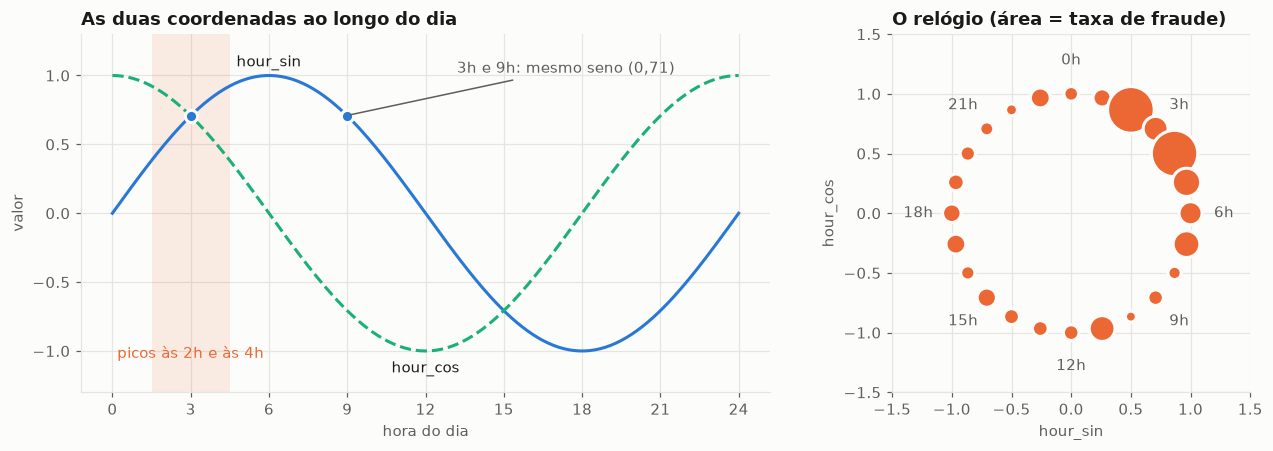

In [24]:
SIN_COLOR, COS_COLOR = NEUTRAL_SERIES_COLOR, "#1baf7a"
hours_grid = np.linspace(0, 24, 241)
grid_angle = 2 * np.pi * hours_grid / 24

fig, (curve_ax, clock_ax) = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1.6, 1]})

curve_ax.axvspan(1.5, 4.5, color=CLASS_COLORS[FRAUD_LABEL], alpha=0.12, linewidth=0)
curve_ax.annotate("picos às 2h e às 4h", xy=(3, -1.05), ha="center", color=CLASS_COLORS[FRAUD_LABEL])
curve_ax.plot(hours_grid, np.sin(grid_angle), color=SIN_COLOR)
curve_ax.plot(hours_grid, np.cos(grid_angle), color=COS_COLOR, linestyle="--")
# Rótulos diretos nas curvas: a identificação não depende só da cor
curve_ax.annotate("hour_sin", xy=(6, 1), xytext=(0, 6), textcoords="offset points", ha="center", color="#1a1a19")
curve_ax.annotate("hour_cos", xy=(12, -1), xytext=(0, -14), textcoords="offset points", ha="center", color="#1a1a19")
# A colisão que torna o seno sozinho insuficiente: 3h e 9h têm o mesmo seno
for colliding_hour in (3, 9):
    curve_ax.plot(colliding_hour, np.sin(2 * np.pi * colliding_hour / 24), "o", markersize=8,
                  color=SIN_COLOR, markeredgecolor="#fcfcfb", markeredgewidth=2)
curve_ax.annotate("3h e 9h: mesmo seno (0,71)", xy=(9, 0.71), xytext=(13.2, 1.02), color="#5f5e58",
                  arrowprops={"arrowstyle": "-", "color": "#5f5e58", "linewidth": 1})
curve_ax.set(title="As duas coordenadas ao longo do dia", xlabel="hora do dia", ylabel="valor", ylim=(-1.3, 1.3))
curve_ax.set_xticks(range(0, 25, 3))

# Relógio: x = seno e y = cosseno põe 0h no topo e as horas no sentido horário
integer_hours = hourly.index.to_numpy()
hour_angle = 2 * np.pi * integer_hours / 24
marker_area = 30 + 900 * hourly["taxa de fraude (%)"] / hourly["taxa de fraude (%)"].max()
clock_ax.scatter(np.sin(hour_angle), np.cos(hour_angle), s=marker_area, color=CLASS_COLORS[FRAUD_LABEL],
                 edgecolor="#fcfcfb", linewidth=2, zorder=3)
for hour in range(0, 24, 3):
    angle = 2 * np.pi * hour / 24
    clock_ax.annotate(f"{hour}h", xy=(1.28 * np.sin(angle), 1.28 * np.cos(angle)), ha="center", va="center",
                      color="#5f5e58")
clock_ax.set(title="O relógio (área = taxa de fraude)", xlabel="hour_sin", ylabel="hour_cos",
             xlim=(-1.5, 1.5), ylim=(-1.5, 1.5), aspect="equal")
plt.tight_layout()
plt.show()

In [25]:
train_day = collection_day.loc[train_raw_df.index]
fraud_by_day = train_raw_df.groupby(train_day)[TARGET_COLUMN].agg(transações="count", fraudes="sum")
fraud_by_day["% de fraudes"] = fraud_by_day["fraudes"] / fraud_by_day["transações"] * 100
_, day_p_value, _, _ = chi2_contingency(pd.crosstab(train_day, train_raw_df[TARGET_COLUMN]))
day_rate_ratio = fraud_by_day.loc[2, "% de fraudes"] / fraud_by_day.loc[1, "% de fraudes"]
print(f"Taxa de fraude do dia 2 ÷ dia 1 (treino): {day_rate_ratio:.2f}; teste qui-quadrado, p = {day_p_value:.4f}")

# Padrão ou episódio? Fraudes de cada dia nas horas de maior taxa: um pico que só existe num dos dias é um episódio
PEAK_HOURS_SHOWN: int = 5
peak_hours = sorted(hourly["taxa de fraude (%)"].nlargest(PEAK_HOURS_SHOWN).index)
is_train_fraud = train_raw_df[TARGET_COLUMN] == FRAUD_LABEL
train_hour = np.floor(hour_of_day(train_raw_df["Time"])).astype(int).rename("hora")
peak_by_day = pd.crosstab(train_hour[is_train_fraud], train_day[is_train_fraud]).reindex(peak_hours, fill_value=0)
peak_by_day.columns = [f"fraudes no dia {day}" for day in peak_by_day.columns]

display(peak_by_day.style.set_caption(f"Fraudes do treino por dia, nas {PEAK_HOURS_SHOWN} horas de maior taxa de fraude"))
fraud_by_day.style.format({"transações": "{:,.0f}", "fraudes": "{:.0f}", "% de fraudes": "{:.4f}"}).set_caption(
    "Fraudes por dia da coleta, no treino"
)

Taxa de fraude do dia 2 ÷ dia 1 (treino): 0.81; teste qui-quadrado, p = 0.0848


,fraudes no dia 1,fraudes no dia 2
hora,,
2,11,15
4,5,12
5,8,0
7,17,0
11,28,9


,transações,fraudes,% de fraudes
dia da coleta,,,
1,"86,311",159,0.1842
2,"83,924",125,0.1489


### 4.4 Transformações linha a linha

> **Papel no experimento:** **muda os dados.** Cria `amount_log`, `hour_sin` e `hour_cos` nas três partes e descarta `Time`. São as 31 features dos modelos.

O que as duas análises acima pedem:

| Transformação | De → para | Por quê |
|---|---|---|
| `amount_log = log(1 + Amount)` | `Amount` → `amount_log` | Comprime a cauda longa. É `log1p` porque há valores zero, e log(0) não existe |
| `hour_sin`, `hour_cos` | `Time` → hora do dia no círculo | 23h59 e 00h00 ficam vizinhas. `Time` bruto descreve os dois dias da coleta, não um padrão repetível |

As duas já estavam previstas no plano, vindas do trabalho anterior; o que as **justifica** aqui são as análises
do treino acima. Elas são **aplicadas** às três partes. Aplicá-las à validação e ao
teste não é vazamento: cada linha é transformada só com os próprios valores, por uma função fixa, sem nenhum
parâmetro ajustado.

`Amount` e `hour_of_day` continuam na tabela como colunas **auxiliares**: servem para gráficos e para o modelo de
custo do limiar (Seção 7), mas **nunca** entram nos modelos. As verificações abaixo garantem isso.

In [26]:
train_df, validation_df, test_df = (
    engineer_features(part) for part in (train_raw_df, validation_raw_df, test_raw_df)
)
X_train, y_train = train_df[list(MODEL_FEATURE_COLUMNS)], train_df[TARGET_COLUMN]
X_validation, y_validation = validation_df[list(MODEL_FEATURE_COLUMNS)], validation_df[TARGET_COLUMN]
# O teste não é separado em X/y aqui: ele só é usado para avaliar, na Seção 9

for engineered, original in ((train_df, train_raw_df), (validation_df, validation_raw_df), (test_df, test_raw_df)):
    assert engineered.index.equals(original.index), "a transformação não pode mudar nem reordenar linhas"
    assert not engineered[list(MODEL_FEATURE_COLUMNS)].isna().any().any()
assert len(MODEL_FEATURE_COLUMNS) == 31 and "Time" not in MODEL_FEATURE_COLUMNS
assert not set(AUXILIARY_COLUMNS) & set(MODEL_FEATURE_COLUMNS), "coluna auxiliar vazando para os modelos"

pd.DataFrame(
    {
        "assimetria antes": [train_raw_df["Amount"].skew()],
        "assimetria depois": [train_df["amount_log"].skew()],
    },
    index=["Amount → amount_log (treino)"],
).style.format("{:.2f}").set_caption("Assimetria de Amount antes e depois do log1p, no treino")

,assimetria antes,assimetria depois
Amount → amount_log (treino),15.20,0.16


### 4.5 Quais features separam fraude de legítima

> **Papel no experimento:** **só ilustra ou verifica.** Nada daqui entra no pipeline nem no modelo. O ranking não escolhe features para o modelo (a seleção é refeita no pipeline, em cada fold); ele orienta o grid e indica quais features usar nas ilustrações seguintes.

Duas medidas de associação com o rótulo, com papéis diferentes:
- **Correlação de Pearson:** mede relação **linear**, de −1 a 1. Se as fraudes ficam nas duas pontas de uma feature
  (valores muito altos *e* muito baixos), os efeitos se cancelam e a correlação fica perto de zero.
- **Informação mútua (MI, de *mutual information*):** mede **qualquer** dependência. Responde "quanto saber o valor
  da feature reduz a incerteza sobre o rótulo?". É zero só quando feature e rótulo são independentes. A unidade é o
  **nat** (a mesma ideia do bit, com logaritmo natural no lugar do logaritmo na base 2); o que importa aqui é a
  comparação entre as features, e não o valor absoluto.

O ranking é calculado **no treino** e é descritivo: orienta quais opções entram no grid, mas a seleção de features
de verdade é refeita dentro do pipeline, em cada fold.

As features analisadas são as 31 que entram nos modelos (4.4): `V1`–`V28`, `amount_log`, `hour_sin` e `hour_cos`.

**Os três resultados abaixo:**
1. **A tabela** traz as 31 features, com a informação mútua, a correlação de Pearson e a posição no ranking.
2. **O gráfico de barras** mostra as mesmas 31, ordenadas, para ver de relance onde o sinal se concentra.
3. **As distribuições por classe** das 4 features de maior informação mútua no treino. São 4 porque é o que cabe numa
   linha de painéis com resolução suficiente; a escolha sai do ranking do treino, e não do que já se sabia da base
   (a regra contra vazamento por conhecimento prévio, NC12). Elas mostram o **formato** do sinal que o ranking resume num número.

**Por que o eixo das distribuições é cortado nos percentis 1 e 99.** É só para o **desenho**: os dados não mudam, e o
modelo recebe todos os valores.
- As `V` têm caudas longas (4.1). Num histograma, o eixo vai do menor ao maior valor, então meia dúzia de pontos
  extremos esticam o eixo, e as legítimas, que formam um pico estreito perto de zero, ficam espremidas em pouquíssimas
  barras. Cortar o eixo mostra o formato onde estão quase todos os dados.
- O corte é **por classe**: vai do **menor** percentil 1 ao **maior** percentil 99 entre as duas classes. O percentil
  do treino inteiro seria, na prática, o das legítimas (99,8% das linhas) e cortaria justamente a cauda das fraudes,
  que é o sinal (o erro registrado no NC2).
- A tabela depois do gráfico mostra, para cada painel, o eixo com e sem corte, quantas barras o pico das legítimas
  ocupa em cada caso e o que fica fora do desenho.
- **Isso não é tratamento de dados.** Cortar valores extremos nos próprios dados tem nome (*winsorização*) e não é
  feito aqui: neste problema os extremos são justamente onde estão as fraudes. O único corte que o modelo vê é o
  `clip=True` do MinMax, que segura na borda um valor da validação ou do teste fora da faixa do treino (4.7.1).

In [27]:
with CostMeter(trace_python_memory=False) as mi_meter:
    mutual_information = mutual_info_classif(X_train, y_train, random_state=config.RANDOM_STATE, n_jobs=config.N_JOBS)

association = pd.DataFrame(
    {
        "informação mútua": mutual_information,
        "correlação de Pearson": X_train.corrwith(y_train),
    },
    index=MODEL_FEATURE_COLUMNS,
).sort_values("informação mútua", ascending=False)
association["posição (MI)"] = range(1, len(association) + 1)
print(f"Informação mútua em {len(X_train):,} linhas de treino: {mi_meter.report.wall_seconds:.1f} s")
association.style.format({"informação mútua": "{:.4f}", "correlação de Pearson": "{:.3f}"}).set_caption(
    "Associação de cada feature com o rótulo, no treino (ordenada pela informação mútua)"
)

Informação mútua em 170,235 linhas de treino: 9.8 s


,informação mútua,correlação de Pearson,posição (MI)
V17,0.0079,-0.320,1
V14,0.0079,-0.299,2
V10,0.0071,-0.208,3
V12,0.0071,-0.251,4
V11,0.0063,0.151,5
V16,0.0058,-0.187,6
V3,0.0046,-0.189,7
V4,0.0046,0.127,8
V9,0.0040,-0.093,9
V18,0.0039,-0.105,10


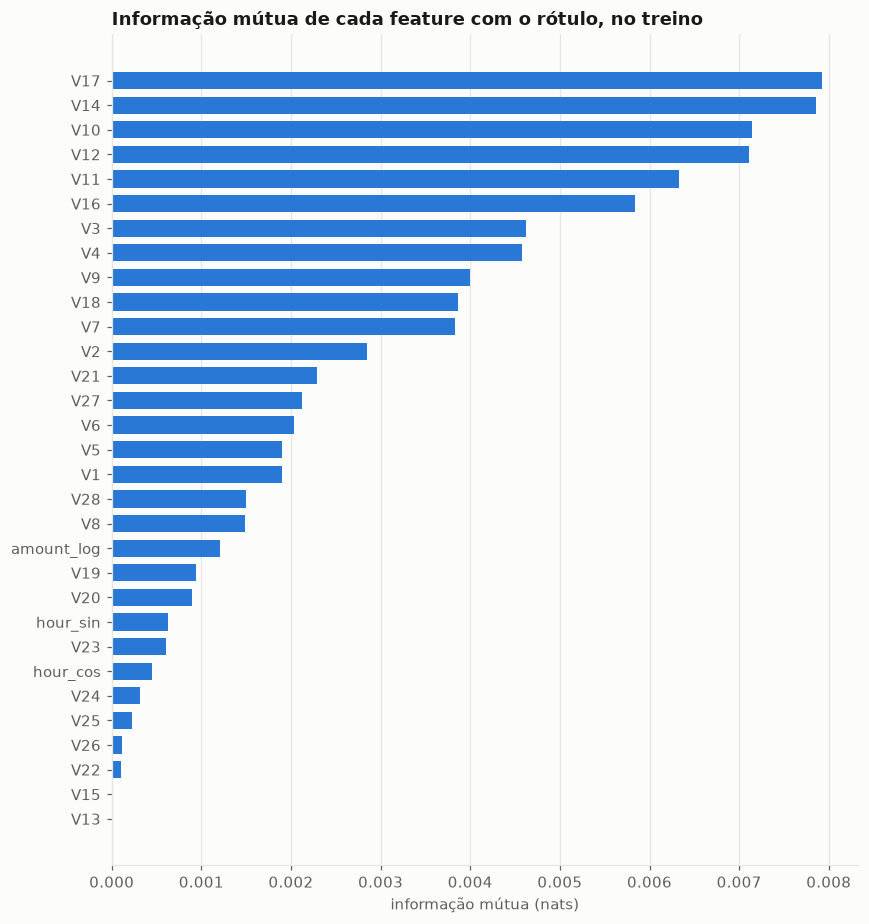

In [28]:
# Todas as 31 features, da maior para a menor informação mútua (a de cima é a maior)
ranked_association = association.iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 8.5))
ax.barh(ranked_association.index, ranked_association["informação mútua"], color=NEUTRAL_SERIES_COLOR, height=0.7)
ax.set(title="Informação mútua de cada feature com o rótulo, no treino", xlabel="informação mútua (nats)")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

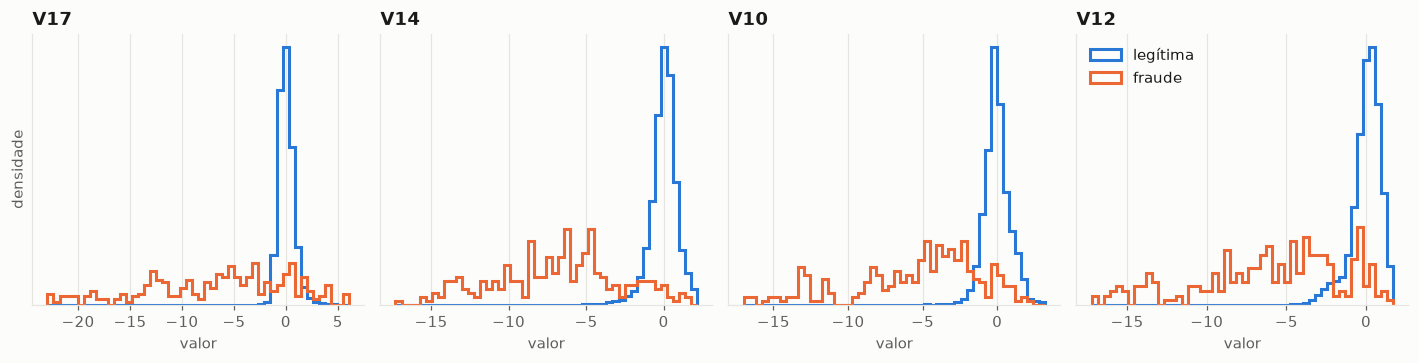

,eixo sem corte,eixo com corte,"barras do pico das legítimas, sem corte","barras do pico das legítimas, com corte",% das legítimas fora do desenho,fraudes fora do desenho
feature,,,,,,
V17,-24.0 a 9.3,-22.9 a 6.1,3.4,3.9,0.01,6
V14,-19.2 a 10.5,-17.3 a 2.1,4.7,7.2,1.00,3
V10,-24.4 a 23.7,-17.0 a 3.2,3.0,7.1,1.00,5
V12,-18.6 a 7.8,-17.2 a 1.7,6.0,8.4,1.00,3


In [29]:
# Distribuição por classe das 4 features de maior informação mútua no treino. O eixo de cada painel é cortado no
# menor percentil 1 e no maior percentil 99 ENTRE AS CLASSES: cortar pelos percentis do treino inteiro jogaria parte
# das fraudes (0,17% das linhas) para fora do intervalo. O corte é só do desenho; os dados não mudam
DISTRIBUTION_FEATURES: int = 4
HISTOGRAM_BINS: int = 50
top_features = association.index[:DISTRIBUTION_FEATURES]
is_train_legitimate = train_df[TARGET_COLUMN] == LEGITIMATE_LABEL

cut_effect_rows: list[dict[str, str | float | int]] = []
fig, axes = plt.subplots(1, len(top_features), figsize=(13, 3.4))
for ax, feature in zip(axes, top_features):
    class_quantiles = train_df.groupby(TARGET_COLUMN)[feature].quantile([0.01, 0.99]).unstack()
    low, high = class_quantiles[0.01].min(), class_quantiles[0.99].max()
    bins = np.linspace(low, high, HISTOGRAM_BINS + 1)
    for label, group in train_df.groupby(TARGET_COLUMN):
        inside = group[feature].between(low, high)
        ax.hist(group.loc[inside, feature], bins=bins, density=True, histtype="step", linewidth=2,
                color=CLASS_COLORS[label], label=CLASS_NAMES[label])
    ax.set(title=feature, xlabel="valor")
    ax.set_yticks([])

    # O que o corte faz: largura das barras com e sem corte, e quantas barras o pico das legítimas ocupa
    values = train_df[feature]
    legitimate_values, fraud_values = values[is_train_legitimate], values[~is_train_legitimate]
    legitimate_span = legitimate_values.quantile(0.95) - legitimate_values.quantile(0.05)
    full_bar_width = (values.max() - values.min()) / HISTOGRAM_BINS
    cut_bar_width = (high - low) / HISTOGRAM_BINS
    cut_effect_rows.append(
        {
            "feature": feature,
            "eixo sem corte": f"{values.min():.1f} a {values.max():.1f}",
            "eixo com corte": f"{low:.1f} a {high:.1f}",
            "barras do pico das legítimas, sem corte": legitimate_span / full_bar_width,
            "barras do pico das legítimas, com corte": legitimate_span / cut_bar_width,
            "% das legítimas fora do desenho": (~legitimate_values.between(low, high)).mean() * 100,
            "fraudes fora do desenho": int((~fraud_values.between(low, high)).sum()),
        }
    )
axes[0].set_ylabel("densidade")
axes[-1].legend()
plt.tight_layout()
plt.show()

pd.DataFrame(cut_effect_rows).set_index("feature").style.format(
    {"barras do pico das legítimas, sem corte": "{:.1f}", "barras do pico das legítimas, com corte": "{:.1f}",
     "% das legítimas fora do desenho": "{:.2f}"}
).set_caption(
    f"O que o corte do eixo faz em cada painel (pico das legítimas = faixa de 90% delas; {HISTOGRAM_BINS} barras). "
    "Só o desenho muda: os dados e o modelo não são afetados"
)

### 4.5.1 Leitura dos resultados (4.1 a 4.5)

**Escalas muito diferentes entre as features** (as 30 colunas de entrada, 4.1).
- O desvio das 28 `V` vai de 0,33 (`V28`) a 1,95 (`V1`). O de `Time` é 47.513 e o de `Amount`, 246: `Time` tem
  **de 24.345 a 142.653 vezes** a escala de uma `V`, e `Amount`, de 126 a 740 vezes. Qualquer método que mede
  distância ou variância (SVM com kernel RBF, kernels quânticos, PCA) seria dominado por `Time` e `Amount` se elas
  entrassem sem escalonamento. É o problema do PCA do El Alami et al. (2025), reproduzido na 4.6.3.
- **Caudas longas em quase todas as `V`:** o valor mais extremo de cada uma fica de 6 a 102 desvios da média
  (mediana de 20), e passa de 10 desvios em 23 das 28. O caso mais extremo é a `V28`, a 102 desvios. O conjunto
  `V1`–`V28` vai de −73,2 a 39,4. O MinMaxScaler usa justamente o mínimo e o máximo, então um único ponto extremo
  espreme todos os outros (4.6.1).

**`Amount`: a fraude típica é de valor baixo.**
- A média das fraudes (118,87) é *maior* que a das legítimas (88,11), mas a mediana é *menor* (11,86 contra 22,05).
  A média é puxada por poucas fraudes altas; o caso típico é baixo.
- **33,5% das fraudes são de até 1,00**, contra 10,6% das legítimas, e 5,3% são de valor zero, contra 0,6%.
- Dois valores exatos concentram fraudes: **21,5% são de exatamente 1,00** (legítimas: 4,7%) e **6,3% de exatamente
  99,99** (legítimas: 0,10%). São os picos do gráfico em log(1+valor) ≈ 0,69 e ≈ 4,6, compatíveis com **teste de
  cartão**: pequenas cobranças para verificar se o cartão roubado funciona.
- O `log1p` reduziu a assimetria de 15,2 para 0,16.
- A correlação de Pearson de `amount_log` com o rótulo é praticamente zero (−0,006), e mesmo assim as distribuições
  são claramente diferentes. As fraudes se concentram nos valores muito baixos **e** num pico em 99,99, então não
  existe uma relação "quanto maior, mais fraude" para o Pearson captar. A informação mútua, que capta qualquer
  dependência, a coloca em 20º lugar.

**`Time`: a suposição da meia-noite se sustenta, mas o sinal da hora é fraco.**
- O volume despenca na madrugada (2.012 transações às 2h, 1.325 às 4h e 1.785 às 5h, contra perto de 10 mil nas
  horas do dia), coerente com `Time = 0` à meia-noite.
- A taxa de fraude chega a **1,29% às 2h** e **1,28% às 4h**, quase 8 vezes a média do treino (0,17%). Parece um
  sinal forte, mas `hour_sin` e `hour_cos` ficaram em **23º e 25º** na informação mútua.
- A contradição é aparente: a taxa sobe onde há **poucas** transações, então poucas fraudes são afetadas (26 às 2h
  e 17 às 4h).
- **Padrão ou episódio?** Os picos das 2h e das 4h aparecem nos dois dias (11 e 15 fraudes; 5 e 12). Os das 5h e
  das 7h vêm de um dia só (8 e 0; 17 e 0): são episódios. O das 11h pesa bem mais no dia 1 (28 e 9).
- **Entre os dois dias**, a taxa de fraude do treino foi de 0,1842% e 0,1489%: o dia 2 tem 0,81 da taxa do dia 1.
  O teste não distingue essa diferença do acaso (qui-quadrado, p = 0,085), mas isso é **falta de poder**, e não
  prova de que ela não existe: com 284 fraudes, uma diferença de ~20% fica no limite do que dá para detectar.
- Consequência: a hora é candidata natural a ser descartada pela seleção de features.

**As features que separam as classes.**
- Topo do ranking de informação mútua: `V17`, `V14`, `V10`, `V12`, `V11`, `V16`, `V3`, `V4`.
- Base: `V13`, `V15`, `V22`, `V26`, `V25`, `V24` e `hour_cos`.
- O gráfico por classe mostra o formato do sinal: **as legítimas formam um pico estreito em torno de 0**, e as
  fraudes se espalham por uma cauda longa, quase toda negativa (no `V14`, de cerca de −17 até 0).
- O corte do eixo nesses gráficos só muda o desenho, e ajuda mais onde a cauda é mais longa: na `V10`, o pico das
  legítimas passa de 3,0 para 7,1 barras; na `V17`, quase não muda (3,4 para 3,9). Ficam fora do desenho até 1%
  das legítimas e de 3 a 6 fraudes por painel.
- No gráfico de barras, a informação mútua cai de forma gradual depois das 4 primeiras, e as 6 últimas (`V24`,
  `V25`, `V26`, `V22`, `V15` e `V13`) ficam praticamente em zero.

**Três ganchos para o restante da seção:**
1. **Escalonamento.** Aquela cauda das fraudes define o mínimo de cada feature. Um MinMaxScaler, que usa mínimo e
   máximo, vai espremer todas as legítimas num pedaço minúsculo do intervalo. Com a codificação de ângulo, elas
   ficariam quase com o mesmo ângulo.
2. **Seleção de features para 5 qubits** (o porquê dos 5 está na abertura da 4.6). As 5 features de maior informação mútua são as candidatas óbvias. Mas a
   informação mútua avalia cada feature **isoladamente**: se `V17` e `V14` carregam a mesma informação sobre as
   fraudes, escolher as duas desperdiça um qubit. É isso que torna o PCA uma alternativa a comparar.
3. **O undersampling muda tudo isso.** No treino balanceado as fraudes serão 50% das linhas. A "cauda rara" vira
   metade dos dados, e estatísticas como média, desvio e mínimo/máximo, que definem os scalers, mudam
   completamente.

### 4.6 Escalonamento e codificação: o que os dados mostram

Esta parte responde às duas perguntas que a literatura deixa em aberto:
- **Qual scaler usar?** Os artigos usam StandardScaler seguido de MinMaxScaler sem explicar por quê.
- **Qual codificação usar: ângulo ou amplitude?**

> **Nota de nomenclatura (CC14).** "Ângulo", nesta seção, é a família das codificações em que a feature vira o
> ângulo de uma rotação, em oposição à amplitude. A rigor, os mapas Z e ZZ do Qiskit são **codificação de fase**:
> Hadamard seguida de porta de fase (rotação em torno de Z). A codificação de ângulo propriamente dita é a rotação
> em Y. Para o **kernel** a diferença não existe com uma camada (os dois dão Π cos²(Δ); há teste:
> `test_phase_and_angle_encoding_give_the_same_kernel`), então as análises desta seção, que são todas sobre
> kernels, não mudam. Para o classificador variacional do Quantum AdaBoost, que **mede** o estado, a diferença pode
> importar; isso é examinado na Seção 5.

**Por que 5 qubits.** É um **orçamento comum** às duas codificações: o TCC compara ângulo e amplitude com o mesmo
recurso quântico, o mesmo número de qubits, e deixa cada codificação usar esse recurso do seu jeito.
- **Quem define o número é a amplitude.** Na codificação de amplitude, *n* qubits guardam 2ⁿ valores (as amplitudes
  do estado). São 31 features mais 1 constante de preenchimento (a que preserva a norma do vetor, 4.8): 32 valores,
  ou seja, 2⁵. Com 4 qubits caberiam só 16; com 6 caberiam 64, e metade das posições seria só preenchimento. O teste
  `test_amplitude_budget_fits_all_features_plus_constant` garante essa conta.
- **No ângulo, 5 qubits são 5 features.** Cada qubit recebe uma feature, então as 31 precisam virar 5, por PCA ou por
  informação mútua (4.9). É o preço que a codificação de ângulo paga para caber no mesmo orçamento.
- **Mais qubits não seria melhor.** O estado de *n* qubits é descrito por 2ⁿ números (o *statevector*, a lista das
  amplitudes), então o custo da simulação cresce exponencialmente com os qubits: com 5 são 512 bytes e cerca de
  4 ms por estado (Seção 1). E a similaridade entre transações diferentes cai mais ou menos pela metade a cada qubit
  a mais (CC5): com muitos qubits, cada transação só se parece consigo mesma, o kernel vira quase a identidade e o
  modelo decora o treino. Com 5 qubits, quem controla essa concentração é a faixa dos ângulos (4.7).
- **A escolha ainda será testada.** O plano prevê, na codificação de ângulo, uma curva de sensibilidade com 4 a 8
  componentes (4 a 8 qubits), para medir o quanto o resultado depende desse número.

**Como a análise é feita.**
- Scalers, redutores e kernels são ajustados no **treino balanceado**: as 284 fraudes do treino mais 284 legítimas,
  sorteadas pelo mesmo undersampler que o pipeline usa. É exatamente o formato que os modelos vão receber.
- Nada daqui é reaproveitado pelos modelos. O pipeline reajusta tudo em cada fold, e a escolha entre as opções é
  feita por validação cruzada (Seção 6).
- **O que esta parte decide é quais opções merecem entrar no grid, e por quê.**

**Para comparar configurações sem treinar modelos,** duas medidas de um kernel são usadas:
- **Similaridade média entre linhas diferentes (fora da diagonal).** Perto de 1, o kernel acha tudo parecido e não
  distingue ninguém. Perto de 0, cada linha só se parece consigo mesma e o modelo decora (o 1/2ⁿ da Fase 0).
- **Alinhamento kernel-alvo (KTA, centrado).** Compara a tabela de similaridades do kernel com a tabela "ideal", que
  diz +1 para pares da mesma classe e −1 para pares de classes diferentes. Funciona como uma correlação entre as
  duas tabelas: perto de 0, o kernel ignora o rótulo; quanto maior, mais "parecidas" coincide com "mesma classe".
  **Centrado** quer dizer que, antes da comparação, a similaridade média de cada linha e de cada coluna é subtraída.
  Isso remove o "fundo" comum a todos os pares: um kernel em que tudo é muito parecido, mas em que pares da mesma
  classe são sempre um pouco mais parecidos, é reconhecido como bom. Sem centralizar, ele pareceria ruim só por ter
  valores altos (Cortes, Mohri e Rostamizadeh, 2012).
  O KTA é um **indicador**, não uma métrica final. Quem decide é a validação cruzada.

In [30]:
# O treino balanceado que o pipeline vai produzir: todas as fraudes do treino + o mesmo número de legítimas,
# sorteadas pelo próprio undersampler do pipeline (com a semente principal)
balanced_features, balanced_labels = make_undersampler(config.RANDOM_STATE).fit_resample(X_train, y_train)
balanced_train_df = train_df.loc[balanced_features.index].sample(frac=1, random_state=config.RANDOM_STATE)
balanced_train_features = balanced_train_df[list(MODEL_FEATURE_COLUMNS)].to_numpy()
balanced_train_labels = balanced_train_df[TARGET_COLUMN].to_numpy()

# Kernels custam O(n²) comparações: 400 linhas bastam para comparar configurações entre si
KERNEL_SAMPLE_ROWS: int = 400

print(f"Treino balanceado: {len(balanced_train_df)} linhas ({balanced_train_labels.mean():.0%} fraudes); "
      f"{KERNEL_SAMPLE_ROWS} delas entram em cada kernel")

Treino balanceado: 568 linhas (50% fraudes); 400 delas entram em cada kernel


#### 4.6.0 O que muda quando metade dos dados é fraude

> **Papel no experimento:** **só ilustra ou verifica.** Nada daqui entra no pipeline nem no modelo. Mostra um erro que
> o pipeline evita: reaproveitar parâmetros de escalonamento de uma distribuição em outra.

**Por que esta subseção existe.** Um scaler aprende parâmetros com os dados: o StandardScaler, a média e o desvio
padrão de cada coluna; o RobustScaler, a mediana e o IQR (a distância entre os quartis 25% e 75%). Esses parâmetros
valem para a distribuição em que foram calculados. O pipeline do projeto ajusta o scaler **depois** do undersampling,
dentro de cada fold, ou seja, no treino balanceado que o modelo vai receber. A subseção mostra o que daria errado se
ele fosse ajustado em outra amostra, como o treino inteiro, a base inteira ou os dados de outro trabalho: os
parâmetros seriam outros.

No treino como ele sai do split, as fraudes são 0,17% das linhas: a cauda onde elas vivem quase não pesa nas
estatísticas. No treino balanceado, elas são **metade** das linhas, e a "cauda rara" passa a definir a distribuição.

**Quais features aparecem na tabela, e por quê.**
- **As 4 de maior informação mútua no treino (4.5),** as mesmas das distribuições da 4.5. Aqui elas não estão sendo
  escolhidas para modelo nenhum (para isso, a informação mútua sozinha não basta, 4.9): estão ilustrando onde o
  balanceamento mais mexe. Como o balanceamento muda a distribuição justamente onde fraudes e legítimas diferem, é
  nelas que se espera a maior mudança. O gráfico depois da tabela confere isso nas 31 features.
- **`amount_log`, como contraste.** O sinal de fraude dela é de outro tipo: está em valores **específicos** (1,00 e
  99,99, 4.2), e não numa cauda deslocada. Ela mostra que "a feature separa as classes" não implica "o balanceamento
  muda a escala dela". Estar na tabela não muda nada no pré-processamento: ela entra nos modelos como todas as outras
  31 features, e o scaler dela é ajustado no pipeline como o de qualquer coluna.

A tabela compara as quatro estatísticas que os scalers usam: média e desvio padrão (StandardScaler); mediana e IQR
(RobustScaler).

In [31]:
# As 4 features de maior informação mútua no treino (4.5), mais amount_log para contraste. A lista sai do
# ranking calculado no treino, e não do que já se sabia da base inteira
SHIFT_FEATURES: list[str] = [*association.index[:4], "amount_log"]


def scaler_statistics(frame: pd.DataFrame) -> pd.DataFrame:
    """Estatísticas usadas pelo StandardScaler (média, desvio) e pelo RobustScaler (mediana, IQR)."""
    quartiles = frame[SHIFT_FEATURES].quantile([0.25, 0.75])
    return pd.DataFrame(
        {
            "média": frame[SHIFT_FEATURES].mean(),
            "desvio": frame[SHIFT_FEATURES].std(),
            "mediana": frame[SHIFT_FEATURES].median(),
            "IQR": quartiles.loc[0.75] - quartiles.loc[0.25],
        }
    )


full_statistics = scaler_statistics(train_df)
balanced_statistics = scaler_statistics(balanced_train_df)
statistics_shift = pd.concat({"treino inteiro": full_statistics, "treino balanceado": balanced_statistics}, axis="columns")
statistics_shift[("variação", "desvio ×")] = balanced_statistics["desvio"] / full_statistics["desvio"]
statistics_shift[("variação", "IQR ×")] = balanced_statistics["IQR"] / full_statistics["IQR"]
statistics_shift[("treino balanceado", "média − mediana")] = balanced_statistics["média"] - balanced_statistics["mediana"]
# As 4 V da tabela foram escolhidas por serem as mais informativas. Para não generalizar a partir delas,
# a razão de desvios é medida também nas 28
all_v_ratio = balanced_train_df[list(PCA_FEATURE_COLUMNS)].std() / train_df[list(PCA_FEATURE_COLUMNS)].std()
print(f"Razão de desvios (treino balanceado ÷ treino inteiro) nas 28 V: mínimo {all_v_ratio.min():.2f}, "
      f"mediana {all_v_ratio.median():.2f}, máximo {all_v_ratio.max():.2f}; é 4 ou mais em {(all_v_ratio >= 4).sum()} delas")
statistics_shift.style.format("{:.2f}").set_caption(
    "Estatísticas usadas pelos scalers, nas 4 V mais informativas e em amount_log: treino inteiro × treino balanceado"
)

Razão de desvios (treino balanceado ÷ treino inteiro) nas 28 V: mínimo 0.97, mediana 2.26, máximo 7.14; é 4 ou mais em 6 delas


28 V: correlação de Spearman entre informação mútua e mudança do desvio padrão = 0.84 (p = 2.5e-08)
V cujo desvio padrão muda 4 vezes ou mais, e a posição delas na informação mútua: V3 (7º), V7 (11º), V10 (3º), V12 (4º), V14 (2º), V17 (1º)
Features que não são V: amount_log ×1.16, hour_sin ×1.11, hour_cos ×0.97


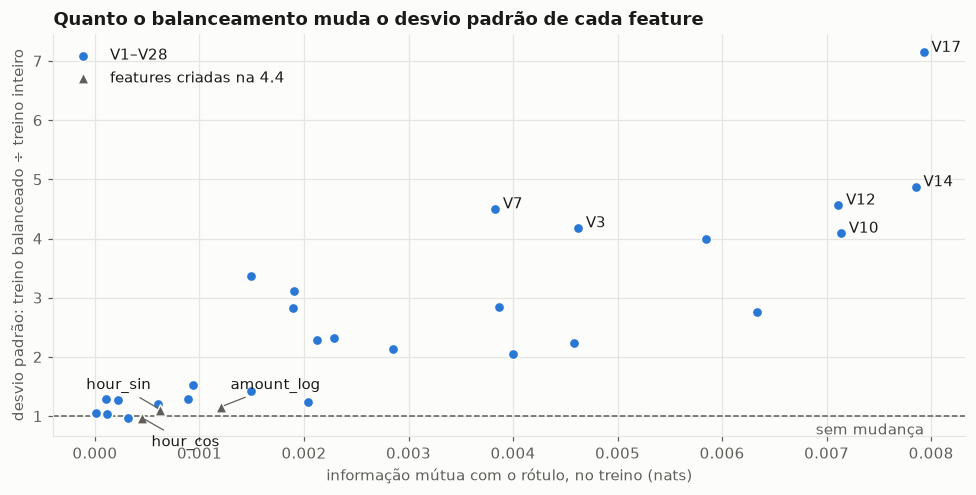

In [32]:
# A tabela mostra só 5 features. A afirmação "o balanceamento muda a escala justamente das features que carregam o
# sinal" precisa valer para todas: mudança do desvio padrão × informação mútua, nas 31
all_feature_ratio = balanced_train_df[list(MODEL_FEATURE_COLUMNS)].std() / train_df[list(MODEL_FEATURE_COLUMNS)].std()
feature_information = association["informação mútua"]
v_columns = list(PCA_FEATURE_COLUMNS)
rank_correlation, rank_p_value = spearmanr(feature_information[v_columns], all_feature_ratio[v_columns])
STRONG_CHANGE: float = 4.0
strongly_changed = all_feature_ratio[v_columns][all_feature_ratio[v_columns] >= STRONG_CHANGE]

print(f"28 V: correlação de Spearman entre informação mútua e mudança do desvio padrão = {rank_correlation:.2f} "
      f"(p = {rank_p_value:.1e})")
print(f"V cujo desvio padrão muda {STRONG_CHANGE:.0f} vezes ou mais, e a posição delas na informação mútua: "
      + ", ".join(f"{name} ({int(association.loc[name, 'posição (MI)'])}º)" for name in strongly_changed.index))
non_v_columns = [column for column in MODEL_FEATURE_COLUMNS if column not in v_columns]
print("Features que não são V: " + ", ".join(f"{name} ×{all_feature_ratio[name]:.2f}" for name in non_v_columns))

fig, ax = plt.subplots(figsize=(9, 4.6))
ax.scatter(feature_information[v_columns], all_feature_ratio[v_columns], color=NEUTRAL_SERIES_COLOR, s=45,
           edgecolor="#fcfcfb", linewidth=1, label="V1–V28", zorder=3)
ax.scatter(feature_information[non_v_columns], all_feature_ratio[non_v_columns], color="#5f5e58", marker="^", s=55,
           edgecolor="#fcfcfb", linewidth=1, label="features criadas na 4.4", zorder=3)
# Rótulo nas que mais mudam e nas que não são V (o contraste da tabela). As três criadas na 4.4 ficam juntas perto
# da linha "sem mudança", então cada rótulo vai para um lado
NON_V_LABEL_OFFSETS: dict[str, tuple[int, int]] = {"amount_log": (6, 14), "hour_sin": (-6, 16), "hour_cos": (6, -16)}
for name in [*strongly_changed.index, *non_v_columns]:
    offset = NON_V_LABEL_OFFSETS.get(name, (5, 3))
    ax.annotate(name, xy=(feature_information[name], all_feature_ratio[name]), xytext=offset,
                textcoords="offset points", ha="right" if offset[0] < 0 else "left", va="center", color="#1a1a19",
                arrowprops={"arrowstyle": "-", "color": "#5f5e58", "linewidth": 0.8} if name in NON_V_LABEL_OFFSETS else None)
ax.axhline(1.0, color="#5f5e58", linewidth=1, linestyle="--")
ax.annotate("sem mudança", xy=(feature_information.max(), 1.0), xytext=(0, -12), textcoords="offset points",
            ha="right", color="#5f5e58")
ax.set(title="Quanto o balanceamento muda o desvio padrão de cada feature",
       xlabel="informação mútua com o rótulo, no treino (nats)",
       ylabel="desvio padrão: treino balanceado ÷ treino inteiro")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

**Leitura da 4.6.0**

- **Nas quatro `V` mais informativas, o desvio aumenta de 4,1 a 7,1 vezes e o IQR de 4,6 a 7,3 vezes.** Um scaler
  ajustado no treino inteiro dividiria o `V14` por 0,96; ajustado no treino balanceado, divide por 4,66. Parâmetros
  de escalonamento **não se transferem** entre as duas distribuições. É a evidência de que o scaler precisa ser
  ajustado **depois** do undersampling, dentro do pipeline, e nunca reaproveitado de outra amostra ou de outro
  trabalho.
- **Isso não vale para todas as `V`, e o padrão é claro.** Nas 28, a razão de desvios vai de 0,97 a 7,14, com
  mediana de 2,26, e só é 4 ou mais em 6 delas, que estão em 1º, 2º, 3º, 4º, 7º e 11º lugar na informação mútua. A
  correlação de Spearman entre a informação mútua e a mudança do desvio padrão é **0,84** (p = 2,5 × 10⁻⁸). A
  correlação de Spearman compara a **ordem** de duas listas: 1 quer dizer que as duas ordenam as features do mesmo
  jeito. Ou seja, o balanceamento muda a escala justamente das features que carregam o sinal de fraude, e é por isso
  que as quatro da tabela mudam tanto.
- **Nessas quatro, média e mediana se afastam** no treino balanceado (de −1,8 a −2,8, cerca de meio desvio). A
  média é puxada pela cauda das fraudes; a mediana, não. Por isso o StandardScaler (que centraliza na média) e o
  RobustScaler (que centraliza na mediana) põem o "zero" em lugares diferentes. Com o PCA em seguida, que procura
  eixos a partir do centro, os ângulos finais divergem (4.6.2).
- **`amount_log` muda pouco** (desvio ×1,2; média e mediana a 0,05 uma da outra). O sinal de fraude no valor está
  em valores **específicos**, como 1,00 e 99,99 (4.2), e não numa cauda deslocada. Por isso o balanceamento mexe
  pouco na distribuição dele.

#### 4.6.1 O achatamento causado pelo MinMax

> **Papel no experimento:** **só ilustra ou verifica.** Nada daqui entra no pipeline nem no modelo. Mostra o efeito que a largura da faixa de ângulos (4.7) controla.

O MinMaxScaler leva o **menor** valor da coluna para o início do intervalo (0) e o **maior** para o fim (π). Todo o
resto fica espremido proporcionalmente entre eles.

A ilustração usa a feature de maior informação mútua no treino (4.5). No treino balanceado, o mínimo dela vem da
cauda das fraudes e fica muito longe do pico estreito das legítimas, que recebem só uma fatia pequena do intervalo de
ângulos.

V17 no treino balanceado: mínimo -24.0 (menor fraude -24.0, menor legítima -15.3), máximo 6.7
90% das legítimas ocupam 0.21 rad, 7% do intervalo [0, π]


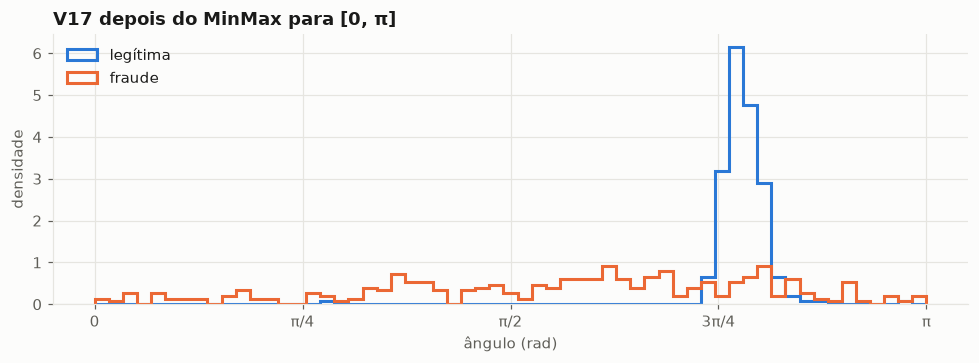

In [33]:
# A feature de maior informação mútua no treino (4.5), e não uma escolhida a partir do que já se sabia
FLATTENING_FEATURE: str = association.index[0]
feature_values = balanced_train_df[FLATTENING_FEATURE]
feature_angles = (feature_values - feature_values.min()) / (feature_values.max() - feature_values.min()) * np.pi
is_balanced_fraud = balanced_train_df[TARGET_COLUMN] == FRAUD_LABEL
legitimate_angles = feature_angles[~is_balanced_fraud]
legitimate_width = legitimate_angles.quantile(0.95) - legitimate_angles.quantile(0.05)

print(f"{FLATTENING_FEATURE} no treino balanceado: mínimo {feature_values.min():.1f} "
      f"(menor fraude {feature_values[is_balanced_fraud].min():.1f}, menor legítima {feature_values[~is_balanced_fraud].min():.1f}), "
      f"máximo {feature_values.max():.1f}")
print(f"90% das legítimas ocupam {legitimate_width:.2f} rad, {legitimate_width / np.pi:.0%} do intervalo [0, π]")

fig, ax = plt.subplots(figsize=(9, 3.4))
bins = np.linspace(0, np.pi, 60)
for label, group_angles in feature_angles.groupby(balanced_train_df[TARGET_COLUMN]):
    ax.hist(group_angles, bins=bins, density=True, histtype="step", linewidth=2,
            color=CLASS_COLORS[label], label=CLASS_NAMES[label])
ax.set(title=f"{FLATTENING_FEATURE} depois do MinMax para [0, π]", xlabel="ângulo (rad)", ylabel="densidade")
ax.set_xticks([0, np.pi / 4, np.pi / 2, 3 * np.pi / 4, np.pi], ["0", "π/4", "π/2", "3π/4", "π"])
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

#### 4.6.2 Standard → MinMax é o mesmo que MinMax sozinho

> **Papel no experimento:** **define opções do grid** (a escolha final entre elas é da validação cruzada, na Seção 6). A equivalência decide **onde** o scaler entra no grid: só no caminho com PCA e na amplitude.

Exemplo pequeno, com a coluna [1, 2, 3]:
- StandardScaler: [−1,22; 0; 1,22] → MinMaxScaler: **[0; 0,5; 1]**
- MinMaxScaler direto: **[0; 0,5; 1]**

O MinMax só olha a **posição relativa** de cada valor entre o mínimo e o máximo. Qualquer "esticar e deslocar"
aplicado antes (é isso que o StandardScaler e o RobustScaler fazem, coluna a coluna) não muda essas posições.

**Onde essa sequência aparece.** Não nos artigos de referência, e sim no texto do próprio TCC (versão 4, Passo 3
da metodologia), que aplicava "primeiro o StandardScaler e, em seguida, o MinMaxScaler" atribuindo a sequência a
Ajibosin e Cetinkaya (2024). Conferidos os artigos da base que usam os dois scalers:
- **Ajibosin e Cetinkaya (2024, seção 3.3, p. 9):** StandardScaler → PCA → MinMaxScaler. Há um PCA no meio, que é a
  ordem em que o scaler faz diferença.
- **Havenstein et al. (2018, apêndice de código, p. 28):** StandardScaler → PCA → MinMaxScaler para [−1, 1], também
  com o PCA no meio. O erro deles é outro: o MinMaxScaler é ajustado com treino e teste juntos, o que é vazamento.
- **Ahmad et al. (2026, p. 6 e 7):** usa Min-Max em umas tarefas e padronização (*z-score*) em outra, nunca os
  dois em sequência.

O erro foi nosso, ao resumir a sequência sem o PCA; está registrado como CC1 e TX8.

A consequência é que a escolha do scaler **só importa se houver algo entre ele e o MinMax** que seja sensível à
escala. O PCA é: ele procura as direções de maior variância, e a variância muda com a escala. A seleção por
informação mútua não é: o estimador reescala cada coluna antes de calcular, então esticar e deslocar
uma coluna não muda o resultado. A célula abaixo
verifica tudo isso nos dados reais.

In [34]:
def max_difference(first: np.ndarray, second: np.ndarray) -> float:
    return float(np.abs(first - second).max())


minmax_only = MinMaxScaler().fit_transform(balanced_train_features)
path_outputs = {
    reducer: {
        scaler: build_angle_preprocessor(scaler, reducer, config.N_QUBITS, random_state=config.RANDOM_STATE)
        .fit_transform(balanced_train_features, balanced_train_labels)
        for scaler in ("standard", "robust")
    }
    for reducer in ("pca", "mutual_info")
}

equivalence = pd.DataFrame(
    [
        ("Standard → MinMax  ×  MinMax", max_difference(
            MinMaxScaler().fit_transform(StandardScaler().fit_transform(balanced_train_features)), minmax_only)),
        ("Robust → MinMax  ×  MinMax", max_difference(
            MinMaxScaler().fit_transform(RobustScaler().fit_transform(balanced_train_features)), minmax_only)),
        ("Standard × Robust, com PCA no meio", max_difference(*path_outputs["pca"].values())),
        ("Standard × Robust, com informação mútua no meio", max_difference(*path_outputs["mutual_info"].values())),
    ],
    columns=["comparação", "maior diferença"],
).set_index("comparação")
equivalence["idênticos?"] = equivalence["maior diferença"] < 1e-9
equivalence.style.format({"maior diferença": "{:.4f}"}).set_caption(
    "Maior diferença entre os ângulos produzidos por dois caminhos de pré-processamento (faixa [0, π/2])"
)

,maior diferença,idênticos?
comparação,,
Standard → MinMax × MinMax,0.0000,True
Robust → MinMax × MinMax,0.0000,True
"Standard × Robust, com PCA no meio",1.5509,False
"Standard × Robust, com informação mútua no meio",0.0000,True


#### 4.6.3 Por que padronizar antes do PCA: o caso El Alami et al. (2025)

> **Papel no experimento:** **só ilustra ou verifica.** Nada daqui entra no pipeline nem no modelo. É a reprodução crítica de um artigo; justifica o scaler antes do PCA, que já está no pipeline.

El Alami et al. subamostraram a base bruta para 492 fraudes + 492 legítimas e aplicaram o PCA às colunas
originais, com `Time` e `Amount` sem escalonamento, para obter 7 componentes (7 qubits). O PCA procura as
direções de **maior variância**. A **escala** (desvio padrão) de `Time` é de 24 mil a 143 mil vezes a das `V`
(4.1), o que em **variância** (desvio ao quadrado) vira uma razão de cerca de 6 × 10⁸ a 2 × 10¹⁰.

A célula aplica o mesmo procedimento (subamostrar 1:1 e fazer o PCA de 7 componentes nas colunas originais, sem
padronizar) às linhas do **treino balanceado**: 284 fraudes + 284 legítimas, em vez das 492 + 492 deles, para não
explorar validação e teste. A última coluna mede quanto de cada componente vem das quatro features de
maior informação mútua no treino (4.5): é a soma dos quadrados das cargas delas, uma fração entre 0 e 1.

In [35]:
# Procedimento de El Alami et al. (subamostrar 1:1 e aplicar o PCA às colunas originais, sem padronizar),
# reproduzido nas MESMAS linhas do treino balanceado, com as colunas brutas
el_alami_sample = train_raw_df.loc[balanced_train_df.index, list(RAW_FEATURE_COLUMNS)]
unscaled_pca = PCA(n_components=7, random_state=config.RANDOM_STATE).fit(el_alami_sample)
loadings = pd.DataFrame(np.abs(unscaled_pca.components_), columns=RAW_FEATURE_COLUMNS)
# As 4 de maior informação mútua no treino (4.5)
FRAUD_SIGNAL_FEATURES: list[str] = list(association.index[:4])
fraction_column = "fração de " + "+".join(FRAUD_SIGNAL_FEATURES)

el_alami_components = pd.DataFrame(
    {
        "variância explicada": unscaled_pca.explained_variance_ratio_,
        "maiores cargas": [
            ", ".join(f"{name} ({value:.2f})" for name, value in loadings.iloc[component].nlargest(3).items())
            for component in range(7)
        ],
        # Cada componente tem norma 1, então a soma das cargas ao quadrado é a fração vinda dessas features
        # .to_numpy(): a soma tem índice 0..6 e a tabela usa "componente 1..7" (alinhar geraria NaN)
        fraction_column: (loadings[FRAUD_SIGNAL_FEATURES] ** 2).sum(axis="columns").to_numpy(),
    },
    index=[f"componente {number}" for number in range(1, 8)],
)
display(
    el_alami_components.style.format({"variância explicada": "{:.2e}", fraction_column: "{:.2f}"})
    .set_caption(f"PCA sem padronização nas {len(el_alami_sample)} linhas do treino balanceado (procedimento de El Alami et al.)")
)

print("PCA do nosso pipeline (padronizado), 5 componentes, variância explicada:")
for scaler in ("standard", "robust"):
    fitted = build_angle_preprocessor(scaler, "pca", config.N_QUBITS, random_state=config.RANDOM_STATE).fit(
        balanced_train_features
    )
    ratios = fitted.named_steps["reducer"].explained_variance_ratio_
    print(f"  {scaler:>8}: {ratios.sum():.1%} (por componente: {np.round(ratios, 3).tolist()})")

,variância explicada,maiores cargas,fração de V17+V14+V10+V12
componente 1,1.00e+00,"Time (1.00), V17 (0.00), V1 (0.00)",0.00
componente 2,2.58e-05,"Amount (1.00), V2 (0.00), V7 (0.00)",0.00
componente 3,8.42e-08,"V3 (0.41), V17 (0.37), V7 (0.34)",0.36
componente 4,1.23e-08,"V1 (0.47), V14 (0.42), V12 (0.33)",0.39
componente 5,7.29e-09,"V8 (0.82), V21 (0.32), V7 (0.28)",0.05
componente 6,4.94e-09,"V17 (0.57), V14 (0.40), V3 (0.35)",0.49
componente 7,1.33e-09,"V1 (0.71), V10 (0.38), V5 (0.31)",0.21


PCA do nosso pipeline (padronizado), 5 componentes, variância explicada:
  standard: 64.8% (por componente: [0.381, 0.101, 0.062, 0.06, 0.043])
    robust: 78.9% (por componente: [0.401, 0.214, 0.07, 0.055, 0.049])


### 4.7 A faixa dos ângulos é a "largura de banda" do kernel

> **Papel no experimento:** **define opções do grid** (a escolha final entre elas é da validação cruzada, na Seção 6). Delimita as larguras da faixa de ângulos testadas (`config.ANGLE_RANGE_WIDTH_GRID`).
>
> **Para qual modelo.** As medidas desta subseção (similaridade entre transações e KTA) são de **kernel**: valem
> diretamente para o **QSVM**, que decide a partir da matriz de similaridades. O **Quantum AdaBoost** não monta essa
> matriz; o classificador fraco dele mede o estado depois de um ansatz. Para ele valem os **limites** que a subseção
> mostra, porque são propriedades da codificação, e não do modelo: se a faixa é estreita demais, os estados ficam
> quase idênticos e **nenhuma medição** consegue distingui-los bem; e a periodicidade da 4.7.1 vale para qualquer
> circuito que use esses mapas. Já a melhor largura para ele será escolhida pela validação cruzada dele (PLAN,
> ponto ①).

O intervalo do MinMax (o "range") decide quão diferentes os ângulos de duas transações podem ficar:
- **Faixa estreita** (ex.: [0; 0,1]): todos os ângulos quase iguais → todos os estados quase iguais → similaridade
  ≈ 1 para todo par. Como uma foto desfocada: ninguém se distingue.
- **Faixa larga** (ex.: [0, 2π]): pequenas diferenças viram grandes diferenças de estado → similaridade ≈ 0 entre
  linhas diferentes. Cada transação só se parece consigo mesma, e o modelo decora.
- **Entre os dois extremos** existe uma faixa em que o kernel separa as classes melhor, com KTA máximo.

É o mesmo papel do γ no kernel RBF clássico (Shaydulin; Wild, 2022). Os artigos usam [0, 1] (El Alami) ou [0, π]
com justificativas vagas.

O KTA medido em 400 linhas é ruidoso (CC10), então cada configuração é medida em **5 subamostras do treino**: para
cada semente, o undersampler do pipeline balanceia o treino (284 + 284) e 400 dessas linhas entram no kernel. A
tabela mostra média ± desvio. A varredura mede cinco configurações de 5 qubits, agrupadas pelo caminho até os
ângulos (é a ordem das colunas das tabelas):
- **ZZ + informação mútua.** Uma configuração só: com informação mútua no meio, StandardScaler e RobustScaler
  dão exatamente o mesmo resultado (4.6.2).
- **PCA com StandardScaler:** ZZ + PCA e Z + PCA.
- **PCA com RobustScaler:** as mesmas duas, porque com PCA no meio os dois scalers dão ângulos diferentes
  (4.6.2), e o grid testa os dois.

O mapa **Z** não tem emaranhamento (seu kernel é calculável classicamente) e serve de controle para o **ZZ**. No
gráfico, a cor identifica o caminho (verde: ZZ + informação mútua; azul: ZZ + PCA; âmbar: Z + PCA), e a linha
tracejada com marcador vazio indica RobustScaler. A largura de 2 rad, entre π/2 e π, mostra o que acontece logo
depois da borda do grid.

In [36]:
# 2 rad entra entre π/2 e π para ver o que acontece logo depois da borda do grid (o ZZ não tem limite teórico em π/2)
ANGLE_RANGE_WIDTHS: tuple[float, ...] = (0.1, 0.25, 0.5, 1.0, np.pi / 2, 2.0, np.pi, 2 * np.pi)
WIDTH_LABELS: list[str] = ["0,1", "0,25", "0,5", "1", "π/2", "2", "π", "2π"]
MONOTONIC_LIMIT_Z: float = np.pi / 2  # limite do mapa Z (Seção 4.7.1); acima disso, extremos se confundem
SUBSAMPLE_SEEDS: tuple[int, ...] = (config.RANDOM_STATE, 0, 1, 2, 3)
# O grid tem Standard e Robust no caminho com PCA, então os dois são varridos. Com informação mútua no meio, os dois
# scalers dão exatamente o mesmo resultado (4.6.2): esse caminho só roda com Standard
SWEEP_CONFIGURATIONS_BY_SCALER: dict[ScalerName, dict[str, AngleConfiguration]] = {
    "standard": {
        "ZZ + informação mútua": ("zz", "mutual_info"),
        "ZZ + PCA, Standard": ("zz", "pca"),
        "Z + PCA, Standard": ("z", "pca"),
    },
    "robust": {"ZZ + PCA, Robust": ("zz", "pca"), "Z + PCA, Robust": ("z", "pca")},
}
SWEEP_CONFIGURATIONS: dict[str, AngleConfiguration] = {
    name: configuration for configurations in SWEEP_CONFIGURATIONS_BY_SCALER.values() for name, configuration in configurations.items()
}
# Cabeçalho das tabelas em dois níveis: o caminho até os ângulos (redutor e scaler) e, embaixo, o mapa
TABLE_COLUMNS: dict[str, tuple[str, str]] = {
    "ZZ + informação mútua": ("informação mútua (scaler indiferente)", "ZZ"),
    "ZZ + PCA, Standard": ("PCA, StandardScaler", "ZZ"),
    "Z + PCA, Standard": ("PCA, StandardScaler", "Z"),
    "ZZ + PCA, Robust": ("PCA, RobustScaler", "ZZ"),
    "Z + PCA, Robust": ("PCA, RobustScaler", "Z"),
}
# Rótulos de exibição das colunas devolvidas pelas varreduras do pacote
SWEEP_COLUMN_LABELS: dict[str, str] = {
    "configuration": "configuração",
    "range_width": "largura da faixa (rad)",
    "subsample": "subamostra",
    "padding_value": "constante de preenchimento",
    "mean_similarity": "similaridade média",
    "alignment": "KTA",
}


def train_kernel_subsample(seed: int) -> KernelSubsample:
    """O treino balanceado pelo undersampler do pipeline (com a semente dada), reduzido a KERNEL_SAMPLE_ROWS linhas."""
    features, labels = make_undersampler(seed).fit_resample(X_train, y_train)
    rows = np.random.default_rng(seed).choice(len(features), KERNEL_SAMPLE_ROWS, replace=False)
    return features.to_numpy()[rows], labels.to_numpy()[rows]


def summarize_angle_sweep(sweep: pd.DataFrame) -> pd.DataFrame:
    """Média e desvio do KTA e similaridade média, por largura e configuração."""
    return sweep.groupby(["largura da faixa (rad)", "configuração"], sort=False).agg(
        kta_mean=("KTA", "mean"), kta_std=("KTA", "std"), similarity_mean=("similaridade média", "mean")
    )


kernel_subsamples = {seed: train_kernel_subsample(seed) for seed in SUBSAMPLE_SEEDS}
with CostMeter(trace_python_memory=False) as sweep_meter:
    # Cada combinação (configuração × largura × subamostra) é independente: roda em paralelo nos núcleos
    range_sweep = pd.concat(
        [
            angle_alignment_sweep(kernel_subsamples, configurations, ANGLE_RANGE_WIDTHS, config.N_QUBITS,
                                  config.RANDOM_STATE, scaler=scaler, n_jobs=config.N_JOBS)
            for scaler, configurations in SWEEP_CONFIGURATIONS_BY_SCALER.items()
        ],
        ignore_index=True,
    ).rename(columns=SWEEP_COLUMN_LABELS)
sweep_summary = summarize_angle_sweep(range_sweep)
print(f"Varredura: {len(range_sweep)} kernels ({len(SUBSAMPLE_SEEDS)} subamostras) em {sweep_meter.report.wall_seconds:.0f} s")

kta_mean = sweep_summary["kta_mean"].unstack("configuração")
kta_std = sweep_summary["kta_std"].unstack("configuração")
kta_text = kta_mean.map("{:.2f}".format) + " ± " + kta_std.map("{:.2f}".format)
valid_widths = kta_mean.index <= MONOTONIC_LIMIT_Z + 1e-9


def grouped_columns(frame: pd.DataFrame) -> pd.DataFrame:
    """Põe as colunas na ordem de TABLE_COLUMNS, agrupadas por caminho, e as larguras com rótulos legíveis."""
    grouped = frame[list(TABLE_COLUMNS)]
    grouped.columns = pd.MultiIndex.from_tuples(TABLE_COLUMNS.values())
    return grouped.set_axis(WIDTH_LABELS, axis="index").rename_axis("largura da faixa (rad)")


def bold_best_valid(column: pd.Series) -> list[str]:
    """Negrito na maior média entre as larguras até π/2 (acima, o mapa Z é patológico)."""
    configuration = list(TABLE_COLUMNS)[list(TABLE_COLUMNS.values()).index(column.name)]
    best = kta_mean.loc[valid_widths, configuration].idxmax()
    return ["font-weight: bold" if width == best else "" for width in kta_mean.index]


display(
    grouped_columns(kta_text).style.apply(bold_best_valid).set_caption(
        "KTA (média ± desvio em 5 subamostras). Negrito: melhor largura até π/2. "
        "Acima de π/2 (2, π, 2π) o mapa Z codifica extremos opostos como estados iguais."
    )
)
display(
    grouped_columns(sweep_summary["similarity_mean"].unstack("configuração")).style.format("{:.2f}").set_caption(
        "Similaridade média entre linhas diferentes (média das 5 subamostras)"
    )
)

Varredura: 200 kernels (5 subamostras) em 56 s


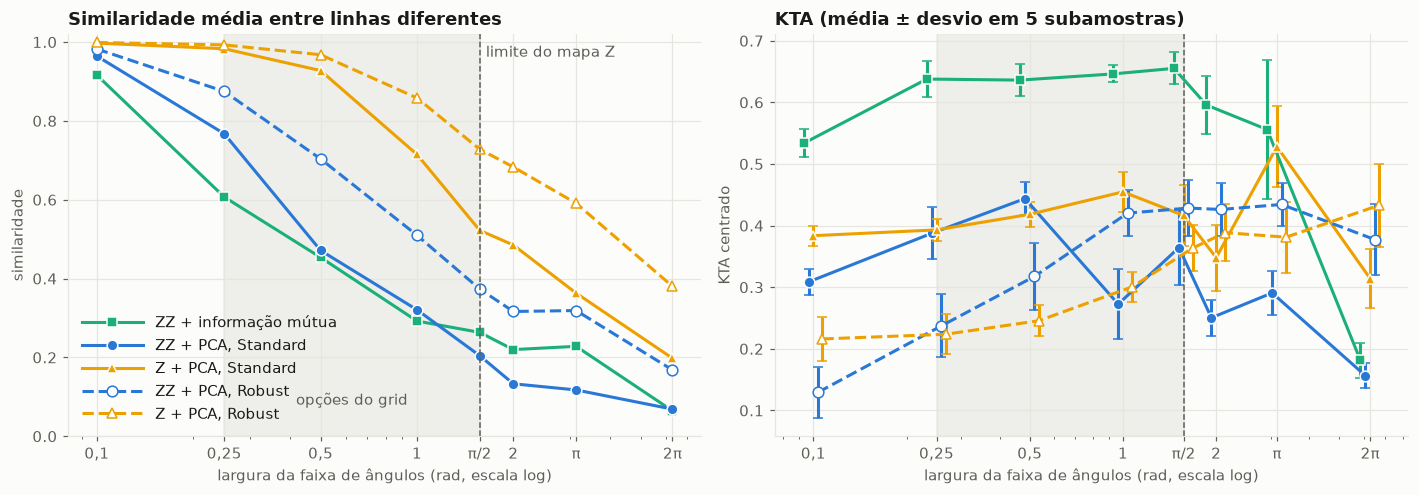

In [37]:
# A cor identifica o caminho até os ângulos; linha cheia com marcador preenchido é StandardScaler, linha tracejada
# com marcador vazio é RobustScaler (com informação mútua, os dois scalers dão o mesmo resultado: só uma curva)
STANDARD_LINE: dict[str, str] = {"linestyle": "-", "markeredgecolor": "#fcfcfb"}
ROBUST_LINE: dict[str, str] = {"linestyle": "--", "markerfacecolor": "#fcfcfb"}
SWEEP_STYLES: dict[str, dict[str, str]] = {
    "ZZ + informação mútua": {"color": "#1baf7a", "marker": "s", **STANDARD_LINE},
    "ZZ + PCA, Standard": {"color": "#2a78d6", "marker": "o", **STANDARD_LINE},
    "Z + PCA, Standard": {"color": "#eda100", "marker": "^", **STANDARD_LINE},
    "ZZ + PCA, Robust": {"color": "#2a78d6", "marker": "o", **ROBUST_LINE},
    "Z + PCA, Robust": {"color": "#eda100", "marker": "^", **ROBUST_LINE},
}
# Deslocamento horizontal pequeno (em escala log) no painel de KTA, para as barras de erro não se sobreporem
KTA_X_SHIFTS: dict[str, float] = dict(zip(SWEEP_STYLES, (0.93, 0.965, 1.0, 1.035, 1.07)))

fig, (similarity_ax, alignment_ax) = plt.subplots(1, 2, figsize=(13, 4.6))
for configuration, style in SWEEP_STYLES.items():
    rows = sweep_summary.xs(configuration, level="configuração")
    widths = rows.index.to_numpy()
    similarity_ax.plot(widths, rows["similarity_mean"], markersize=7, label=configuration, **style)
    alignment_ax.errorbar(widths * KTA_X_SHIFTS[configuration], rows["kta_mean"], yerr=rows["kta_std"], markersize=7,
                          capsize=3, label=configuration, **style)

for ax in (similarity_ax, alignment_ax):
    ax.axvspan(min(config.ANGLE_RANGE_WIDTH_GRID), max(config.ANGLE_RANGE_WIDTH_GRID), color="#e6e5e0", alpha=0.6,
               zorder=0)
    ax.set_xscale("log")
    ax.set_xticks(ANGLE_RANGE_WIDTHS, WIDTH_LABELS)
    ax.set_xlabel("largura da faixa de ângulos (rad, escala log)")
    ax.axvline(MONOTONIC_LIMIT_Z, color="#5f5e58", linewidth=1, linestyle="--")
# Os rótulos da faixa sombreada e da linha vertical ficam no painel da esquerda, no alto, onde não há curva por perto
similarity_ax.annotate("opções do grid", xy=(np.sqrt(min(config.ANGLE_RANGE_WIDTH_GRID) * max(config.ANGLE_RANGE_WIDTH_GRID)), 0.08),
                       ha="center", color="#5f5e58")
similarity_ax.annotate("limite do mapa Z", xy=(MONOTONIC_LIMIT_Z, 1.0), xytext=(4, -2),
                       textcoords="offset points", va="top", color="#5f5e58")
similarity_ax.set(title="Similaridade média entre linhas diferentes", ylabel="similaridade", ylim=(0, 1.02))
# Alça longa na legenda para o tracejado do Robust aparecer
similarity_ax.legend(loc="lower left", handlelength=4)
alignment_ax.set(title="KTA (média ± desvio em 5 subamostras)", ylabel="KTA centrado")
plt.tight_layout()
plt.show()

A média esconde o formato da distribuição. Os histogramas mostram **todas** as similaridades entre pares
de linhas diferentes (ZZ + PCA com StandardScaler, primeira subamostra) em três larguras: com a faixa estreita elas se amontoam perto
de 1; com a larga, perto de 0. É a concentração do kernel vista diretamente.

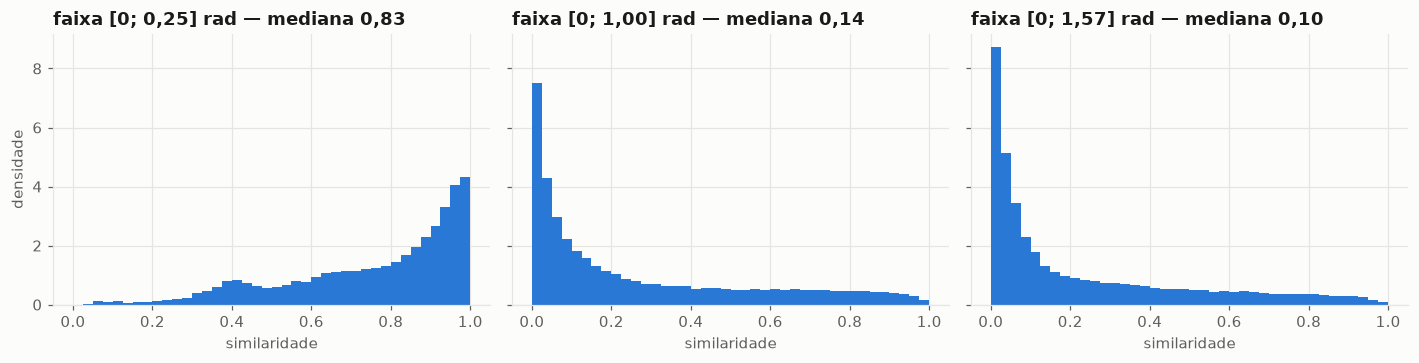

In [38]:
CONCENTRATION_WIDTHS: tuple[float, ...] = (0.25, 1.0, np.pi / 2)
concentration_features, concentration_labels = kernel_subsamples[config.RANDOM_STATE]
zz_map = build_angle_feature_map("zz", config.N_QUBITS)
fig, axes = plt.subplots(1, len(CONCENTRATION_WIDTHS), figsize=(13, 3.4), sharey=True)
for ax, width in zip(axes, CONCENTRATION_WIDTHS):
    angles = build_angle_preprocessor("standard", "pca", config.N_QUBITS, (0.0, width), config.RANDOM_STATE).fit_transform(
        concentration_features, concentration_labels
    )
    similarities = off_diagonal_values(angle_kernel_matrix(zz_map, angles))
    ax.hist(similarities, bins=np.linspace(0, 1, 41), color=NEUTRAL_SERIES_COLOR, density=True)
    ax.set(title=f"faixa [0; {width:.2f}] rad — mediana {np.median(similarities):.2f}".replace(".", ","),
           xlabel="similaridade")
axes[0].set_ylabel("densidade")
plt.tight_layout()
plt.show()

O "melhor ponto" de uma curva ruidosa pode ser acaso. A tabela conta, para cada configuração, em quantas das 5
subamostras cada largura válida (até π/2) foi a melhor, e lista as larguras cujo KTA médio fica a menos de 1 desvio
do máximo. São essas que o grid (`config.ANGLE_RANGE_WIDTH_GRID`) precisa conter, e não só a melhor.

In [39]:
valid_sweep = range_sweep[range_sweep["largura da faixa (rad)"] <= MONOTONIC_LIMIT_Z + 1e-9]
best_per_subsample = valid_sweep.loc[valid_sweep.groupby(["configuração", "subamostra"], sort=False)["KTA"].idxmax()]
best_width_counts = pd.crosstab(best_per_subsample["configuração"], best_per_subsample["largura da faixa (rad)"])
best_width_counts = best_width_counts.reindex(columns=[w for w in ANGLE_RANGE_WIDTHS if w <= MONOTONIC_LIMIT_Z + 1e-9],
                                              fill_value=0)
best_width_counts.columns = ["0,1", "0,25", "0,5", "1", "π/2"]


def widths_near_the_best(configuration: str) -> list[float]:
    """Larguras válidas cujo KTA médio fica a menos de 1 desvio (o da melhor) do máximo."""
    rows = sweep_summary.xs(configuration, level="configuração")
    rows = rows[rows.index <= MONOTONIC_LIMIT_Z + 1e-9]
    best = rows["kta_mean"].idxmax()
    return rows.index[rows["kta_mean"] >= rows.loc[best, "kta_mean"] - rows.loc[best, "kta_std"]].tolist()


near_best = {name: widths_near_the_best(name) for name in best_width_counts.index}
best_width_counts["larguras a < 1 desvio do máximo"] = [
    ", ".join(f"{width:.2f}" for width in near_best[name]) for name in best_width_counts.index
]
best_width_counts["todas no grid?"] = [
    all(any(np.isclose(width, option) for option in config.ANGLE_RANGE_WIDTH_GRID) for width in near_best[name])
    for name in best_width_counts.index
]
best_width_counts.loc[list(SWEEP_CONFIGURATIONS)].style.set_caption(
    "Em quantas das 5 subamostras cada largura válida foi a melhor, e quais ficam a menos de 1 desvio do máximo"
)

,"0,1","0,25","0,5",1,π/2,larguras a < 1 desvio do máximo,todas no grid?
configuração,,,,,,,
ZZ + informação mútua,0,1,0,2,2,"0.25, 0.50, 1.00, 1.57",True
"ZZ + PCA, Standard",0,0,5,0,0,0.50,True
"Z + PCA, Standard",0,0,0,5,0,1.00,True
"ZZ + PCA, Robust",0,0,0,2,3,"1.00, 1.57",True
"Z + PCA, Robust",0,0,0,0,5,1.57,True


#### 4.7.1 Armadilha: ângulos são periódicos, e os mapas do Qiskit dobram o ângulo

> **Papel no experimento:** **define opções do grid** (a escolha final entre elas é da validação cruzada, na Seção 6). Fixa o limite de π/2 para a largura e o `clip` do MinMax. Vale para os **dois** modelos quânticos: a periodicidade
> é uma propriedade do circuito de codificação, e não do kernel.

Uma rotação de 2π é uma volta completa: o qubit volta ao mesmo estado. Isso cria riscos que os artigos não
discutem:

1. **Valores fora da faixa do treino.** Uma transação da validação ou do teste mais extrema que todas as do treino
   ultrapassaria o limite da faixa, "daria a volta" e ficaria parecida com o extremo **oposto**. O
   `clip=True` do MinMax (a etapa `angle_scaler` do pipeline) a mantém na borda.
2. **O fator 2 dos feature maps do Qiskit.** O `z_feature_map` e o `zz_feature_map` aplicam a rotação P(α·x) com
   **α = 2** por padrão, então o período em x cai de 2π para **π**. No **mapa Z**, na faixa [0, π] (a mais usada na
   literatura), as duas pontas viram o **mesmo estado**: a fraude mais extrema fica codificada igual ao valor máximo.
   Até π/2, no mapa Z, "mais distante" sempre significa "menos parecido".
3. **No ZZ, a monotonicidade acaba antes.** O termo de pares, (π − xᵢ)(π − xⱼ), também multiplicado por 2, varia
   bem mais rápido que os termos de 1 qubit. A similaridade cai perto de zero e **volta a subir** antes mesmo de π/2.
   Não é a patologia do Z (estados idênticos), mas "mais distante" deixa de significar "menos parecido".

O gráfico mostra a similaridade entre um ponto e o mesmo ponto com uma feature deslocada de Δ: 1 qubit no mapa Z,
e 5 qubits no ZZ (as outras features fixas em 0,5 rad).

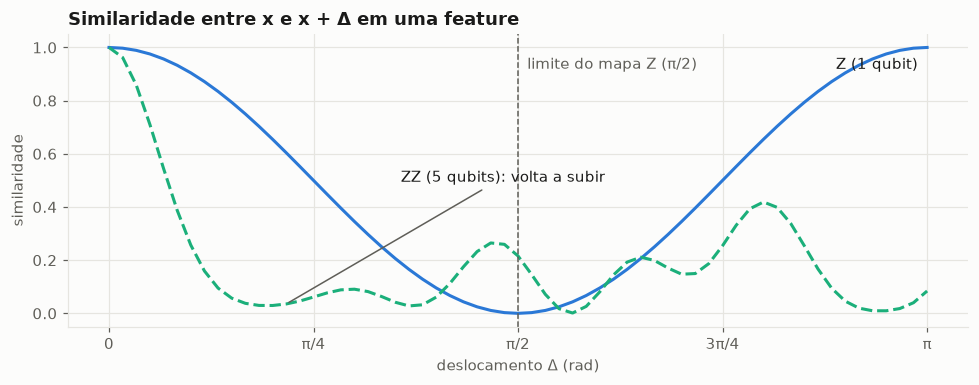

ZZ: a similaridade atinge o primeiro mínimo em Δ = 0.63 rad e depois volta a subir
 Z, 5 qubits, faixa [0, π]: extremos opostos (tudo 0 × tudo π) = 1.00; média entre pares quaisquer = 0.36
ZZ, 5 qubits, faixa [0, π]: extremos opostos (tudo 0 × tudo π) = 0.44; média entre pares quaisquer = 0.17


In [40]:
distances = np.linspace(0, np.pi, 61)
single_qubit_z = build_angle_feature_map("z", n_qubits=1)
z_similarity = angle_kernel_matrix(single_qubit_z, [[0.0]], distances.reshape(-1, 1))[0]

zz_reference = np.full((1, config.N_QUBITS), 0.5)
zz_shifted = np.repeat(zz_reference, len(distances), axis=0)
zz_shifted[:, -1] = 0.5 + distances
zz_similarity = angle_kernel_matrix(build_angle_feature_map("zz", config.N_QUBITS), zz_reference, zz_shifted)[0]

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(distances, z_similarity, color=NEUTRAL_SERIES_COLOR)
ax.plot(distances, zz_similarity, color="#1baf7a", linestyle="--")
ax.annotate("Z (1 qubit)", xy=(np.pi, 1.0), xytext=(-6, -14), textcoords="offset points", ha="right", color="#1a1a19")
first_rise = int(np.argmax(np.diff(zz_similarity) > 0)) + 1
ax.annotate("ZZ (5 qubits): volta a subir", xy=(distances[first_rise], zz_similarity[first_rise]),
            xytext=(75, 80), textcoords="offset points", color="#1a1a19",
            arrowprops={"arrowstyle": "-", "color": "#5f5e58", "linewidth": 1})
ax.axvline(np.pi / 2, color="#5f5e58", linewidth=1, linestyle="--")
ax.annotate("limite do mapa Z (π/2)", xy=(np.pi / 2, 0.92), xytext=(6, 0), textcoords="offset points", color="#5f5e58")
ax.set(title="Similaridade entre x e x + Δ em uma feature", xlabel="deslocamento Δ (rad)", ylabel="similaridade")
ax.set_xticks([0, np.pi / 4, np.pi / 2, 3 * np.pi / 4, np.pi], ["0", "π/4", "π/2", "3π/4", "π"])
plt.tight_layout()
plt.show()

print(f"ZZ: a similaridade atinge o primeiro mínimo em Δ = {distances[first_rise - 1]:.2f} rad e depois volta a subir")
all_zeros, all_pi = np.zeros((1, config.N_QUBITS)), np.full((1, config.N_QUBITS), np.pi)
for map_name in ("z", "zz"):
    extremes_similarity = angle_kernel_matrix(build_angle_feature_map(map_name, config.N_QUBITS), all_zeros, all_pi)[0, 0]
    typical_similarity = range_sweep.query(
        "`largura da faixa (rad)` == @np.pi and configuração.str.startswith(@map_name.upper() + ' ') and not configuração.str.contains('Robust')"
    )["similaridade média"].mean()
    print(f"{map_name.upper():>2}, 5 qubits, faixa [0, π]: extremos opostos (tudo 0 × tudo π) = {extremes_similarity:.2f}; "
          f"média entre pares quaisquer = {typical_similarity:.2f}")

### 4.8 Ângulo × amplitude

> **Papel no experimento:** **define opções do grid** (a escolha final entre elas é da validação cruzada, na Seção 6). Delimita as constantes de preenchimento testadas (`config.AMPLITUDE_PADDING_GRID`).
>
> **Para qual modelo.** Como na 4.7, o KTA é uma medida de kernel e vale diretamente para o QSVM. O que vale para os
> dois modelos quânticos é a propriedade da codificação: completar com zero apaga a norma do vetor, e estados que
> diferem só na norma ficam idênticos para qualquer medição. A constante para o Quantum AdaBoost será escolhida pela
> validação cruzada dele (PLAN, ponto ①).

A codificação de amplitude (Variação B do TCC) usa as 31 features, mais uma constante, como as 32 amplitudes de
um estado de 5 qubits. Duas propriedades dela pesam na interpretação:
- **O kernel é calculável classicamente.** A similaridade entre dois estados é cos²(ângulo entre os vetores), uma
  conta clássica simples. O teste `test_amplitude_kernel_matches_qiskit_simulation` mostra que a simulação do Qiskit
  dá exatamente esse valor.
- **A normalização descarta a norma do vetor.** Um estado quântico precisa ter norma 1, então x e 2x viram o
  **mesmo** estado. Só que a norma é sinal de fraude: fraudes ficam mais longe do centro dos dados. Completar as
  posições vazias com uma **constante** (e não com zero) preserva essa informação, porque o ângulo entre o vetor e
  o eixo da constante passa a depender da norma. O tamanho da constante vira um hiperparâmetro.

In [41]:
standardized_norms = np.linalg.norm(StandardScaler().fit_transform(balanced_train_features), axis=1)
print("Norma do vetor padronizado (mediana): "
      f"legítimas {np.median(standardized_norms[balanced_train_labels == LEGITIMATE_LABEL]):.2f}, "
      f"fraudes {np.median(standardized_norms[balanced_train_labels == FRAUD_LABEL]):.2f}")

# Até 10, para o melhor valor não ficar na borda da varredura (com só 0, 1 e 3, ficava)
AMPLITUDE_PADDING_VALUES: tuple[float, ...] = (0.0, 1.0, 3.0, 5.0, 10.0)
AMPLITUDE_SCALERS: tuple[ScalerName, ...] = ("standard", "robust")


def summarize_amplitude_sweep(sweep: pd.DataFrame) -> pd.DataFrame:
    """Média da similaridade e média ± desvio do KTA, por scaler e constante."""
    return sweep.groupby(["scaler", "constante de preenchimento"]).agg(
        similaridade_media=("similaridade média", "mean"), KTA_media=("KTA", "mean"), KTA_desvio=("KTA", "std")
    )


amplitude_sweep = amplitude_alignment_sweep(
    kernel_subsamples, AMPLITUDE_SCALERS, AMPLITUDE_PADDING_VALUES, config.N_QUBITS
).rename(columns=SWEEP_COLUMN_LABELS)
amplitude_comparison = summarize_amplitude_sweep(amplitude_sweep)
amplitude_comparison.style.format("{:.2f}").set_caption("Amplitude: média de 5 subamostras")

Norma do vetor padronizado (mediana): legítimas 3.80, fraudes 4.88


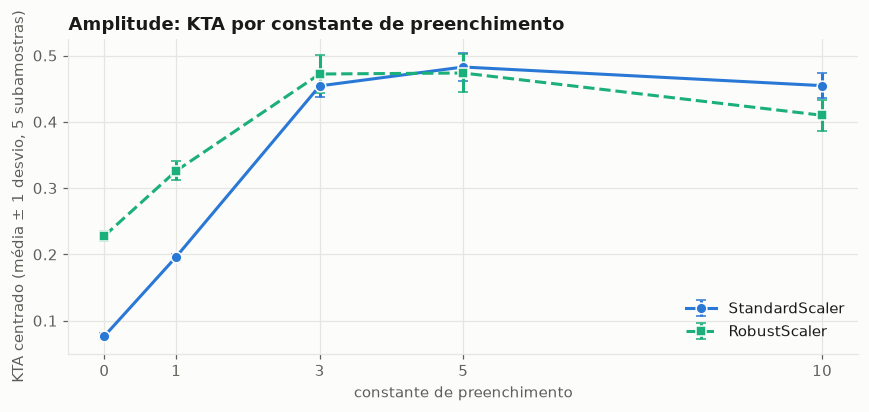

In [42]:
AMPLITUDE_SCALER_STYLES: dict[str, dict[str, str]] = {
    "standard": {"color": "#2a78d6", "marker": "o", "linestyle": "-", "label": "StandardScaler"},
    "robust": {"color": "#1baf7a", "marker": "s", "linestyle": "--", "label": "RobustScaler"},
}

fig, ax = plt.subplots(figsize=(8, 3.8))
for scaler, style in AMPLITUDE_SCALER_STYLES.items():
    rows = amplitude_comparison.xs(scaler, level="scaler")
    ax.errorbar(rows.index.to_numpy(), rows["KTA_media"], yerr=rows["KTA_desvio"], markersize=7,
                markeredgecolor="#fcfcfb", capsize=3, **style)
ax.set_xticks(list(AMPLITUDE_PADDING_VALUES))
ax.set(title="Amplitude: KTA por constante de preenchimento",
       xlabel="constante de preenchimento", ylabel="KTA centrado (média ± 1 desvio, 5 subamostras)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

### 4.9 Seleção de features: PCA × informação mútua

> **Papel no experimento:** **define opções do grid** (a escolha final entre elas é da validação cruzada, na Seção 6). Os dois redutores entram no grid; as features escolhidas aqui não são usadas pelo modelo.

Com 5 qubits na codificação de ângulo, as 31 features precisam virar 5. As duas estratégias fazem apostas
diferentes:
- **PCA:** combina todas as features em 5 eixos de máxima **variância**. Não sabe o que é fraude. Preserva o
  máximo de informação geral, que pode ou não ser a informação útil.
- **Informação mútua:** mantém as 5 features que individualmente mais dizem sobre o **rótulo**. Mas avalia cada
  uma isoladamente: se duas carregam a mesma informação, as duas podem ser escolhidas e um qubit é desperdiçado.

**Cuidado ao ler o KTA da informação mútua na Seção 4.7:** ela escolheu as features olhando o rótulo *destas
mesmas linhas*, então o seu KTA aqui é otimista. A comparação justa só acontece na validação cruzada, em que a
seleção é refeita em cada fold sem ver as linhas avaliadas.

**Por que só o StandardScaler aqui.** Com informação mútua no meio, o scaler não muda nada: Standard e Robust
escolhem as mesmas features (4.6.2), e a célula confere isso. Com PCA no meio, o scaler muda os componentes, mas
esta subseção usa o PCA só para medir a redundância entre eles; a célula mede com os dois scalers. O efeito do
scaler sobre o kernel está na 4.7, e a escolha entre os dois é da validação cruzada.

A segunda célula repete a seleção com as 5 sementes do sorteio, para ver quais features são escolhidas sempre e
quais dependem do acaso.

In [43]:
mutual_info_path = build_angle_preprocessor(
    "standard", "mutual_info", config.N_QUBITS, random_state=config.RANDOM_STATE
).fit(balanced_train_features, balanced_train_labels)
selected_mask = mutual_info_path.named_steps["reducer"].get_support()
selected_features = [name for name, keep in zip(MODEL_FEATURE_COLUMNS, selected_mask) if keep]
print(f"Informação mútua escolheu: {selected_features}")
robust_selection = build_angle_preprocessor(
    "robust", "mutual_info", config.N_QUBITS, random_state=config.RANDOM_STATE
).fit(balanced_train_features, balanced_train_labels).named_steps["reducer"].get_support()
print(f"Com RobustScaler, a informação mútua escolhe as mesmas features: {bool((robust_selection == selected_mask).all())}")


def mean_absolute_correlation(frame: pd.DataFrame) -> float:
    """Média do |r| entre pares de colunas distintas."""
    correlation = frame.corr().to_numpy()
    return float(np.abs(correlation[np.triu_indices_from(correlation, k=1)]).mean())


is_fraud = balanced_train_df[TARGET_COLUMN] == FRAUD_LABEL
pca_path = build_angle_preprocessor("standard", "pca", config.N_QUBITS, random_state=config.RANDOM_STATE).fit(
    balanced_train_features
)
fraud_components = pd.DataFrame(pca_path[:-1].transform(balanced_train_features[is_fraud.to_numpy()]))
robust_pca_path = build_angle_preprocessor("robust", "pca", config.N_QUBITS, random_state=config.RANDOM_STATE).fit(
    balanced_train_features
)
robust_fraud_components = pd.DataFrame(robust_pca_path[:-1].transform(balanced_train_features[is_fraud.to_numpy()]))
redundancy = pd.Series(
    {
        "5 escolhidas pela MI, nas fraudes": mean_absolute_correlation(balanced_train_df.loc[is_fraud, selected_features]),
        "5 escolhidas pela MI, nas legítimas": mean_absolute_correlation(balanced_train_df.loc[~is_fraud, selected_features]),
        "todas as 28 V, nas fraudes": mean_absolute_correlation(balanced_train_df.loc[is_fraud, list(PCA_FEATURE_COLUMNS)]),
        "5 componentes do PCA (StandardScaler), nas fraudes": mean_absolute_correlation(fraud_components),
        "5 componentes do PCA (RobustScaler), nas fraudes": mean_absolute_correlation(robust_fraud_components),
    },
    name="correlação absoluta média",
)
display(redundancy.to_frame().style.format("{:.2f}").set_caption("Redundância entre as features que ocupariam os 5 qubits"))
balanced_train_df.loc[is_fraud, selected_features].corr().style.format("{:.2f}").set_caption(
    "Correlação entre as 5 features escolhidas, nas fraudes do treino"
)

Informação mútua escolheu: ['V4', 'V10', 'V12', 'V14', 'V17']
Com RobustScaler, a informação mútua escolhe as mesmas features: True


,correlação absoluta média
"5 escolhidas pela MI, nas fraudes",0.75
"5 escolhidas pela MI, nas legítimas",0.21
"todas as 28 V, nas fraudes",0.31
"5 componentes do PCA (StandardScaler), nas fraudes",0.06
"5 componentes do PCA (RobustScaler), nas fraudes",0.09


,V4,V10,V12,V14,V17
V4,1.00,-0.73,-0.79,-0.68,-0.61
V10,-0.73,1.00,0.85,0.69,0.82
V12,-0.79,0.85,1.00,0.84,0.84
V14,-0.68,0.69,0.84,1.00,0.63
V17,-0.61,0.82,0.84,0.63,1.00


In [44]:
selections_by_seed: dict[int, list[str]] = {}
for seed in SUBSAMPLE_SEEDS:
    seed_features, seed_labels = make_undersampler(seed).fit_resample(X_train, y_train)
    reducer = build_angle_preprocessor(
        "standard", "mutual_info", config.N_QUBITS, random_state=config.RANDOM_STATE
    ).fit(seed_features.to_numpy(), seed_labels.to_numpy()).named_steps["reducer"]
    selections_by_seed[seed] = [name for name, keep in zip(MODEL_FEATURE_COLUMNS, reducer.get_support()) if keep]

selection_counts = Counter(feature for selection in selections_by_seed.values() for feature in selection)
selection_table = pd.DataFrame(
    {f"subamostra {seed}": {feature: "✓" if feature in selection else "" for feature in selection_counts}
     for seed, selection in selections_by_seed.items()}
)
selection_table["vezes escolhida (de 5)"] = pd.Series(selection_counts)
selection_table = selection_table.sort_values("vezes escolhida (de 5)", ascending=False)
# A redundância de cada escolha: |r| médio entre as 5 features, nas fraudes do treino
train_fraud_features = X_train[y_train == FRAUD_LABEL]
selection_table.loc["|r| médio entre as 5, nas fraudes"] = [
    *(f"{mean_absolute_correlation(train_fraud_features[selection]):.2f}" for selection in selections_by_seed.values()),
    "",
]
selection_table.style.set_caption(
    "As 5 features escolhidas pela informação mútua no treino balanceado, por subamostra "
    "(SUBSAMPLE_SEEDS; não são as sementes de robustez da Seção 9)"
)

,subamostra 42,subamostra 0,subamostra 1,subamostra 2,subamostra 3,vezes escolhida (de 5)
V10,✓,✓,✓,✓,✓,5
V12,✓,✓,✓,✓,✓,5
V17,✓,✓,✓,✓,✓,5
V14,✓,✓,✓,✓,✓,5
V4,✓,,✓,✓,✓,4
V3,,✓,,,,1
"|r| médio entre as 5, nas fraudes",0.75,0.72,0.75,0.75,0.75,


### 4.10 Undersampling: só no treino, e só dentro do pipeline

> **Papel no experimento:** **só ilustra ou verifica.** Nada daqui entra no pipeline nem no modelo. Prova, com um pipeline mínimo, que o undersampling do pipeline age só no treino; o undersampling em si (1:1) é uma etapa do pipeline de todos os modelos.

O `RandomUnderSampler` descarta legítimas ao acaso até igualar as fraudes (razão 1:1). Ele entra como **primeira
etapa do pipeline** (`imblearn.pipeline.Pipeline`), o que garante três coisas:
- **Só age no `fit`.** Na predição ele é pulado, então validação e teste são sempre avaliados com a proporção real.
- **O sorteio usa apenas linhas de treino.**
- **A semente é um parâmetro.** A análise de robustez (Seção 9) repete tudo com as 5 sementes de `config`.

A célula prova as duas primeiras garantias com um pipeline mínimo. O modelo dele é um
`DummyClassifier(strategy="prior")`, que não olha as features: ele só aprende a proporção de classes que chega até
ele. Isso torna visível **o que o undersampling ensina a qualquer modelo** sobre a frequência da fraude. O teste
`test_undersampler_balances_training_and_skips_prediction` verifica o mesmo no pacote.

In [45]:
undersampled_features, undersampled_labels = make_undersampler(config.RANDOM_STATE).fit_resample(X_train, y_train)

prior_probe = ImbPipeline(
    [
        ("undersampler", make_undersampler(config.RANDOM_STATE)),
        ("scaler", StandardScaler()),
        ("model", DummyClassifier(strategy="prior")),
    ]
).fit(X_train, y_train)
validation_fraud_scores = prior_probe.predict_proba(X_validation)[:, 1]

assert undersampled_labels.value_counts().to_dict() == {LEGITIMATE_LABEL: train_frauds, FRAUD_LABEL: train_frauds}
assert undersampled_features.index.isin(train_df.index).all(), "o sorteio só pode usar linhas de treino"
assert len(validation_fraud_scores) == len(X_validation), "na predição, nenhuma linha pode ser descartada"

learned_prior = prior_probe.named_steps["model"].class_prior_[1]
print(f"Treino antes do undersampling: {train_legitimate:,} legítimas e {train_frauds} fraudes")
print(f"Treino depois (o que o modelo vê): {len(undersampled_labels)} linhas, {undersampled_labels.mean():.0%} fraudes")
print(f"Validação avaliada: {len(validation_fraud_scores):,} linhas ({y_validation.mean():.4%} fraudes)")
print(f"P(fraude) aprendida pelo modelo: {learned_prior:.2f}  |  proporção real na validação: {y_validation.mean():.4f} "
      f"({learned_prior / y_validation.mean():.0f}× menor)")

# A correção de Dal Pozzolo et al. (2015), aplicada ao 0,50 aprendido, precisa devolver a proporção do treino
corrected_prior = float(undersampling_corrected_probability(learned_prior, legitimate_keep_probability))
assert np.isclose(corrected_prior, y_train.mean())
print(f"0,50 corrigido pela fórmula de Dal Pozzolo: {corrected_prior:.5f} = proporção de fraudes no treino ({y_train.mean():.5f})")

Treino antes do undersampling: 169,951 legítimas e 284 fraudes
Treino depois (o que o modelo vê): 568 linhas, 50% fraudes
Validação avaliada: 56,745 linhas (0.1657% fraudes)
P(fraude) aprendida pelo modelo: 0.50  |  proporção real na validação: 0.0017 (302× menor)
0,50 corrigido pela fórmula de Dal Pozzolo: 0.00167 = proporção de fraudes no treino (0.00167)


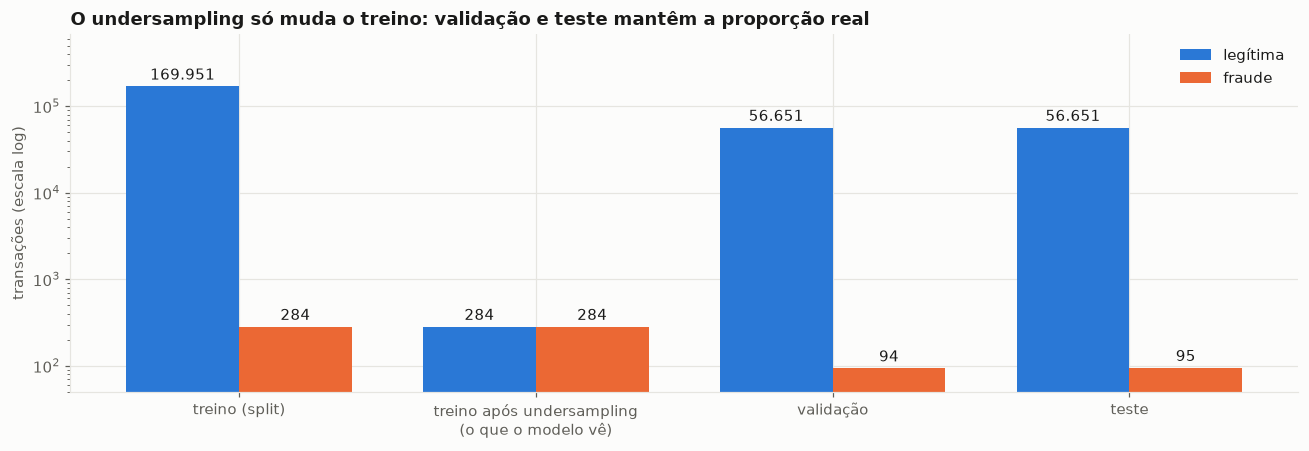

In [46]:
composition = pd.DataFrame(
    {
        "treino (split)": y_train.value_counts(),
        "treino após undersampling\n(o que o modelo vê)": undersampled_labels.value_counts(),
        "validação": y_validation.value_counts(),
        "teste": test_df[TARGET_COLUMN].value_counts(),
    }
).loc[[LEGITIMATE_LABEL, FRAUD_LABEL]]

fig, ax = plt.subplots(figsize=(12, 4.2))
positions = np.arange(composition.shape[1])
bar_width = 0.38
for offset, label in zip((-bar_width / 2, bar_width / 2), composition.index):
    bars = ax.bar(positions + offset, composition.loc[label], width=bar_width, color=CLASS_COLORS[label], label=CLASS_NAMES[label])
    ax.bar_label(bars, labels=[brazilian_integer(int(n)) for n in composition.loc[label]], padding=2)
ax.set_yscale("log")
ax.set_xticks(positions, composition.columns)
ax.set(title="O undersampling só muda o treino: validação e teste mantêm a proporção real",
       ylabel="transações (escala log)", ylim=(50, composition.to_numpy().max() * 4))
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

### 4.11 Leitura dos resultados e decisões para o grid

> **Papel no experimento:** **define opções do grid.** Reúne o que as Seções 4.6 a 4.10 mediram e transforma isso nas opções que a busca de hiperparâmetros (Seção 6) vai testar. Nenhuma opção é escolhida aqui como vencedora: isso é papel da validação cruzada.

**O que esta leitura responde.** Antes de treinar qualquer modelo, é preciso decidir **o que vale a pena testar**.
Num modelo quântico, o pré-processamento não é uma limpeza neutra dos dados: ele decide como cada transação vira
um estado quântico e, com isso, o quanto duas transações parecem semelhantes para o modelo. As Seções 4.6 a 4.10
investigaram sete perguntas:

| # | Pergunta | Resposta curta | Evidência |
|---|---|---|---|
| 1 | Em que dados o scaler deve aprender? | No treino já balanceado, dentro do pipeline | 4.6.0 |
| 2 | StandardScaler ou RobustScaler? Faz diferença? | Só faz diferença se houver PCA (ou a amplitude) depois dele | 4.6.0 e 4.6.2 |
| 3 | Por que padronizar antes do PCA? | Sem isso, o PCA gasta qubits com a escala de `Time` e `Amount` | 4.6.3 |
| 4 | Em que faixa os valores devem virar ângulos? | Entre 0,25 e π/2 rad: a faixa é a largura de banda do kernel, e acima de π/2 os ângulos "dão a volta" | 4.6.1, 4.7 e 4.7.1 |
| 5 | Com que constante completar o vetor da amplitude? | 1, 3 ou 5; nunca zero | 4.8 |
| 6 | Como reduzir 31 features a 5 qubits? | PCA e informação mútua, os dois no grid | 4.9 |
| 7 | O undersampling se comporta como deveria? | Sim, e ele ensina ao modelo que metade das transações é fraude | 4.10 |

As subseções 4.11.1 a 4.11.5 retomam cada pergunta na mesma ordem, sempre em quatro passos: o que foi medido, o que
os dados mostraram, o que isso quer dizer e qual decisão sai daí. A 4.11.6 fecha com a conclusão da seção e a tabela
de opções que segue para o grid.

**De onde vêm os números.** Todos vêm do **treino**, nunca da validação ou do teste. A maior parte vem do **treino
balanceado**: as 284 fraudes do treino mais 284 legítimas sorteadas pelo undersampler do pipeline, o mesmo formato de
dados que os modelos recebem.

**Como se compara uma configuração sem treinar modelo.** A seção usou duas medidas do **kernel**, a tabela de
similaridades entre todos os pares de transações que o QSVM usa para decidir:
- **Similaridade média** entre transações diferentes. Perto de 1, tudo parece igual e o kernel não distingue
  ninguém. Perto de 0, cada transação só se parece consigo mesma, e o modelo tende a decorar o treino.
- **KTA** (*kernel-target alignment*, alinhamento kernel-alvo, na versão centrada). Mede o quanto "parecidas para o
  kernel" coincide com "da mesma classe". Funciona como uma correlação: perto de 0, o kernel ignora o rótulo; quanto
  maior, melhor ele agrupa fraudes com fraudes e legítimas com legítimas.

O KTA é um **indicador** barato, e não a métrica final. Aqui ele serviu para descartar opções claramente ruins e
delimitar uma região; nunca para escolher o vencedor.


#### 4.11.1 Escalonamento: onde o scaler aprende, qual usar e por que ele vem antes do PCA

> **Papel no experimento:** **define opções do grid.** Decide onde o scaler é ajustado (dentro do pipeline, depois do undersampling) e em quais caminhos a escolha entre StandardScaler e RobustScaler entra no grid.

**Pergunta 1: em que dados o scaler deve aprender?**
- **O que foi medido (4.6.0).** Um scaler aprende parâmetros com os dados: o StandardScaler, a média e o desvio
  padrão de cada coluna; o RobustScaler, a mediana e o IQR (intervalo interquartil, a distância entre os quartis de
  25% e 75%). A 4.6.0 calculou esses parâmetros em duas versões do treino: como ele sai do split (0,17% de fraudes) e
  depois do undersampling (50%).
- **O que os dados mostraram.** Nas quatro `V` de maior informação mútua, o desvio padrão aumenta de 4,1 a 7,1 vezes
  e o IQR de 4,6 a 7,3 vezes. Exemplo: um StandardScaler ajustado no treino inteiro dividiria a `V14` por 0,96;
  ajustado no treino balanceado, divide por 4,66. Nas 28 `V`, a razão entre os desvios vai de 0,97 a 7,14 (mediana
  2,26) e chega a 4 ou mais em só 6 delas. Essas 6 estão entre as mais informativas: a ordem das mudanças acompanha
  a ordem da informação mútua (correlação de Spearman de 0,84, p = 2,5 × 10⁻⁸).
- **O que isso quer dizer.** O undersampling não muda só a proporção das classes: muda a **escala** das features, e
  justamente das que carregam o sinal de fraude. Com metade das linhas sendo fraude, a "cauda rara" de antes passa a
  definir a distribuição. Parâmetros de escalonamento aprendidos numa distribuição não servem para a outra.
- **Decisão.** O scaler é ajustado **dentro do pipeline, depois do undersampling**, refeito em cada fold, e nunca
  reaproveitado de outra amostra (o treino inteiro, a base inteira ou os dados de outro trabalho).

**Pergunta 2: StandardScaler ou RobustScaler, e isso faz diferença?**
- **O que foi medido (4.6.2).** A maior diferença entre os ângulos produzidos por caminhos de pré-processamento
  diferentes, nos dados reais.
- **O que os dados mostraram.** StandardScaler seguido de MinMax dá **exatamente** o mesmo resultado que o MinMax
  sozinho (diferença 0,0000), e o RobustScaler também. Com informação mútua entre o scaler e o MinMax, Standard e
  Robust continuam idênticos. Com PCA no meio, eles divergem em até 1,55 rad, quase a largura inteira da faixa
  padrão (π/2 ≈ 1,57). Na amplitude, o scaler também muda o resultado (4.8: com a constante 1, KTA de 0,20 com
  Standard e 0,33 com Robust).
- **O que isso quer dizer.** O MinMax só olha a posição de cada valor entre o mínimo e o máximo da coluna, e
  esticar ou deslocar a coluna antes não muda essa posição: a coluna [1, 2, 3] vira [0; 0,5; 1] com ou sem o
  StandardScaler antes. A informação mútua também não liga para a escala. O PCA liga: ele procura as direções de
  maior variância a partir do centro dos dados, e os dois scalers põem esse centro em lugares diferentes. Nas `V`
  mais informativas, média e mediana ficam de 1,8 a 2,8 unidades uma da outra no treino balanceado (cerca de meio
  desvio): o StandardScaler centraliza na média, puxada pela cauda das fraudes, e o RobustScaler na mediana, que a
  cauda não puxa.

  A pergunta "qual scaler usar?", que o texto do TCC deixava em aberto, tem então uma resposta em duas partes:
  **depende do que vem depois**, e onde a escolha importa ela é empírica.
- **Decisão.** Standard e Robust entram no grid **só onde a escolha muda alguma coisa:** no caminho com PCA, na
  codificação de amplitude e, pelo mesmo motivo (o kernel RBF mede distâncias), no SVM clássico. No caminho com
  informação mútua, um só basta. A sequência Standard → MinMax do texto do TCC sai (CC1, TX8).

**Pergunta 3: por que padronizar antes do PCA?**
- **O que foi medido (4.6.3).** O procedimento de El Alami et al. (2025), PCA de 7 componentes nas colunas
  originais sem padronizar, reproduzido nas 568 linhas do treino balanceado.
- **O que os dados mostraram.** O 1º componente é `Time` (carga 1,00, praticamente toda a variância) e o 2º é
  `Amount`. Do 3º ao 7º são misturas que incluem as features de fraude: a fração vinda das 4 de maior informação
  mútua é de 0,36; 0,39; 0,05; 0,49 e 0,21.
- **O que isso quer dizer.** O PCA escolhe direções pela variância, e a variância depende da unidade de cada coluna:
  a escala de `Time`, medido em segundos ao longo de dois dias, é de 24 mil a 143 mil vezes a das `V` (4.1). Sem
  padronização, 2 dos 7 qubits ficam com "quando" e "quanto", que pouco dizem sobre fraude. O sinal de fraude não
  some (o MinMax reescala cada componente depois, então os componentes de variância minúscula voltam a ocupar a faixa
  inteira), mas sobram menos qubits para ele. Com padronização, os 5 componentes do nosso pipeline explicam 64,8%
  (Standard) ou 78,9% (Robust) da variância. Os dois números não são comparáveis entre si, porque cada scaler muda a
  variância total, e explicar mais variância não quer dizer separar melhor as classes.
- **Decisão.** O scaler vem **antes** do PCA no pipeline, e `Time` não entra nos modelos (foi trocado pela hora do
  dia em seno e cosseno, 4.4).


#### 4.11.2 Codificação de ângulo: a faixa, a periodicidade e o mapa

> **Papel no experimento:** **define opções do grid.** Delimita as larguras da faixa de ângulos (`config.ANGLE_RANGE_WIDTH_GRID`), fixa o limite de π/2 e o `clip` do MinMax, e mantém os mapas Z e ZZ com 1 ou 2 repetições.

**Pergunta 4: em que faixa os valores devem virar ângulos?**

Na codificação de ângulo, cada um dos 5 valores que saem do redutor passa por um MinMax, que o leva para uma faixa
[0, largura], e o resultado vira o ângulo de uma rotação de um qubit. Os artigos tratam a largura como detalhe
técnico ([0, 1] ou [0, π], sem discussão). Os dados mostram que ela é a decisão mais importante da codificação.

- **O achatamento (4.6.1).** O MinMax leva o menor valor ao início da faixa e o maior ao fim, e espreme todo o resto
  entre eles. No treino balanceado, a `V17` (a feature de maior informação mútua) vai de −24,0 (uma fraude) a 6,7, e
  90% das legítimas ficam num trecho de 0,21 rad, só 7% do intervalo [0, π]. Isso não é necessariamente ruim: para
  separar fraude de legítima, as legítimas não precisam ser distinguíveis entre si. O problema são as fraudes
  *parecidas* com legítimas, que caem justamente nessa fatia de pouca resolução. Quanta resolução ela recebe é o que
  a largura da faixa controla.
- **O que foi medido (4.7).** Similaridade média e KTA do kernel, em 8 larguras (de 0,1 a 2π rad) e 5
  configurações: ZZ com informação mútua, e ZZ e Z com PCA, cada um com os dois scalers. Cada combinação foi medida
  em 5 subamostras de 400 linhas do treino balanceado. Os mapas usaram 2 repetições, o padrão.
- **O que os dados mostraram.**
  - A similaridade média **sempre cai** quando a faixa alarga: no ZZ com PCA e StandardScaler, de 0,96 em 0,1 rad
    para 0,07 em 2π. Os histogramas mostram o mesmo par a par: a mediana das similaridades é 0,83 na faixa
    [0; 0,25], 0,14 em [0; 1] e 0,10 em [0; π/2].
  - O KTA **não** cai sempre: ele tem um máximo no meio. Entre as larguras até π/2:

    | Configuração | Largura de maior KTA médio | KTA | Larguras a menos de 1 desvio do máximo |
    |---|---|---|---|
    | ZZ + informação mútua | π/2 | 0,66 ± 0,03 | 0,25; 0,5; 1; π/2 |
    | ZZ + PCA, StandardScaler | 0,5 rad | 0,44 ± 0,03 | 0,5 |
    | Z + PCA, StandardScaler | 1 rad | 0,45 ± 0,03 | 1 |
    | ZZ + PCA, RobustScaler | π/2 | 0,43 ± 0,05 | 1; π/2 |
    | Z + PCA, RobustScaler | π/2 | 0,36 ± 0,04 | π/2 |

  - O scaler desloca o melhor ponto. Com RobustScaler, as transações ficam mais parecidas na mesma largura (ZZ +
    PCA em 0,5 rad: similaridade média de 0,70, contra 0,47 com Standard), e o máximo vai para larguras maiores.
- **O que isso quer dizer.** A faixa dos ângulos faz no kernel quântico o papel que o γ faz no kernel RBF clássico:
  é a **largura de banda**. Estreita demais, todas as transações viram estados quase iguais e o kernel não distingue
  ninguém. Larga demais, cada transação só se parece consigo mesma e o modelo decora o treino. O melhor ponto fica
  entre os dois extremos e muda com o mapa, com o redutor e com o scaler. Por isso a largura não pode ser uma
  constante escolhida uma vez: ela é hiperparâmetro.
- **Por que a varredura não escolhe a largura.** O KTA é ruidoso: o desvio entre subamostras chega a 0,11 (ZZ +
  informação mútua em π), e no ZZ com informação mútua a melhor largura muda de subamostra para subamostra (0,25 rad
  em 1 delas, 1 rad em 2, π/2 em 2). As 5 subamostras também não são independentes: todas usam as mesmas 284
  fraudes, e duas delas compartilham cerca de 70% das linhas de fraude, então o desvio entre elas subestima a
  incerteza real. A varredura só aponta a **região** em que vale a pena procurar.

**Por que a faixa para em π/2 (4.7.1).** Uma rotação de 2π é uma volta completa, e os mapas do Qiskit giram o qubit
pelo **dobro** do valor (α = 2), então o período em x cai para π. Isso cria três armadilhas que os artigos não
discutem:
1. **No mapa Z, na faixa [0, π], os dois extremos viram o mesmo estado:** tudo em 0 e tudo em π têm similaridade
   1,00. A fraude mais extrema fica codificada igual ao valor máximo. Até π/2, "mais distante" sempre significa
   "menos parecido".
2. **No ZZ, a monotonicidade acaba antes.** O termo que acopla pares de qubits varia mais depressa: a similaridade
   atinge o primeiro mínimo em Δ = 0,63 rad e volta a subir. Não chega à patologia do Z (os extremos opostos têm
   similaridade 0,44, e não 1), mas "mais distante" deixa de significar "menos parecido".
3. **Valores fora da faixa do treino "dão a volta".** Uma transação da validação ou do teste mais extrema que todas
   as do treino passaria do fim da faixa e ficaria parecida com o extremo oposto.

É por isso que o KTA do mapa Z em [0, π] (0,53 ± 0,07, acima de todos os valores válidos do Z) **não conta**: ele vem
justamente da faixa em que extremos opostos se confundem.

**Mapa Z ou ZZ?** O ZZ acrescenta emaranhamento entre pares de qubits; o Z não tem emaranhamento, e o kernel dele
pode ser calculado classicamente (é o produto de kernels de 1 qubit). Nas faixas válidas, com StandardScaler, os
dois empatam (Z + PCA: 0,45 ± 0,03; ZZ + PCA: 0,44 ± 0,03). Com RobustScaler o ZZ fica acima (0,43 ± 0,05 contra
0,36 ± 0,04), mas o melhor Z, com Standard, continua empatado com o melhor ZZ com PCA. A pergunta "o emaranhamento
ajuda?" fica em aberto, para a validação cruzada responder.

**Decisões.**
- **Larguras no grid: 0,25; 0,5; 1 e π/2 rad.** Elas contêm todas as larguras a menos de 1 desvio do máximo, nas
  cinco configurações e nos dois scalers. A de 0,1 rad não foi a melhor em nenhuma das 25 combinações (5
  configurações × 5 subamostras) e fica de fora.
- **Nenhuma largura acima de π/2**, por princípio (a periodicidade), e não por desempenho. No único caso em que o
  KTA não piora depois de π/2, o ZZ com PCA e RobustScaler, ele forma um platô (0,42 a 0,43 entre 1 rad e π): ir
  além não ganharia nada.
- **`clip=True` no MinMax**, para valores fora da faixa do treino ficarem na borda, em vez de darem a volta.
- **Mapas Z e ZZ, cada um com 1 ou 2 repetições.** A varredura usou 2 repetições; a opção de 1 entra porque, com
  ela, o mapa Z é a codificação de fase pura, e com 2 o kernel muda (CC14). O tipo de emaranhamento do ZZ (só
  vizinhos ou todos os pares) não foi medido nesta seção: entra no grid pelo plano.
- **Um limite do critério.** Como 4 das 5 larguras válidas estão no grid, "o grid contém as larguras perto do
  máximo" só falharia se a melhor fosse 0,1 rad. O critério mostra que o grid não deixou de fora uma região boa,
  mas não é uma prova forte.


#### 4.11.3 Codificação de amplitude: a constante de preenchimento

> **Papel no experimento:** **define opções do grid.** Delimita as constantes de preenchimento testadas (`config.AMPLITUDE_PADDING_GRID`).

**Pergunta 5: com que constante completar o vetor?**
- **Por que a pergunta existe.** Na codificação de amplitude, as 31 features padronizadas mais uma constante formam
  as 32 amplitudes de um estado de 5 qubits. Um estado quântico precisa ter comprimento (norma) 1, então o vetor é
  dividido pelo próprio comprimento, e isso apaga a informação de **quão longe** a transação está do centro dos
  dados: x e 2x viram o mesmo estado. Essa distância é sinal de fraude: no treino balanceado, a norma do vetor
  padronizado tem mediana de 3,80 nas legítimas e 4,88 nas fraudes. Completar com uma constante diferente de zero
  preserva parte dessa informação, porque o peso que a constante tem depois da normalização depende do comprimento
  original do vetor: num vetor curto ela pesa muito, num longo, pouco.
- **O que foi medido (4.8).** KTA e similaridade média do kernel de amplitude, com as constantes 0, 1, 3, 5 e 10 e os
  dois scalers, em 5 subamostras.
- **O que os dados mostraram.** KTA médio (em negrito, o maior de cada linha):

  | Constante | 0 | 1 | 3 | 5 | 10 |
  |---|---|---|---|---|---|
  | StandardScaler | 0,08 | 0,20 | 0,45 | **0,48** | 0,45 |
  | RobustScaler | 0,23 | 0,33 | **0,47** | **0,47** | 0,41 |

  Os desvios entre subamostras são de no máximo 0,03. A similaridade média sobe com a constante: com StandardScaler,
  de 0,13 com zero para 0,65 com 10.
- **O que isso quer dizer.** Completar com zero, a prática mais comum, quase anula o alinhamento com o rótulo (0,08
  com StandardScaler), porque descarta a norma. A constante funciona como mais uma largura de banda: pequena, a norma
  quase não aparece; grande demais, todos os vetores passam a apontar quase só para o eixo da constante e voltam a
  se parecer, e o KTA cai de novo em 10.

  Uma propriedade desta codificação pesa na interpretação de qualquer resultado dela: o kernel de amplitude é o
  cosseno ao quadrado do ângulo entre os dois vetores, uma conta **clássica** simples (CC3, com teste). Um bom
  resultado da variação B não seria evidência de vantagem quântica.
- **Decisão.** Constantes **1, 3 e 5** no grid, com os dois scalers. Zero fica de fora por princípio (apaga a
  norma), e 10 já é pior que 3 e 5. A constante 1 fica como o limite inferior da região, apesar do KTA mais baixo;
  se o custo do grid apertar, ela é a candidata a sair.


#### 4.11.4 De 31 features para 5 qubits: PCA × informação mútua

> **Papel no experimento:** **define opções do grid.** Mantém os dois redutores no grid e tira dele a opção de 24 features.

**Pergunta 6: como reduzir 31 features a 5 qubits?** Na codificação de ângulo, cada qubit recebe um valor, então as
31 features precisam virar 5. Há duas apostas diferentes:
- **PCA:** combina todas as features em 5 eixos de máxima variância. Não usa o rótulo. Não repete informação (os
  eixos são descorrelacionados por construção), mas pode gastar qubits em direções de muita variação e pouca
  relação com fraude.
- **Informação mútua:** mantém as 5 features que, **uma a uma**, mais dizem sobre o rótulo. Usa o rótulo, mas avalia
  cada feature isoladamente: duas features que carregam a mesma informação podem ser escolhidas juntas.

- **O que foi medido (4.7 e 4.9).** O KTA dos dois caminhos e a redundância entre os 5 valores que ocupariam os
  qubits, medida pela correlação absoluta média entre eles.
- **O que os dados mostraram.**
  - A informação mútua escolheu `V4`, `V10`, `V12`, `V14` e `V17`. Nas fraudes, a correlação absoluta média entre
    elas é 0,75, contra 0,21 nas legítimas, 0,31 entre todas as 28 `V` e 0,06 (StandardScaler) ou 0,09
    (RobustScaler) entre os 5 componentes do PCA. As features mais informativas são, justamente, um **bloco que se
    move junto nas fraudes**: os 5 qubits carregariam em boa parte a mesma informação.
  - Em 5 sorteios, quatro delas são escolhidas sempre (`V10`, `V12`, `V14` e `V17`); a quinta varia (`V4` em 4,
    `V3` em 1), e a redundância fica entre 0,72 e 0,75. Do treino inteiro (4.5) para o balanceado, o ranking também
    muda: no treino inteiro a quinta colocada é a `V11`, que no balanceado não é escolhida nenhuma vez.
  - No KTA, a informação mútua fica bem acima do PCA (0,66 contra 0,44 a 0,45, com StandardScaler). Esse número é
    **otimista**: ela escolheu as features olhando o rótulo das mesmas linhas em que o KTA foi medido.
- **O que isso quer dizer.** Nenhuma das duas apostas domina: a informação mútua é relevante, mas redundante; o PCA
  não repete informação, mas não sabe o que é fraude. A vantagem aparente da informação mútua no KTA não pode ser
  levada a sério, porque é medida nas linhas que ela viu. E como as features escolhidas mudam com a amostra, a
  seleção precisa ser refeita em cada fold, dentro do pipeline.
- **Decisões.**
  - **PCA e informação mútua** no grid. A validação cruzada, que refaz a seleção sem ver as linhas avaliadas, decide.
  - **As 31 features, sempre.** A ideia original era ter também uma opção com 24 (sem as 7 de menor informação
    mútua, como no trabalho anterior). Uma lista fixa trazida de fora seria uma escolha feita com dados que deveriam
    estar isolados: o trabalho anterior usou a base inteira. A opção saiu do grid (ponto ③ do PLAN, decidido antes
    da Seção 6): na amplitude, as 31 features mais 1 constante ocupam exatamente os 5 qubits, e o SVM com as 31 é a
    referência com todas as features.


#### 4.11.5 Undersampling

> **Papel no experimento:** **só ilustra ou verifica.** Confirma que o undersampling do pipeline age só no treino e mostra o que ele ensina ao modelo. O undersampling 1:1 em si é decisão do protocolo do TCC, e não desta seção.

**Pergunta 7: o undersampling se comporta como deveria?**
- **O que foi medido (4.10).** Um pipeline mínimo (undersampling, StandardScaler e um modelo que só aprende a
  proporção das classes), ajustado no treino e usado para prever a validação.
- **O que os dados mostraram.** No ajuste, o modelo recebeu 568 linhas (50% de fraudes), sorteadas só entre as linhas
  de treino. Na predição, avaliou as 56.745 linhas da validação, sem descartar nenhuma. Ele aprendeu P(fraude) =
  0,50, 302 vezes a proporção real da validação. A correção de Dal Pozzolo et al. (2015), aplicada a esse 0,50,
  devolve 0,00167, exatamente a proporção de fraudes do treino antes do undersampling.
- **O que isso quer dizer.** As duas garantias que o protocolo precisa valem: o sorteio só usa linhas de treino, e
  validação e teste são avaliados na proporção real. O preço do undersampling também fica visível: **todo** modelo
  treinado no treino balanceado aprende que metade das transações é fraude e superestima a probabilidade de fraude.
  Como a correção é crescente, a **ordem** das transações não muda, e com ela a ROC-AUC e a PR-AUC também não. O que
  muda é o significado do número e, portanto, o limiar: o corte em 0,5 deixa de ser a escolha natural.
- **Decisões.** Undersampling 1:1 como primeira etapa do pipeline de todos os modelos, só no ajuste; a semente varia
  apenas na análise de robustez (Seção 9). O limiar de decisão é escolhido na validação, com a proporção real
  (Seção 7).


#### 4.11.6 Conclusão: o que a análise ensina e o que ela entrega

> **Papel no experimento:** **define opções do grid.** Fecha a Seção 4 com a tabela de opções que segue para a busca de hiperparâmetros.

**O que esta análise ensina.** Cinco ideias atravessam as subseções.

1. **No modelo quântico, pré-processamento é hiperparâmetro.** Num modelo clássico, escalonar costuma ser um passo de
   limpeza, com efeito pequeno. Aqui, a largura da faixa dos ângulos e a constante da amplitude decidem o quanto
   duas transações parecem semelhantes para o kernel: fazem o papel do γ do RBF. Fixar esses valores como fazem os
   artigos ([0, 1], [0, π], completar com zero) é fixar a largura de banda sem olhar os dados. Por isso eles entram
   no grid.
2. **O scaler só importa onde algo sensível à escala vem depois dele.** A sequência Standard → MinMax, comum na
   literatura e no texto do TCC, não faz nada. Com PCA no meio, a escolha do scaler muda os ângulos em até 1,55 rad;
   na amplitude, muda o alinhamento. A resposta para "qual scaler usar?" não é um nome: é "depende do que vem
   depois, e onde importa a validação cruzada decide".
3. **O treino balanceado é outra distribuição.** O undersampling muda a escala das features que carregam o sinal de
   fraude (de 4 a 7 vezes nas quatro mais informativas) e ensina ao modelo que metade das transações é fraude. Tudo o
   que aprende com os dados (scaler, PCA, seleção) precisa ser ajustado depois dele, dentro do pipeline, e o limiar
   precisa ser escolhido na proporção real.
4. **Algumas opções saem por princípio, e não por desempenho.** Faixas acima de π/2 (os extremos se confundem),
   completar com zero (apaga a norma), PCA sem padronização (gasta qubits com a escala de `Time` e `Amount`) e uma
   lista de features trazida de fora (vazamento por decisão). Nenhuma delas precisou do KTA para ser descartada: são
   consequências da matemática da codificação ou do protocolo.
5. **Os números desta seção delimitam; não escolhem.** O KTA é medido em 400 linhas, varia até 0,11 entre
   subamostras que nem são independentes e é otimista para a informação mútua. Ele mostrou onde não vale procurar e
   conferiu que o grid cobre a região promissora. Quem escolhe entre as opções é a validação cruzada (Seção 6).

**O que segue para o grid (Seção 6).**

| Dimensão | Opções | Por quê |
|---|---|---|
| Onde o scaler aprende | Dentro do pipeline, depois do undersampling (fixo) | O balanceamento muda a escala das features de fraude em até 7 vezes (4.11.1) |
| Scaler | StandardScaler e RobustScaler, **só** no caminho com PCA, na amplitude e no SVM clássico | Fora desses caminhos os dois dão o mesmo resultado; com PCA, os ângulos divergem em até 1,55 rad (4.11.1) |
| Redutor (ângulo) | PCA e informação mútua | Apostas diferentes: variância sem redundância × relevância com redundância; a vantagem da informação mútua no KTA é otimista (4.11.4) |
| Faixa dos ângulos | 0,25; 0,5; 1 e π/2 rad | Contém todas as larguras perto do máximo do KTA, com os dois scalers; acima de π/2 os extremos se confundem (4.11.2) |
| Feature map | Z e ZZ, com 1 ou 2 repetições; ZZ com emaranhamento linear ou completo | Empate no KTA: "o emaranhamento ajuda?" fica para a validação cruzada; o tipo de emaranhamento não foi medido aqui (4.11.2) |
| Constante da amplitude | 1, 3 e 5 | Zero apaga a norma; 3 e 5 têm os maiores KTA; 10 já é pior (4.11.3) |
| Conjunto de features | As 31, sempre (a opção de 24 saiu) | Na amplitude, 31 features + 1 constante ocupam exatamente os 5 qubits; uma lista de 24 trazida de fora seria vazamento por decisão (4.11.4) |
| Undersampling | 1:1, primeira etapa do pipeline | Protocolo do TCC, verificado na 4.10 (4.11.5) |

**Para qual modelo valem estas opções.** O KTA e a similaridade média são medidas de **kernel**: as opções acima
foram delimitadas pensando no **QSVM**. Para o **Quantum AdaBoost** valem os limites que são propriedades da
codificação, e não do modelo: a largura até π/2 e o `clip`, a faixa estreita demais deixando os estados
indistinguíveis, a constante diferente de zero. A melhor largura, a constante e a própria codificação dele são
escolhidas pela validação cruzada dele. A Seção 5.3 mostra por que não dá para simplesmente herdar a configuração do
QSVM: no classificador fraco do Quantum AdaBoost, a codificação que funciona melhor muda com a largura da faixa, e
a rotação em Y, que para o kernel é idêntica ao mapa Z com 1 repetição, entra como opção a mais (PLAN, ponto ①).

**O que esta seção não consegue garantir.**
- **O grid não nasceu aqui.** Uma versão anterior deste notebook fez estas análises antes do split, com todas as 473
  fraudes (CC7 em `methodological_issues.md`), e as opções do grid foram desenhadas primeiro com aqueles números. As
  284 fraudes do treino são um subconjunto daquelas. Refeitas só no treino, as análises sustentam as mesmas opções
  (com uma a mais, a constante 5), mas isso não é uma replicação independente: é a garantia, mais estreita, de que
  cada opção pode ser justificada **sem** os rótulos de validação e teste.
- **O mesmo vale** para o `log1p(Amount)` e para a hora em seno e cosseno, que vieram do trabalho anterior (4.4).
- **O critério da faixa é fraco por construção:** com 4 das 5 larguras válidas no grid, ele só falharia se a melhor
  fosse 0,1 rad.
- **Cinco subamostras são pouco, e não são independentes:** os desvios da 4.7 e da 4.8 subestimam a incerteza real.

**O que as próximas seções usam:** `X_train`/`y_train` (com o undersampling dentro do pipeline) e
`X_validation`/`y_validation`. O `test_df` só é usado para avaliar, na Seção 9.


## 5. Treinamento

### O que esta seção faz
Treina, pela primeira vez, os quatro modelos do TCC, **com os hiperparâmetros padrão**, e os avalia na validação.
É a linha de base: mostra de onde cada modelo parte antes de qualquer ajuste, e quanto custa treinar e prever.

- **5.1** apresenta os nove pipelines (os quatro modelos, as duas entradas dos clássicos, as duas codificações dos
  quânticos e o `DummyClassifier`, uma referência que ignora as features).
- **5.2** mostra como o classificador fraco do Quantum AdaBoost aprende.
- **5.3** responde à pendência deixada pela Seção 4 (CC14 em `methodological_issues.md`): no classificador fraco,
  codificação de fase e rotação em Y dão o mesmo resultado?
- **5.4** treina os nove pipelines no treino e mede desempenho e custo na validação.
- **5.5** abre os dois AdaBoost por dentro: o erro de cada rodada e o peso de cada classificador fraco.

### Os termos novos
- **SVM** (*support vector machine*, máquina de vetores de suporte): procura a fronteira que separa as duas classes
  com a maior margem. Com um **kernel** (a tabela de similaridades entre pares de transações, Seção 4.7), a fronteira
  pode ser curva. O SVM clássico usa o kernel **RBF** (*radial basis function*: a similaridade cai com a distância);
  o **QSVM** usa o kernel de fidelidade entre estados quânticos. O algoritmo é o mesmo; só a tabela muda.
- **C:** quanto o SVM é punido por errar uma transação do treino. C alto = fronteira mais ajustada ao treino.
- **AdaBoost** (*adaptive boosting*): treina uma sequência de **classificadores fracos** (pouco melhores que o
  acaso). Depois de cada um, aumenta o peso das transações que ele errou, para que o próximo se concentre nelas. No
  fim, todos votam, e quem errou menos tem voto maior.
- **ε (erro ponderado) e α (peso do voto):** as duas contas de cada rodada do AdaBoost. ε é a soma dos pesos das
  transações de treino que o classificador fraco daquela rodada errou (0,5 é o acaso). α é quanto vale o voto dele:
  no scikit-learn, α = taxa de aprendizado × ln((1 − ε)/ε), que é zero quando ε = 0,5 e cresce quando o erro cai.
- **Taxa de aprendizado** (*learning rate*) do AdaBoost: um fator que multiplica todos os α. Menor que 1, cada
  classificador pesa menos e os pesos das transações mudam mais devagar de uma rodada para a outra.
- ***Stump*:** o classificador fraco do AdaBoost clássico, uma árvore de decisão com um único corte (por exemplo,
  "a feature 3 é maior que 0,7?").
- **Classificador variacional:** o classificador fraco do Quantum AdaBoost. Um circuito com pesos ajustáveis, o
  **ansatz**, é aplicado ao estado codificado de cada transação, e mede-se um qubit: a probabilidade de medir 1 é
  lida como P(fraude).
- **Entropia cruzada** (*cross-entropy*): a função de custo do classificador variacional. Para cada transação, é
  −log da probabilidade que o modelo deu à classe certa: 0 quando ele tem certeza e acerta, grande quando tem
  certeza e erra. Na versão **ponderada**, cada transação entra multiplicada pelo peso que o boosting lhe deu
  (Wang et al., 2024, Eq. 7).
- **COBYLA:** o otimizador que ajusta os pesos do ansatz. Não usa gradiente: a cada passo avalia o custo num ponto
  novo. Cada avaliação equivale a rodar o circuito para todas as transações de treino.
- **Limiar padrão:** o corte que cada modelo usa para transformar a pontuação em classe quando ninguém escolhe
  outro. No SVM e no QSVM é a própria fronteira (pontuação 0); no AdaBoost, a soma dos votos igual a 0; no
  classificador variacional, P(1) = 0,5.
- **Métricas.** **Precisão:** dos alertas, quantos são fraude. **Recall:** das fraudes, quantas viraram alerta.
  **F1:** média harmônica das duas. **MCC** (coeficiente de correlação de Matthews): de −1 a 1, usa as quatro
  células da matriz de confusão. **ROC-AUC:** a chance de uma fraude sorteada receber pontuação maior que uma
  legítima sorteada (0,5 = acaso). **PR-AUC** (área sob a curva precisão-recall): a precisão média ao longo de todos
  os limiares; num conjunto com 0,17% de fraudes, o acaso vale 0,0017, e não 0,5. É a métrica principal do TCC.

### Como os modelos quânticos são simulados
Tudo aqui é **simulação exata, sem ruído**, de circuitos de 5 qubits. Duas escolhas de implementação, as duas com
teste automatizado que compara o resultado com o caminho "um circuito por vez":
- **Os estados codificados são simulados em lote** no Aer (a otimização registrada na Seção 1.2). A codificação
  virou uma etapa do pipeline (`encoder`): o estado de cada transação é calculado uma vez e serve ao kernel do QSVM
  e a todos os classificadores fracos do Quantum AdaBoost.
- **O ansatz é aplicado como uma matriz** 32 × 32, calculada pelo Qiskit. O estado codificado não depende dos pesos,
  então avaliar o circuito para todas as transações é um produto de matrizes. O valor é o mesmo que o `EstimatorV2`
  do Aer devolve para o circuito completo (teste `test_readout_matches_the_aer_estimator_on_the_full_circuit`).

O custo medido nesta seção é o custo **desta simulação**, e não o de um computador quântico. A Seção 1 mediu o
caminho circuito a circuito; a leitura do custo, na 5.4, compara os dois.

### O que esta seção não faz
- **Não escolhe hiperparâmetro nenhum com a validação.** Os números da validação aqui são um retrato do ponto de
  partida. As escolhas são da validação cruzada dentro do treino (Seção 6); a comparação entre modelos e o limiar
  ficam para a Seção 7.
- **Não toca no teste.**

**Alternativa descartada:** pular esta etapa e ir direto ao grid. Sem a linha de base não dá para dizer quanto o
ajuste rendeu, nem perceber cedo um modelo que não aprende.


### 5.1 Os nove pipelines

> **Papel no experimento:** **só ilustra ou verifica.** Monta os pipelines avaliados nesta seção, todos com hiperparâmetros padrão; nenhum valor daqui é uma escolha final.

Todo pipeline começa pelo undersampling (só no ajuste, Seção 4.10) e termina no modelo. As etapas do meio têm sempre
os mesmos nomes, agrupados em três tipos de decisão:
- **entrada:** `scaler`, `reducer`, `angle_scaler` ou `amplitude`;
- **codificação** (só os quânticos): `encoder`;
- **modelo:** `model`.

**Os clássicos rodam com duas entradas.** "31 features" é a referência: o modelo recebe tudo. "5 componentes" é a
entrada **idêntica** à da variação A dos quânticos: os mesmos 5 valores que, no quântico, viram ângulos (o teste
`test_classical_like_for_like_input_is_the_quantum_angle_input` garante que são iguais). Assim uma diferença entre
SVM e QSVM A não pode vir de um ter visto mais features que o outro.

**Os dois AdaBoost são o mesmo `AdaBoostClassifier`,** com as mesmas 50 rodadas e a mesma taxa de aprendizado; só o
classificador fraco muda. O artigo do Quantum AdaBoost (Wang et al., 2024) traz duas versões: o Algoritmo 1, com
α = ln((1−ε)/ε) + ln(D−1), que com D = 2 classes é exatamente a fórmula do scikit-learn; e o Algoritmo 2, para duas
classes, com α = ½·ln((1−ε)/ε). O fator ½ multiplica todos os votos e não muda nenhuma decisão (5.5 confere a
fórmula).

**O que não é igual ao artigo, e precisa ser dito.** O Quantum AdaBoost daqui segue a **estrutura** do artigo
(entropia cruzada ponderada, Eq. 7; leitura pelo sinal de ⟨Z⟩, Eq. 9), mas não o circuito nem a forma de treinar:

| | Wang et al. (2024) | Aqui |
|---|---|---|
| Circuito | QCNN | feature map + `RealAmplitudes` |
| Otimizador | Adam (taxa 0,05), até 120 iterações | COBYLA, 60 avaliações |
| Classificador que fica | a iteração de **menor erro de treino** (seção III.C) | o último ponto do otimizador |
| Se o erro ponderado não fica abaixo de ½ | o algoritmo **exige** ε < ½ | o scikit-learn **interrompe** o boosting |

A última linha tem consequência nos resultados (5.5): aqui o boosting pode parar antes das rodadas pedidas.

**"Padrão" quer dizer não ajustado.** Cada modelo é treinado aqui uma única vez, com uma configuração fixa. Nenhum
valor foi escolhido por desempenho; cada um foi escolhido por um motivo simples, anterior a qualquer resultado:

| Escolha | Onde | Por que este valor |
|---|---|---|
| StandardScaler | todos os pipelines | É o que usam os artigos da base que padronizam antes do PCA (Ajibosin e Cetinkaya, 2024; Havenstein et al., 2018) e o que o texto do TCC já previa |
| PCA para 5 componentes | variação A e clássicos com 5 componentes | Não usa o rótulo, então não traz o otimismo da informação mútua (4.9); Standard → PCA → MinMax é a sequência de Ajibosin e Cetinkaya (2024) |
| Faixa [0, π/2] | variação A | A maior largura válida: acima dela os extremos se confundem (4.7.1) |
| Mapa ZZ, 2 repetições, vizinhos | variação A | É o mapa de Havlíček et al. (2019), o mesmo do El Alami et al. (2025); 2 repetições é o padrão do Qiskit. O emaranhamento só entre vizinhos (o Qiskit usa todos os pares) gasta menos portas e foi o usado no benchmark da Seção 1 |
| Constante 1 | variação B | O menor valor diferente de zero: zero apaga a norma (4.8) |
| C = 1, γ = `scale`; 50 rodadas, taxa 1 | SVM e AdaBoost | Os padrões do scikit-learn |
| Ansatz com 1 repetição, 60 avaliações do COBYLA | Quantum AdaBoost | Um circuito raso, porque o classificador do boosting deve ser fraco; com 60 avaliações a curva de custo já achatou na maior parte dos casos (5.2) |

**As outras opções vistas na Seção 4 não ficam de fora: vão para o grid da Seção 6.** RobustScaler, informação
mútua, as outras larguras da faixa, o mapa Z, 1 repetição do mapa, emaranhamento entre todos os pares, as
constantes 3 e 5 e, no Quantum AdaBoost, a rotação em Y (5.3). Lá a validação cruzada
escolhe entre elas, junto com os hiperparâmetros dos modelos; a Seção 6 apresenta o grid completo de cada modelo.

**Os padrões quânticos não são um bom ponto de partida, e isso já se sabia.** Na Seção 4.11, a constante 1 da
amplitude teve o menor alinhamento kernel-alvo (KTA) das três opções do grid (0,20, contra 0,45 e 0,48 das
constantes 3 e 5), e a faixa [0, π/2] fica acima da largura de maior KTA do mapa ZZ com PCA (0,5 rad). Os padrões
dos clássicos, ao contrário, são heurísticas razoáveis do scikit-learn. A linha de base quântica parte de um ponto
sabidamente fraco: o ganho do ajuste, na Seção 6, vai parecer maior nos quânticos por causa disso.


In [47]:
def default_pipelines(random_state: int = config.RANDOM_STATE) -> dict[str, ImbPipeline]:
    """Os nove pipelines da seção, com os hiperparâmetros padrão; a semente vale para tudo que é sorteado."""
    return {
        "DummyClassifier": build_dummy_pipeline(random_state),
        "SVM, 31 features": build_svm_pipeline("all_features", random_state=random_state),
        "SVM, 5 componentes": build_svm_pipeline("angle_components", random_state=random_state),
        "AdaBoost, 31 features": build_adaboost_pipeline("all_features", random_state=random_state),
        "AdaBoost, 5 componentes": build_adaboost_pipeline("angle_components", random_state=random_state),
        "QSVM A (ângulo)": build_qsvm_pipeline(
            quantum_encoding_steps("angle", random_state=random_state), random_state=random_state
        ),
        "QSVM B (amplitude)": build_qsvm_pipeline(
            quantum_encoding_steps("amplitude", random_state=random_state), random_state=random_state
        ),
        "Quantum AdaBoost A (ângulo)": build_quantum_adaboost_pipeline(
            quantum_encoding_steps("angle", random_state=random_state), random_state=random_state
        ),
        "Quantum AdaBoost B (amplitude)": build_quantum_adaboost_pipeline(
            quantum_encoding_steps("amplitude", random_state=random_state), random_state=random_state
        ),
    }


def highlight_best(column: pd.Series) -> list[str]:
    """Destaque (fundo ciano escuro, texto branco) no maior valor da coluna."""
    style = f"background-color: {HIGHLIGHT_COLOR}; color: {HIGHLIGHT_TEXT_COLOR}"
    return [style if value == column.max() else "" for value in column]


def highlight_smallest(column: pd.Series) -> list[str]:
    """Destaque (fundo ciano escuro, texto branco) no menor valor da coluna."""
    style = f"background-color: {HIGHLIGHT_COLOR}; color: {HIGHLIGHT_TEXT_COLOR}"
    return [style if value == column.min() else "" for value in column]


def highlight_true(column: pd.Series) -> list[str]:
    """Destaque (fundo ciano escuro, texto branco) nas células verdadeiras de uma coluna de sim/não."""
    style = f"background-color: {HIGHLIGHT_COLOR}; color: {HIGHLIGHT_TEXT_COLOR}"
    return [style if bool(value) else "" for value in column]


def describe_input_step(name: str, step: object) -> str:
    """Descrição legível de uma etapa de entrada ou de codificação, lida dos parâmetros do próprio objeto."""
    if name == "scaler":
        return type(step).__name__
    if name == "reducer":
        return f"PCA ({step.n_components} componentes)"
    if name == "angle_scaler":
        return f"MinMax [{step.feature_range[0]:.2f}; {step.feature_range[1]:.2f}] rad"
    if name == "amplitude":
        return f"completar com {step.padding_value:g} até {2 ** step.n_qubits} valores e normalizar"
    if step.encoding == "amplitude":
        return "o vetor é o estado"
    return f"mapa {step.encoding.upper()}, {step.feature_map_reps} repetições, emaranhamento {step.entanglement}"


def describe_model(model: object) -> str:
    """Descrição legível do modelo e dos hiperparâmetros padrão, lida dos parâmetros do próprio objeto."""
    if isinstance(model, DummyClassifier):
        return "prevê a proporção de classes do treino balanceado"
    if isinstance(model, SVC):
        return f"SVM com kernel RBF (C = {model.C:g}, γ = '{model.gamma}')"
    if hasattr(model, "estimators_") or hasattr(model, "n_estimators"):
        weak = model.estimator
        weak_text = "stumps" if weak is None else (
            f"classificadores variacionais (ansatz com {weak.ansatz_reps} repetição, {weak.max_iterations} avaliações do COBYLA)"
        )
        return f"AdaBoost: até {model.n_estimators} {weak_text}, taxa de aprendizado {model.learning_rate:g}"
    return f"SVM com kernel quântico de fidelidade (C = {model.C:g})"


pipeline_rows: list[dict[str, str]] = []
for name, pipeline in default_pipelines().items():
    middle_steps = pipeline.steps[1:-1]
    pipeline_rows.append(
        {
            "pipeline": name,
            "entrada": " → ".join(describe_input_step(step_name, step) for step_name, step in middle_steps if step_name != "encoder") or "—",
            "codificação": next((describe_input_step(step_name, step) for step_name, step in middle_steps if step_name == "encoder"), "—"),
            "modelo": describe_model(pipeline.named_steps["model"]),
        }
    )
    assert pipeline.steps[0][0] == "undersampler", "todo pipeline começa pelo undersampling"

display(
    pd.DataFrame(pipeline_rows).set_index("pipeline").style.set_properties(**{"text-align": "left"}).set_caption(
        "Os nove pipelines da Seção 5 (todos começam pelo undersampling 1:1, só no ajuste). Hiperparâmetros padrão."
    )
)

weak_learner_ansatz = build_ansatz(config.N_QUBITS)
print(f"Ansatz do classificador fraco: {config.N_QUBITS} qubits, {weak_learner_ansatz.num_parameters} pesos (θ). "
      "Mede-se o qubit q_0.")
print(weak_learner_ansatz.draw("text", fold=-1))


,entrada,codificação,modelo
pipeline,,,
DummyClassifier,—,—,prevê a proporção de classes do treino balanceado
"SVM, 31 features",StandardScaler,—,"SVM com kernel RBF (C = 1, γ = 'scale')"
"SVM, 5 componentes",StandardScaler → PCA (5 componentes) → MinMax [0.00; 1.57] rad,—,"SVM com kernel RBF (C = 1, γ = 'scale')"
"AdaBoost, 31 features",StandardScaler,—,"AdaBoost: até 50 stumps, taxa de aprendizado 1"
"AdaBoost, 5 componentes",StandardScaler → PCA (5 componentes) → MinMax [0.00; 1.57] rad,—,"AdaBoost: até 50 stumps, taxa de aprendizado 1"
QSVM A (ângulo),StandardScaler → PCA (5 componentes) → MinMax [0.00; 1.57] rad,"mapa ZZ, 2 repetições, emaranhamento linear",SVM com kernel quântico de fidelidade (C = 1)
QSVM B (amplitude),StandardScaler → completar com 1 até 32 valores e normalizar,o vetor é o estado,SVM com kernel quântico de fidelidade (C = 1)
Quantum AdaBoost A (ângulo),StandardScaler → PCA (5 componentes) → MinMax [0.00; 1.57] rad,"mapa ZZ, 2 repetições, emaranhamento linear","AdaBoost: até 50 classificadores variacionais (ansatz com 1 repetição, 60 avaliações do COBYLA), taxa de aprendizado 1"
Quantum AdaBoost B (amplitude),StandardScaler → completar com 1 até 32 valores e normalizar,o vetor é o estado,"AdaBoost: até 50 classificadores variacionais (ansatz com 1 repetição, 60 avaliações do COBYLA), taxa de aprendizado 1"


Ansatz do classificador fraco: 5 qubits, 10 pesos (θ). Mede-se o qubit q_0.
     ┌──────────┐                                         ┌──────────┐
q_0: ┤ Ry(θ[0]) ├──────────────────────────────────■──────┤ Ry(θ[5]) ├
     ├──────────┤                                ┌─┴─┐    ├──────────┤
q_1: ┤ Ry(θ[1]) ├──────────────────────■─────────┤ X ├────┤ Ry(θ[6]) ├
     ├──────────┤                    ┌─┴─┐    ┌──┴───┴───┐└──────────┘
q_2: ┤ Ry(θ[2]) ├──────────■─────────┤ X ├────┤ Ry(θ[7]) ├────────────
     ├──────────┤        ┌─┴─┐    ┌──┴───┴───┐└──────────┘            
q_3: ┤ Ry(θ[3]) ├──■─────┤ X ├────┤ Ry(θ[8]) ├────────────────────────
     ├──────────┤┌─┴─┐┌──┴───┴───┐└──────────┘                        
q_4: ┤ Ry(θ[4]) ├┤ X ├┤ Ry(θ[9]) ├────────────────────────────────────
     └──────────┘└───┘└──────────┘                                    


### 5.2 Como o classificador fraco variacional aprende

> **Papel no experimento:** **define opções do grid.** Mostra a curva de aprendizado de um classificador fraco e justifica o orçamento de avaliações (60), que fica **fixo** no grid da Seção 6. Usa só o treino.

O circuito desenhado acima tem 10 pesos. Treinar é procurar os 10 valores que minimizam a entropia cruzada no
treino balanceado. A célula treina **um** classificador fraco (sem boosting, todas as transações com o mesmo peso),
com as duas codificações e três sorteios dos pesos iniciais, e registra o custo a cada avaliação do COBYLA.

**Duas referências para ler o gráfico:**
- **ln 2 ≈ 0,693** é o custo de um modelo que responde P(fraude) = 0,5 para tudo (uma moeda). Abaixo disso, o
  classificador aprendeu alguma coisa.
- **A linha vertical** marca o orçamento padrão do pacote (`DEFAULT_MAX_ITERATIONS`). O classificador do boosting
  precisa ser **fraco e barato**: a pergunta é se, nesse ponto, a curva já achatou.

As duas acurácias da tabela são medidas **nas mesmas linhas do treino**: servem para ver o que o circuito consegue
representar, e não como estimativa de desempenho.
- **Com o corte em 0,5:** a classe que o classificador de fato prevê (fraude quando P(1) > 0,5). É a que o boosting
  usa.
- **Com o melhor corte:** a maior acurácia que **algum** corte na P(1) conseguiria nessas linhas. Se ela for bem
  maior que a primeira, o classificador ordena bem as transações, mas o corte fixo em 0,5 está no lugar errado.


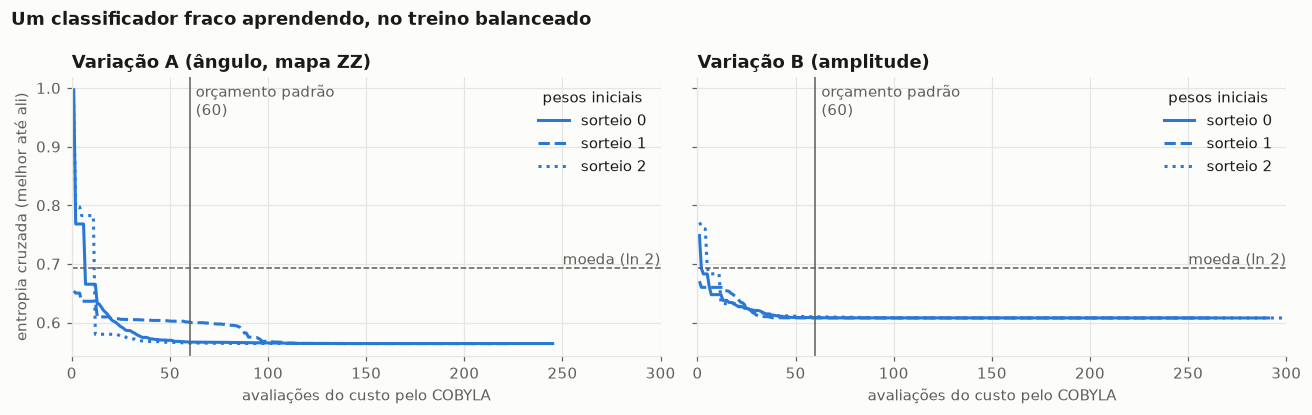

In [48]:
WEAK_LEARNER_CURVE_ITERATIONS: int = 300
WEAK_LEARNER_CURVE_SEEDS: tuple[int, ...] = (0, 1, 2)
COIN_FLIP_LOSS: float = float(np.log(2))
QUANTUM_VARIATION_LABELS: dict[str, str] = {"angle": "A (ângulo, mapa ZZ)", "amplitude": "B (amplitude)"}
SEED_LINE_STYLES: tuple[str, ...] = ("-", "--", ":")

loss_curves: dict[tuple[str, int], np.ndarray] = {}
weak_learner_rows: list[dict[str, float | str | int]] = []
for variation, variation_label in QUANTUM_VARIATION_LABELS.items():
    for seed in WEAK_LEARNER_CURVE_SEEDS:
        weak_pipeline = build_weak_quantum_classifier_pipeline(
            quantum_encoding_steps(variation), max_iterations=WEAK_LEARNER_CURVE_ITERATIONS, random_state=seed
        ).fit(undersampled_features, undersampled_labels)
        # Melhor custo até cada avaliação: o COBYLA também testa pontos piores, que ele descarta
        best_so_far = np.minimum.accumulate(weak_pipeline.named_steps["model"].loss_curve_)
        loss_curves[(variation, seed)] = best_so_far
        weak_learner_rows.append(
            {
                "codificação": variation_label,
                "sorteio dos pesos": seed,
                "custo inicial": best_so_far[0],
                f"custo com {DEFAULT_MAX_ITERATIONS} avaliações": best_so_far[DEFAULT_MAX_ITERATIONS - 1],
                "custo final": best_so_far[-1],
                "avaliações até parar": len(best_so_far),
                "acurácia no próprio treino, corte em 0,5": float(
                    (weak_pipeline.predict(undersampled_features) == undersampled_labels).mean()
                ),
                "acurácia no próprio treino, melhor corte": best_threshold_accuracy(
                    undersampled_labels, weak_pipeline.predict_proba(undersampled_features)[:, 1]
                ),
            }
        )

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, (variation, variation_label) in zip(axes, QUANTUM_VARIATION_LABELS.items()):
    for seed, line_style in zip(WEAK_LEARNER_CURVE_SEEDS, SEED_LINE_STYLES):
        curve = loss_curves[(variation, seed)]
        ax.plot(np.arange(1, len(curve) + 1), curve, color=NEUTRAL_SERIES_COLOR, linestyle=line_style, label=f"sorteio {seed}")
    ax.axhline(COIN_FLIP_LOSS, color="#5f5e58", linewidth=1, linestyle="--")
    ax.text(WEAK_LEARNER_CURVE_ITERATIONS, COIN_FLIP_LOSS, "moeda (ln 2)", ha="right", va="bottom", color="#5f5e58")
    ax.axvline(DEFAULT_MAX_ITERATIONS, color="#5f5e58", linewidth=1)
    ax.annotate(f"orçamento padrão\n({DEFAULT_MAX_ITERATIONS})", xy=(DEFAULT_MAX_ITERATIONS, 1.0), xycoords=("data", "axes fraction"),
                xytext=(4, -4), textcoords="offset points", ha="left", va="top", color="#5f5e58")
    ax.set(title=f"Variação {variation_label}", xlabel="avaliações do custo pelo COBYLA", xlim=(0, WEAK_LEARNER_CURVE_ITERATIONS))
    ax.legend(loc="upper right", title="pesos iniciais")
axes[0].set_ylabel("entropia cruzada (melhor até ali)")
fig.suptitle("Um classificador fraco aprendendo, no treino balanceado", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

weak_learner_table = pd.DataFrame(weak_learner_rows).set_index(["codificação", "sorteio dos pesos"])
display(
    weak_learner_table.style.format("{:.3f}").format("{:.0f}", subset=["avaliações até parar"])
    .apply(highlight_smallest, subset=["custo final"])
    .apply(highlight_best, subset=["acurácia no próprio treino, corte em 0,5", "acurácia no próprio treino, melhor corte"])
    .set_caption(
        f"Um classificador fraco sozinho, no treino balanceado ({len(undersampled_labels)} linhas). "
        f"Custo = entropia cruzada (moeda: {COIN_FLIP_LOSS:.3f}). O COBYLA pode parar antes de {WEAK_LEARNER_CURVE_ITERATIONS} avaliações. "
        "Destaque: menor custo final e maior acurácia de cada coluna."
    )
)


**Leitura da 5.2**

- **O classificador aprende.** Nas duas variações o custo cai para baixo da moeda (0,693): de 0,65 a 1,00 para 0,564
  na variação A, e de 0,67 a 0,77 para 0,608 na B.
- **O resultado não depende do sorteio dos pesos iniciais.** Os três sorteios partem de custos diferentes e chegam ao
  mesmo custo final e à mesma acurácia (0,660 na A; 0,722 a 0,724 na B). É o melhor que este circuito consegue
  nesses dados, e não um ponto de parada de sorte.
- **60 avaliações bastam na maior parte dos casos.** Na B, os três sorteios já estão no custo final (0,608 a 0,610).
  Na A, dois estão (0,567 e 0,565) e um ainda não (0,601). Deixado livre, o COBYLA para sozinho entre 221 e 300
  avaliações, sem ganho que mude a acurácia.
- **É um classificador fraco de verdade, e cada variação é fraca de um jeito.** Na A, ele ordena bem as transações e
  corta mal: 0,660 de acurácia com o corte em 0,5, contra 0,843 com o melhor corte possível. Na B, o problema é a
  ordem: o melhor corte só leva a acurácia de 0,722 a 0,748.

**O que isso muda.** O orçamento de 60 avaliações fica fixo no grid: mais avaliações não tornariam o classificador
mais forte. E o boosting conta o erro de cada rodada com o corte em 0,5, então, na variação A, ele enxerga um
classificador mais fraco do que a ordem das pontuações permitiria. As Seções 5.3 e 5.5 voltam a esse ponto.


### 5.3 Fase × rotação em Y no classificador fraco (CC14)

> **Papel no experimento:** **define opções do grid.** Decide se a rotação em Y entra como opção de codificação no grid do Quantum AdaBoost (Seção 6). Usa só o treino.

**A pergunta.** O estado de um qubit pode ser desenhado como um ponto numa esfera, a **esfera de Bloch**: o polo
norte é o estado 0, o polo sul é o estado 1, e a medição devolve 1 com probabilidade tanto maior quanto mais ao sul
está o ponto. O **equador** é a linha a meio caminho dos polos, onde a medição dá 0 ou 1 com 50% cada, em qualquer
ponto dele; um **meridiano** é uma linha que vai de um polo ao outro.

Os mapas Z e ZZ são, a rigor, codificação de **fase**: a feature vira uma rotação em torno do eixo vertical, e o
estado anda **pelo equador**. A codificação de ângulo propriamente dita é a **rotação em Y** (RY), em que o estado
anda **por um meridiano**. Para o QSVM as duas dão o mesmo kernel (Seção 4.6, com teste). O classificador variacional
não usa kernel: ele **mede** um qubit. Num qubit só, medido logo depois da codificação, a fase não aparece (o
equador dá 50% para qualquer valor da feature), e a rotação em Y aparece inteira (teste
`test_phase_is_invisible_to_a_direct_measurement_until_the_second_repetition`). A Seção 4 deixou em aberto se isso
sobrevive em 5 qubits, com o ansatz e com mais repetições do mapa.

**O experimento.** Quatro codificações, todas com os mesmos 5 componentes:

| Codificação | O que é |
|---|---|
| fase (mapa Z, 1 repetição) | Hadamard + fase P(2x): a fase pura |
| rotação em Y (RY) | RY(2x): o ângulo propriamente dito; mesmo kernel da fase pura |
| mapa Z, 2 repetições | a fase aplicada duas vezes, com uma segunda camada de Hadamard no meio |
| mapa ZZ, 2 repetições | o padrão do pacote: fase com emaranhamento |

Cada uma é avaliada por **validação cruzada de 5 folds dentro do treino balanceado**: o pipeline inteiro (scaler,
redutor, faixa, codificação, classificador) é reajustado em cada fold. O classificador tem orçamento folgado (300
avaliações), para que a diferença venha da codificação e não de um treino interrompido. São duas varreduras:

1. **Na faixa padrão [0, π/2], com StandardScaler** (esta célula): 2 redutores (PCA e informação mútua) × ansatz com
   1 ou 2 repetições × 2 sorteios do undersampling × 3 sorteios dos pesos iniciais.
2. **Nas quatro larguras e nos dois scalers do grid** (5.3.1): a Seção 4 mostrou que a largura da faixa muda tudo
   num kernel, e uma conclusão tirada só em π/2 repetiria o erro do NC14 (delimitar uma dimensão do grid olhando um
   único ponto de outra).

**Duas medidas, de propósito.** Um classificador pode falhar de dois jeitos diferentes, e cada medida enxerga um:
- **ROC-AUC: o classificador ordena bem as transações?** Ela não depende de corte nenhum: é a chance de uma fraude
  sorteada receber P(1) maior que uma legítima sorteada (0,5 = acaso, 1 = ordem perfeita).
- **Acurácia com o corte em P(1) = 0,5: ele põe as transações do lado certo do corte?** Um classificador pode ordenar
  bem e ainda assim cortar no lugar errado, por exemplo se quase todas as fraudes ficam com P(1) entre 0,3 e 0,5:
  a ordem está certa, mas o corte em 0,5 as chama todas de legítimas.

**Por que o corte em 0,5, e não o melhor corte.** Porque é o corte que o classificador fraco **de fato** usa: o
`predict` dele devolve fraude quando P(1) > 0,5, e é esse `predict` que o AdaBoost chama. O erro ponderado ε de cada
rodada é a soma dos pesos das transações que o `predict` errou, ou seja, 1 menos a acurácia ponderada com o corte em
0,5. Uma codificação que ordena bem mas corta mal produz um classificador com ε alto, voto pequeno no boosting e, no
limite, ε ≥ 0,5, que encerra o boosting (5.5). A ordem sozinha não chega ao boosting; o corte chega.

**Por que estas duas, e não a PR-AUC (a métrica principal do TCC).**
- **Os folds aqui são 50/50.** A validação cruzada roda dentro do treino balanceado, então cada fold tem metade de
  fraudes. Nessa proporção a acurácia é uma medida honesta: o acaso vale 0,5, e não 0,9983 como na proporção real.
- **A PR-AUC depende da proporção de fraudes** do conjunto avaliado. Num fold 50/50 ela mede outra coisa que na
  validação real (0,17%), e o número não seria comparável com o resto do TCC. A ROC-AUC não depende da proporção. (O
  grid da Seção 6 é outro caso: lá os folds de avaliação ficam na proporção real, e a escolha é pela PR-AUC.)
- **A pergunta é sobre o classificador fraco, e não sobre o modelo final.** O que interessa aqui é se a codificação
  permite ordenar e cortar; o desempenho na proporção real é medido na 5.4, com PR-AUC.

**Critério de decisão.** O plano põe duas condições para a rotação em Y entrar no grid:
- **a diferença aparece:** a diferença de acurácia para a fase pura é maior que 3 vezes o desvio entre execuções
  **e** maior que o desvio entre folds, em pelo menos uma configuração de redutor e ansatz;
- **o custo permite:** a célula mede o tempo da varredura e conta quantas opções de codificação o grid passa a ter.

O critério pode falhar (se o ansatz compensasse a codificação, as acurácias ficariam iguais), mas **não é um teste
cego**: ele foi escrito depois de um protótipo desta mesma análise já ter mostrado a diferença.

**O protótipo.** Antes de escrever esta célula, a análise foi rodada num script à parte, fora do notebook, para
saber se ela cabia no tempo de execução e se o código funcionava com os dados reais. Usou só o treino:

| | Protótipo | Esta célula |
|---|---|---|
| Treino balanceado | 1 sorteio do undersampling (a semente do experimento) | 2 sorteios |
| Validação | 5 folds estratificados no treino balanceado | Igual |
| Codificações, redutores e ansatz | As mesmas 4 codificações, PCA e informação mútua, ansatz com 1 ou 2 repetições | Igual |
| Sorteios dos pesos iniciais | 5 | 3 |
| Faixa e scaler | [0, π/2], StandardScaler | Igual (as outras larguras e o RobustScaler vieram depois, na 5.3.1) |
| Execução | Sequencial, 678 s | Em paralelo, cerca de 2 min |

Com PCA e ansatz de 1 repetição, o protótipo deu acurácia de 0,653 na fase pura e 0,871 com a rotação em Y (ROC-AUC
de 0,914 e 0,943); com informação mútua e ansatz de 2 repetições, 0,870 e 0,899. A diferença já estava ali, e foi
depois de vê-la que o critério abaixo foi escrito.

**O que isso significa para a leitura.** Um critério escrito depois de ver o resultado pode ter sido escolhido,
mesmo sem querer, de um jeito que o resultado passe. Ele continua útil para dizer **de que tamanho** a diferença
precisa ser, mas não prova que o resultado era desconhecido. A evidência é esta célula, e não o protótipo: ela
refaz o experimento com dois sorteios do undersampling, roda a cada execução do notebook, e chega aos mesmos
números com diferença de poucos milésimos. O script do protótipo não faz parte do projeto.

Os sorteios do undersampling são os dois primeiros de `SUBSAMPLE_SEEDS` (Seção 4.7); não são as sementes de
robustez da Seção 9.


In [49]:
ENCODING_CONFIGURATIONS: dict[str, EncodingConfiguration] = {
    "fase (mapa Z, 1 repetição)": ("z", 1),
    "rotação em Y (RY)": ("ry", 1),
    "mapa Z, 2 repetições": ("z", 2),
    "mapa ZZ, 2 repetições": ("zz", 2),
}
PHASE_ENCODING: str = "fase (mapa Z, 1 repetição)"
RY_ENCODING: str = "rotação em Y (RY)"
DIAGNOSTIC_REDUCERS: dict[str, str] = {"pca": "PCA", "mutual_info": "informação mútua"}
DIAGNOSTIC_ANSATZ_REPS: tuple[int, ...] = (1, 2)
DIAGNOSTIC_DEFAULT_WIDTH: float = config.ANGLE_RANGE_WIDTH_GRID[-1]  # π/2, a faixa padrão
DIAGNOSTIC_UNDERSAMPLING_SEEDS: tuple[int, ...] = SUBSAMPLE_SEEDS[:2]
DIAGNOSTIC_INITIALIZATION_SEEDS: tuple[int, ...] = (0, 1, 2)
DIAGNOSTIC_MAX_ITERATIONS: int = 300
DIAGNOSTIC_FOLDS: int = 5
DECISIVE_RUN_DEVIATIONS: float = 3.0
RUN_COLUMNS: list[str] = ["subsample", "initialization_seed"]
SETTING_COLUMNS: list[str] = ["reducer", "ansatz_reps"]
DIAGNOSTIC_METRICS: dict[str, str] = {"accuracy": "acurácia com o corte em 0,5", "roc_auc": "ROC-AUC"}
DIAGNOSTIC_SETTINGS: list[tuple[str, int]] = [
    (reducer, ansatz_reps) for reducer in DIAGNOSTIC_REDUCERS for ansatz_reps in DIAGNOSTIC_ANSATZ_REPS
]


def balanced_training_draw(seed: int) -> KernelSubsample:
    """O treino balanceado inteiro, sorteado pelo undersampler do pipeline com a semente dada."""
    features, labels = make_undersampler(seed).fit_resample(X_train, y_train)
    return features.to_numpy(), labels.to_numpy()


balanced_draws = {seed: balanced_training_draw(seed) for seed in DIAGNOSTIC_UNDERSAMPLING_SEEDS}
with CostMeter(trace_python_memory=False) as diagnostic_meter:
    encoding_sweep = weak_classifier_encoding_sweep(
        balanced_draws,
        ENCODING_CONFIGURATIONS,
        reducers=tuple(DIAGNOSTIC_REDUCERS),
        scalers=("standard",),
        range_widths=(DIAGNOSTIC_DEFAULT_WIDTH,),
        ansatz_reps_options=DIAGNOSTIC_ANSATZ_REPS,
        initialization_seeds=DIAGNOSTIC_INITIALIZATION_SEEDS,
        max_iterations=DIAGNOSTIC_MAX_ITERATIONS,
        n_splits=DIAGNOSTIC_FOLDS,
        random_state=config.RANDOM_STATE,
        n_jobs=config.N_JOBS,
    )
n_runs = len(DIAGNOSTIC_UNDERSAMPLING_SEEDS) * len(DIAGNOSTIC_INITIALIZATION_SEEDS)
print(f"{len(encoding_sweep)} ajustes ({len(ENCODING_CONFIGURATIONS)} codificações × {len(DIAGNOSTIC_REDUCERS)} redutores × "
      f"{len(DIAGNOSTIC_ANSATZ_REPS)} profundidades do ansatz × {n_runs} execuções × {DIAGNOSTIC_FOLDS} folds), cada um com até "
      f"{DIAGNOSTIC_MAX_ITERATIONS} avaliações, em {diagnostic_meter.report.wall_seconds:.0f} s com {config.N_JOBS} processos")

# Uma execução = um sorteio do undersampling com um sorteio dos pesos; a nota dela é a média dos folds
run_scores = encoding_sweep.groupby([*SETTING_COLUMNS, "configuration", *RUN_COLUMNS], sort=False)[list(DIAGNOSTIC_METRICS)].mean()
setting_groups = run_scores.groupby([*SETTING_COLUMNS, "configuration"], sort=False)
run_mean, run_deviation = setting_groups.mean(), setting_groups.std()
# Desvio entre os folds de uma mesma execução, em média: o ruído de avaliar em ~114 linhas
fold_deviation = (
    encoding_sweep.groupby([*SETTING_COLUMNS, "configuration", *RUN_COLUMNS], sort=False)[list(DIAGNOSTIC_METRICS)].std()
    .groupby([*SETTING_COLUMNS, "configuration"], sort=False).mean()
)


def setting_label(reducer: str, ansatz_reps: int) -> tuple[str, str]:
    """Cabeçalho de coluna em dois níveis: redutor e profundidade do ansatz."""
    return DIAGNOSTIC_REDUCERS[reducer], f"ansatz com {ansatz_reps} " + ("repetição" if ansatz_reps == 1 else "repetições")


def highlight_largest_mean(column: pd.Series) -> list[str]:
    """Destaque na maior média da coluna (o texto de cada célula começa pela média)."""
    means = column.str.split(" ").str[0].str.replace(",", ".").astype(float)
    style = f"background-color: {HIGHLIGHT_COLOR}; color: {HIGHLIGHT_TEXT_COLOR}"
    return [style if value == means.max() else "" for value in means]


def by_setting(table: pd.DataFrame) -> pd.DataFrame:
    """Linhas = codificações, colunas = (redutor, profundidade do ansatz), na ordem do experimento."""
    ordered = table.unstack(SETTING_COLUMNS).loc[list(ENCODING_CONFIGURATIONS), DIAGNOSTIC_SETTINGS]
    ordered.columns = pd.MultiIndex.from_tuples([setting_label(reducer, reps) for reducer, reps in ordered.columns])
    return ordered.rename_axis("codificação")


for metric, metric_label in DIAGNOSTIC_METRICS.items():
    text = (run_mean[metric].map("{:.3f}".format) + " ± " + run_deviation[metric].map("{:.3f}".format)).str.replace(".", ",")
    display(
        by_setting(text).style.apply(highlight_largest_mean).set_caption(
            f"Classificador fraco sozinho, {metric_label}: média ± desvio entre {n_runs} execuções "
            f"(validação cruzada de {DIAGNOSTIC_FOLDS} folds no treino balanceado; faixa [0, π/2], StandardScaler). "
            "Destaque: maior média da coluna."
        )
    )
display(
    by_setting(fold_deviation["accuracy"]).style.format("{:.3f}").apply(highlight_best).set_caption(
        "Desvio da acurácia entre os folds de uma mesma execução (média das execuções). Destaque: a configuração mais "
        "instável de cada coluna, em que a acurácia depende mais de quais linhas ficaram em cada fold."
    )
)

# As duas condições do plano. Primeira: a diferença aparece?
decision_rows: list[dict[str, float | str | bool]] = []
for reducer, ansatz_reps in DIAGNOSTIC_SETTINGS:
    phase, ry = (reducer, ansatz_reps, PHASE_ENCODING), (reducer, ansatz_reps, RY_ENCODING)
    difference = run_mean.loc[ry, "accuracy"] - run_mean.loc[phase, "accuracy"]
    largest_run_deviation = max(run_deviation.loc[ry, "accuracy"], run_deviation.loc[phase, "accuracy"])
    largest_fold_deviation = max(fold_deviation.loc[ry, "accuracy"], fold_deviation.loc[phase, "accuracy"])
    decision_rows.append(
        {
            "redutor": DIAGNOSTIC_REDUCERS[reducer],
            "repetições do ansatz": ansatz_reps,
            "acurácia RY − fase": difference,
            "maior desvio entre execuções": largest_run_deviation,
            "maior desvio entre folds": largest_fold_deviation,
            "diferença decisiva": bool(difference > DECISIVE_RUN_DEVIATIONS * largest_run_deviation and difference > largest_fold_deviation),
        }
    )
encoding_decision = pd.DataFrame(decision_rows).set_index(["redutor", "repetições do ansatz"])
difference_appears = bool(encoding_decision["diferença decisiva"].any())
display(
    encoding_decision.style.format("{:.3f}", subset=encoding_decision.columns[:3]).apply(highlight_true, subset=["diferença decisiva"])
    .set_caption(
        f"Critério: diferença maior que {DECISIVE_RUN_DEVIATIONS:g} desvios entre execuções e maior que o desvio entre folds. "
        "Destaque: configurações em que o critério foi atendido."
    )
)

# Segunda condição: o custo permite? Opções de codificação do grid hoje (mapa × repetições × emaranhamento) e com a RY
ENTANGLEMENT_OPTIONS: tuple[str, ...] = ("linear", "full")
encoding_options_today = len(config.FEATURE_MAP_REPS_GRID) * (1 + len(ENTANGLEMENT_OPTIONS))
seconds_per_fit = diagnostic_meter.report.wall_seconds * config.N_JOBS / len(encoding_sweep)
print(f"Custo: cerca de {seconds_per_fit:.1f} s de processador por ajuste de {DIAGNOSTIC_MAX_ITERATIONS} avaliações. "
      f"Opções de codificação no grid: {encoding_options_today} hoje (Z e ZZ, com 1 ou 2 repetições, e o ZZ com 2 emaranhamentos), "
      f"{encoding_options_today + 1} com a rotação em Y.")
print(f"A diferença aparece: {'sim' if difference_appears else 'não'}. "
      f"A rotação em Y entra no grid do Quantum AdaBoost: {'sim' if difference_appears else 'não'}")


480 ajustes (4 codificações × 2 redutores × 2 profundidades do ansatz × 6 execuções × 5 folds), cada um com até 300 avaliações, em 126 s com 12 processos


Custo: cerca de 3.1 s de processador por ajuste de 300 avaliações. Opções de codificação no grid: 6 hoje (Z e ZZ, com 1 ou 2 repetições, e o ZZ com 2 emaranhamentos), 7 com a rotação em Y.
A diferença aparece: sim. A rotação em Y entra no grid do Quantum AdaBoost: sim


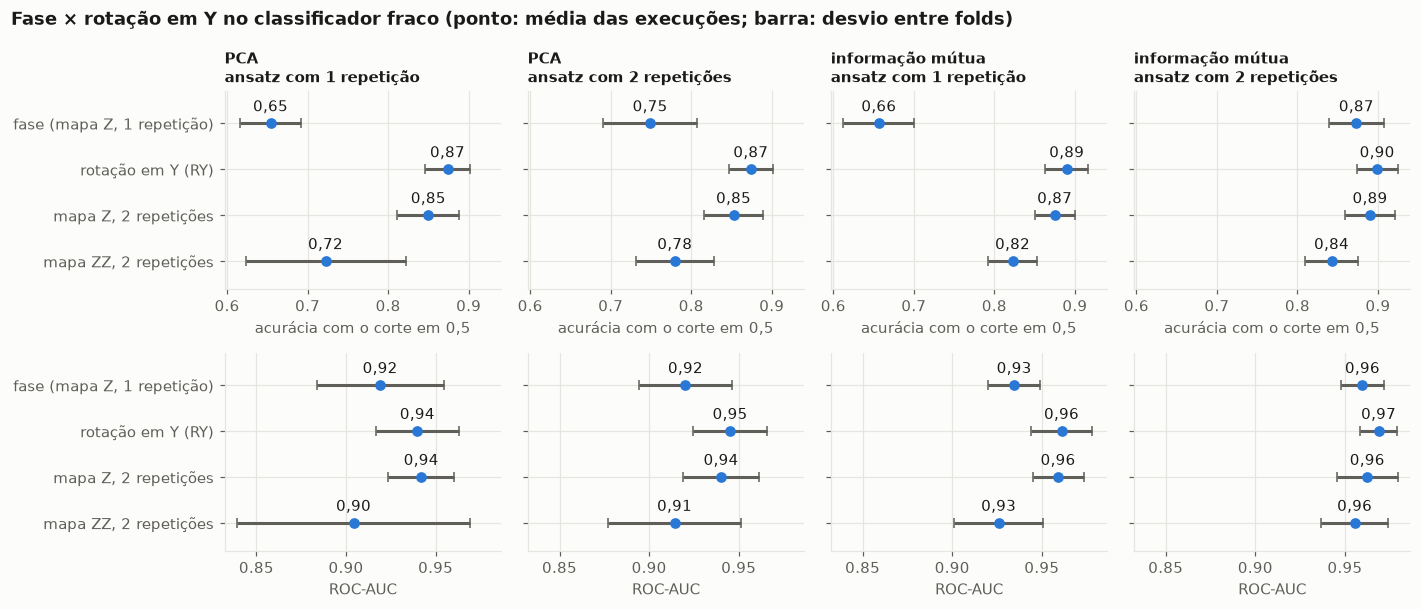

In [50]:
fig, axes = plt.subplots(
    len(DIAGNOSTIC_METRICS), len(DIAGNOSTIC_SETTINGS), figsize=(13, 5.6), sharey=True, sharex="row"
)
encoding_names = list(ENCODING_CONFIGURATIONS)
positions = np.arange(len(encoding_names))[::-1]
for row, (metric, metric_label) in enumerate(DIAGNOSTIC_METRICS.items()):
    for column, (reducer, ansatz_reps) in enumerate(DIAGNOSTIC_SETTINGS):
        ax = axes[row, column]
        means = [run_mean.loc[(reducer, ansatz_reps, name), metric] for name in encoding_names]
        deviations = [fold_deviation.loc[(reducer, ansatz_reps, name), metric] for name in encoding_names]
        ax.errorbar(means, positions, xerr=deviations, fmt="o", color=NEUTRAL_SERIES_COLOR, ecolor="#5f5e58", capsize=3)
        for mean, position in zip(means, positions):
            ax.annotate(f"{mean:.2f}".replace(".", ","), (mean, position), textcoords="offset points", xytext=(0, 8), ha="center")
        ax.set_yticks(positions, encoding_names)
        ax.set_ylim(-0.6, len(encoding_names) - 0.3)
        if row == 0:
            ax.set_title("\n".join(setting_label(reducer, ansatz_reps)), fontsize=10)
        ax.set_xlabel(metric_label)
fig.suptitle("Fase × rotação em Y no classificador fraco (ponto: média das execuções; barra: desvio entre folds)",
             x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()


**Leitura da 5.3**

Todos os números vêm da validação cruzada no treino balanceado, com a faixa padrão [0, π/2] e StandardScaler (média
de 6 execuções).

**1. Na acurácia com o corte em 0,5, a fase pura perde de longe nas configurações mais simples.** Com PCA e ansatz de
1 repetição: 0,654 ± 0,001 na fase pura contra 0,874 ± 0,003 na rotação em Y. Com informação mútua e ansatz de 1
repetição, 0,657 contra 0,890. O critério de decisão foi atendido em 3 das 4 configurações (diferenças de 0,220;
0,125 e 0,233).

**2. Na ROC-AUC, quase não há diferença.** A fase pura fica entre 0,919 e 0,960, e a rotação em Y entre 0,940 e 0,969.
A diferença entre as duas é de 0,01 a 0,03, contra 0,03 a 0,23 na acurácia. Ou seja: a fase pura **ordena** as
transações quase tão bem quanto a rotação em Y; o que ela não consegue é **cortar** no lugar certo. A 5.3.2 mostra
isso num ajuste só.

**3. Mais circuito reduz a desvantagem da fase.** Com 2 repetições do ansatz a acurácia da fase pura sobe (0,749 com
PCA; 0,873 com informação mútua), e com informação mútua e ansatz de 2 repetições a diferença para a rotação em Y
cai para 0,026, pequena e no limite do critério. O mapa Z com 2 repetições, que acrescenta uma segunda camada de
Hadamard, também recupera quase tudo (0,850 a 0,890).

**4. A rotação em Y tem a maior acurácia nas quatro configurações** (0,874 a 0,899), com desvio entre folds de 0,025 a 0,028,
o menor da coluna em 3 das 4. O mapa ZZ com 2 repetições, o padrão do pacote, fica abaixo dela em todas (0,722 a 0,842) e é o
mais instável com PCA e ansatz de 1 repetição (desvio de 0,099 entre folds).

**5. As duas condições do plano foram atendidas.** A diferença aparece (itens 1 e 2), e o custo permite: os 480
ajustes de 300 avaliações levaram cerca de 2 min em paralelo, e o grid passa de 6 para 7 opções de codificação.
**Decisão: a rotação em Y entra no grid do Quantum AdaBoost.** No QSVM ela não entra, porque o kernel dela é
idêntico ao do mapa Z com 1 repetição.

**O que esta tabela ainda não diz.** Tudo aqui é na faixa [0, π/2] com StandardScaler. A 5.3.1 mostra que, em
outras larguras, a ordem entre as codificações muda; e a 5.5.1 mostra que, dentro do boosting, a rotação em Y não
evita a parada antecipada. Se ela melhora o **modelo** é o que a validação cruzada da Seção 6 vai dizer.


#### 5.3.1 A diferença depende da largura da faixa e do scaler?

> **Papel no experimento:** **define opções do grid.** Confere se a conclusão da 5.3 vale nas outras larguras e no outro scaler do grid, e mostra que largura e codificação precisam ser buscadas juntas no Quantum AdaBoost. Usa só o treino.

A mesma validação cruzada, agora com PCA e ansatz de 1 repetição (a configuração padrão), variando as quatro
larguras de `config.ANGLE_RANGE_WIDTH_GRID` e os dois scalers. Para caber no tempo, usa um sorteio do undersampling
(a semente do experimento) e dois sorteios de pesos.


320 ajustes em 79 s


largura da faixa (rad),"0,25","0,5",1,π/2
codificação,,,,
"fase (mapa Z, 1 repetição)",0.496,0.499,0.878,0.653
rotação em Y (RY),0.854,0.861,0.863,0.875
"mapa Z, 2 repetições",0.891,0.887,0.863,0.848
"mapa ZZ, 2 repetições",0.863,0.876,0.758,0.718


largura da faixa (rad),"0,25","0,5",1,π/2
codificação,,,,
"fase (mapa Z, 1 repetição)",0.555,0.550,0.526,0.687
rotação em Y (RY),0.829,0.817,0.819,0.817
"mapa Z, 2 repetições",0.715,0.772,0.824,0.812
"mapa ZZ, 2 repetições",0.769,0.727,0.794,0.760


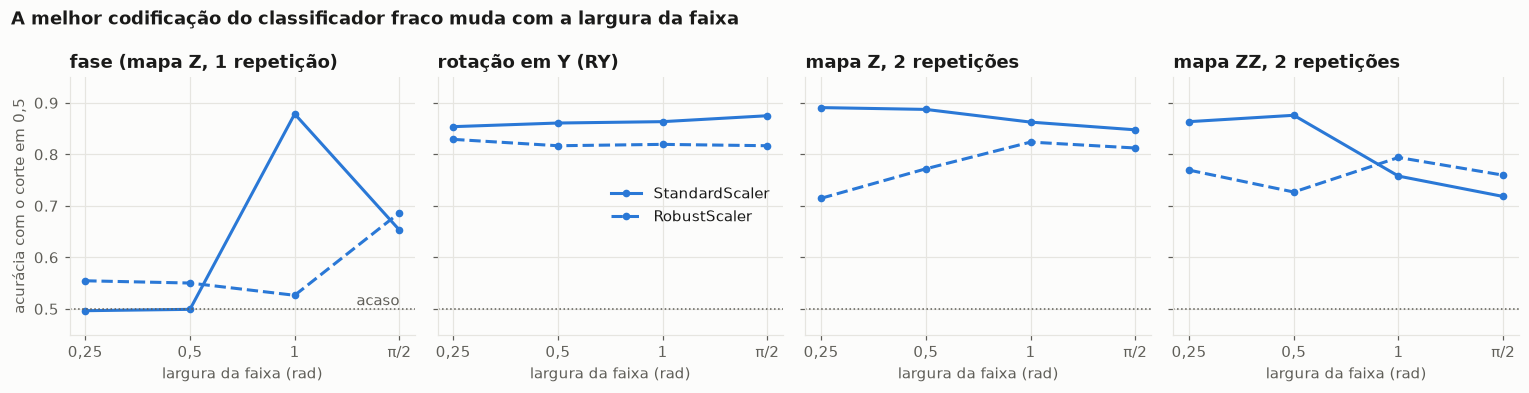

In [51]:
WIDTH_SWEEP_SCALERS: dict[ScalerName, str] = {"standard": "StandardScaler", "robust": "RobustScaler"}
WIDTH_SWEEP_SEEDS: tuple[int, ...] = DIAGNOSTIC_INITIALIZATION_SEEDS[:2]
GRID_WIDTH_LABELS: dict[float, str] = dict(zip(config.ANGLE_RANGE_WIDTH_GRID, ("0,25", "0,5", "1", "π/2")))

with CostMeter(trace_python_memory=False) as width_meter:
    width_sweep = weak_classifier_encoding_sweep(
        {config.RANDOM_STATE: balanced_draws[config.RANDOM_STATE]},
        ENCODING_CONFIGURATIONS,
        reducers=("pca",),
        scalers=tuple(WIDTH_SWEEP_SCALERS),
        range_widths=config.ANGLE_RANGE_WIDTH_GRID,
        ansatz_reps_options=(1,),
        initialization_seeds=WIDTH_SWEEP_SEEDS,
        max_iterations=DIAGNOSTIC_MAX_ITERATIONS,
        n_splits=DIAGNOSTIC_FOLDS,
        random_state=config.RANDOM_STATE,
        n_jobs=config.N_JOBS,
    )
print(f"{len(width_sweep)} ajustes em {width_meter.report.wall_seconds:.0f} s")

width_accuracy = (
    width_sweep.groupby(["scaler", "configuration", "range_width"], sort=False)["accuracy"].mean()
    .unstack("range_width")[list(config.ANGLE_RANGE_WIDTH_GRID)]
    .rename(columns=GRID_WIDTH_LABELS)
)
for scaler, scaler_label in WIDTH_SWEEP_SCALERS.items():
    display(
        width_accuracy.loc[scaler].loc[list(ENCODING_CONFIGURATIONS)].rename_axis("codificação").rename_axis("largura da faixa (rad)", axis="columns")
        .style.format("{:.3f}").apply(highlight_best).set_caption(
            f"{scaler_label}: acurácia com o corte em 0,5 do classificador fraco sozinho (PCA, ansatz com 1 repetição; "
            f"média de {len(WIDTH_SWEEP_SEEDS)} sorteios de pesos, validação cruzada de {DIAGNOSTIC_FOLDS} folds). "
            "Destaque: melhor codificação em cada largura."
        )
    )

SCALER_LINE_STYLES: dict[str, str] = {"standard": "-", "robust": "--"}
width_positions = np.arange(len(config.ANGLE_RANGE_WIDTH_GRID))
fig, axes = plt.subplots(1, len(ENCODING_CONFIGURATIONS), figsize=(14, 3.6), sharey=True)
for ax, encoding_name in zip(axes, ENCODING_CONFIGURATIONS):
    for scaler, scaler_label in WIDTH_SWEEP_SCALERS.items():
        ax.plot(width_positions, width_accuracy.loc[(scaler, encoding_name)], marker="o", markersize=4,
                color=NEUTRAL_SERIES_COLOR, linestyle=SCALER_LINE_STYLES[scaler], label=scaler_label)
    ax.axhline(0.5, color="#5f5e58", linewidth=1, linestyle=":")
    ax.set_xticks(width_positions, list(GRID_WIDTH_LABELS.values()))
    ax.set(title=encoding_name, xlabel="largura da faixa (rad)", ylim=(0.45, 0.95))
    ax.title.set_fontsize(10)
axes[0].set_ylabel("acurácia com o corte em 0,5")
axes[0].text(width_positions[-1], 0.5, "acaso", ha="right", va="bottom", color="#5f5e58")
axes[1].legend(loc="center right")
fig.suptitle("A melhor codificação do classificador fraco muda com a largura da faixa", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()


**Leitura da 5.3.1**

Os números são médias de 2 sorteios de pesos, num único sorteio do undersampling, com PCA e ansatz de 1
repetição. A tabela não traz o desvio; na 5.3, o desvio da acurácia entre folds ficou entre 0,025 e 0,099, então
diferenças de 0,01 a 0,03 entre codificações devem ser lidas como empate.

**1. A conclusão da 5.3 só vale na faixa padrão.** Com StandardScaler, a melhor codificação muda com a largura:

| Largura | 0,25 | 0,5 | 1 | π/2 |
|---|---|---|---|---|
| Melhor codificação | mapa Z, 2 repetições (0,891) | mapa Z, 2 repetições (0,887) | fase pura (0,878) | rotação em Y (0,875) |

Em 1 rad a fase pura, que na 5.3 era a pior, fica empatada com a rotação em Y e com o mapa Z de 2 repetições (0,878,
0,863 e 0,863).

**2. A fase pura é a mais sensível à largura.** Com StandardScaler ela fica no acaso em 0,25 e 0,5 rad (0,496 e 0,499),
sobe para 0,878 em 1 rad e cai para 0,653 em π/2. Isso é compatível com o mecanismo visto num qubit (CC14): com a fase
pura, o ponto em que a previsão troca de classe fica preso perto de x = 0,79 rad, qualquer que seja o peso do ansatz.
Numa faixa que termina antes disso (0,25 ou 0,5 rad), todas as transações caem do mesmo lado do ponto, e o
classificador não consegue separar nada; em 1 rad o ponto fica dentro da faixa. A explicação não dá conta de tudo:
em π/2 o ponto também fica dentro da faixa, e mesmo assim a acurácia cai para 0,653. É uma hipótese compatível com
parte dos números, e não uma prova: o circuito aqui tem 5 qubits e um ansatz com CNOTs.

**3. A rotação em Y é a mais estável.** Ela fica entre 0,817 e 0,875 nas 8 combinações de largura e scaler. As outras
três variam muito mais: a fase pura de 0,496 a 0,878, o mapa Z com 2 repetições de 0,715 a 0,891 e o mapa ZZ com 2
repetições de 0,718 a 0,876. Ela nem sempre é a melhor, mas nunca fica longe da melhor.

**4. O mapa ZZ, o padrão do pacote, depende da largura.** Ele empata com as melhores em 0,25 e 0,5 rad (0,863 e
0,876) e cai em 1 rad e π/2 (0,758 e 0,718). A faixa padrão [0, π/2] é justamente a pior largura para ele, o que é
coerente com o mau desempenho do Quantum AdaBoost A na 5.4 (que usa essa configuração).

**5. Com RobustScaler, quase tudo fica mais baixo.** A melhor acurácia com Robust é 0,829 (rotação em Y em 0,25 rad),
contra 0,891 com Standard. A rotação em Y e o mapa Z com 2 repetições ficam abaixo do StandardScaler nas quatro
larguras; a fase pura e o ZZ alternam. Com Robust, a rotação em Y é a melhor em três larguras e fica a 0,005 da
melhor na quarta (1 rad: 0,819 contra 0,824 do mapa Z com 2 repetições).

**6. A melhor largura do kernel não se transfere para o classificador fraco.** Na 4.7, o KTA do kernel apontava 0,5
rad para o ZZ com PCA e 1 rad para o Z com PCA (os dois com 2 repetições e StandardScaler). Aqui, o ZZ também vai
melhor em 0,5 rad (0,876), mas o Z com 2 repetições vai melhor em 0,25 rad (0,891), e não em 1 rad (0,863). A
análise de kernel da Seção 4 foi feita pensando no QSVM; para o Quantum AdaBoost ela não basta.

**O que isso muda.**
- **No grid do Quantum AdaBoost, largura da faixa e codificação são buscadas juntas.** Escolher a largura pelo
  kernel do QSVM e herdar para o Quantum AdaBoost, uma das saídas do ponto ① do PLAN, não serve.
- **A rotação em Y entra no grid** (como a 5.3 decidiu), agora com um motivo a mais: é a codificação cujo resultado
  menos depende das outras escolhas.
- **A decisão da 5.3 não muda**, mas o alcance dela fica menor: "a fase é pior" descreve só a faixa padrão.


#### 5.3.2 O que a codificação de fase não deixa o classificador fazer

> **Papel no experimento:** **só ilustra ou verifica.** Mostra, num único ajuste, o mecanismo por trás da tabela acima.

A célula ajusta dois classificadores fracos no treino balanceado, um com a fase pura e outro com a rotação em Y
(PCA, ansatz com 1 repetição, o mesmo sorteio de pesos), e mostra a P(1) que cada um dá às transações de cada
classe. As previsões são feitas nas mesmas linhas do ajuste: o gráfico mostra o que o circuito **consegue
representar**, e não desempenho. A saída compara a acurácia com o corte em 0,5 com a do melhor corte possível
nessas linhas.


fase (mapa Z, 1 repetição): P(1) entre 0.177 e 0.897 | acima do corte: 31.0% das fraudes e 0.4% das legítimas | acurácia no próprio treino: 0.653 com o corte em 0,5 e 0.894 com o melhor corte


rotação em Y (RY): P(1) entre 0.138 e 0.956 | acima do corte: 75.4% das fraudes e 0.4% das legítimas | acurácia no próprio treino: 0.875 com o corte em 0,5 e 0.930 com o melhor corte


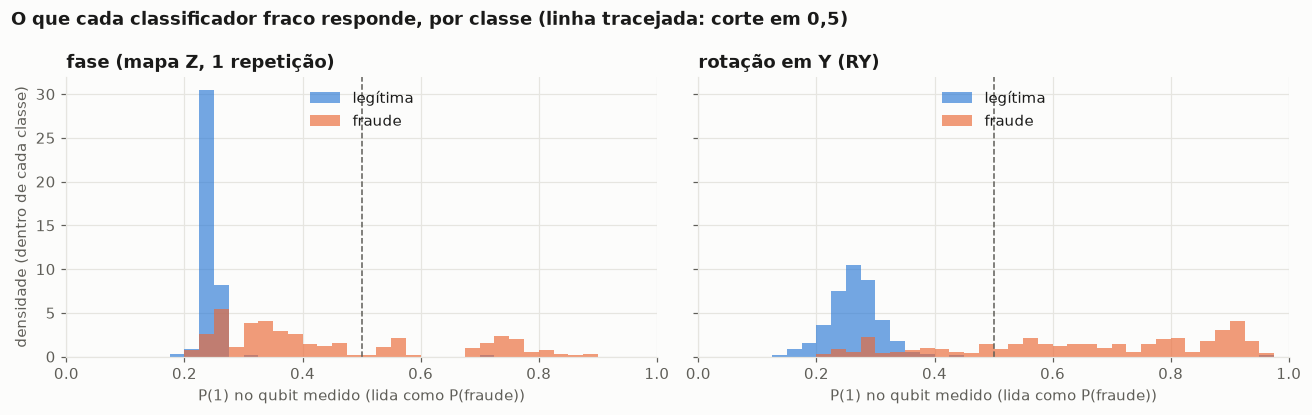

In [52]:
MECHANISM_ENCODINGS: tuple[str, ...] = (PHASE_ENCODING, RY_ENCODING)
MECHANISM_BINS: np.ndarray = np.linspace(0.0, 1.0, 41)

fig, axes = plt.subplots(1, len(MECHANISM_ENCODINGS), figsize=(12, 3.8), sharey=True)
for ax, encoding_name in zip(axes, MECHANISM_ENCODINGS):
    feature_map, feature_map_reps = ENCODING_CONFIGURATIONS[encoding_name]
    mechanism_pipeline = build_weak_quantum_classifier_pipeline(
        quantum_encoding_steps("angle", feature_map=feature_map, feature_map_reps=feature_map_reps),
        max_iterations=DIAGNOSTIC_MAX_ITERATIONS,
        random_state=DIAGNOSTIC_INITIALIZATION_SEEDS[0],
    ).fit(undersampled_features, undersampled_labels)
    fraud_probability = mechanism_pipeline.predict_proba(undersampled_features)[:, 1]
    for label in (LEGITIMATE_LABEL, FRAUD_LABEL):
        ax.hist(fraud_probability[undersampled_labels == label], bins=MECHANISM_BINS, density=True, alpha=0.65,
                color=CLASS_COLORS[label], label=CLASS_NAMES[label])
    ax.axvline(0.5, color="#5f5e58", linewidth=1, linestyle="--")
    in_sample_accuracy = float((mechanism_pipeline.predict(undersampled_features) == undersampled_labels).mean())
    fraud_side = float((fraud_probability[undersampled_labels == FRAUD_LABEL] > 0.5).mean())
    legitimate_side = float((fraud_probability[undersampled_labels == LEGITIMATE_LABEL] > 0.5).mean())
    ax.set(title=encoding_name, xlabel="P(1) no qubit medido (lida como P(fraude))", xlim=(0, 1))
    ax.legend(loc="upper center")
    best_cut_accuracy = best_threshold_accuracy(undersampled_labels, fraud_probability)
    print(f"{encoding_name}: P(1) entre {fraud_probability.min():.3f} e {fraud_probability.max():.3f} | "
          f"acima do corte: {fraud_side:.1%} das fraudes e {legitimate_side:.1%} das legítimas | "
          f"acurácia no próprio treino: {in_sample_accuracy:.3f} com o corte em 0,5 e {best_cut_accuracy:.3f} com o melhor corte")
axes[0].set_ylabel("densidade (dentro de cada classe)")
fig.suptitle("O que cada classificador fraco responde, por classe (linha tracejada: corte em 0,5)", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()


**Leitura da 5.3.2**

Um ajuste de cada codificação no treino balanceado (PCA, ansatz de 1 repetição), avaliado nas mesmas linhas.

- **As legítimas ficam no mesmo lugar nas duas codificações:** um pico estreito de P(1) baixa, e só 0,4% delas
  passam do corte em 0,5.
- **A diferença está nas fraudes.** Com a fase pura, elas se espalham entre 0,2 e 0,9, mas a maior parte fica entre
  o pico das legítimas e o corte: só 31,0% passam de 0,5. Com a rotação em Y, 75,4% passam.
- **A fase pura separa, mas corta no lugar errado.** As fraudes dela ficam acima das legítimas mesmo quando ficam
  abaixo de 0,5, então um corte mais baixo resolveria boa parte: a acurácia iria de 0,653 com o corte em 0,5 para
  0,894 com o melhor corte. Na rotação em Y o corte em 0,5 já está perto do melhor (0,875 contra 0,930).

É a versão, num único ajuste, do que a tabela da 5.3 mostrou em média: ROC-AUC parecida (a ordem) e acurácia muito
diferente (o corte). O boosting só enxerga o corte em 0,5, então para ele a fase pura é um classificador bem mais
fraco do que a ordem das pontuações sugere.


### 5.4 Treino e avaliação na validação

> **Papel no experimento:** **só ilustra ou verifica.** É a linha de base com hiperparâmetros padrão. Nenhum hiperparâmetro, limiar ou modelo é escolhido a partir destes números.

Cada pipeline é ajustado no **treino inteiro** (170.235 linhas; o undersampling do próprio pipeline sorteia as 568
que o modelo vê) e avalia as **56.745 linhas da validação**, na proporção real de fraudes. É a primeira vez que a
validação é usada.

**O que é medido:**
- **Desempenho.** PR-AUC e ROC-AUC usam só a ordem das pontuações. Precisão, recall, F1, MCC e acurácia usam as
  classes previstas com o **limiar padrão** de cada modelo, que é o limiar de um modelo treinado com 50% de fraudes
  (Seção 4.10): na validação, com 0,17%, ele gera alertas demais. O limiar certo é escolhido na Seção 7; aqui os
  números com limiar servem para ver o tamanho do problema.
- **Custo.** Tempo de ajuste e de pontuação da validação, com `CostMeter(trace_python_memory=False)`. A memória vem
  de uma **segunda execução**, com o `tracemalloc` ligado (ele deixa o código mais lento, então não pode estar
  ligado na medição de tempo). A segunda execução também serve de checagem de reprodutibilidade: as pontuações
  precisam ser idênticas às da primeira.
- **Incerteza da validação.** A validação tem só 94 fraudes, então a PR-AUC muda bastante com poucas transações.
  O **intervalo de confiança por bootstrap** (IC 95%) dá a ordem de grandeza disso: sorteiam-se, com reposição,
  2.000 novas "validações" do mesmo tamanho a partir da própria validação (dentro de cada classe, para a proporção
  de fraudes não variar), recalcula-se a PR-AUC em cada uma, e o intervalo vai do percentil 2,5 ao 97,5.
- **Comparação pareada.** Os nove modelos são avaliados **nas mesmas reamostras**. Para comparar dois modelos,
  o certo é olhar a **diferença** de PR-AUC entre eles em cada reamostra e ver se o intervalo dela exclui o zero.
  Comparar os intervalos de cada modelo, um ao lado do outro, é um critério mais fraco: dois intervalos podem se
  sobrepor e a diferença ser consistente.
- **O que o bootstrap não mede.** Ele só reamostra a validação. Não inclui a incerteza do **treino**: outro
  sorteio do undersampling daria outro modelo. A 5.4.1 mede a ordem de grandeza disso, sem tocar na validação.


In [53]:
METRIC_LABELS: dict[str, str] = {
    "pr_auc": "PR-AUC", "roc_auc": "ROC-AUC", "precision": "precisão", "recall": "recall", "f1": "F1", "mcc": "MCC",
    "accuracy": "acurácia",
}
BASELINE_NAME: str = "DummyClassifier"
BOOTSTRAP_RESAMPLES: int = 2_000
PR_AUC_INTERVAL_COLUMNS: list[str] = ["PR-AUC: IC 95%, de", "PR-AUC: IC 95%, até"]

fitted_pipelines = default_pipelines()
validation_runs: dict[str, ScoredFit] = {
    name: fit_and_score(pipeline, X_train, y_train, X_validation) for name, pipeline in fitted_pipelines.items()
}

validation_frauds = int(y_validation.sum())
validation_metrics = pd.DataFrame(
    {name: asdict(compute_classification_metrics(y_validation, run.scores, run.predictions)) for name, run in validation_runs.items()}
).T.rename(columns=METRIC_LABELS)

# Todos os modelos nas mesmas reamostras da validação: serve aos intervalos de cada um e às diferenças entre pares
pr_auc_resamples = bootstrap_pr_auc(
    y_validation, {name: run.scores for name, run in validation_runs.items()}, BOOTSTRAP_RESAMPLES, config.RANDOM_STATE
)
pr_auc_intervals = pd.DataFrame(
    {name: percentile_interval(pr_auc_resamples[name]) for name in validation_runs}, index=PR_AUC_INTERVAL_COLUMNS
).T
for position, column in enumerate(PR_AUC_INTERVAL_COLUMNS, start=1):
    validation_metrics.insert(position, column, pr_auc_intervals[column])
validation_metrics["alertas"] = [int((run.predictions == FRAUD_LABEL).sum()) for run in validation_runs.values()]
validation_metrics[f"fraudes detectadas (de {validation_frauds})"] = [
    int(((run.predictions == FRAUD_LABEL) & (y_validation.to_numpy() == FRAUD_LABEL)).sum()) for run in validation_runs.values()
]

count_columns = list(validation_metrics.columns[-2:])
display(
    validation_metrics.style.format("{:.4f}").format("{:,.0f}", subset=count_columns)
    .apply(highlight_best, subset=list(METRIC_LABELS.values()))
    .set_caption(
        f"Validação ({len(y_validation):,} linhas, {validation_frauds} fraudes; proporção {y_validation.mean():.4%}). "
        "Hiperparâmetros padrão e limiar padrão de cada modelo. Destaque: maior valor da coluna. "
        f"IC 95%: bootstrap estratificado, {BOOTSTRAP_RESAMPLES:,} reamostras da validação (não inclui a incerteza do treino)."
    )
)

# O DummyClassifier dá a mesma pontuação a todas as linhas; a classe prevista sai de um desempate
baseline_probabilities = fitted_pipelines[BASELINE_NAME].predict_proba(X_validation.iloc[:1])[0]
print(f"{BASELINE_NAME}: probabilidades previstas {baseline_probabilities} para qualquer linha; no empate, o scikit-learn "
      "devolve a primeira classe (legítima). A acurácia dele é a proporção de legítimas.")

PAIRED_COMPARISONS: list[tuple[str, str]] = [
    ("SVM, 31 features", "QSVM A (ângulo)"),
    ("SVM, 5 componentes", "QSVM A (ângulo)"),
    ("SVM, 31 features", "QSVM B (amplitude)"),
    ("AdaBoost, 31 features", "Quantum AdaBoost A (ângulo)"),
    ("AdaBoost, 5 componentes", "Quantum AdaBoost A (ângulo)"),
    ("AdaBoost, 31 features", "Quantum AdaBoost B (amplitude)"),
    ("SVM, 5 componentes", "SVM, 31 features"),
    ("AdaBoost, 5 componentes", "AdaBoost, 31 features"),
    ("QSVM A (ângulo)", "QSVM B (amplitude)"),
]
paired_rows: list[dict[str, float | str | bool]] = []
for first, second in PAIRED_COMPARISONS:
    lower, upper = percentile_interval(pr_auc_resamples[first] - pr_auc_resamples[second])
    paired_rows.append(
        {
            "comparação": f"{first} − {second}",
            "diferença de PR-AUC": validation_metrics.loc[first, "PR-AUC"] - validation_metrics.loc[second, "PR-AUC"],
            "IC 95%, de": lower,
            "IC 95%, até": upper,
            "o intervalo exclui o zero": bool(lower > 0 or upper < 0),
        }
    )
paired_differences = pd.DataFrame(paired_rows).set_index("comparação")
display(
    paired_differences.style.format("{:+.3f}", subset=paired_differences.columns[:3])
    .apply(highlight_true, subset=["o intervalo exclui o zero"])
    .set_caption(
        f"Diferença de PR-AUC entre pares de modelos nas mesmas {BOOTSTRAP_RESAMPLES:,} reamostras da validação "
        "(bootstrap pareado). Mede só a incerteza da validação, com um único sorteio do undersampling."
    )
)


,PR-AUC,"PR-AUC: IC 95%, de","PR-AUC: IC 95%, até",ROC-AUC,precisão,recall,F1,MCC,acurácia,alertas,fraudes detectadas (de 94)
DummyClassifier,0.0017,0.0017,0.0017,0.5000,0.0000,0.0000,0.0000,0.0000,0.9983,0,0
"SVM, 31 features",0.6906,0.6020,0.7811,0.9780,0.0780,0.8936,0.1435,0.2611,0.9823,"1,077",84
"SVM, 5 componentes",0.7450,0.6579,0.8276,0.9535,0.1701,0.8830,0.2852,0.3857,0.9927,488,83
"AdaBoost, 31 features",0.4455,0.3582,0.5460,0.9738,0.0284,0.9255,0.0552,0.1572,0.9475,"3,060",87
"AdaBoost, 5 componentes",0.6691,0.5815,0.7623,0.9579,0.0508,0.8936,0.0961,0.2093,0.9721,"1,655",84
QSVM A (ângulo),0.5095,0.4116,0.6226,0.9577,0.0484,0.8936,0.0918,0.2041,0.9707,"1,736",84
QSVM B (amplitude),0.4523,0.3673,0.5674,0.9717,0.0447,0.9043,0.0852,0.1971,0.9678,"1,902",85
Quantum AdaBoost A (ângulo),0.1538,0.0956,0.2387,0.8814,0.0164,0.7766,0.0321,0.1057,0.9223,"4,460",73
Quantum AdaBoost B (amplitude),0.0212,0.0136,0.0395,0.8686,0.0072,0.7766,0.0142,0.0633,0.8212,"10,196",73


DummyClassifier: probabilidades previstas [0.5 0.5] para qualquer linha; no empate, o scikit-learn devolve a primeira classe (legítima). A acurácia dele é a proporção de legítimas.


,diferença de PR-AUC,"IC 95%, de","IC 95%, até",o intervalo exclui o zero
comparação,,,,
"SVM, 31 features − QSVM A (ângulo)",+0.181,+0.078,+0.269,True
"SVM, 5 componentes − QSVM A (ângulo)",+0.235,+0.148,+0.311,True
"SVM, 31 features − QSVM B (amplitude)",+0.238,+0.172,+0.287,True
"AdaBoost, 31 features − Quantum AdaBoost A (ângulo)",+0.292,+0.167,+0.405,True
"AdaBoost, 5 componentes − Quantum AdaBoost A (ângulo)",+0.515,+0.410,+0.613,True
"AdaBoost, 31 features − Quantum AdaBoost B (amplitude)",+0.424,+0.331,+0.525,True
"SVM, 5 componentes − SVM, 31 features",+0.054,+0.003,+0.108,True
"AdaBoost, 5 componentes − AdaBoost, 31 features",+0.224,+0.105,+0.334,True
QSVM A (ângulo) − QSVM B (amplitude),+0.057,-0.055,+0.166,False


**Leitura da 5.4: as tabelas de métricas e de diferenças**

Validação (56.745 linhas, 94 fraudes), hiperparâmetros padrão, um único sorteio do undersampling.

**1. O `DummyClassifier` é a régua do acaso.** Como dá a mesma pontuação a todas as transações, ele não ordena nada:
PR-AUC de 0,0017 (exatamente a proporção de fraudes) e ROC-AUC de 0,500. A acurácia dele, 0,9983, é a maior da
tabela, sem detectar nenhuma fraude: no empate 50/50, ele chama tudo de legítima. É o exemplo de por que a acurácia
não serve para avaliar este problema.

**2. Todos os modelos estão acima do acaso, mas a ROC-AUC esconde as diferenças.** A ROC-AUC vai de 0,869 a 0,978; a
PR-AUC, de 0,021 a 0,745. Na PR-AUC a ordem é: SVM com 5 componentes (0,745), SVM com 31 features (0,691), AdaBoost
com 5 componentes (0,669), QSVM A (0,510), QSVM B (0,452), AdaBoost com 31 features (0,446), Quantum AdaBoost A
(0,154) e Quantum AdaBoost B (0,021).

**3. Com o limiar padrão, todos disparam alertas demais.** O recall é alto (0,777 a 0,926), mas a precisão fica entre
0,007 e 0,170: o SVM com 31 features, por exemplo, pega 84 das 94 fraudes com 1.077 alertas. F1 e MCC ficam baixos
(no máximo 0,285 e 0,386). É o efeito esperado do limiar de um modelo treinado com 50% de fraudes (4.10); o limiar
é escolhido na Seção 7, e as métricas com limiar só serão comparáveis depois disso.

**4. As diferenças pareadas.**
- **Clássico × quântico:** nas seis comparações, o clássico fica à frente e o intervalo da diferença exclui o zero
  (de +0,181 a +0,515).
- **QSVM A × QSVM B:** +0,057, com intervalo de −0,055 a +0,166, que inclui o zero. Não há diferença entre as duas
  codificações.
- **5 componentes × 31 features nos clássicos:** +0,054 no SVM, com o limite inferior em +0,003, quase no zero; +0,224
  no AdaBoost.

**5. Ressalvas que mudam a leitura.**
- O intervalo só mede a incerteza da **validação**. Com outro sorteio do undersampling, os modelos seriam outros: a
  5.4.1 mostra que, nos dois AdaBoost, a PR-AUC muda em até cerca de 0,3 de uma semente para outra, mais do que a
  largura dos intervalos desta tabela.
- Os padrões quânticos partem de opções que a Seção 4 já sabia serem fracas (5.1). Esta tabela é o ponto de partida,
  e não a comparação do TCC, que vem na Seção 7, depois do grid.

**Por que estes pares, e não outros (como SVM com 5 componentes × QSVM B).** A regra é comparar modelos que recebem
**a mesma entrada**, para que a diferença venha do modelo e não do que ele viu:

| Par | Entrada comum |
|---|---|
| SVM / AdaBoost com 5 componentes × variação A | Os mesmos 5 valores que, no quântico, viram ângulos (há teste que garante) |
| SVM / AdaBoost com 31 features × variação B | As 31 features; a mais próxima da entrada da amplitude, que usa todas elas |
| SVM / AdaBoost com 31 features × variação A | Referência: o clássico com toda a informação contra o quântico com 5 valores |
| 5 componentes × 31 features, dentro de cada clássico | O mesmo modelo; mede só o efeito da entrada |
| QSVM A × QSVM B | O mesmo modelo; mede só o efeito da codificação |

Comparações como SVM com 5 componentes × QSVM B ou AdaBoost com 5 componentes × Quantum AdaBoost B não entram
porque misturam duas diferenças ao mesmo tempo: o modelo (clássico ou quântico) e a entrada (5 valores contra as 31
features). Se uma delas saísse diferente, não daria para dizer qual das duas pesou. O efeito da entrada já é medido
à parte, na comparação 5 componentes × 31 features. Uma ressalva: nem a variação B tem entrada idêntica à do
clássico com 31 features, porque a constante e a normalização mudam os valores; é o par mais próximo, não um par
perfeito.


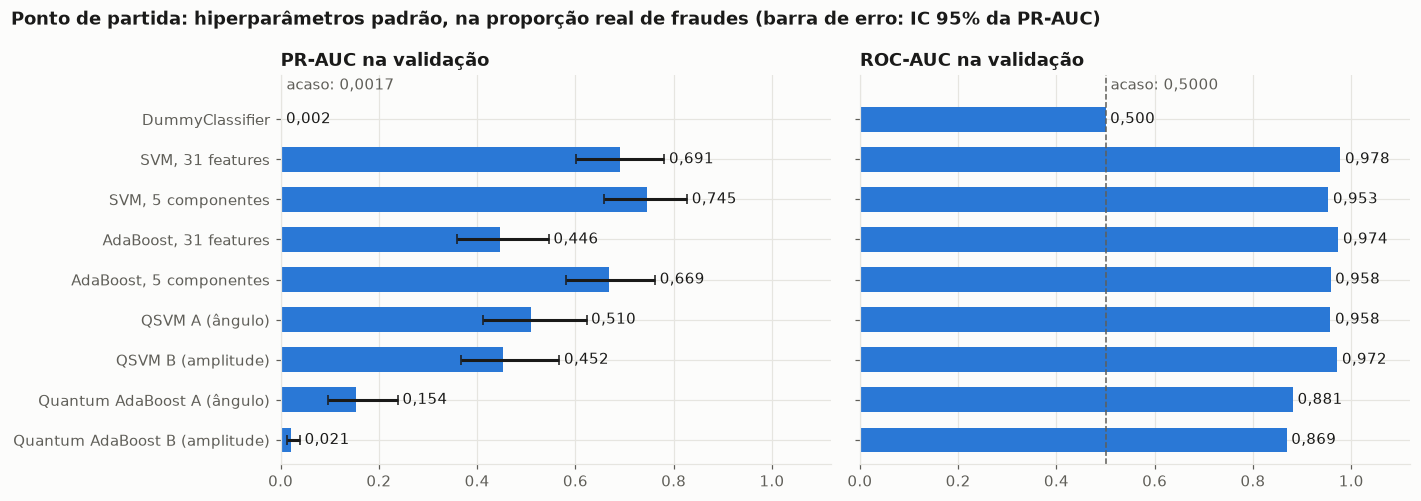

In [54]:
ranking_metrics: list[str] = ["PR-AUC", "ROC-AUC"]
chance_levels: dict[str, float] = {"PR-AUC": float(y_validation.mean()), "ROC-AUC": 0.5}
model_names = list(validation_metrics.index)
bar_positions = np.arange(len(model_names))[::-1]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
for ax, metric in zip(axes, ranking_metrics):
    # Barra de erro só na PR-AUC, a métrica principal: o intervalo de bootstrap calculado acima
    interval_errors = None
    if metric == "PR-AUC":
        interval_errors = np.abs(validation_metrics[PR_AUC_INTERVAL_COLUMNS].to_numpy().T - validation_metrics[metric].to_numpy())
    bars = ax.barh(bar_positions, validation_metrics[metric], xerr=interval_errors, color=NEUTRAL_SERIES_COLOR, height=0.62,
                   error_kw={"ecolor": "#1a1a19", "capsize": 3})
    ax.bar_label(bars, labels=[f"{value:.3f}".replace(".", ",") for value in validation_metrics[metric]], padding=3)
    ax.axvline(chance_levels[metric], color="#5f5e58", linewidth=1, linestyle="--")
    ax.text(chance_levels[metric], len(model_names) - 0.35, f" acaso: {chance_levels[metric]:.4f}".replace(".", ","),
            color="#5f5e58", va="bottom", ha="left")
    ax.set(title=f"{metric} na validação", xlim=(0, 1.12), ylim=(-0.6, len(model_names) + 0.1))
    ax.set_yticks(bar_positions, model_names)
fig.suptitle("Ponto de partida: hiperparâmetros padrão, na proporção real de fraudes (barra de erro: IC 95% da PR-AUC)",
             x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()


As duas execuções (no mesmo processo, uma depois da outra) deram pontuações idênticas nos nove pipelines.


,ajuste (s),pontuar a validação (s),ajuste: pico Python (MiB),ajuste: aumento do RSS (MiB),pontuar: pico Python (MiB),pontuar: aumento do RSS (MiB)
DummyClassifier,0.029,0.001,7.8,1.8,1.4,0.3
"SVM, 31 features",0.037,0.896,7.8,2.1,27.7,27.6
"SVM, 5 componentes",0.036,0.544,7.8,2.3,26.9,4.7
"AdaBoost, 31 features",0.157,0.247,7.8,1.7,26.9,20.8
"AdaBoost, 5 componentes",0.109,0.122,7.8,1.3,26.9,13.4
QSVM A (ângulo),0.258,18.223,8.0,6.6,109.2,134.9
QSVM B (amplitude),0.038,0.454,8.0,4.3,109.1,104.6
Quantum AdaBoost A (ângulo),2.479,18.985,7.8,11.0,104.8,129.9
Quantum AdaBoost B (amplitude),2.420,0.661,7.8,5.0,104.8,102.9


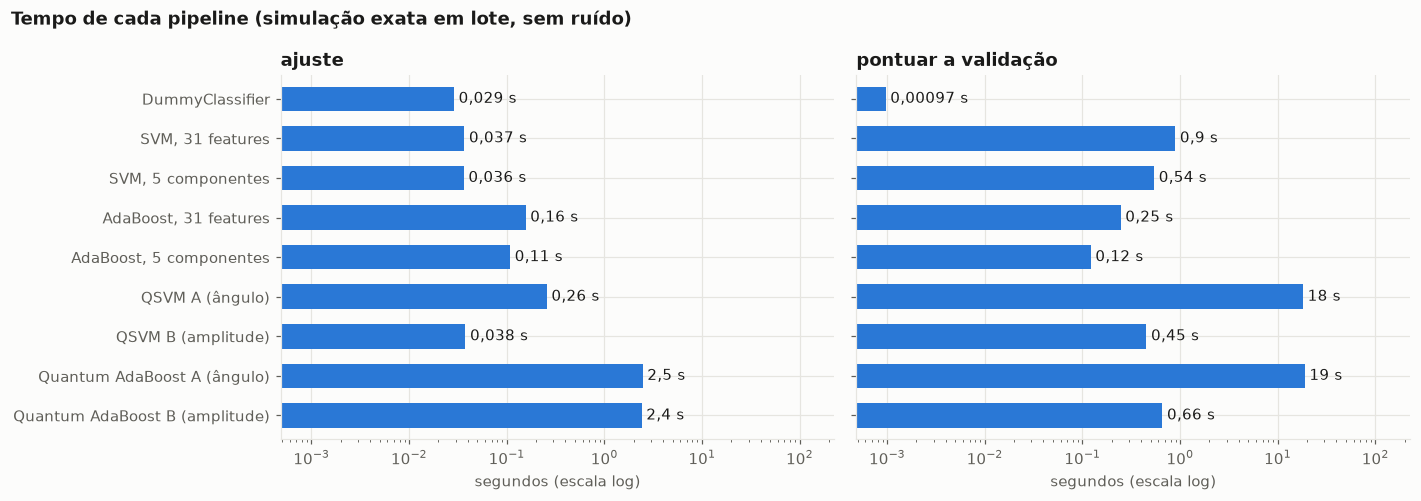

In [55]:
# Segunda execução, com o tracemalloc ligado, só para a memória alocada pelo Python
memory_runs: dict[str, ScoredFit] = {
    name: fit_and_score(pipeline, X_train, y_train, X_validation, trace_python_memory=True)
    for name, pipeline in default_pipelines().items()
}
for name, run in validation_runs.items():
    assert np.array_equal(run.scores, memory_runs[name].scores), f"{name}: duas execuções deram pontuações diferentes"
print("As duas execuções (no mesmo processo, uma depois da outra) deram pontuações idênticas nos nove pipelines.")

cost_table = pd.DataFrame(
    {
        "ajuste (s)": {name: run.fit_cost.wall_seconds for name, run in validation_runs.items()},
        "pontuar a validação (s)": {name: run.predict_cost.wall_seconds for name, run in validation_runs.items()},
        "ajuste: pico Python (MiB)": {name: run.fit_cost.python_peak_mib for name, run in memory_runs.items()},
        "ajuste: aumento do RSS (MiB)": {name: run.fit_cost.rss_peak_increase_mib for name, run in memory_runs.items()},
        "pontuar: pico Python (MiB)": {name: run.predict_cost.python_peak_mib for name, run in memory_runs.items()},
        "pontuar: aumento do RSS (MiB)": {name: run.predict_cost.rss_peak_increase_mib for name, run in memory_runs.items()},
    }
).loc[model_names]
display(
    cost_table.style.format("{:.3f}", subset=list(cost_table.columns[:2])).format("{:.1f}", subset=list(cost_table.columns[2:]))
    .apply(highlight_best).set_caption(
        f"Custo de um ajuste no treino e de pontuar as {len(y_validation):,} linhas da validação. Tempo: execução sem "
        "tracemalloc. Memória: segunda execução, com tracemalloc (pico do Python) e RSS (memória física do processo, "
        "que inclui Aer e libsvm). Destaque: maior valor da coluna (o mais caro)."
    )
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
for ax, column in zip(axes, cost_table.columns[:2]):
    bars = ax.barh(bar_positions, cost_table[column], color=NEUTRAL_SERIES_COLOR, height=0.62)
    ax.bar_label(bars, labels=[f"{value:.2g} s".replace(".", ",") for value in cost_table[column]], padding=3)
    ax.set_xscale("log")
    ax.set(title=column.replace(" (s)", ""), xlabel="segundos (escala log)",
           xlim=(cost_table.iloc[:, :2].to_numpy().min() / 2, cost_table.iloc[:, :2].to_numpy().max() * 12),
           ylim=(-0.6, len(model_names) - 0.4))
    ax.set_yticks(bar_positions, model_names)
fig.suptitle("Tempo de cada pipeline (simulação exata em lote, sem ruído)", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()


**Leitura da 5.4: o custo**

Os tempos mudam alguns por cento de uma execução para outra; os números abaixo são arredondados.

**1. O que custa é simular os estados da validação.** Ajustar qualquer modelo leva menos de 3 s: os clássicos, de
0,04 a 0,16 s; o QSVM A, cerca de 0,3 s; os Quantum AdaBoost, cerca de 2,5 s. Pontuar a validação com as variações de
ângulo (QSVM A e Quantum AdaBoost A) leva cerca de 19 s, de 20 a 35 vezes o tempo do SVM clássico, porque cada uma
das 56.745 transações vira um circuito de codificação simulado.

**2. A amplitude custa como um clássico.** O QSVM B e o Quantum AdaBoost B pontuam a validação em menos de 1 s: na
codificação de amplitude não há circuito a simular (o vetor normalizado já é o estado). É o lado prático de o
kernel de amplitude ser calculável classicamente (CC3).

**3. A Seção 1 superestimava o custo.** Ela estimava cerca de 5 min para o QSVM prever a validação, pelo caminho
circuito a circuito. Simulando os estados em lote e aplicando o ansatz como matriz, o mesmo cálculo cai para menos de
20 s, com o mesmo resultado matemático (testes). A leitura 1.2 ganhou uma nota sobre isso.

**4. Memória.** O pico do Python ao pontuar fica em torno de 105 a 109 MiB nos quânticos e de 27 MiB nos clássicos:
os quânticos guardam o estado de cada transação da validação (56.745 × 32 números complexos, cerca de 28 MiB por
cópia), e há mais de uma cópia em memória ao mesmo tempo. O aumento do RSS acompanha, com mais ruído.

**5. Reprodutibilidade.** As duas execuções, seguidas e no mesmo processo, deram pontuações idênticas nos nove
pipelines. Uma ressalva: o COBYLA amplifica diferenças de arredondamento (nos testes, diferenças abaixo de 10⁻¹² no
custo viram 10⁻³ nos pesos), então em outra máquina ou versão de biblioteca o Quantum AdaBoost pode não sair idêntico.
Não foi verificado.

**O que este custo não é.** É o custo de simular exatamente 5 qubits, que dobra a cada qubit a mais. Num computador
quântico, o kernel de fidelidade precisa de um circuito para cada **par** de transações (e não um por transação, como
na simulação), repetido muitas vezes, além de fila e ruído. O TCC deve apresentar estes números como custo de
simulação (CC15, TX10).


#### 5.4.1 Quanto o resultado muda com outro sorteio do undersampling

> **Papel no experimento:** **só ilustra ou verifica.** Dá a ordem de grandeza da incerteza que o bootstrap da 5.4 não mede. Usa só o treino; nenhuma escolha sai daqui.

Cada modelo da 5.4 viu **um** subconjunto balanceado: as 284 fraudes do treino e 284 legítimas sorteadas entre
169.951. Outro sorteio daria outras 284 legítimas e outro modelo. Para medir quanto isso pesa **sem usar a
validação**, a célula separa 30% do próprio treino (estratificado) como conjunto de avaliação interno, ajusta os
oito modelos nos outros 70% com três sementes diferentes e compara a PR-AUC entre elas. A semente muda tudo o que é
sorteado no pipeline: o undersampling, o PCA e, nos AdaBoost, os pesos iniciais dos classificadores fracos.

Os valores **não são comparáveis** aos da validação (menos fraudes no ajuste, outro conjunto de avaliação). O que
interessa é o tamanho da variação entre as sementes. As três são as primeiras de `SUBSAMPLE_SEEDS`; não são as
sementes de robustez da Seção 9.


In [56]:
INNER_HOLDOUT_FRACTION: float = 0.3
INNER_SEEDS: tuple[int, ...] = SUBSAMPLE_SEEDS[:3]

inner_fit_features, inner_holdout_features, inner_fit_labels, inner_holdout_labels = train_test_split(
    X_train, y_train, test_size=INNER_HOLDOUT_FRACTION, stratify=y_train, random_state=config.RANDOM_STATE
)
inner_pr_auc: dict[int, dict[str, float]] = {}
for seed in INNER_SEEDS:
    inner_pr_auc[seed] = {}
    for name, pipeline in default_pipelines(seed).items():
        if name == BASELINE_NAME:
            continue
        inner_run = fit_and_score(pipeline, inner_fit_features, inner_fit_labels, inner_holdout_features)
        inner_pr_auc[seed][name] = compute_classification_metrics(inner_holdout_labels, inner_run.scores, inner_run.predictions).pr_auc

seed_variation = pd.DataFrame(inner_pr_auc).rename(columns=lambda seed: f"semente {seed}")
seed_columns = list(seed_variation.columns)
seed_variation["média"] = seed_variation[seed_columns].mean(axis=1)
seed_variation["desvio entre sementes"] = seed_variation[seed_columns].std(axis=1)
seed_variation["maior − menor"] = seed_variation[seed_columns].max(axis=1) - seed_variation[seed_columns].min(axis=1)
# Largura do intervalo de bootstrap da 5.4, para comparar as duas fontes de incerteza
seed_variation["largura do IC 95% na validação (5.4)"] = (
    pr_auc_intervals[PR_AUC_INTERVAL_COLUMNS[1]] - pr_auc_intervals[PR_AUC_INTERVAL_COLUMNS[0]]
).loc[seed_variation.index]
display(
    seed_variation.style.format("{:.3f}").apply(highlight_best, subset=["desvio entre sementes", "maior − menor"]).set_caption(
        f"PR-AUC num conjunto de avaliação interno do treino ({len(inner_holdout_labels):,} linhas, "
        f"{int(inner_holdout_labels.sum())} fraudes), com o ajuste nos outros {len(inner_fit_labels):,} "
        f"({int(inner_fit_labels.sum())} fraudes) e {len(INNER_SEEDS)} sementes. Só treino. Destaque: o modelo que mais varia."
    )
)


,semente 42,semente 0,semente 1,média,desvio entre sementes,maior − menor,largura do IC 95% na validação (5.4)
"SVM, 31 features",0.661,0.638,0.689,0.663,0.025,0.051,0.179
"SVM, 5 componentes",0.666,0.642,0.686,0.665,0.022,0.044,0.170
"AdaBoost, 31 features",0.545,0.570,0.683,0.599,0.073,0.138,0.188
"AdaBoost, 5 componentes",0.364,0.657,0.563,0.528,0.150,0.293,0.181
QSVM A (ângulo),0.291,0.290,0.327,0.303,0.021,0.037,0.211
QSVM B (amplitude),0.275,0.343,0.312,0.310,0.034,0.068,0.200
Quantum AdaBoost A (ângulo),0.406,0.152,0.096,0.218,0.165,0.309,0.143
Quantum AdaBoost B (amplitude),0.015,0.026,0.029,0.023,0.007,0.014,0.026


**Leitura da 5.4.1**

Só treino: cada modelo foi ajustado em 70% dele (119.164 linhas, 199 fraudes; depois do undersampling, 398 linhas) e
avaliado nos outros 30% (51.071 linhas, 85 fraudes), com 3 sementes. Os valores não se comparam com os da validação:
o modelo viu menos fraudes e o conjunto avaliado é outro. O que interessa é **quanto cada modelo muda de uma semente
para outra**, e como isso se compara com a largura do intervalo de bootstrap da 5.4.

**1. Os SVM e os QSVM são estáveis.** Entre a menor e a maior semente, a PR-AUC muda de 0,037 a 0,068, bem menos que
a largura do intervalo da validação (0,170 a 0,211). Para esses modelos, a maior fonte de incerteza é o conjunto de
avaliação, que é o que o bootstrap mede.

**2. Os AdaBoost e o Quantum AdaBoost A não são.** O AdaBoost com 5 componentes vai de 0,364 a 0,657 (diferença de
0,293) e o Quantum AdaBoost A, de 0,096 a 0,406 (0,309). Nos dois, a variação entre sementes é maior que a largura do
intervalo da validação (0,181 e 0,143): o intervalo da 5.4 subestima a incerteza deles. O AdaBoost com 31 features
varia menos (0,545 a 0,683), mas ainda bem mais que os SVM. O Quantum AdaBoost B é estável porque fica perto do acaso
em todas as sementes (0,015 a 0,029).

Uma explicação provável, ainda não testada isoladamente: a semente muda ao mesmo tempo as legítimas sorteadas no
undersampling, o PCA e os pesos iniciais de cada classificador fraco. O boosting encadeia 50 rodadas em que cada uma
depende dos erros da anterior, então uma diferença pequena no começo se propaga; no Quantum AdaBoost, ainda muda a
rodada em que o boosting para (5.5.1).

**3. Algumas conclusões da validação não se repetem aqui.**
- **SVM com 5 componentes × 31 features:** na validação, os 5 componentes ficavam à frente (+0,054); aqui as médias
  empatam (0,665 e 0,663).
- **AdaBoost com 5 componentes × 31 features:** na validação, os 5 componentes ficavam bem à frente (+0,224); aqui a
  ordem se inverte na média (0,528 contra 0,599) e depende da semente.
- **O que se repete:** o SVM fica acima do QSVM em todas as sementes, com folga (o pior SVM, 0,638, contra o melhor
  QSVM, 0,343), e as duas variações do QSVM empatam (0,303 e 0,310).

**O que isso muda.**
- Comparações que envolvem os AdaBoost não podem ser decididas com um único sorteio. A validação cruzada da Seção 6 e
  as 5 sementes da Seção 9 precisam entrar na leitura de qualquer diferença entre eles.
- A vantagem dos 5 componentes sobre as 31 features, que a 5.4 sugeria nos clássicos, fica sem sustentação.
- São só 3 sementes: o desvio entre elas é uma ordem de grandeza, e não uma medida precisa.


### 5.5 Por dentro dos dois AdaBoost

> **Papel no experimento:** **só ilustra ou verifica.** Abre os modelos treinados na 5.4 e, só com o treino, mede quanto a parada do boosting quântico depende da semente; nada é escolhido.

O AdaBoost guarda, de cada rodada, o **ε** (erro ponderado) e o **α** (peso do voto) do classificador fraco. A cada
rodada o boosting aumenta o peso das transações erradas, então o problema entregue ao próximo classificador fica
**mais difícil**: é esperado que ε suba ao longo das rodadas. O scikit-learn **interrompe** o boosting quando o
classificador de uma rodada tem ε ≥ 0,5 e o descarta: ele não fica guardado no modelo.

**Para ver o classificador descartado,** a função `replay_boosting` refaz as contas do boosting no treino
balanceado (peso das transações erradas multiplicado por e^α, depois normalização) e treina o classificador da
rodada seguinte, com a semente que o boosting lhe daria. A célula confere que os ε refeitos são os que o modelo
guardou, o que garante que a reconstrução é fiel.

**Pontuações distintas.** A pontuação do AdaBoost é a soma dos votos (+α ou −α de cada classificador fraco). Com
poucos classificadores, muitas transações recebem exatamente a mesma soma e ficam empatadas: o modelo ordena por
degraus, e não por um contínuo. A tabela conta quantos valores diferentes aparecem na validação.

A célula também confere duas afirmações do plano:
- os α guardados obedecem a α = ln((1 − ε)/ε), a fórmula do scikit-learn (o fator ½ do Algoritmo 2 do artigo não
  muda as decisões);
- o AdaBoost de *stumps* não depende do scaler: sem a etapa `scaler`, as pontuações da validação são as mesmas.


,rodadas pedidas,classificadores fracos mantidos,ε da 1ª rodada,ε médio,maior ε,ε do classificador seguinte,α da 1ª rodada,α médio,pontuações distintas na validação,avaliações do COBYLA no ajuste
modelo,,,,,,,,,,
"AdaBoost, 31 features",50,50,0.069,0.369,0.444,0.371,2.607,0.559,"22,959",—
"AdaBoost, 5 componentes",50,50,0.104,0.431,0.480,0.474,2.155,0.292,581,—
Quantum AdaBoost A (ângulo),50,13,0.326,0.404,0.473,0.504,0.728,0.397,859,780
Quantum AdaBoost B (amplitude),50,14,0.283,0.414,0.493,0.502,0.927,0.355,"5,920",840


Quantum AdaBoost A (ângulo): 780 avaliações do custo em 2.48 s de ajuste = 3.2 ms por avaliação (Seção 1, circuito a circuito: 174 ms por avaliação)
Quantum AdaBoost B (amplitude): 840 avaliações do custo em 2.42 s de ajuste = 2.9 ms por avaliação (Seção 1, circuito a circuito: 174 ms por avaliação)


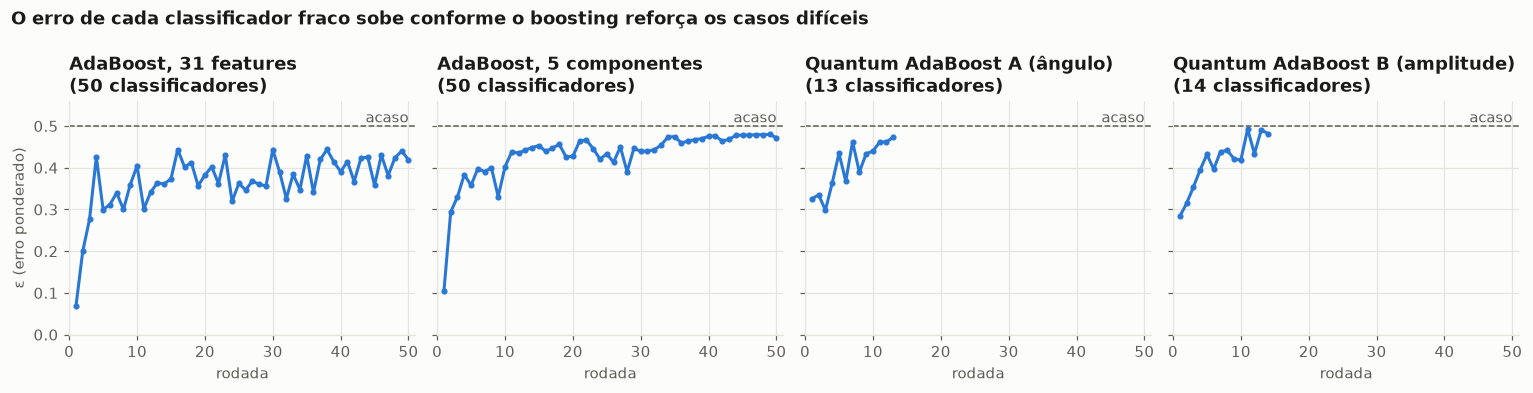

AdaBoost de stumps com e sem StandardScaler: maior diferença de pontuação na validação = 0.0e+00


In [57]:
BOOSTED_MODELS: tuple[str, ...] = (
    "AdaBoost, 31 features", "AdaBoost, 5 componentes", "Quantum AdaBoost A (ângulo)", "Quantum AdaBoost B (amplitude)",
)

boosting_rows: list[dict[str, float | int | str]] = []
round_errors: dict[str, np.ndarray] = {}
for name in BOOSTED_MODELS:
    pipeline = fitted_pipelines[name]
    booster = pipeline.named_steps["model"]
    n_fitted = len(booster.estimators_)
    errors, vote_weights = booster.estimator_errors_[:n_fitted], booster.estimator_weights_[:n_fitted]
    # A fórmula do scikit-learn (SAMME com duas classes): sem o ½ do artigo, que só reescala todos os votos
    assert np.allclose(vote_weights, booster.learning_rate * np.log((1 - errors) / errors)), name

    # As linhas que o booster viu: o treino balanceado (mesma semente do pipeline), passado pelas etapas do meio
    booster_input = undersampled_features
    for _, step in pipeline.steps[1:-1]:
        booster_input = step.transform(booster_input)
    replay = replay_boosting(booster, booster_input, undersampled_labels.to_numpy())
    assert np.allclose(replay.errors, errors), f"{name}: a reconstrução do boosting não bate com o modelo"

    cost_evaluations = sum(len(estimator.loss_curve_) for estimator in booster.estimators_) if booster.estimator is not None else np.nan
    round_errors[name] = errors
    boosting_rows.append(
        {
            "modelo": name,
            "rodadas pedidas": booster.n_estimators,
            "classificadores fracos mantidos": n_fitted,
            "ε da 1ª rodada": errors[0],
            "ε médio": errors.mean(),
            "maior ε": errors.max(),
            "ε do classificador seguinte": replay.next_error,
            "α da 1ª rodada": vote_weights[0],
            "α médio": vote_weights.mean(),
            "pontuações distintas na validação": len(np.unique(validation_runs[name].scores)),
            "avaliações do COBYLA no ajuste": cost_evaluations,
        }
    )
boosting_table = pd.DataFrame(boosting_rows).set_index("modelo")
integer_columns = ["rodadas pedidas", "classificadores fracos mantidos", "pontuações distintas na validação", "avaliações do COBYLA no ajuste"]
display(
    boosting_table.style.format("{:.3f}").format("{:,.0f}", subset=integer_columns, na_rep="—")
    .apply(highlight_smallest, subset=["ε da 1ª rodada"]).apply(highlight_best, subset=["classificadores fracos mantidos"])
    .set_caption(
        "Os boostings treinados na 5.4. ε = erro ponderado de cada classificador fraco no treino balanceado; "
        "α = peso do voto. \"ε do classificador seguinte\": o da rodada depois da última mantida, refeito no treino "
        "(quando o boosting parou antes das rodadas pedidas, é o classificador que o scikit-learn descartou). "
        f"Pontuações distintas: valores diferentes da soma dos votos nas {len(y_validation):,} linhas da validação. "
        "Destaque: menor ε inicial e mais classificadores mantidos."
    )
)
for name in BOOSTED_MODELS[2:]:
    evaluations = boosting_table.loc[name, "avaliações do COBYLA no ajuste"]
    print(f"{name}: {evaluations:,.0f} avaliações do custo em {validation_runs[name].fit_cost.wall_seconds:.2f} s de ajuste "
          f"= {validation_runs[name].fit_cost.wall_seconds / evaluations * 1000:.1f} ms por avaliação "
          f"(Seção 1, circuito a circuito: {seconds_per_forward_pass * 1000:.0f} ms por avaliação)")

fig, axes = plt.subplots(1, len(BOOSTED_MODELS), figsize=(14, 3.6), sharey=True)
for ax, name in zip(axes, BOOSTED_MODELS):
    errors = round_errors[name]
    ax.plot(np.arange(1, len(errors) + 1), errors, marker="o", markersize=3, color=NEUTRAL_SERIES_COLOR)
    ax.axhline(0.5, color="#5f5e58", linewidth=1, linestyle="--")
    ax.text(boosting_table["rodadas pedidas"].max(), 0.5, "acaso", ha="right", va="bottom", color="#5f5e58")
    ax.set(title=f"{name}\n({len(errors)} classificadores)", xlabel="rodada", xlim=(0, boosting_table["rodadas pedidas"].max() + 1),
           ylim=(0, 0.56))
    ax.title.set_fontsize(10)
axes[0].set_ylabel("ε (erro ponderado)")
fig.suptitle("O erro de cada classificador fraco sobe conforme o boosting reforça os casos difíceis", x=0.01, ha="left",
             fontweight="bold")
plt.tight_layout()
plt.show()

# AdaBoost de stumps sem o scaler: um stump só compara cada feature com um limiar, e reescalar não muda a comparação
unscaled_adaboost = build_adaboost_pipeline("all_features").set_params(scaler="passthrough").fit(X_train, y_train)
scaler_effect = float(np.abs(unscaled_adaboost.decision_function(X_validation) - validation_runs["AdaBoost, 31 features"].scores).max())
assert scaler_effect < 1e-9, "o AdaBoost de stumps não deveria depender do scaler"
print(f"AdaBoost de stumps com e sem StandardScaler: maior diferença de pontuação na validação = {scaler_effect:.1e}")


**Leitura da 5.5**

Os quatro boostings são os modelos treinados na 5.4 (um único sorteio do undersampling e a semente do experimento).
O ε e o α são medidos no treino balanceado; as pontuações distintas, na validação.

**1. Os AdaBoost clássicos usam as 50 rodadas, e o primeiro *stump* já é forte.** O primeiro classificador fraco erra
só 6,9% (31 features) e 10,4% (5 componentes) do peso, e por isso recebe um voto grande (α de 2,607 e 2,155). A
partir daí o ε sobe, como esperado (o gráfico mostra a subida), mas fica abaixo de 0,5 até o fim: o maior é 0,444 e
0,480, e o classificador da rodada seguinte, se houvesse uma 51ª, ainda teria ε de 0,371 e 0,474.

**2. Os Quantum AdaBoost param cedo: 13 (A) e 14 (B) classificadores das 50 rodadas pedidas.** O classificador fraco
quântico já começa bem mais fraco que o *stump* (ε de 0,326 e 0,283 na primeira rodada, α de 0,728 e 0,927). O ε
sobe ao longo das rodadas até encostar no acaso (0,473 e 0,493), e o classificador seguinte, refeito pela
reconstrução do boosting, fica com ε de 0,504 (A) e 0,502 (B): passa de 0,5 por muito pouco, e o scikit-learn o
descarta e encerra o boosting. Os números 13 e 14 são desta semente; a 5.5.1 mostra quanto eles mudam com outras.

**3. As conferências do plano passaram.**
- Os α guardados obedecem a α = ln((1 − ε)/ε) nos quatro modelos (o `assert` não acusou nada): é a fórmula do
  Algoritmo 1 do artigo com duas classes, e o fator ½ do Algoritmo 2 não muda nenhuma decisão.
- A reconstrução do boosting reproduz os ε guardados nos quatro modelos, então o ε do classificador descartado é o
  que o scikit-learn de fato viu.
- O AdaBoost de *stumps* dá exatamente as mesmas pontuações com e sem o StandardScaler (diferença 0).

**4. Os degraus não explicam o desempenho.** Com poucos classificadores, muitas transações recebem a mesma soma de
votos: o Quantum AdaBoost A tem 859 pontuações distintas na validação e o B, 5.920. Mas o AdaBoost com 5 componentes
tem ainda menos (581) e a maior PR-AUC entre os boostings (0,669, na 5.4). Ordenar por degraus não é, por si só, o
problema.

**5. O ajuste quântico é barato nesta implementação.** O Quantum AdaBoost A fez 780 avaliações do custo no ajuste e o
B, 840, a cerca de 3 ms cada, contra cerca de 173 ms por avaliação no caminho circuito a circuito medido na Seção 1.
O tempo exato muda alguns por cento de uma execução para outra.

**O que isso muda.** No Quantum AdaBoost, `n_estimators` funciona como um teto, e não como o número de classificadores:
o grid da Seção 6 precisa registrar quantos foram mantidos em cada combinação e decidir o que fazer com a parada
(ponto ⑤ do PLAN). E a comparação entre os dois boostings precisa levar em conta que um deles para no meio do
caminho.


#### 5.5.1 A parada do boosting quântico depende da semente?

> **Papel no experimento:** **só ilustra ou verifica.** Mede, só no treino, se "parou em tantas rodadas" é uma característica do modelo ou de um sorteio. Nada é escolhido.

O boosting sorteia os pesos iniciais de cada classificador fraco a partir da semente do `AdaBoostClassifier`. Uma
rodada que começa de um ponto ruim pode terminar com ε ≥ 0,5 e encerrar tudo. A célula repete o ajuste do Quantum
AdaBoost **no treino**, mudando só essa semente (o sorteio do undersampling continua o do experimento), em quatro
configurações: os dois padrões, o padrão A com cinco vezes mais avaliações e o padrão A com a rotação em Y.


In [58]:
BOOSTER_SEEDS: tuple[int, ...] = SUBSAMPLE_SEEDS[:3]
LONG_BUDGET: int = 300
STOP_CONFIGURATIONS: dict[str, tuple[dict[str, str], int]] = {
    f"A: mapa ZZ, 2 repetições (padrão), {DEFAULT_MAX_ITERATIONS} avaliações": ({"variation": "angle"}, DEFAULT_MAX_ITERATIONS),
    f"A: mapa ZZ, 2 repetições, {LONG_BUDGET} avaliações": ({"variation": "angle"}, LONG_BUDGET),
    f"A com rotação em Y, {DEFAULT_MAX_ITERATIONS} avaliações": ({"variation": "angle", "feature_map": "ry"}, DEFAULT_MAX_ITERATIONS),
    f"B: amplitude (padrão), {DEFAULT_MAX_ITERATIONS} avaliações": ({"variation": "amplitude"}, DEFAULT_MAX_ITERATIONS),
}



def highlight_table_maximum(table: pd.DataFrame) -> np.ndarray:
    """Destaque (fundo ciano escuro, texto branco) nas células com o maior valor da tabela inteira."""
    style = f"background-color: {HIGHLIGHT_COLOR}; color: {HIGHLIGHT_TEXT_COLOR}"
    return np.where(table.to_numpy() == table.to_numpy().max(), style, "")


stop_rows: list[dict[str, float | int | str]] = []
for configuration_name, (encoding_arguments, max_iterations) in STOP_CONFIGURATIONS.items():
    for seed in BOOSTER_SEEDS:
        seeded_pipeline = build_quantum_adaboost_pipeline(
            quantum_encoding_steps(**encoding_arguments), max_iterations=max_iterations
        ).set_params(model__random_state=seed)
        seeded_booster = seeded_pipeline.fit(X_train, y_train).named_steps["model"]
        stop_rows.append(
            {
                "configuração": configuration_name,
                "semente do boosting": seed,
                "classificadores mantidos": len(seeded_booster.estimators_),
                "ε da 1ª rodada": seeded_booster.estimator_errors_[0],
            }
        )
stop_table = pd.DataFrame(stop_rows).pivot(index="configuração", columns="semente do boosting").loc[list(STOP_CONFIGURATIONS)]
requested_rounds = fitted_pipelines["Quantum AdaBoost A (ângulo)"].named_steps["model"].n_estimators
display(
    stop_table.style.format("{:.0f}", subset=["classificadores mantidos"]).format("{:.3f}", subset=["ε da 1ª rodada"])
    .apply(highlight_table_maximum, subset=["classificadores mantidos"], axis=None)
    .set_caption(
        f"Quantum AdaBoost ajustado no treino com {len(BOOSTER_SEEDS)} sementes do boosting ({requested_rounds} rodadas pedidas; "
        "o sorteio do undersampling é sempre o do experimento). Destaque: o maior número de classificadores mantidos."
    )
)
kept = stop_table["classificadores mantidos"]
print(f"Classificadores mantidos: de {int(kept.to_numpy().min())} a {int(kept.to_numpy().max())} nas "
      f"{kept.size} execuções; em {int((kept.to_numpy() == requested_rounds).sum())} delas o boosting chegou às {requested_rounds} rodadas.")


Classificadores mantidos: de 7 a 44 nas 12 execuções; em 0 delas o boosting chegou às 50 rodadas.


**Leitura da 5.5.1**

Só treino. Cada linha é uma configuração do Quantum AdaBoost ajustada três vezes, mudando só a semente do boosting
(o sorteio do undersampling é sempre o do experimento).

**1. O boosting quântico nunca chegou às 50 rodadas.** Nas 12 execuções ficaram de 7 a 44 classificadores. A parada
antecipada não é um acidente da 5.5: é o comportamento normal deste classificador fraco com o `AdaBoostClassifier`.

**2. Quantos classificadores sobram depende muito da semente.** Com a configuração padrão (a da 5.4), as três sementes
dão 13, 44 e 24. O "13" da 5.5 é o resultado de uma semente, e não uma característica do modelo. Como a semente só
muda os pesos iniciais de cada classificador fraco, o mais provável é que uma rodada que começa de um ponto ruim
baste para encerrar tudo.

**3. Mais orçamento não resolve.** Com 300 avaliações do COBYLA em vez de 60, ficam 29, 13 e 17 classificadores, e
o ε da primeira rodada quase não muda (0,333 a 0,340, contra 0,326 a 0,352). Coerente com a 5.2: o classificador já
estava perto do melhor que consegue com 60 avaliações.

**4. Um classificador fraco melhor para ainda mais cedo.** Com a rotação em Y, o primeiro classificador é muito mais
forte (ε de 0,120 a 0,125, contra cerca de 0,33 do padrão), e o boosting fica com só 7, 10 e 13 classificadores.
A explicação provável, ainda não testada isoladamente: um classificador forte recebe um voto grande, o boosting
concentra o peso nos poucos casos que ele errou mais depressa, e o seguinte não consegue ficar abaixo de 0,5 neles. A rotação em Y melhora o classificador **sozinho**
(5.3), mas não resolve a parada **no boosting**.

**5. A variação B também para cedo** (20, 14 e 14), com ε inicial de 0,283 a 0,305.

**O que isso muda.** A parada é uma propriedade desta combinação (classificador fraco com corte fixo em 0,5 e a regra
do scikit-learn), e não de uma escolha de orçamento ou de codificação. No grid da Seção 6, `n_estimators` vale como
teto, e o número de classificadores mantidos precisa ser registrado em cada combinação. As saídas para a parada
(aceitar, reduzir a taxa de aprendizado, dar ao classificador fraco um corte ajustável ou adotar a regra do artigo)
são o ponto ⑤ do PLAN; as duas últimas mudam o protocolo e precisam de aprovação.


### 5.6 Conclusão da Seção 5 e o que vem a seguir

A Seção 5 implementou os quatro modelos do TCC e mediu o ponto de partida de cada um, com hiperparâmetros padrão.
As leituras de cada subseção trazem os números; aqui fica só o que a seção deixa para o resto do trabalho.

**O que a seção mostrou.**
- **Com os padrões, o clássico fica à frente nos dois pares** (5.4): nas seis comparações pareadas clássico ×
  quântico, o intervalo da diferença de PR-AUC exclui o zero. As duas variações do QSVM empatam.
- **A incerteza não é igual para todos** (5.4.1): os SVM e os QSVM mudam pouco com outro sorteio do undersampling;
  os AdaBoost e o Quantum AdaBoost A mudam muito, mais do que o intervalo de bootstrap da validação capta.
- **O classificador fraco quântico ordena bem e corta mal** (5.2, 5.3, 5.3.2): o corte fixo em P(1) = 0,5 é o que o
  deixa fraco para o boosting, e a codificação que funciona melhor depende da largura da faixa (5.3.1). A rotação em
  Y é a mais estável e entra no grid.
- **O boosting quântico para antes das rodadas pedidas, sempre** (5.5, 5.5.1), e quantos classificadores sobram
  depende da semente; nem mais orçamento nem um classificador fraco melhor evitam a parada.
- **O custo é de simulação, e é baixo nesta escala** (5.4): a restrição de grid pequeno, que vinha da Seção 1, caiu.

**O que a seção não decide.** Nenhum hiperparâmetro foi escolhido com a validação, que deixou de ser inédita mas
continua servindo para comparar modelos e escolher o limiar. Os padrões quânticos partem de opções que a Seção 4 já
sabia serem fracas, então o ganho do ajuste vai parecer maior nos quânticos. E a conclusão sobre os algoritmos só sai
com os modelos finais.

**O que vem a seguir.** A Seção 6 parte daqui: busca as opções da Seção 4 junto com a rotação em Y, procura largura
e codificação juntas no Quantum AdaBoost e registra quantos classificadores fracos cada boosting manteve. Os
resultados do grid passam a ser salvos em `artifacts/results/`, com os hiperparâmetros de cada combinação, as
métricas, o custo, as versões das bibliotecas e o commit, para que qualquer número do TCC possa ser conferido sem
reexecutar o notebook. Os pontos ① a ⑤ do PLAN foram decididos antes de rodar o grid, e a Seção 6 os registra.

## 6. Ajuste de hiperparâmetros

### O que esta seção faz
Escolhe, para cada um dos quatro modelos, a configuração que segue para a avaliação (Seção 7): a entrada, a
codificação (nos quânticos) e os hiperparâmetros do modelo. Quem escolhe é a **validação cruzada dentro do treino**.
A validação e o teste não são usados aqui.

### O grid é sobre o pipeline inteiro
Cada combinação do grid é um pipeline completo: undersampling → entrada → codificação → modelo. Scaler, redutor,
faixa dos ângulos e mapa são hiperparâmetros tanto quanto o C do SVM ou a taxa de aprendizado do AdaBoost: em cada
fold, todas as etapas são reajustadas só com as linhas de treino daquele fold.

Por que buscar tudo junto, e não escolher o pré-processamento antes:
- **As escolhas interagem.** No classificador fraco, a melhor codificação muda com a largura da faixa e com o scaler
  (5.3.1); no SVM, a escala da entrada e o γ fazem o mesmo papel. Escolher uma dimensão com as outras fixas acharia o
  melhor de um corte do grid, e não o melhor do grid.
- **Escolher por fora seria uma seleção que a validação cruzada não enxerga.** Se o pré-processamento fosse decidido
  olhando um resultado, e só o modelo entrasse no grid, a nota da validação cruzada não contaria aquela escolha, e o
  vencedor pareceria melhor do que é.

### Três tipos de decisão, sempre com o mesmo nome

| Tipo | O que decide | Exemplos | Onde vale |
|---|---|---|---|
| **Entrada** | o que o modelo recebe | scaler; redutor (PCA ou informação mútua); 31 features ou 5 componentes | os quatro modelos |
| **Codificação** | como cada transação vira um estado quântico | faixa dos ângulos, mapa (Z, ZZ, RY), repetições do mapa, emaranhamento, constante da amplitude | só os quânticos |
| **Modelo** | o algoritmo em si | C, γ, teto de rodadas, taxa de aprendizado, repetições do ansatz | cada par tem os seus |

### Termos que costumam se confundir

| Par | A diferença |
|---|---|
| Codificação de **fase** × de **ângulo** | Os mapas Z e ZZ giram o estado em torno do eixo Z (fase); a RY gira em torno do eixo Y (ângulo propriamente dito). Para o kernel do QSVM, o mapa Z com 1 repetição e a RY dão o mesmo resultado; para o classificador do Quantum AdaBoost, que mede o estado, não (CC14, 5.3). "Variação A (ângulo)" continua sendo o nome da família das codificações por rotação |
| Repetições do **mapa** × repetições do **ansatz** | As do mapa repetem a **codificação** (o circuito fixo que recebe os dados); as do ansatz repetem o circuito **treinável** do classificador fraco |
| **Faixa dos ângulos** × **γ do RBF** | As duas são larguras de banda: decidem o quanto duas transações parecem semelhantes. A faixa é do kernel quântico e é uma decisão de codificação; o γ é do kernel clássico e é uma decisão de modelo |
| **Variação A/B** × entrada **31 features / 5 componentes** | A e B são as duas codificações dos quânticos (ângulo e amplitude). 31 features e 5 componentes são as duas entradas dos clássicos: a referência com tudo e a entrada idêntica à da variação A |
| **Teto de rodadas** × **classificadores mantidos** | O teto (`n_estimators`) é o máximo de rodadas pedido; o boosting quântico costuma parar antes (5.5.1), e quantos classificadores ficaram é registrado à parte |

### Como a validação cruzada funciona aqui
- **5 folds estratificados sobre o treino inteiro.** Em cada fold, 4/5 das linhas de treino servem para ajustar e
  1/5 para avaliar; os tamanhos estão na tabela da 6.1.1.
- **O undersampling acontece dentro de cada fold**, só entre as linhas de ajuste daquele fold. O modelo vê cerca de
  4/5 das fraudes do treino e o mesmo número de legítimas.
- **O fold de avaliação fica na proporção real** de fraudes. Por isso a escolha é pela **PR-AUC**, a métrica
  principal do TCC, com o mesmo significado que ela terá na validação; a ROC-AUC também é registrada.
- **Os mesmos folds e o mesmo sorteio para todas as combinações**: a diferença entre duas combinações não vem de
  elas terem visto linhas diferentes.
- **A escolhida é a combinação de maior PR-AUC média nos 5 folds.** Diferença menor que o desvio entre folds é
  empate, e a seção conta quantas combinações empatam com a escolhida.
- **Regra para as bordas do grid** (escrita com o grid já rodando, antes de olhar os resultados, e registrada só
  neste notebook): se a escolhida ficar no menor ou no maior valor de uma dimensão numérica (C, γ, taxa de
  aprendizado, teto de rodadas, largura da faixa, constante da amplitude), isso é registrado, e o grid **não** é
  estendido depois de ver o resultado. Só uma dessas bordas vem de princípio: a faixa para em π/2 pela
  periodicidade (4.7.1). As outras vieram da escala escolhida para cada parâmetro ou do alinhamento kernel-alvo da
  Seção 4, um critério de kernel que nem se aplica ao Quantum AdaBoost (CC14).
- **As configurações escolhidas aqui ficam congeladas.** A Seção 7 as avalia na validação; a Seção 8, que vem depois,
  só descreve o que há além das bordas, sem mudar a escolha, porque mudar depois de ver a validação seria escolher
  na validação.
- **Uma ressalva de origem:** as opções do grid vieram das análises do treino na Seção 4, e o treino contém os folds
  daqui. A região do grid foi delimitada olhando as mesmas linhas que agora avaliam as combinações. O efeito tende
  a ser pequeno (as análises delimitaram regiões largas, e não escolheram valores), mas não é nulo.

**Como o grid é calculado** (`fraud_qml.tuning`). A entrada e a codificação não dependem dos hiperparâmetros do
modelo: para cada entrada e cada fold, o undersampling, o pré-processamento e a simulação dos estados são feitos uma
vez, e todos os valores de C, γ, taxa de aprendizado e repetições do ansatz reaproveitam o resultado. Nos AdaBoost,
um único ajuste com o maior teto dá, rodada a rodada (`staged_decision_function`), a pontuação de cada teto menor. Os
dois atalhos têm teste de que o número é o mesmo de ajustar o pipeline inteiro em cada combinação
(`test_two_level_search_scores_like_the_full_pipeline`, `test_reading_a_round_equals_fitting_with_that_ceiling`).

**Alternativas descartadas.**
- **Validação cruzada dentro das 568 linhas do treino balanceado** (a decisão anterior do PLAN): folds 50/50, que
  obrigam a usar a ROC-AUC e não enxergam a variação do sorteio do undersampling, que a 5.4.1 mostrou ser grande nos
  AdaBoost. Era a escolha por custo; com a simulação em lote da Seção 5, o custo deixou de ser o problema (6.1.1). Ficou
  como saída de emergência, com o critério fixado antes de rodar: se a projeção do piloto passasse de 2 h, a seção
  voltaria a ela.
- **O `GridSearchCV` do scikit-learn:** faz a mesma conta, mas refaria a simulação dos estados para cada valor de C
  e cada taxa de aprendizado. Um cache de pipeline (`Pipeline(memory=...)`) evitaria refazer a do treino, mas não a
  do fold de avaliação; e o `GridSearchCV` não lê o AdaBoost rodada a rodada.
- **Validação cruzada aninhada** (um grid dentro de cada fold de outra validação cruzada): estimaria sem otimismo o
  desempenho do processo de escolha, mas multiplicaria o custo por 5. O otimismo do vencedor é tratado de outro jeito:
  a configuração escolhida aqui é medida na validação (Seção 7), que não participou da escolha (Raschka, 2018,
  seção 3.3).

### Decisões tomadas antes de rodar (PLAN, pontos ① a ⑤, com o Eric em 2026-10-27)

| Ponto | Decisão | Por quê |
|---|---|---|
| ① Entrada e codificação do Quantum AdaBoost | Grid próprio: scaler, redutor, faixa, mapa (com a RY), repetições, emaranhamento e constante, buscados junto com o modelo | A melhor codificação do classificador fraco muda com a largura da faixa e com o scaler (5.3.1); herdar a do QSVM escolheria por um critério de kernel, que não se transfere para um modelo que mede o estado |
| ② Redutor dos clássicos com 5 componentes | Escolhido no grid de cada clássico; na comparação com o quântico, entra também o clássico com o mesmo caminho até os componentes (scaler e redutor) que o quântico escolheu | A entrada continua idêntica nos dois lados do par, e o clássico não fica preso à escolha do outro modelo |
| ③ Conjunto de features | As 31, sempre; a opção de 24 saiu | Na amplitude, 31 features + 1 constante ocupam exatamente os 5 qubits; a lista de 24 vinha de fora (4.11.4) |
| ④ Onde fica o sorteio do undersampling | Dentro de cada fold, com os folds de avaliação na proporção real e escolha pela PR-AUC | Acima; o piloto da 6.1.1 confere o custo antes de rodar |
| ⑤ A parada do boosting quântico | Aceitar a parada do scikit-learn e pôr a taxa de aprendizado no grid | É o comportamento do mesmo `AdaBoostClassifier` nos dois lados do par; uma taxa menor muda os pesos mais devagar, o que testa a saída "reduzir a taxa" sem mudar o protocolo. Ficam de fora o corte ajustável no classificador fraco e a regra do artigo, que mudariam o protocolo |

### O que esta seção não faz
- **Não usa a validação nem o teste.** Todo número desta seção vem de folds do treino.
- **Não compara clássico com quântico.** A validação cruzada escolhe a configuração de **cada** modelo; a comparação
  dos pares é da Seção 7, na validação.
- **Ressalva que acompanha todo resultado quântico daqui (CC16):** os padrões quânticos da Seção 5 eram opções que a
  Seção 4 já sabia serem fracas, então o ganho do ajuste vai parecer maior nos quânticos do que nos clássicos. A
  comparação que vale é entre os modelos já ajustados, e não entre os ganhos.

### 6.1 As opções do pré-processamento e da codificação

> **Papel no experimento:** **define opções do grid.** Monta os quatro grids a partir das opções que a Seção 4 delimitou (4.11.6) e da que a Seção 5 acrescentou (a rotação em Y, 5.3). A tabela é gerada dos grids que de fato rodam, e não escrita à mão.

A tabela é a matriz dimensão × algoritmo: em cada linha, uma decisão, o nome dela no pipeline (o parâmetro que a
muda, no formato `etapa__parâmetro` do scikit-learn) e as opções que cada modelo testa. "—" quer dizer que a decisão
não existe naquele modelo. Três escolhas da montagem que a tabela não mostra sozinha:
- **O scaler só aparece onde muda alguma coisa** (4.6.2, CC8): com informação mútua, Standard e Robust escolhem as
  mesmas features e o MinMax desfaz a escala, então esse caminho entra com um scaler só; no AdaBoost com as 31 features,
  o *stump* ignora a escala (5.5).
- **Os clássicos com 5 componentes não variam a largura da faixa.** No *stump* ela não muda nada; no RBF, reescalar
  as 5 colunas pelo mesmo fator equivale a mudar o γ, que já está no grid.
- **A RY só entra no Quantum AdaBoost.** No QSVM, o kernel dela é idêntico ao do mapa Z com 1 repetição (CC14).

In [59]:
SEARCH_SPACES: dict[str, SearchSpace] = project_search_spaces()
MODEL_ORDER: tuple[str, ...] = ("svm", "qsvm", "adaboost", "quantum_adaboost")
MODEL_LABELS: dict[str, str] = {"svm": "SVM", "qsvm": "QSVM", "adaboost": "AdaBoost", "quantum_adaboost": "Quantum AdaBoost"}
VALUE_LABELS: dict[str, str] = {
    "all_features": "31 features", "angle_components": "5 componentes", "angle": "A (ângulo)", "amplitude": "B (amplitude)",
    "standard": "Standard", "robust": "Robust", "pca": "PCA", "mutual_info": "informação mútua",
    "z": "Z", "zz": "ZZ", "ry": "RY", "linear": "vizinhos", "full": "todos os pares", "scale": "'scale'",
}

# (tipo de decisão, dimensão, parâmetro no pipeline, campo da descrição, de onde vem a opção)
GRID_DIMENSIONS: list[tuple[str, str, str, str, str]] = [
    ("entrada", "Entrada (clássicos) / variação (quânticos)", "estrutura do pipeline", "kind", "5.1"),
    ("entrada", "Scaler", "scaler", "scaler", "4.6.2 e 4.11.1"),
    ("entrada", "Redutor para 5 componentes", "reducer", "reducer", "4.9 e 4.11.4"),
    ("codificação", "Largura da faixa dos ângulos (rad)", "angle_scaler__feature_range", "range_width", "4.7 e 4.11.2"),
    ("codificação", "Mapa", "encoder__encoding", "feature_map", "4.11.2 e 5.3"),
    ("codificação", "Repetições do mapa", "encoder__feature_map_reps", "feature_map_reps", "4.11.2 (CC14)"),
    ("codificação", "Emaranhamento do ZZ", "encoder__entanglement", "entanglement", "PLAN (não medido na Seção 4)"),
    ("codificação", "Constante da amplitude", "amplitude__padding_value", "padding_value", "4.8 e 4.11.3"),
    ("modelo", "C", "model__C", "C", "escala log, uma década por passo"),
    ("modelo", "γ do RBF", "model__gamma", "gamma", "escala log + 'scale' do scikit-learn"),
    ("modelo", "Teto de rodadas", "model__n_estimators", "n_estimators", "lido rodada a rodada (5.5.1)"),
    ("modelo", "Taxa de aprendizado", "model__learning_rate", "learning_rate", "ponto ⑤ do PLAN"),
    ("modelo", "Repetições do ansatz", "model__estimator__ansatz_reps", "ansatz_reps", "classificador raso (5.1)"),
    ("modelo", "Avaliações do COBYLA (fixo)", "model__estimator__max_iterations", "max_iterations", "5.2"),
]


def decimal_comma(value: float) -> str:
    """Número curto com vírgula decimal; π/2 aparece com o símbolo."""
    if np.isclose(value, np.pi / 2):
        return "π/2"
    return f"{value:g}".replace(".", ",")


def label_value(value: object) -> str:
    """Rótulo de exibição de uma opção do grid."""
    if isinstance(value, str):
        return VALUE_LABELS.get(value, value)
    return decimal_comma(float(value))


def is_set(value: object) -> bool:
    """Se o campo vale para a combinação (os que não valem ficam vazios na tabela de resultados)."""
    return value is not None and not (isinstance(value, float) and np.isnan(value))


def grid_options(space: SearchSpace, field: str) -> str:
    """As opções de uma dimensão num grid, lidas das próprias combinações."""
    if field in INPUT_COLUMNS:
        values = {tuning.describe_input(option)[field] for option in space.input_encodings}
    elif field == "n_estimators" and space.boosting_stages:
        values = set(space.boosting_stages)
    else:
        values = {tuning.describe_model(model)[field] for model in space.models}
    values.discard(None)
    if not values:
        return "—"
    # Textos primeiro (em ordem alfabética do rótulo), números depois (em ordem crescente)
    ordered = sorted(values, key=lambda value: (0, label_value(value), 0.0) if isinstance(value, str) else (1, "", float(value)))
    return " / ".join(label_value(value) for value in ordered)


grid_matrix = pd.DataFrame(
    [
        {
            "tipo de decisão": decision, "dimensão": dimension, "parâmetro no pipeline": parameter,
            **{MODEL_LABELS[name]: grid_options(SEARCH_SPACES[name], field) for name in MODEL_ORDER},
            "de onde vem": origin,
        }
        for decision, dimension, parameter, field, origin in GRID_DIMENSIONS
    ]
).set_index(["tipo de decisão", "dimensão"])
display(
    grid_matrix.style.set_caption(
        "Matriz dimensão × algoritmo: as opções que cada grid testa (— = a decisão não existe no modelo). "
        "Gerada a partir dos próprios grids. As seções citadas em 'de onde vem' são deste notebook."
    )
)


**Leitura da 6.1**

A matriz é lida das combinações que de fato rodam, e não do plano.

1. **Os dois pares têm a mesma estrutura de entrada.** Clássicos e quânticos escolhem entre os mesmos scalers e os
   mesmos redutores. A diferença está no que vem depois: as entradas dos clássicos são "31 features" e "5
   componentes"; as dos quânticos, as variações A e B.
2. **As decisões de codificação só existem nos quânticos**, e a RY só no Quantum AdaBoost (no QSVM, o kernel dela é o
   mesmo do mapa Z com 1 repetição).
3. **As decisões de modelo seguem os pares.** O C é comum ao SVM e ao QSVM; o γ é só do SVM. O teto de rodadas e a
   taxa de aprendizado são comuns aos dois AdaBoost; as repetições do ansatz são só do Quantum AdaBoost; as
   avaliações do COBYLA ficam fixas em 60.

**O que a matriz junta e precisa ser separado:** a linha do scaler mostra "Robust / Standard" no AdaBoost porque o
caminho dos 5 componentes usa os dois; com as 31 features, o AdaBoost usa só o StandardScaler. E o caminho com
informação mútua usa só o StandardScaler em todos os modelos (CC8).

#### 6.1.1 Tamanho do grid e o piloto de custo

> **Papel no experimento:** **só ilustra ou verifica.** Conta as combinações de cada grid e confere, antes de rodar, se a busca cabe no limite de 2 h fixado com o Eric (PLAN, decisão de arquitetura 3). Usa só o treino.

**O piloto.** Para cada modelo, roda a entrada **mais cara** do grid nos 5 folds, com todas as configurações do
modelo: as 31 features nos clássicos (a entrada de maior dimensão) e, nos quânticos, o mapa ZZ com 2 repetições e
emaranhamento entre todos os pares (o circuito mais profundo). A projeção supõe que **toda** tarefa (uma entrada num
fold) demora o mesmo que a mais lenta do piloto, e que as tarefas rodam em levas do número de processos disponíveis.
A intenção era errar para mais; a 6.3 compara a projeção com o tempo medido de cada grid. Se a soma passar de 2 h, a célula para com um erro, e a seção volta ao desenho anterior
(validação cruzada dentro do treino balanceado).

**Duas contagens diferentes.** "Combinações" são os pipelines que a validação cruzada compara. "Ajustes de modelo" são
os ajustes de fato feitos: nos AdaBoost, um ajuste com o maior teto dá os quatro tetos de uma vez.

In [60]:
PILOT_INPUTS: dict[str, InputEncoding] = {
    "svm": InputEncoding("all_features"),
    "qsvm": InputEncoding("angle", feature_map="zz", feature_map_reps=2, entanglement="full"),
    "adaboost": InputEncoding("all_features"),
    "quantum_adaboost": InputEncoding("angle", feature_map="zz", feature_map_reps=2, entanglement="full"),
}

# Os folds que todos os grids usam: 4/5 do treino para ajustar (e sortear o treino balanceado), 1/5 para avaliar
grid_folds = cv_folds(y_train, config.CV_N_SPLITS, config.RANDOM_STATE)
y_train_array = y_train.to_numpy()
fold_table = pd.DataFrame(
    [
        {
            "linhas de ajuste": len(fit_rows),
            "fraudes no ajuste": int(y_train_array[fit_rows].sum()),
            "linhas que o modelo vê (após o undersampling)": 2 * int(y_train_array[fit_rows].sum()),
            "linhas avaliadas": len(evaluated_rows),
            "fraudes avaliadas": int(y_train_array[evaluated_rows].sum()),
            "% de fraudes avaliadas": 100 * y_train_array[evaluated_rows].mean(),
        }
        for fit_rows, evaluated_rows in grid_folds
    ],
    index=pd.Index(range(1, config.CV_N_SPLITS + 1), name="fold"),
)
display(
    fold_table.style.format("{:,.0f}").format("{:.4f}", subset=["% de fraudes avaliadas"]).set_caption(
        f"Os {config.CV_N_SPLITS} folds estratificados do treino ({len(y_train):,} linhas), os mesmos para os quatro grids"
    )
)

pilot_rows: list[dict[str, float | int]] = []
for name in MODEL_ORDER:
    space = SEARCH_SPACES[name]
    pilot = run_grid_search(replace(space, input_encodings=(PILOT_INPUTS[name],)), X_train, y_train)
    n_tasks = space.n_tasks(config.CV_N_SPLITS)
    pilot_rows.append(
        {
            "modelo": MODEL_LABELS[name],
            "entradas e codificações": len(space.input_encodings),
            "configurações do modelo": len(space.models) * max(1, len(space.boosting_stages)),
            "combinações": space.n_combinations,
            "ajustes de modelo (com os folds)": len(space.input_encodings) * len(space.models) * config.CV_N_SPLITS,
            "tarefas (entrada × fold)": n_tasks,
            "tarefa mais lenta do piloto (s)": float(pilot.task_seconds.max()),
            "projeção do grid (min)": project_grid_seconds(pilot.task_seconds, n_tasks, config.N_JOBS) / 60,
        }
    )
pilot_table = pd.DataFrame(pilot_rows).set_index("modelo")
display(
    pilot_table.style.format("{:,.0f}").format("{:.1f}", subset=["tarefa mais lenta do piloto (s)", "projeção do grid (min)"])
    .apply(highlight_best, subset=["combinações", "projeção do grid (min)"]).set_caption(
        f"Tamanho dos quatro grids ({config.CV_N_SPLITS} folds) e projeção do tempo, a partir de um piloto "
        f"com a entrada mais cara de cada modelo ({config.N_JOBS} processos). Destaque: o maior de cada coluna."
    )
)

projected_minutes = float(pilot_table["projeção do grid (min)"].sum())
limit_minutes = config.GRID_TIME_LIMIT_SECONDS / 60
if projected_minutes > limit_minutes:
    raise RuntimeError(
        f"O grid projetado ({projected_minutes:.0f} min) passa do limite de {limit_minutes:.0f} min: voltar à validação "
        "cruzada dentro do treino balanceado (PLAN, decisão de arquitetura 3)."
    )
print(f"Projeção da seção inteira: {projected_minutes:.0f} min, dentro do limite de {limit_minutes:.0f} min. "
      "O desenho com os folds na proporção real fica.")


,linhas de ajuste,fraudes no ajuste,linhas que o modelo vê (após o undersampling),linhas avaliadas,fraudes avaliadas,% de fraudes avaliadas
fold,,,,,,
1,"136,188",228,456,"34,047",56,0.1645
2,"136,188",227,454,"34,047",57,0.1674
3,"136,188",227,454,"34,047",57,0.1674
4,"136,188",227,454,"34,047",57,0.1674
5,"136,188",227,454,"34,047",57,0.1674


,entradas e codificações,configurações do modelo,combinações,ajustes de modelo (com os folds),tarefas (entrada × fold),tarefa mais lenta do piloto (s),projeção do grid (min)
modelo,,,,,,,
SVM,5,20,100,500,25,21.6,1.1
QSVM,78,4,312,"1,560",390,22.3,12.3
AdaBoost,4,12,48,60,20,2.6,0.1
Quantum AdaBoost,90,24,"2,160","2,700",450,109.1,69.1


Projeção da seção inteira: 83 min, dentro do limite de 120 min. O desenho com os folds na proporção real fica.


**Leitura da 6.1.1**

1. **Os folds.** Cada fold ajusta em 136.188 linhas, com 227 ou 228 fraudes; depois do undersampling, o modelo vê
   454 ou 456 linhas. A avaliação é em 34.047 linhas com 56 ou 57 fraudes (de 0,1645% a 0,1674%), na proporção real.
   São menos linhas do que o modelo da Seção 7 verá (568, sorteadas do treino inteiro), e é com esse tamanho que a
   validação cruzada compara as combinações.
2. **O tamanho dos grids é muito desigual.** São 100 combinações no SVM, 312 no QSVM, 48 no AdaBoost e 2.160 no
   Quantum AdaBoost: o grid do Quantum AdaBoost tem 45 vezes o tamanho do grid do AdaBoost clássico. A diferença vem da
   codificação, que só os quânticos têm. Ela pesa na leitura dos resultados (6.4): quanto mais combinações disputam,
   mais otimista tende a ser a nota da melhor.
3. **A projeção ficou abaixo do limite de 2 h**, e o desenho com os folds na proporção real foi mantido. Os tempos do
   piloto mudam um pouco a cada execução; a 6.3 compara a projeção com o tempo medido de cada grid.

### 6.2 O grid do par SVM × QSVM

> **Papel no experimento:** **escolhe a configuração** de cada modelo, pela validação cruzada no treino. Nenhuma linha da validação ou do teste entra aqui.

O SVM e o QSVM são o mesmo algoritmo com tabelas de similaridade diferentes (5.1), e o C é o mesmo parâmetro nos
dois. O que cada um busca:
- **SVM** (entrada × modelo): as 31 features com Standard ou Robust, ou os 5 componentes por um dos três caminhos
  (Standard → PCA, Robust → PCA, informação mútua), × C × γ.
- **QSVM** (entrada × codificação × modelo): a variação A (os três caminhos × as quatro larguras × os seis mapas) e a
  variação B (scaler × constante), × C. O γ não existe aqui: quem faz o papel de largura de banda é a faixa dos
  ângulos (A) ou a constante (B).

**As tabelas.** Para cada modelo: a melhor combinação de cada entrada (ou variação), e as cinco melhores no geral,
com a PR-AUC média dos 5 folds, o desvio entre eles e a ROC-AUC média. A contagem de **empatadas** diz quantas
combinações ficam a menos de um desvio entre folds da melhor: quanto maior, menos a escolha distingue. Os mapas de
calor mostram o resto do grid, e não só o topo.

In [61]:
SCALER_NAMES: dict[str, str] = {"standard": "StandardScaler", "robust": "RobustScaler"}
REDUCER_NAMES: dict[str, str] = {"pca": "PCA", "mutual_info": "informação mútua"}
KIND_ORDER: tuple[str, ...] = ("all_features", "angle_components", "angle", "amplitude")
PR_AUC_MEAN: str = "PR-AUC (média dos folds)"

grid_results: dict[str, GridSearchResult] = {}
grid_summaries: dict[str, pd.DataFrame] = {}


def repetitions(count: int) -> str:
    """"1 repetição", "2 repetições"."""
    return f"{count} repetição" if count == 1 else f"{count} repetições"


def run_model_grid(name: str) -> None:
    """Roda (ou lê do cache) o grid de um modelo e guarda o resultado e o resumo."""
    result = cached_grid_search(SEARCH_SPACES[name], X_train, y_train)
    grid_results[name] = result
    grid_summaries[name] = summarize_grid(result.fold_scores)
    origin = "lido do cache em disco, calculado antes com o mesmo código, os mesmos dados e o mesmo grid" if result.from_cache else "calculado agora"
    print(f"{MODEL_LABELS[name]}: {len(grid_summaries[name])} combinações × {config.CV_N_SPLITS} folds, "
          f"{int(grid_summaries[name]['failed_folds'].gt(0).sum())} com falha; {origin}; "
          f"{result.wall_seconds / 60:.1f} min com {config.N_JOBS} processos")


def describe_configuration(row: pd.Series) -> dict[str, str]:
    """A combinação de uma linha de resultado em três textos: entrada, codificação e modelo."""
    kind = row["kind"]
    scaler = SCALER_NAMES[row["scaler"]]
    if kind in ("all_features", "amplitude"):
        input_text = f"31 features, {scaler}"
    else:
        input_text = f"{scaler} → {REDUCER_NAMES[row['reducer']]} (5 componentes)"
    if kind == "angle":
        parts = [f"faixa [0; {decimal_comma(row['range_width'])}]", f"mapa {VALUE_LABELS[row['feature_map']]}"]
        if is_set(row["feature_map_reps"]):
            parts.append(repetitions(int(row["feature_map_reps"])))
        if is_set(row["entanglement"]):
            parts.append(VALUE_LABELS[row["entanglement"]])
        encoding_text = ", ".join(parts)
    elif kind == "amplitude":
        encoding_text = f"constante {decimal_comma(row['padding_value'])}"
    else:
        encoding_text = "—"
    family = row["family"]
    if family == "svm":
        model_text = f"C = {decimal_comma(row['C'])}, γ = {label_value(row['gamma'])}"
    elif family == "qsvm":
        model_text = f"C = {decimal_comma(row['C'])}"
    else:
        model_text = f"teto de {int(row['n_estimators'])} rodadas, taxa {decimal_comma(row['learning_rate'])}"
        if family == "quantum_adaboost":
            model_text += f", ansatz com {repetitions(int(row['ansatz_reps']))}"
    return {"entrada": input_text, "codificação": encoding_text, "modelo": model_text}


def leaderboard(summary: pd.DataFrame, n_rows: int, mask: pd.Series | None = None) -> pd.DataFrame:
    """As n melhores combinações (de um subconjunto, se houver máscara), com a posição no grid inteiro."""
    rows = (summary if mask is None else summary[mask]).head(n_rows)
    table = pd.DataFrame([describe_configuration(row) for _, row in rows.iterrows()], index=rows["rank"].rename("posição no grid"))
    table[PR_AUC_MEAN] = rows["pr_auc_mean"].to_numpy()
    table["PR-AUC (desvio entre folds)"] = rows["pr_auc_std"].to_numpy()
    table["ROC-AUC (média)"] = rows["roc_auc_mean"].to_numpy()
    if rows["kept_estimators_max"].notna().any():
        table["classificadores mantidos (mín–máx nos folds)"] = [
            f"{int(low)}–{int(high)}" for low, high in zip(rows["kept_estimators_min"], rows["kept_estimators_max"], strict=True)
        ]
    return table


def tied_with_best(summary: pd.DataFrame, mask: pd.Series | None = None) -> int:
    """Quantas combinações ficam a menos de um desvio entre folds da melhor (ela incluída)."""
    rows = summary if mask is None else summary[mask]
    best = rows.iloc[0]
    return int((rows["pr_auc_mean"] >= best["pr_auc_mean"] - best["pr_auc_std"]).sum())


# Decisões lidas na tabela "o que cada decisão muda": campo do resultado → nome da decisão
DECISION_LABELS: dict[str, str] = {
    "path": "caminho até a entrada", "range_width": "largura da faixa", "map": "mapa",
    "padding_value": "constante da amplitude", "C": "C", "gamma": "γ", "n_estimators": "teto de rodadas",
    "learning_rate": "taxa de aprendizado", "ansatz_reps": "repetições do ansatz",
}


def input_path(row: pd.Series) -> str:
    """O caminho até a entrada: scaler (31 features e amplitude) ou scaler → redutor (5 componentes)."""
    scaler = VALUE_LABELS[row["scaler"]]
    if row["kind"] in ("all_features", "amplitude"):
        return scaler
    return f"{scaler} → {VALUE_LABELS[row['reducer']]}"


def map_text(row: pd.Series) -> str:
    """O mapa numa linha só: tipo, repetições e emaranhamento."""
    parts = [VALUE_LABELS[row["feature_map"]]]
    if is_set(row["feature_map_reps"]):
        parts.append(f"{int(row['feature_map_reps'])} rep.")
    if is_set(row["entanglement"]):
        parts.append(VALUE_LABELS[row["entanglement"]])
    return ", ".join(parts)


def option_label(field: str, value: object) -> str:
    return value if field in ("path", "map") else label_value(value)


def decision_table(name: str) -> pd.DataFrame:
    """Para cada decisão de cada entrada: a melhor PR-AUC com a melhor e com a pior opção, e as opções empatadas.

    "Com a opção X" quer dizer a melhor combinação do grid que usa X: as outras decisões ficam livres. As opções
    empatadas são as que aparecem entre as combinações a menos de 1 desvio entre folds da escolhida.
    """
    summary = grid_summaries[name].copy()
    summary["path"] = summary.apply(input_path, axis=1)
    summary["map"] = [map_text(row) if row["kind"] == "angle" else None for _, row in summary.iterrows()]
    rows: list[dict[str, object]] = []
    for kind in [kind for kind in KIND_ORDER if kind in set(summary["kind"])]:
        group = summary[summary["kind"] == kind]
        best = group.iloc[0]
        tied = group[group["pr_auc_mean"] >= best["pr_auc_mean"] - best["pr_auc_std"]]
        for field, label in DECISION_LABELS.items():
            options = group[field].dropna()
            if options.nunique() < 2:
                continue
            best_by_option = group.dropna(subset=[field]).groupby(field)["pr_auc_mean"].max().sort_values()
            # Textos em ordem alfabética; números em ordem crescente ("10 / 25 / 50 / 100", e não a ordem do texto)
            tied_values = sorted(set(tied[field].dropna()), key=lambda value: (not isinstance(value, str), str(value) if isinstance(value, str) else "", 0.0 if isinstance(value, str) else float(value)))
            tied_options = [option_label(field, value) for value in tied_values]
            rows.append({
                "entrada ou variação": VALUE_LABELS[kind],
                "decisão": label,
                "melhor opção": option_label(field, best_by_option.index[-1]),
                "PR-AUC com a melhor": best_by_option.iloc[-1],
                "pior opção": option_label(field, best_by_option.index[0]),
                "PR-AUC com a pior": best_by_option.iloc[0],
                "diferença": best_by_option.iloc[-1] - best_by_option.iloc[0],
                "empatadas com a escolhida (ela incluída)": len(tied),
                "opções que aparecem entre as empatadas": " / ".join(tied_options),
            })
    return pd.DataFrame(rows).set_index(["entrada ou variação", "decisão"])


def show_grid_tables(name: str) -> None:
    """A melhor combinação de cada entrada, as cinco melhores do grid e o que cada decisão muda."""
    summary = grid_summaries[name]
    kinds = [kind for kind in KIND_ORDER if kind in set(summary["kind"])]
    per_kind = pd.concat(
        {VALUE_LABELS[kind]: leaderboard(summary, 1, summary["kind"] == kind) for kind in kinds}, names=["entrada ou variação"]
    )
    per_kind["empatadas com ela (ela incluída)"] = [tied_with_best(summary, summary["kind"] == kind) for kind in kinds]
    number_columns = [PR_AUC_MEAN, "PR-AUC (desvio entre folds)", "ROC-AUC (média)"]
    display(
        per_kind.style.format("{:.3f}", subset=number_columns).apply(highlight_best, subset=[PR_AUC_MEAN]).set_caption(
            f"{MODEL_LABELS[name]}: a melhor combinação de cada entrada (validação cruzada, {config.CV_N_SPLITS} folds do "
            "treino). Empatadas: combinações da mesma entrada a menos de 1 desvio entre folds da melhor, ela incluída. "
            "Destaque: maior PR-AUC."
        )
    )
    display(
        leaderboard(summary, 5).style.format("{:.3f}", subset=number_columns).apply(highlight_best, subset=[PR_AUC_MEAN])
        .set_caption(
            f"{MODEL_LABELS[name]}: as 5 melhores das {len(summary)} combinações. {tied_with_best(summary)} combinações "
            "(a primeira incluída) ficam a menos de 1 desvio entre folds da primeira. Destaque: maior PR-AUC."
        )
    )
    decisions = decision_table(name)
    score_columns = ["PR-AUC com a melhor", "PR-AUC com a pior", "diferença"]
    display(
        decisions.style.format("{:.3f}", subset=score_columns).apply(highlight_best, subset=["diferença"]).set_caption(
            f"{MODEL_LABELS[name]}: o que cada decisão muda. Para cada opção, a melhor PR-AUC média entre as combinações que a "
            "usam (as outras decisões livres). Última coluna: as opções que aparecem entre as combinações empatadas com a "
            "escolhida. Destaque: a decisão de maior diferença."
        )
    )


for name in ("svm", "qsvm"):
    run_model_grid(name)
for name in ("svm", "qsvm"):
    show_grid_tables(name)


SVM: 100 combinações × 5 folds, 0 com falha; lido do cache em disco, calculado antes com o mesmo código, os mesmos dados e o mesmo grid; 1.0 min com 12 processos


QSVM: 312 combinações × 5 folds, 0 com falha; lido do cache em disco, calculado antes com o mesmo código, os mesmos dados e o mesmo grid; 14.1 min com 12 processos


,,entrada,codificação,modelo,PR-AUC (média dos folds),PR-AUC (desvio entre folds),ROC-AUC (média),empatadas com ela (ela incluída)
entrada ou variação,posição no grid,,,,,,,
31 features,19,"31 features, StandardScaler",—,"C = 1, γ = 0,01",0.661,0.093,0.985,6
5 componentes,1,StandardScaler → informação mútua (5 componentes),—,"C = 10, γ = 0,01",0.724,0.061,0.982,18


,entrada,codificação,modelo,PR-AUC (média dos folds),PR-AUC (desvio entre folds),ROC-AUC (média)
posição no grid,,,,,,
1,StandardScaler → informação mútua (5 componentes),—,"C = 10, γ = 0,01",0.724,0.061,0.982
2,StandardScaler → informação mútua (5 componentes),—,"C = 1, γ = 0,01",0.722,0.059,0.981
3,StandardScaler → informação mútua (5 componentes),—,"C = 0,1, γ = 0,1",0.721,0.060,0.981
4,StandardScaler → informação mútua (5 componentes),—,"C = 1, γ = 0,1",0.720,0.062,0.982
5,StandardScaler → informação mútua (5 componentes),—,"C = 0,1, γ = 0,01",0.718,0.061,0.979


,,entrada,codificação,modelo,PR-AUC (média dos folds),PR-AUC (desvio entre folds),ROC-AUC (média),empatadas com ela (ela incluída)
entrada ou variação,posição no grid,,,,,,,
A (ângulo),1,StandardScaler → informação mútua (5 componentes),"faixa [0; 0,25], mapa ZZ, 2 repetições, todos os pares","C = 0,1",0.752,0.074,0.977,45
B (amplitude),44,"31 features, StandardScaler",constante 5,C = 1,0.686,0.087,0.984,6


,entrada,codificação,modelo,PR-AUC (média dos folds),PR-AUC (desvio entre folds),ROC-AUC (média)
posição no grid,,,,,,
1,StandardScaler → informação mútua (5 componentes),"faixa [0; 0,25], mapa ZZ, 2 repetições, todos os pares","C = 0,1",0.752,0.074,0.977
2,StandardScaler → informação mútua (5 componentes),"faixa [0; 0,5], mapa ZZ, 1 repetição, vizinhos","C = 0,1",0.743,0.077,0.977
3,StandardScaler → informação mútua (5 componentes),"faixa [0; 0,25], mapa ZZ, 1 repetição, todos os pares","C = 0,1",0.737,0.079,0.979
4,StandardScaler → informação mútua (5 componentes),"faixa [0; 0,25], mapa Z, 2 repetições",C = 1,0.728,0.061,0.982
5,StandardScaler → informação mútua (5 componentes),"faixa [0; 0,5], mapa Z, 2 repetições","C = 0,1",0.728,0.064,0.981


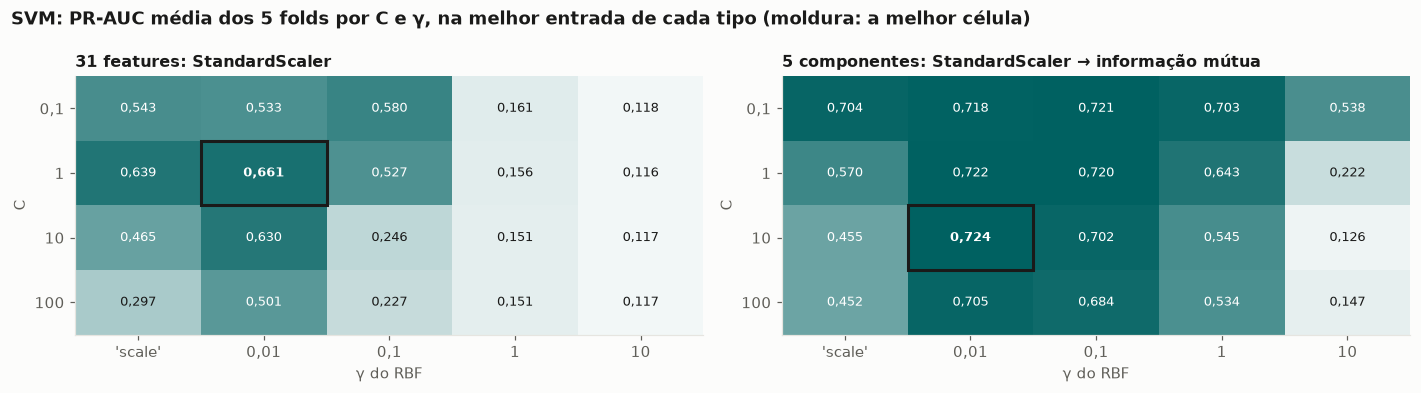

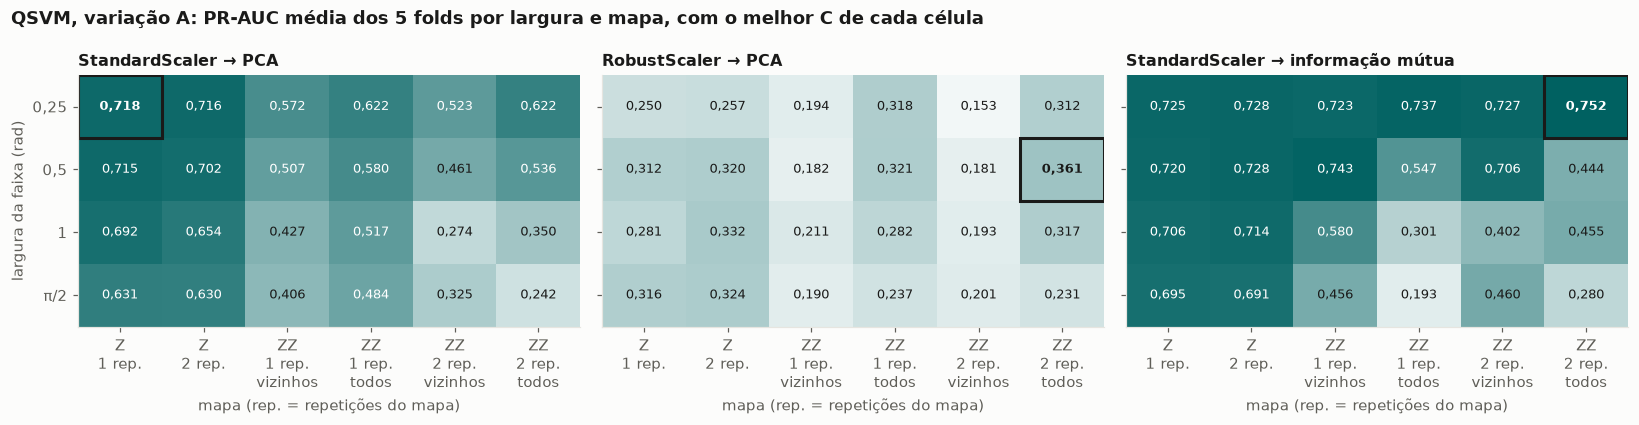

,constante 1,constante 3,constante 5
StandardScaler,0.461,0.644,0.686
RobustScaler,0.548,0.602,0.642


In [62]:
SCORE_COLORMAP = LinearSegmentedColormap.from_list("ciano", ["#f2f7f7", HIGHLIGHT_COLOR])
QSVM_MAP_COLUMNS: list[tuple[str, int, str | None]] = [
    ("z", 1, None), ("z", 2, None), ("zz", 1, "linear"), ("zz", 1, "full"), ("zz", 2, "linear"), ("zz", 2, "full"),
]
QUANTUM_ADABOOST_MAP_COLUMNS: list[tuple[str, int | None, str | None]] = [*QSVM_MAP_COLUMNS, ("ry", None, None)]
ANGLE_PATHS: list[tuple[str, str]] = [("standard", "pca"), ("robust", "pca"), ("standard", "mutual_info")]


def map_label(feature_map: str, reps: int | None, entanglement: str | None) -> str:
    """Rótulo curto de um mapa para eixo de gráfico (rep. = repetições do mapa)."""
    label = VALUE_LABELS[feature_map]
    if reps is not None:
        label += f"\n{reps} rep."
    if entanglement is not None:
        label += "\nvizinhos" if entanglement == "linear" else "\ntodos"
    return label


def matches(frame: pd.DataFrame, values: dict[str, object]) -> pd.Series:
    """Máscara das linhas com os valores dados; um valor vazio casa com campo vazio."""
    mask = pd.Series(True, index=frame.index)
    for column, value in values.items():
        mask &= frame[column].isna() if not is_set(value) else frame[column].eq(value)
    return mask


def plot_score_heatmap(ax: plt.Axes, table: pd.DataFrame, title: str, vmin: float, vmax: float) -> None:
    """Mapa de calor da PR-AUC média, com o valor em cada célula e a melhor emoldurada."""
    values = table.to_numpy(dtype=float)
    ax.imshow(values, cmap=SCORE_COLORMAP, vmin=vmin, vmax=vmax, aspect="auto")
    best_row, best_column = np.unravel_index(np.nanargmax(values), values.shape)
    for (row, column), value in np.ndenumerate(values):
        if np.isnan(value):
            ax.text(column, row, "falhou", ha="center", va="center", color="#5f5e58", fontsize=8)
            continue
        dark_cell = (value - vmin) / (vmax - vmin) > 0.55
        ax.text(column, row, f"{value:.3f}".replace(".", ","), ha="center", va="center", fontsize=8.5,
                color="#ffffff" if dark_cell else "#1a1a19",
                fontweight="bold" if (row, column) == (best_row, best_column) else "normal")
    ax.add_patch(Rectangle((best_column - 0.5, best_row - 0.5), 1, 1, fill=False, edgecolor="#1a1a19", linewidth=2))
    ax.set_xticks(range(table.shape[1]), table.columns)
    ax.set_yticks(range(table.shape[0]), table.index)
    ax.grid(False)
    ax.set_title(title, fontsize=10.5)


def angle_heatmap_table(summary: pd.DataFrame, scaler: str, reducer: str, map_columns: list[tuple[str, int | None, str | None]]) -> pd.DataFrame:
    """Largura × mapa num caminho até os componentes: a melhor PR-AUC média entre as configurações do modelo."""
    path_rows = summary[matches(summary, {"kind": "angle", "scaler": scaler, "reducer": reducer})]
    table = pd.DataFrame(index=[decimal_comma(width) for width in config.ANGLE_RANGE_WIDTH_GRID], dtype=float)
    for feature_map, reps, entanglement in map_columns:
        cell_rows = path_rows[matches(path_rows, {"feature_map": feature_map, "feature_map_reps": reps, "entanglement": entanglement})]
        # max com NaN: uma configuração que falhou não esconde as outras do mesmo mapa e largura
        best_by_width = cell_rows.groupby("range_width")["pr_auc_mean"].max()
        table[map_label(feature_map, reps, entanglement)] = [best_by_width.get(width, np.nan) for width in config.ANGLE_RANGE_WIDTH_GRID]
    table.index.name = "largura da faixa (rad)"
    return table


# SVM: C × γ na melhor entrada de cada tipo
svm_summary = grid_summaries["svm"]
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
svm_tables = {}
for ax, kind in zip(axes, ("all_features", "angle_components")):
    best = svm_summary[svm_summary["kind"] == kind].iloc[0]
    input_rows = svm_summary[matches(svm_summary, {column: best[column] for column in INPUT_COLUMNS})]
    table = input_rows.pivot_table(index="C", columns="gamma", values="pr_auc_mean", aggfunc="max", sort=False)
    table = table.reindex(index=list(config.SVM_C_GRID), columns=list(config.SVM_GAMMA_GRID))
    table.index = [decimal_comma(value) for value in table.index]
    table.columns = [label_value(value) for value in table.columns]
    svm_tables[kind] = table
vmin = min(table.min().min() for table in svm_tables.values())
vmax = max(table.max().max() for table in svm_tables.values())
for ax, (kind, table) in zip(axes, svm_tables.items()):
    best = svm_summary[svm_summary["kind"] == kind].iloc[0]
    panel_title = describe_configuration(best)["entrada"].replace(" (5 componentes)", "").replace("31 features, ", "")
    plot_score_heatmap(ax, table, f"{VALUE_LABELS[kind]}: {panel_title}", vmin, vmax)
    ax.set(xlabel="γ do RBF", ylabel="C")
fig.suptitle("SVM: PR-AUC média dos 5 folds por C e γ, na melhor entrada de cada tipo (moldura: a melhor célula)",
             x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

# QSVM, variação A: largura × mapa em cada caminho até os componentes (melhor C de cada célula)
qsvm_summary = grid_summaries["qsvm"]
qsvm_tables = {path: angle_heatmap_table(qsvm_summary, *path, QSVM_MAP_COLUMNS) for path in ANGLE_PATHS}
vmin = min(table.min().min() for table in qsvm_tables.values())
vmax = max(table.max().max() for table in qsvm_tables.values())
fig, axes = plt.subplots(1, 3, figsize=(15, 3.9), sharey=True)
for ax, ((scaler, reducer), table) in zip(axes, qsvm_tables.items()):
    plot_score_heatmap(ax, table, f"{SCALER_NAMES[scaler]} → {REDUCER_NAMES[reducer]}", vmin, vmax)
    ax.set_xlabel("mapa (rep. = repetições do mapa)")
axes[0].set_ylabel("largura da faixa (rad)")
fig.suptitle("QSVM, variação A: PR-AUC média dos 5 folds por largura e mapa, com o melhor C de cada célula",
             x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

# QSVM, variação B: scaler × constante (melhor C de cada célula)
amplitude_rows = qsvm_summary[qsvm_summary["kind"] == "amplitude"]
qsvm_amplitude_table = amplitude_rows.pivot_table(index="scaler", columns="padding_value", values="pr_auc_mean", aggfunc="max", sort=False)
qsvm_amplitude_table = qsvm_amplitude_table.sort_index(axis=1)
qsvm_amplitude_table.index = [SCALER_NAMES[scaler] for scaler in qsvm_amplitude_table.index]
qsvm_amplitude_table.columns = [f"constante {decimal_comma(value)}" for value in qsvm_amplitude_table.columns]
display(
    qsvm_amplitude_table.style.format("{:.3f}").apply(highlight_table_maximum, axis=None).set_caption(
        "QSVM, variação B: PR-AUC média dos 5 folds por scaler e constante, com o melhor C de cada célula. Destaque: a maior."
    )
)


**Leitura da 6.2**

Todos os números são PR-AUC média dos 5 folds do treino, na proporção real de fraudes; o desvio é entre os folds. A
tabela "o que cada decisão muda" compara, para cada decisão, a melhor combinação que usa a melhor opção com a melhor
que usa a pior, deixando as outras decisões livres; a última coluna diz quais opções aparecem entre as combinações
empatadas com a escolhida (ela incluída).

**SVM**
1. **A melhor combinação usa os 5 componentes da informação mútua:** StandardScaler → informação mútua, C = 10,
   γ = 0,01, com 0,724 ± 0,061. Com as 31 features, a melhor fica em 0,661 ± 0,093 (C = 1, γ = 0,01), na 19ª posição.
2. **Com os 5 componentes, o caminho é a decisão que mais muda o resultado:** 0,724 com a informação mútua contra 0,406
   com RobustScaler → PCA (diferença de 0,318); o γ muda 0,144 e o C, 0,011. **Com as 31 features, é o γ:** 0,661 com
   γ = 0,01 contra 0,118 com γ = 10 (diferença de 0,544; no mapa de calor, γ = 1 ou 10 fica entre 0,116 e 0,161 em
   qualquer C).
3. **Por que o γ alto vai tão mal é hipótese, e não resultado:** com γ alto, a similaridade do RBF cai depressa com a
   distância, e cada transação passa a se parecer só com as do treino mais próximas dela. O notebook não mede isso; é a
   leitura usual do γ (sklearn 1.4.6.1).
4. **O que o grid não separa.** Entre as 18 combinações de 5 componentes empatadas com a escolhida aparecem os caminhos
   Standard → PCA e informação mútua, os quatro valores de C e quatro dos cinco γ. O que ele descarta com clareza é o
   RobustScaler → PCA e o γ = 10.

**QSVM**
5. **A melhor da variação A** usa StandardScaler → informação mútua, faixa [0; 0,25], mapa ZZ com 2 repetições e
   emaranhamento entre todos os pares, C = 0,1: 0,752 ± 0,074.
6. **O caminho é, de longe, o que mais pesa:** 0,752 com a informação mútua contra 0,361 com RobustScaler → PCA
   (diferença de 0,392). A largura muda 0,058; o C, 0,041; o mapa, 0,028.
7. **O grid descarta o RobustScaler → PCA, e quase nada mais.** Entre as 45 combinações empatadas com a escolhida
   aparecem os caminhos Standard → PCA e informação mútua, as quatro larguras, os seis mapas e os quatro valores de C:
   dentro desses dois caminhos, a validação cruzada não distingue largura, mapa e C além do desvio entre folds.
8. **No mapa de calor, faixas estreitas vão melhor, principalmente no ZZ.** No caminho da informação mútua, o ZZ com 2
   repetições e todos os pares vai de 0,752 em 0,25 rad a 0,280 em π/2. A configuração padrão da Seção 5
   (StandardScaler → PCA, π/2, ZZ com 2 repetições e vizinhos) aparece no mapa com 0,325, e é por isso que o QSVM tinha
   ficado tão atrás na Seção 5.
9. **O emaranhamento não se destaca.** O mapa Z (sem emaranhamento) é o mais estável entre as larguras: de 0,630 a
   0,718 com StandardScaler → PCA e de 0,691 a 0,728 com a informação mútua; o melhor Z fica a 0,024 do melhor ZZ.
10. **Na variação B, a constante muda 0,138** (0,686 com 5 contra 0,548 com 1, a mesma ordem do alinhamento da Seção
    4.8) e **o C muda 0,234** (0,686 com C = 1 contra 0,452 com C = 100). Entre as 6 empatadas aparecem as constantes 3
    e 5 e os dois scalers.
11. **A variação A fica à frente da B nos 5 folds** (tabela de diferenças fold a fold, na 6.4), com 0,752 contra 0,686
    na média. Mas A foi escolhida entre 288 combinações e B entre 24, e a melhor de mais combinações tende a ser mais
    otimista (6.4).

**Ressalvas.**
- O γ escolhido nos dois SVM (0,01) é o menor valor numérico do grid; no QSVM A, o C (0,1) e a largura (0,25) também
  estão no menor valor, e na variação B a constante (5) está no maior. A 6.4 junta essas bordas.
- O alinhamento kernel-alvo da Seção 4.7 apontava π/2 como a largura de maior média no ZZ com informação mútua; a
  validação cruzada escolheu 0,25. Lá, as quatro larguras do grid ficavam a menos de um desvio umas das outras, e o
  KTA serviu para delimitar a região, e não para escolher.

### 6.3 O grid do par AdaBoost × Quantum AdaBoost

> **Papel no experimento:** **escolhe a configuração** de cada modelo, pela validação cruzada no treino. Nenhuma linha da validação ou do teste entra aqui.

Os dois são o mesmo `AdaBoostClassifier`, com o mesmo grid de modelo (teto de rodadas e taxa de aprendizado); só o
classificador fraco muda (5.1). O que cada um busca:
- **AdaBoost** (entrada × modelo): as 31 features (um scaler só: o *stump* ignora a escala) ou os 5 componentes pelos
  três caminhos, × taxa de aprendizado × teto de rodadas.
- **Quantum AdaBoost** (entrada × codificação × modelo): a variação A, agora com a RY entre os mapas (sete mapas), e a
  variação B, × taxa de aprendizado × repetições do ansatz × teto de rodadas. As avaliações do COBYLA ficam fixas em
  60 (5.2).

**O que esta subseção acrescenta à 6.2:**
- **Classificadores mantidos.** O teto é só um máximo (5.5.1); as tabelas mostram, para cada combinação, quantos
  classificadores fracos ficaram nos 5 folds.
- **Combinações que falharam.** Quando o primeiro classificador fraco já erra metade do peso, o `AdaBoostClassifier`
  não ajusta nada e acusa erro. É o que se espera nas codificações que ficam no acaso (a fase pura em 0,25 e 0,5 rad,
  5.3.1). O grid registra a combinação como falha e segue, e ela vai para o fim da tabela.
- **O efeito da taxa de aprendizado na parada** (ponto ⑤): quantos classificadores ficam com cada taxa, e como a
  PR-AUC muda com o teto.

In [63]:
for name in ("adaboost", "quantum_adaboost"):
    run_model_grid(name)
for name in ("adaboost", "quantum_adaboost"):
    show_grid_tables(name)

# Onde estão as falhas (o primeiro classificador fraco já pior que o acaso)
quantum_adaboost_summary = grid_summaries["quantum_adaboost"]
failed = quantum_adaboost_summary[quantum_adaboost_summary["failed_folds"] > 0]
if failed.empty:
    print("Quantum AdaBoost: nenhuma combinação falhou.")
else:
    # A falha acontece no primeiro classificador fraco, que não depende da taxa nem do teto (a primeira rodada usa pesos
    # iguais e a mesma semente): cada codificação que falha, falha nas 3 taxas × 4 tetos de uma profundidade do ansatz
    failure_table = (
        failed.assign(
            mapa=[map_text(row) for _, row in failed.iterrows()], largura=failed["range_width"].map(decimal_comma),
            caminho=[input_path(row) for _, row in failed.iterrows()], ansatz=failed["ansatz_reps"].map(lambda reps: repetitions(int(reps))),
        )
        .groupby(["mapa", "largura", "caminho", "ansatz"]).size().rename("combinações com falha").to_frame()
    )
    display(failure_table.style.set_caption(
        f"Quantum AdaBoost: as {len(failed)} combinações (de {len(quantum_adaboost_summary)}) em que o primeiro "
        "classificador fraco errou metade do peso ou mais em algum fold, por mapa (rep. = repetições do mapa), largura, "
        "caminho até os componentes e repetições do ansatz"
    ))

# A projeção do piloto (6.1.1) contra o tempo medido de cada grid (o da execução original, quando vem do cache)
timing_check = pilot_table[["projeção do grid (min)"]].copy()
timing_check["medido (min)"] = [grid_results[name].wall_seconds / 60 for name in MODEL_ORDER]
timing_check["medido ÷ projeção"] = timing_check["medido (min)"] / timing_check["projeção do grid (min)"]
timing_check.loc["total"] = [timing_check["projeção do grid (min)"].sum(), timing_check["medido (min)"].sum(), np.nan]
timing_check.loc["total", "medido ÷ projeção"] = timing_check.loc["total", "medido (min)"] / timing_check.loc["total", "projeção do grid (min)"]
display(
    timing_check.style.format("{:.1f}", subset=["projeção do grid (min)", "medido (min)"]).format("{:.2f}", subset=["medido ÷ projeção"])
    .apply(highlight_best, subset=["medido ÷ projeção"]).set_caption(
        f"O piloto da 6.1.1 contra o tempo de cada grid ({config.N_JOBS} processos). Acima de 1, a projeção errou para menos. "
        "Destaque: o maior erro."
    )
)


AdaBoost: 48 combinações × 5 folds, 0 com falha; lido do cache em disco, calculado antes com o mesmo código, os mesmos dados e o mesmo grid; 0.1 min com 12 processos


Quantum AdaBoost: 2160 combinações × 5 folds, 108 com falha; lido do cache em disco, calculado antes com o mesmo código, os mesmos dados e o mesmo grid; 64.7 min com 12 processos


,,entrada,codificação,modelo,PR-AUC (média dos folds),PR-AUC (desvio entre folds),ROC-AUC (média),classificadores mantidos (mín–máx nos folds),empatadas com ela (ela incluída)
entrada ou variação,posição no grid,,,,,,,,
31 features,1,"31 features, StandardScaler",—,"teto de 100 rodadas, taxa 0,1",0.710,0.054,0.979,100–100,7
5 componentes,3,StandardScaler → informação mútua (5 componentes),—,"teto de 100 rodadas, taxa 0,1",0.688,0.062,0.978,100–100,10


,entrada,codificação,modelo,PR-AUC (média dos folds),PR-AUC (desvio entre folds),ROC-AUC (média),classificadores mantidos (mín–máx nos folds)
posição no grid,,,,,,,
1,"31 features, StandardScaler",—,"teto de 100 rodadas, taxa 0,1",0.710,0.054,0.979,100–100
2,"31 features, StandardScaler",—,"teto de 50 rodadas, taxa 0,1",0.697,0.075,0.977,50–50
3,StandardScaler → informação mútua (5 componentes),—,"teto de 100 rodadas, taxa 0,1",0.688,0.062,0.978,100–100
4,StandardScaler → informação mútua (5 componentes),—,"teto de 50 rodadas, taxa 0,1",0.688,0.069,0.977,50–50
5,StandardScaler → informação mútua (5 componentes),—,"teto de 100 rodadas, taxa 0,5",0.687,0.085,0.976,100–100


,,entrada,codificação,modelo,PR-AUC (média dos folds),PR-AUC (desvio entre folds),ROC-AUC (média),classificadores mantidos (mín–máx nos folds),empatadas com ela (ela incluída)
entrada ou variação,posição no grid,,,,,,,,
A (ângulo),1,StandardScaler → informação mútua (5 componentes),"faixa [0; 0,25], mapa ZZ, 1 repetição, todos os pares","teto de 100 rodadas, taxa 0,1, ansatz com 2 repetições",0.745,0.089,0.979,37–81,88
B (amplitude),73,"31 features, StandardScaler",constante 5,"teto de 100 rodadas, taxa 0,1, ansatz com 2 repetições",0.661,0.059,0.976,100–100,12


,entrada,codificação,modelo,PR-AUC (média dos folds),PR-AUC (desvio entre folds),ROC-AUC (média),classificadores mantidos (mín–máx nos folds)
posição no grid,,,,,,,
1,StandardScaler → informação mútua (5 componentes),"faixa [0; 0,25], mapa ZZ, 1 repetição, todos os pares","teto de 100 rodadas, taxa 0,1, ansatz com 2 repetições",0.745,0.089,0.979,37–81
2,StandardScaler → informação mútua (5 componentes),"faixa [0; 0,25], mapa ZZ, 1 repetição, todos os pares","teto de 50 rodadas, taxa 0,1, ansatz com 2 repetições",0.736,0.093,0.978,37–50
3,StandardScaler → informação mútua (5 componentes),"faixa [0; 0,5], mapa Z, 2 repetições","teto de 50 rodadas, taxa 0,1, ansatz com 2 repetições",0.718,0.055,0.979,42–50
4,StandardScaler → informação mútua (5 componentes),"faixa [0; 0,5], mapa Z, 2 repetições","teto de 100 rodadas, taxa 0,1, ansatz com 2 repetições",0.717,0.055,0.979,42–63
5,StandardScaler → informação mútua (5 componentes),"faixa [0; 0,25], mapa ZZ, 1 repetição, todos os pares","teto de 25 rodadas, taxa 0,1, ansatz com 2 repetições",0.705,0.082,0.974,25–25


,projeção do grid (min),medido (min),medido ÷ projeção
modelo,,,
SVM,1.1,1.0,0.94
QSVM,12.3,14.1,1.15
AdaBoost,0.1,0.1,1.31
Quantum AdaBoost,69.1,64.7,0.94
total,82.5,79.9,0.97


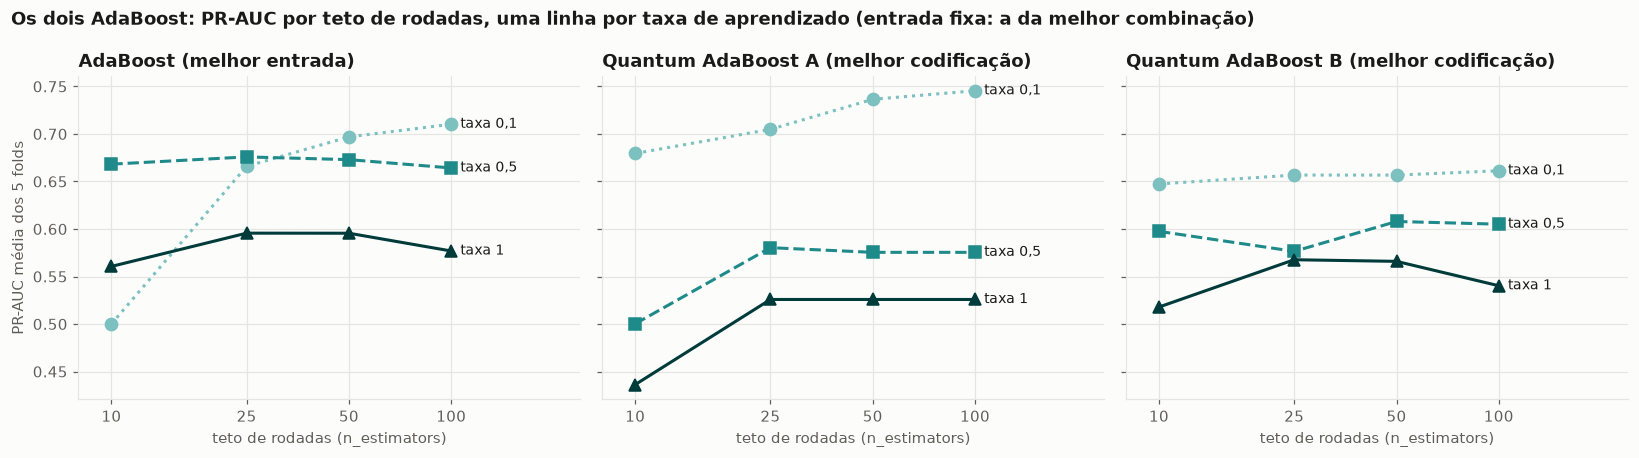

In [64]:
RATE_COLORS: dict[float, str] = dict(zip(config.BOOSTING_LEARNING_RATE_GRID, ("#7cc0c0", "#1f8a8a", "#003b3b")))
RATE_STYLES: dict[float, tuple[str, str]] = dict(zip(config.BOOSTING_LEARNING_RATE_GRID, (("o", ":"), ("s", "--"), ("^", "-"))))
ceiling = max(config.BOOSTING_N_ESTIMATORS_GRID)

# Classificadores mantidos com o maior teto, em cada fold de cada combinação que não falhou
kept_rows = []
for name in ("adaboost", "quantum_adaboost"):
    folds_at_ceiling = grid_results[name].fold_scores
    folds_at_ceiling = folds_at_ceiling[(folds_at_ceiling["n_estimators"] == ceiling) & ~folds_at_ceiling["failed"].astype(bool)]
    group_columns = ["learning_rate"] + (["ansatz_reps"] if name == "quantum_adaboost" else [])
    for keys, group in folds_at_ceiling.groupby(group_columns):
        keys = keys if isinstance(keys, tuple) else (keys,)
        kept_rows.append({
            "modelo": MODEL_LABELS[name],
            "taxa de aprendizado": decimal_comma(keys[0]),
            "repetições do ansatz": int(keys[1]) if len(keys) > 1 else "—",
            "ajustes (combinação × fold)": len(group),
            "mantidos: mínimo": int(group["kept_estimators"].min()),
            "mantidos: mediana": float(group["kept_estimators"].median()),
            "mantidos: máximo": int(group["kept_estimators"].max()),
            f"% que chegou às {ceiling} rodadas": 100 * float((group["kept_estimators"] == ceiling).mean()),
        })
kept_table = pd.DataFrame(kept_rows).set_index(["modelo", "taxa de aprendizado", "repetições do ansatz"])
display(
    kept_table.style.format("{:.0f}").format("{:.1f}", subset=[f"% que chegou às {ceiling} rodadas"])
    .apply(highlight_best, subset=[f"% que chegou às {ceiling} rodadas"]).set_caption(
        f"Classificadores fracos mantidos com o teto de {ceiling} rodadas, em todas as combinações e folds que não falharam. "
        "Destaque: a maior fração que chegou ao teto."
    )
)


def stage_curve(summary: pd.DataFrame, best: pd.Series) -> pd.DataFrame:
    """PR-AUC média por teto (linhas) e taxa (colunas), com a entrada e as repetições do ansatz da melhor combinação."""
    fixed = {column: best[column] for column in INPUT_COLUMNS}
    if best["family"] == "quantum_adaboost":
        fixed["ansatz_reps"] = best["ansatz_reps"]
    rows = summary[matches(summary, fixed)]
    curves = rows.pivot_table(index="n_estimators", columns="learning_rate", values="pr_auc_mean", aggfunc="max")
    # Em ordem crescente de teto: a linha liga os tetos na ordem, e o rótulo fica na ponta direita (o maior teto)
    return curves.sort_index().sort_index(axis=1)


curve_panels = {
    "AdaBoost (melhor entrada)": stage_curve(grid_summaries["adaboost"], grid_summaries["adaboost"].iloc[0]),
    "Quantum AdaBoost A (melhor codificação)": stage_curve(
        quantum_adaboost_summary, quantum_adaboost_summary[quantum_adaboost_summary["kind"] == "angle"].iloc[0]
    ),
    "Quantum AdaBoost B (melhor codificação)": stage_curve(
        quantum_adaboost_summary, quantum_adaboost_summary[quantum_adaboost_summary["kind"] == "amplitude"].iloc[0]
    ),
}
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
for ax, (title, curves) in zip(axes, curve_panels.items()):
    for rate in curves.columns:
        marker, linestyle = RATE_STYLES[rate]
        ax.plot(curves.index, curves[rate], marker=marker, linestyle=linestyle, color=RATE_COLORS[rate], markersize=8)
        ax.annotate(f"taxa {decimal_comma(rate)}", (curves.index[-1], curves[rate].iloc[-1]), xytext=(6, 0),
                    textcoords="offset points", va="center", fontsize=9, color="#1a1a19")
    ax.set(title=title, xlabel="teto de rodadas (n_estimators)", xscale="log", xlim=(8, ceiling * 2.4))
    ax.set_xticks(list(config.BOOSTING_N_ESTIMATORS_GRID), [str(stage) for stage in config.BOOSTING_N_ESTIMATORS_GRID])
    ax.minorticks_off()
axes[0].set_ylabel("PR-AUC média dos 5 folds")
fig.suptitle("Os dois AdaBoost: PR-AUC por teto de rodadas, uma linha por taxa de aprendizado (entrada fixa: a da melhor combinação)",
             x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()
display(
    pd.concat({title: curves.rename(columns=decimal_comma) for title, curves in curve_panels.items()}, axis=1)
    .rename_axis(index="teto de rodadas", columns=["", "taxa de aprendizado"]).style.format("{:.3f}").set_caption(
        "Os valores do gráfico: PR-AUC média dos 5 folds por teto de rodadas e taxa de aprendizado"
    )
)


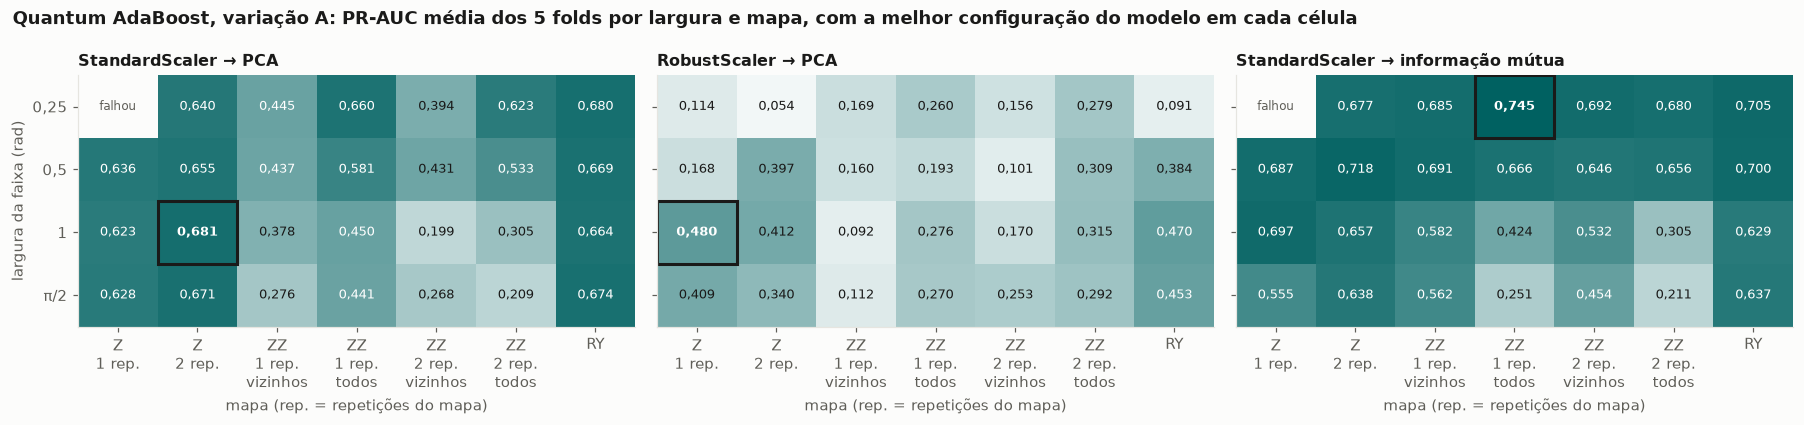

,constante 1,constante 3,constante 5
StandardScaler,0.270,0.607,0.661
RobustScaler,0.470,0.591,0.632


In [65]:
# Quantum AdaBoost, variação A: largura × mapa em cada caminho (melhor configuração do modelo em cada célula)
quantum_adaboost_tables = {
    path: angle_heatmap_table(quantum_adaboost_summary, *path, QUANTUM_ADABOOST_MAP_COLUMNS) for path in ANGLE_PATHS
}
vmin = np.nanmin([np.nanmin(table.to_numpy(dtype=float)) for table in quantum_adaboost_tables.values()])
vmax = np.nanmax([np.nanmax(table.to_numpy(dtype=float)) for table in quantum_adaboost_tables.values()])
fig, axes = plt.subplots(1, 3, figsize=(16.5, 3.9), sharey=True)
for ax, ((scaler, reducer), table) in zip(axes, quantum_adaboost_tables.items()):
    plot_score_heatmap(ax, table, f"{SCALER_NAMES[scaler]} → {REDUCER_NAMES[reducer]}", vmin, vmax)
    ax.set_xlabel("mapa (rep. = repetições do mapa)")
axes[0].set_ylabel("largura da faixa (rad)")
fig.suptitle("Quantum AdaBoost, variação A: PR-AUC média dos 5 folds por largura e mapa, com a melhor configuração do modelo em cada célula",
             x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

amplitude_rows = quantum_adaboost_summary[quantum_adaboost_summary["kind"] == "amplitude"]
quantum_adaboost_amplitude_table = amplitude_rows.pivot_table(index="scaler", columns="padding_value", values="pr_auc_mean", aggfunc="max", sort=False)
quantum_adaboost_amplitude_table = quantum_adaboost_amplitude_table.sort_index(axis=1)
quantum_adaboost_amplitude_table.index = [SCALER_NAMES[scaler] for scaler in quantum_adaboost_amplitude_table.index]
quantum_adaboost_amplitude_table.columns = [f"constante {decimal_comma(value)}" for value in quantum_adaboost_amplitude_table.columns]
display(
    quantum_adaboost_amplitude_table.style.format("{:.3f}").apply(highlight_table_maximum, axis=None).set_caption(
        "Quantum AdaBoost, variação B: PR-AUC média dos 5 folds por scaler e constante, com a melhor configuração do modelo "
        "em cada célula. Destaque: a maior."
    )
)


**Leitura da 6.3**

Todos os números são PR-AUC média dos 5 folds do treino, na proporção real de fraudes.

**AdaBoost**
1. **O melhor usa as 31 features, teto de 100 rodadas e taxa 0,1:** 0,710 ± 0,054. Com os 5 componentes, o melhor
   (informação mútua, mesmo teto e mesma taxa) fica em 0,688 ± 0,062.
2. **O que cada decisão muda.** Com as 31 features, a taxa muda 0,115 (0,710 com 0,1 contra 0,596 com 1) e o teto,
   0,042. Com os 5 componentes, o caminho muda 0,211 (0,688 com a informação mútua contra 0,477 com Standard → PCA), e a
   taxa só 0,012.
3. **Taxa baixa precisa de mais rodadas** (gráfico das curvas): com taxa 0,1, a PR-AUC sobe de 0,500 com 10 rodadas
   para 0,710 com 100; com taxa 1, fica entre 0,561 e 0,596 em qualquer teto. É o compromisso entre taxa e número de
   rodadas que a documentação do `AdaBoostClassifier` descreve.
4. **O teto limita o AdaBoost clássico:** os 60 ajustes com teto 100 usaram as 100 rodadas, e a curva com taxa 0,1
   ainda sobe de 50 para 100 rodadas (0,697 → 0,710).

**Quantum AdaBoost**
5. **O melhor da variação A** usa StandardScaler → informação mútua, faixa [0; 0,25], mapa ZZ com 1 repetição e
   emaranhamento entre todos os pares, taxa 0,1 e ansatz com 2 repetições: 0,745 ± 0,089. **O boosting parou antes do
   teto em todos os 5 folds** (de 37 a 81 classificadores mantidos): o teto de 100 não limitou nada, e qualquer teto a
   partir de 81 daria o mesmo modelo. A subida de 50 para 100 rodadas na curva (0,736 → 0,745) vem dos folds que
   passaram de 50 classificadores.
6. **O melhor da variação B** usa a constante 5 com StandardScaler, teto de 100, taxa 0,1 e ansatz com 2 repetições:
   0,661 ± 0,059 (73ª posição do grid), com as 100 rodadas em todos os folds. A constante 1, a padrão da Seção 5, fica
   em 0,270 com StandardScaler.
7. **Na variação A, fora o caminho, nenhuma decisão se destaca.** O caminho muda 0,266 (0,745 com a informação mútua
   contra 0,480 com RobustScaler → PCA); a taxa e a largura mudam 0,071, o mapa 0,065, o ansatz 0,063 e o teto 0,058,
   todos abaixo do desvio entre folds da escolhida (0,089). Entre as 88 combinações empatadas com ela aparecem os dois
   caminhos com StandardScaler, as quatro larguras, os sete mapas, os quatro tetos, as três taxas e as duas
   profundidades do ansatz: a escolha fina da variação A não é determinada pela validação cruzada.
8. **Na variação B, a constante é o que mais muda** (0,661 com 5 contra 0,470 com 1, diferença de 0,192), seguida da
   taxa (0,094).
9. **A taxa na codificação escolhida.** Com a codificação da escolhida, a taxa 0,1 fica entre 0,679 e 0,745 em todos
   os tetos, a 0,5 entre 0,500 e 0,580 e a 1 entre 0,436 e 0,526. A comparação favorece a taxa 0,1 por construção: a
   codificação foi escolhida junto com ela. No grid inteiro, a diferença entre a melhor com cada taxa é a do item 7
   (0,071).
10. **Ponto ⑤: a taxa menor adia a parada, mas não a elimina** (tabela dos classificadores mantidos). Com taxa 0,1, a
    mediana é de 48 classificadores (ansatz com 1 repetição) e 58 (com 2), e chegam às 100 rodadas 11,8% e 22,1% dos
    ajustes; com taxa 1, a mediana cai para 12 e 17, e só 0,5% chegam ao teto. Em todas as taxas há ajustes que ficam
    com 1 ou 2 classificadores.
11. **As 108 combinações que falharam (5,0% do grid)** são, na maioria, a fase pura (mapa Z com 1 repetição) em
    faixas estreitas, como a 5.3.1 previa; há também o mapa Z com 2 repetições e a RY em 0,25 rad com RobustScaler →
    PCA, e a fase pura em π/2 com RobustScaler → PCA. Cada linha da tabela tem 12 combinações, as 3 taxas × 4 tetos de
    uma profundidade do ansatz: a falha acontece no primeiro classificador fraco, que não depende da taxa nem do teto
    (a primeira rodada usa pesos iguais e a mesma semente).
12. **O mapa de calor da variação A** repete o padrão do QSVM: o caminho RobustScaler → PCA é ruim em quase tudo (no
    máximo 0,480). A RY é estável entre as larguras com StandardScaler → PCA (de 0,664 a 0,680) e com a informação
    mútua (de 0,629 a 0,705), como a 5.3.1 indicava, mas não é a melhor.

**O tempo.** Os quatro grids levaram 79,9 min com 12 processos (1,0; 14,1; 0,1 e 64,7 min). A tabela de comparação
mostra que a projeção do piloto não é uma garantia: num grid ela pode ficar acima e, em outro, abaixo do tempo medido.
O piloto roda poucas tarefas ao mesmo tempo, e o grid ocupa os 12 núcleos lógicos, que são 6 físicos (NC16).

### 6.4 O que a validação cruzada escolheu

> **Papel no experimento:** **escolhe a configuração** de cada modelo. Reúne as escolhas das 6.2 e 6.3, separadas por tipo de decisão, e grava os resultados em `artifacts/results/`. São estas configurações que a Seção 7 avalia na validação.

**Os pipelines que seguem para a Seção 7**, os mesmos da Seção 5, agora ajustados: o SVM e o AdaBoost com as 31
features e com os 5 componentes, e as variações A e B de cada quântico. Pelo ponto ② do PLAN, entra também, para cada
clássico, a melhor configuração com o **mesmo caminho até os componentes** (scaler e redutor) que a variação A do
quântico do par escolheu, para que a comparação *like-for-like* tenha a entrada idêntica. Quando ela coincide com a
melhor configuração de 5 componentes, a tabela diz.

**Colunas da primeira tabela.**
- **Padrão da Seção 5 e ganho do ajuste:** os padrões da Seção 5 estão dentro de cada grid, então a mesma validação
  cruzada mede quanto o ajuste rendeu em cada pipeline. O ganho dos quânticos tende a parecer maior porque o padrão
  deles era fraco (CC16): o que se compara entre modelos é a PR-AUC escolhida, e não o ganho.
- **Combinações disputadas:** quantas combinações da mesma entrada (ou variação) a escolhida venceu. Quanto mais
  combinações, mais a melhor delas tende a ser otimista, porque o acaso de folds favoráveis tem mais chances de
  aparecer em alguma.
- **Empatadas:** combinações da mesma entrada a menos de 1 desvio entre folds da escolhida, ela incluída.
- **Continua a melhor sem 1 fold:** retira-se um fold, recalcula-se a média dos outros quatro para todas as combinações
  do grupo, e confere-se se a escolhida continua a melhor; de 5 tentativas, quantas. Mede se a escolha depende de um
  único fold.
- **Na borda:** dimensões numéricas em que a escolhida ficou no menor ou no maior valor do grid, do modelo e da
  codificação. O teto de rodadas só conta quando limitou o boosting (se todos os folds pararam antes, um teto maior daria
  o mesmo modelo), e a largura π/2 é marcada como limite por princípio.

**As outras duas tabelas e o gráfico.** Os folds são os mesmos para todas as combinações, então a comparação certa
entre duas escolhidas é **fold a fold**: a tabela da PR-AUC de cada fold mostra qual fold é difícil para quem, e a
tabela de diferenças mostra, dentro de cada par, a diferença em cada fold e em quantos dos 5 o primeiro fica à frente.
O gráfico mostra os mesmos valores, com o fold 1 vazado. Nenhum desses números é o desempenho esperado na validação:
cada escolhida é a melhor de muitas combinações medidas nos mesmos folds, e a melhor de muitas tende a ser otimista
(Raschka, 2018, seção 3.3). A medida sem esse viés é a da Seção 7.

,entrada,codificação,modelo,PR-AUC (média dos folds),PR-AUC (desvio entre folds),PR-AUC do padrão da Seção 5 (mesmos folds),ganho do ajuste,posição no grid,combinações disputadas,empatadas,continua a melhor sem 1 fold (de 5),na borda do grid,observação
pipeline,,,,,,,,,,,,,
"SVM, 31 features","31 features, StandardScaler",—,"C = 1, γ = 0,01",0.661,0.093,0.639,+0.022,19,40,6,4,γ (menor valor),
"SVM, 5 componentes",StandardScaler → informação mútua (5 componentes),—,"C = 10, γ = 0,01",0.724,0.061,0.633,+0.091,1,60,18,3,γ (menor valor),
"AdaBoost, 31 features","31 features, StandardScaler",—,"teto de 100 rodadas, taxa 0,1",0.710,0.054,0.596,+0.115,1,12,7,5,"taxa (menor valor), teto (maior valor)",
"AdaBoost, 5 componentes",StandardScaler → informação mútua (5 componentes),—,"teto de 100 rodadas, taxa 0,1",0.688,0.062,0.462,+0.226,3,36,10,1,"taxa (menor valor), teto (maior valor)",
QSVM A (ângulo),StandardScaler → informação mútua (5 componentes),"faixa [0; 0,25], mapa ZZ, 2 repetições, todos os pares","C = 0,1",0.752,0.074,0.325,+0.428,1,288,45,5,"C (menor valor), faixa (menor valor)",
QSVM B (amplitude),"31 features, StandardScaler",constante 5,C = 1,0.686,0.087,0.396,+0.289,44,24,6,5,constante (maior valor),
Quantum AdaBoost A (ângulo),StandardScaler → informação mútua (5 componentes),"faixa [0; 0,25], mapa ZZ, 1 repetição, todos os pares","teto de 100 rodadas, taxa 0,1, ansatz com 2 repetições",0.745,0.089,0.070,+0.676,1,2016,88,5,"taxa (menor valor), faixa (menor valor)",
Quantum AdaBoost B (amplitude),"31 features, StandardScaler",constante 5,"teto de 100 rodadas, taxa 0,1, ansatz com 2 repetições",0.661,0.059,0.034,+0.627,73,144,12,3,"taxa (menor valor), teto (maior valor), constante (maior valor)",
"SVM, 5 componentes, mesmo caminho do QSVM A",StandardScaler → informação mútua (5 componentes),—,"C = 10, γ = 0,01",0.724,0.061,0.633,+0.091,1,60,—,4,γ (menor valor),igual à anterior


,fold 1,fold 2,fold 3,fold 4,fold 5,pior fold
"SVM, 31 features",0.588,0.789,0.561,0.654,0.714,fold 3
"SVM, 5 componentes",0.648,0.795,0.692,0.710,0.776,fold 1
"AdaBoost, 31 features",0.617,0.753,0.711,0.727,0.743,fold 1
"AdaBoost, 5 componentes",0.590,0.667,0.707,0.738,0.737,fold 1
QSVM A (ângulo),0.622,0.794,0.789,0.798,0.758,fold 1
QSVM B (amplitude),0.533,0.743,0.719,0.730,0.704,fold 1
Quantum AdaBoost A (ângulo),0.592,0.800,0.811,0.773,0.752,fold 1
Quantum AdaBoost B (amplitude),0.556,0.682,0.684,0.685,0.699,fold 1
"SVM, 5 componentes, mesmo caminho do QSVM A",0.648,0.795,0.692,0.710,0.776,fold 1
"AdaBoost, 5 componentes, mesmo caminho do Quantum AdaBoost A",0.590,0.667,0.707,0.738,0.737,fold 1


,fold 1,fold 2,fold 3,fold 4,fold 5,média,folds a favor do primeiro (de 5),combinações disputadas (primeiro / segundo)
"QSVM A − SVM, 5 componentes (mesmo caminho)",-0.025,-0.002,+0.098,+0.088,-0.018,+0.028,2,288 / 60
"Quantum AdaBoost A − AdaBoost, 5 componentes (mesmo caminho)",+0.002,+0.132,+0.104,+0.035,+0.014,+0.058,5,"2,016 / 36"
"QSVM B − SVM, 31 features",-0.055,-0.046,+0.157,+0.076,-0.010,+0.025,2,24 / 40
"Quantum AdaBoost B − AdaBoost, 31 features",-0.061,-0.071,-0.028,-0.042,-0.044,-0.049,0,144 / 12
QSVM A − QSVM B,+0.090,+0.050,+0.071,+0.068,+0.054,+0.067,5,288 / 24
Quantum AdaBoost A − Quantum AdaBoost B,+0.035,+0.117,+0.128,+0.088,+0.053,+0.084,5,"2,016 / 144"


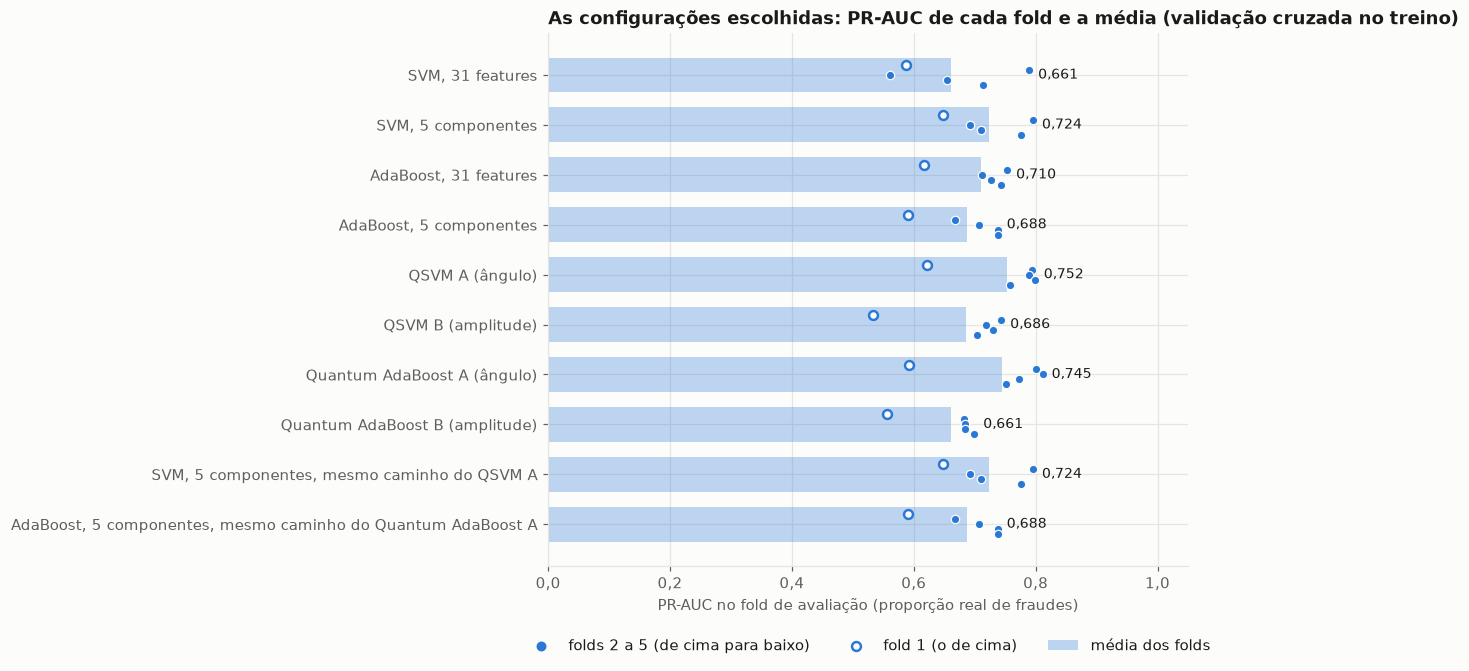

SVM: resultados gravados em artifacts\results\grid_svm.json
QSVM: resultados gravados em artifacts\results\grid_qsvm.json


AdaBoost: resultados gravados em artifacts\results\grid_adaboost.json
Quantum AdaBoost: resultados gravados em artifacts\results\grid_quantum_adaboost.json


In [66]:
SELECTIONS: dict[str, tuple[str, dict[str, object]]] = {
    "SVM, 31 features": ("svm", {"kind": "all_features"}),
    "SVM, 5 componentes": ("svm", {"kind": "angle_components"}),
    "AdaBoost, 31 features": ("adaboost", {"kind": "all_features"}),
    "AdaBoost, 5 componentes": ("adaboost", {"kind": "angle_components"}),
    "QSVM A (ângulo)": ("qsvm", {"kind": "angle"}),
    "QSVM B (amplitude)": ("qsvm", {"kind": "amplitude"}),
    "Quantum AdaBoost A (ângulo)": ("quantum_adaboost", {"kind": "angle"}),
    "Quantum AdaBoost B (amplitude)": ("quantum_adaboost", {"kind": "amplitude"}),
}
# Ponto ② do PLAN: o clássico com o mesmo caminho até os componentes que a variação A do quântico do par escolheu
LIKE_FOR_LIKE_PAIRS: dict[str, tuple[str, str]] = {
    "SVM, 5 componentes": ("svm", "QSVM A (ângulo)"),
    "AdaBoost, 5 componentes": ("adaboost", "Quantum AdaBoost A (ângulo)"),
}
# Bordas do grid: hiperparâmetros do modelo e as duas dimensões numéricas da codificação
GRID_BORDERS: dict[str, tuple[str, tuple[float, ...]]] = {
    "C": ("C", config.SVM_C_GRID),
    "gamma": ("γ", tuple(value for value in config.SVM_GAMMA_GRID if not isinstance(value, str))),
    "learning_rate": ("taxa", config.BOOSTING_LEARNING_RATE_GRID),
    "n_estimators": ("teto", tuple(float(stage) for stage in config.BOOSTING_N_ESTIMATORS_GRID)),
    "range_width": ("faixa", config.ANGLE_RANGE_WIDTH_GRID),
    "padding_value": ("constante", config.AMPLITUDE_PADDING_GRID),
}
# A única borda que vem de princípio: acima de π/2 os ângulos dão a volta (4.7.1). As outras vieram do KTA ou da escala
PRINCIPLED_BORDERS: set[tuple[str, str]] = {("range_width", "maior")}


def grid_borders(row: pd.Series) -> str:
    """Dimensões em que a combinação ficou no menor ou no maior valor do grid.

    O teto de rodadas só conta quando limitou o boosting: se todos os folds pararam antes dele, um teto maior daria
    o mesmo modelo.
    """
    flags = []
    for field, (name, grid) in GRID_BORDERS.items():
        value = row[field]
        if not is_set(value) or isinstance(value, str) or float(value) not in (min(grid), max(grid)):
            continue
        if field == "n_estimators" and is_set(row["kept_estimators_max"]) and row["kept_estimators_max"] < float(value):
            continue
        side = "menor" if float(value) == min(grid) else "maior"
        principle = ", limite por princípio" if (field, side) in PRINCIPLED_BORDERS else ""
        flags.append(f"{name} ({side} valor{principle})")
    return ", ".join(flags) if flags else "não"


# Os padrões da Seção 5 estão dentro de cada grid: a mesma validação cruzada mede quanto o ajuste rendeu
SECTION_5_DEFAULTS: dict[str, tuple[InputEncoding, ModelSettings]] = {
    "SVM, 31 features": (InputEncoding("all_features"), ModelSettings("svm")),
    "SVM, 5 componentes": (InputEncoding("angle_components"), ModelSettings("svm")),
    "AdaBoost, 31 features": (InputEncoding("all_features"), ModelSettings("adaboost")),
    "AdaBoost, 5 componentes": (InputEncoding("angle_components"), ModelSettings("adaboost")),
    "QSVM A (ângulo)": (InputEncoding("angle"), ModelSettings("qsvm")),
    "QSVM B (amplitude)": (InputEncoding("amplitude"), ModelSettings("qsvm")),
    "Quantum AdaBoost A (ângulo)": (InputEncoding("angle"), ModelSettings("quantum_adaboost")),
    "Quantum AdaBoost B (amplitude)": (InputEncoding("amplitude"), ModelSettings("quantum_adaboost")),
}
DEFAULT_SCORE: str = "PR-AUC do padrão da Seção 5 (mesmos folds)"


def section_5_default_score(label: str) -> float:
    """PR-AUC média, nos mesmos folds, da configuração padrão da Seção 5 do mesmo pipeline."""
    input_encoding, model = SECTION_5_DEFAULTS[label.split(", mesmo caminho")[0]]
    summary = grid_summaries[model.family]
    rows = summary[matches(summary, {**tuning.describe_input(input_encoding), **tuning.describe_model(model)})]
    assert len(rows) == 1, label
    return float(rows["pr_auc_mean"].iloc[0])


selected_rows: dict[str, pd.Series] = {}
selection_notes: dict[str, str] = {}
# De que grupo de combinações cada escolhida é a melhor (para medir se ela continua a melhor sem um fold)
selection_groups: dict[str, tuple[str, dict[str, object]]] = {}
for label, (name, criteria) in SELECTIONS.items():
    summary = grid_summaries[name]
    selected_rows[label] = summary[matches(summary, criteria)].iloc[0]
    selection_notes[label] = ""
    selection_groups[label] = (name, criteria)
for classical_label, (name, quantum_label) in LIKE_FOR_LIKE_PAIRS.items():
    quantum = selected_rows[quantum_label]
    criteria = {"kind": "angle_components", "scaler": quantum["scaler"], "reducer": quantum["reducer"]}
    summary = grid_summaries[name]
    row = summary[matches(summary, criteria)].iloc[0]
    same = row["rank"] == selected_rows[classical_label]["rank"]
    label = f"{classical_label}, mesmo caminho do {quantum_label.split(' (')[0]}"
    selected_rows[label] = row
    selection_notes[label] = "igual à anterior" if same else ""
    selection_groups[label] = (name, criteria)


def fold_matrix(name: str, criteria: dict[str, object]) -> tuple[pd.DataFrame, pd.DataFrame]:
    """PR-AUC de cada combinação do grupo (linhas) em cada fold (colunas), sem as que falharam, e a configuração de cada uma."""
    fold_scores = grid_results[name].fold_scores
    group = fold_scores[matches(fold_scores, criteria)].copy()
    group["combination"] = group.groupby(list(CONFIGURATION_COLUMNS), dropna=False, sort=False).ngroup()
    matrix = group.pivot_table(index="combination", columns="fold", values="pr_auc").dropna()
    return matrix, group.drop_duplicates("combination").set_index("combination")


def stays_best_without_a_fold(label: str) -> int:
    """Em quantos folds retirados (de 5) a escolhida continua a melhor do seu grupo pela média dos outros 4."""
    name, criteria = selection_groups[label]
    matrix, combinations = fold_matrix(name, criteria)
    row = selected_rows[label]
    chosen = combinations.index[matches(combinations, {column: row[column] for column in CONFIGURATION_COLUMNS})][0]
    return int(sum(matrix.drop(columns=fold).mean(axis=1).idxmax() == chosen for fold in matrix.columns))

selection_table = pd.DataFrame(
    [
        {
            "pipeline": label,
            **describe_configuration(row),
            PR_AUC_MEAN: row["pr_auc_mean"],
            "PR-AUC (desvio entre folds)": row["pr_auc_std"],
            DEFAULT_SCORE: section_5_default_score(label),
            "ganho do ajuste": row["pr_auc_mean"] - section_5_default_score(label),
            "posição no grid": int(row["rank"]),
            "combinações disputadas": int((grid_summaries[row["family"]]["kind"] == row["kind"]).sum()),
            "empatadas": tied_with_best(grid_summaries[row["family"]], grid_summaries[row["family"]]["kind"] == row["kind"])
            if not selection_notes[label] and "mesmo caminho" not in label else np.nan,
            "continua a melhor sem 1 fold (de 5)": stays_best_without_a_fold(label),
            "na borda do grid": grid_borders(row),
            "observação": selection_notes[label],
        }
        for label, row in selected_rows.items()
    ]
).set_index("pipeline")
display(
    selection_table.style.format("{:.3f}", subset=[PR_AUC_MEAN, "PR-AUC (desvio entre folds)", DEFAULT_SCORE])
    .format("{:+.3f}", subset=["ganho do ajuste"]).format(
        "{:.0f}", subset=["empatadas"], na_rep="—"
    ).set_caption(
        "O que a validação cruzada escolheu, por tipo de decisão (entrada, codificação, modelo). PR-AUC: média e desvio dos "
        f"{config.CV_N_SPLITS} folds do treino. Ganho: escolhida menos o padrão da Seção 5, nos mesmos folds. Combinações disputadas: "
        "as da mesma entrada (ou variação) no grid. Empatadas: as que ficam a menos de 1 desvio entre folds da escolhida, ela "
        "incluída. Sem 1 fold: em quantos dos 5 folds retirados ela continua a melhor do grupo. Na borda: dimensões no menor "
        "ou no maior valor do grid (o teto só conta se limitou o boosting)."
    )
)

# PR-AUC de cada fold das escolhidas: os folds são os mesmos para todas, então a comparação é fold a fold
fold_values: dict[str, np.ndarray] = {}
for label, row in selected_rows.items():
    fold_scores = grid_results[row["family"]].fold_scores
    chosen = fold_scores[matches(fold_scores, {column: row[column] for column in CONFIGURATION_COLUMNS})].sort_values("fold")
    fold_values[label] = chosen["pr_auc"].to_numpy()
    assert len(fold_values[label]) == config.CV_N_SPLITS, label
FOLD_LABELS: list[str] = [f"fold {fold + 1}" for fold in range(config.CV_N_SPLITS)]
fold_table = pd.DataFrame(fold_values, index=FOLD_LABELS).T
fold_table["pior fold"] = fold_table[FOLD_LABELS].idxmin(axis=1)


def highlight_row_minimum(row: pd.Series) -> list[str]:
    """Destaque (fundo ciano escuro, texto branco) no menor valor da linha."""
    style = f"background-color: {HIGHLIGHT_COLOR}; color: {HIGHLIGHT_TEXT_COLOR}"
    return [style if value == row.min() else "" for value in row]


display(
    fold_table.style.format("{:.3f}", subset=FOLD_LABELS).apply(highlight_row_minimum, axis=1, subset=FOLD_LABELS).set_caption(
        "PR-AUC de cada escolhida em cada fold (os mesmos folds para todas; são os valores do gráfico abaixo). "
        "Destaque: o pior fold de cada linha."
    )
)

# Diferença fold a fold: dentro de cada par (com a mesma entrada, like-for-like, e na referência de 31 features) e entre as duas
# codificações de cada quântico
PAIRED_COMPARISONS: dict[str, tuple[str, str]] = {
    "QSVM A − SVM, 5 componentes (mesmo caminho)": ("QSVM A (ângulo)", "SVM, 5 componentes, mesmo caminho do QSVM A"),
    "Quantum AdaBoost A − AdaBoost, 5 componentes (mesmo caminho)": (
        "Quantum AdaBoost A (ângulo)", "AdaBoost, 5 componentes, mesmo caminho do Quantum AdaBoost A",
    ),
    "QSVM B − SVM, 31 features": ("QSVM B (amplitude)", "SVM, 31 features"),
    "Quantum AdaBoost B − AdaBoost, 31 features": ("Quantum AdaBoost B (amplitude)", "AdaBoost, 31 features"),
    "QSVM A − QSVM B": ("QSVM A (ângulo)", "QSVM B (amplitude)"),
    "Quantum AdaBoost A − Quantum AdaBoost B": ("Quantum AdaBoost A (ângulo)", "Quantum AdaBoost B (amplitude)"),
}
paired_table = pd.DataFrame(
    {comparison: fold_values[first] - fold_values[second] for comparison, (first, second) in PAIRED_COMPARISONS.items()},
    index=FOLD_LABELS,
).T
paired_table["média"] = paired_table[FOLD_LABELS].mean(axis=1)
paired_table["folds a favor do primeiro (de 5)"] = (paired_table[FOLD_LABELS] > 0).sum(axis=1)
paired_table["combinações disputadas (primeiro / segundo)"] = [
    f"{selection_table.loc[first, 'combinações disputadas']:,} / {selection_table.loc[second, 'combinações disputadas']:,}"
    for first, second in PAIRED_COMPARISONS.values()
]
display(
    paired_table.style.format("{:+.3f}", subset=[*FOLD_LABELS, "média"]).set_caption(
        "Diferença de PR-AUC (primeiro − segundo) em cada fold: os pares clássico × quântico e as duas codificações de cada quântico. "
        "Só descreve a validação cruzada: os dois lados são o melhor de grids de tamanhos diferentes, e a comparação é a da Seção 7."
    )
)

labels = list(selected_rows)
positions = np.arange(len(labels))[::-1]
fold_offsets = np.linspace(0.2, -0.2, config.CV_N_SPLITS)  # em cada linha: fold 1 em cima, fold 5 embaixo
fig, ax = plt.subplots(figsize=(11, 6.2))
ax.barh(positions, [values.mean() for values in fold_values.values()], color=NEUTRAL_SERIES_COLOR, alpha=0.3, height=0.7,
        label="média dos folds")
for position, values in zip(positions, fold_values.values()):
    ax.scatter(values[1:], position + fold_offsets[1:], color=NEUTRAL_SERIES_COLOR, s=30, zorder=3, edgecolor="#fcfcfb", linewidth=0.8)
    ax.scatter(values[:1], position + fold_offsets[:1], facecolor="#fcfcfb", edgecolor=NEUTRAL_SERIES_COLOR, s=34, zorder=4, linewidth=1.6)
    ax.text(values.max() + 0.015, position, f"{values.mean():.3f}".replace(".", ","), va="center", fontsize=9)
ax.scatter([], [], color=NEUTRAL_SERIES_COLOR, s=30, label="folds 2 a 5 (de cima para baixo)")
ax.scatter([], [], facecolor="#fcfcfb", edgecolor=NEUTRAL_SERIES_COLOR, s=34, linewidth=1.6, label="fold 1 (o de cima)")
ax.set_yticks(positions, labels)
ax.set(xlabel="PR-AUC no fold de avaliação (proporção real de fraudes)", xlim=(0, 1.05),
       title="As configurações escolhidas: PR-AUC de cada fold e a média (validação cruzada no treino)")
ax.xaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value:.1f}".replace(".", ",")))
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.11), ncol=3)
plt.tight_layout()
plt.show()

# As configurações que seguem para a Seção 7, e os resultados gravados para conferência sem reexecutar o notebook.
# O commit sozinho não identifica o código se há mudanças não versionadas: grava-se também o hash do pacote e a lista delas
uncommitted_files = subprocess.run(
    ["git", "status", "--porcelain"], cwd=config.PROJECT_ROOT, capture_output=True, text=True, check=True
).stdout.splitlines()
selected_configurations: dict[str, tuple[InputEncoding, ModelSettings]] = {
    label: configuration_from_row(row) for label, row in selected_rows.items()
}
for name in MODEL_ORDER:
    report_path = config.RESULTS_DIR / f"grid_{name}.json"
    write_grid_report(
        report_path, grid_results[name], grid_summaries[name],
        {
            "selection": "maior PR-AUC média nos folds de avaliação (proporção real)",
            "cv": {"n_splits": config.CV_N_SPLITS, "random_state": config.RANDOM_STATE, "undersampling": "dentro de cada fold"},
            "selected": {label: row.to_dict() for label, row in selected_rows.items() if row["family"] == name},
            "split_fingerprint": dataset_split.fingerprint(),
            "commit": environment["commit"],
            "uncommitted_changes": uncommitted_files,
            "package_source_fingerprint": tuning.package_source_fingerprint(),
            "cache_key": tuning.grid_cache_key(SEARCH_SPACES[name], X_train, y_train, config.CV_N_SPLITS, config.RANDOM_STATE),
            "versions": collect_versions(),
        },
    )
    print(f"{MODEL_LABELS[name]}: resultados gravados em {report_path.relative_to(config.PROJECT_ROOT)}")


**Leitura da 6.4**

Validação cruzada de 5 folds no treino; nenhum número daqui vem da validação ou do teste.

**O que foi escolhido, por tipo de decisão.**
- **Entrada.** Os quatro modelos que usam 5 componentes escolheram o mesmo caminho, StandardScaler → informação
  mútua. Nas variações de amplitude e com as 31 features, o StandardScaler.
- **Codificação.** As duas variações A escolheram a faixa mais estreita do grid, [0; 0,25], com o mapa ZZ e
  emaranhamento entre todos os pares: 2 repetições no QSVM e 1 no Quantum AdaBoost. As duas variações B escolheram a
  constante 5, a maior do grid.
- **Modelo.** Os SVM escolheram γ = 0,01 (C = 1 com as 31 features e C = 10 com os 5 componentes); o QSVM A, C = 0,1; o
  QSVM B, C = 1. Os quatro AdaBoost escolheram o teto de 100 rodadas e a taxa 0,1; o Quantum AdaBoost, o ansatz com 2
  repetições.

**A comparação *like-for-like* tem a entrada idêntica sem esforço:** as duas linhas "mesmo caminho" coincidem com a
melhor configuração de 5 componentes de cada clássico.

**O ganho do ajuste é muito maior nos quânticos, e isso não diz que eles sejam melhores.** Nos mesmos folds, os
clássicos ganharam de +0,022 a +0,226; os quânticos, de +0,289 a +0,676. O Quantum AdaBoost A sai de 0,070 com a
configuração padrão da Seção 5. É a ressalva do CC16: os padrões quânticos eram opções que a Seção 4 já sabia serem
fracas (faixa π/2, constante 1).

**O fold 1 é o mais difícil para quase todos:** é o pior fold em 7 das 8 escolhidas (a exceção é o SVM com 31
features, cujo pior é o fold 3). Como a dificuldade é do fold, e não do modelo, comparar os desvios de cada modelo
exagera o ruído; a comparação certa é a da tabela de diferenças.

**Fold a fold, dentro de cada par.**
- **QSVM A × SVM com 5 componentes (mesma entrada):** o QSVM fica à frente em 2 dos 5 folds, com diferenças de −0,025 a
  +0,098. Empate.
- **Quantum AdaBoost A × AdaBoost com 5 componentes (mesma entrada):** o quântico fica à frente nos 5 folds, com
  diferenças de +0,002 a +0,132.
- **QSVM B × SVM com 31 features:** à frente em 2 dos 5. **Quantum AdaBoost B × AdaBoost com 31 features:** atrás nos 5.
- **Variação A × B:** a A fica à frente nos 5 folds, nos dois quânticos.

**Por que, mesmo assim, a validação cruzada não ordena os modelos.** As escolhidas disputaram números muito diferentes
de combinações: o Quantum AdaBoost A venceu 2.016, e o AdaBoost com 5 componentes, 36. A melhor de 2.016 tende a ser
mais otimista que a melhor de 36, porque o acaso de folds favoráveis tem mais chances de aparecer em alguma (CC18), e
esse viés favorece justamente o lado que ficou à frente nos 5 folds. Com 5 folds e grids desse tamanho, a validação
cruzada não separa "o modelo é melhor" de "o grid é maior". A comparação dos pares é a da Seção 7, na validação, que
não participou da escolha.

**A escolha depende do fold em alguns modelos** (coluna "sem 1 fold"). O QSVM A, o QSVM B, o Quantum AdaBoost A e o
AdaBoost com 31 features continuam os melhores do grupo sem qualquer um dos folds (5 de 5); o SVM com 31 features, em 4;
o SVM com 5 componentes e o Quantum AdaBoost B, em 3; o AdaBoost com 5 componentes, em 1: tirando um fold qualquer, outra
combinação quase sempre passa à frente dele.

**Na borda do grid: as 8 escolhidas.**
- γ no menor valor nos dois SVM; C e largura no menor valor no QSVM A; constante no maior valor no QSVM B.
- Taxa no menor valor e teto no maior nos dois AdaBoost clássicos e no Quantum AdaBoost B, que também tem a constante
  no maior valor; no Quantum AdaBoost A, taxa e largura no menor valor (o teto não limitou: 37 a 81 classificadores).
- **A borda do teto pesa contra o clássico.** O AdaBoost clássico usou as 100 rodadas em todos os ajustes, e a curva com
  taxa 0,1 ainda sobe; o Quantum AdaBoost A parou antes. Se um teto maior ajudasse, ajudaria o clássico.
- Pela regra da abertura, as configurações ficam congeladas e a Seção 8 só descreve além das bordas. Estender os grids
  agora, antes de usar a validação, seria uma nova rodada de escolha: é uma decisão a tomar com o Eric (CC19).

### 6.5 Conclusão da Seção 6 e o que vem a seguir

A Seção 6 escolheu, por validação cruzada no treino, a configuração de cada um dos pipelines do TCC. As leituras de
cada subseção trazem os números; aqui fica o que a seção deixa para o resto do trabalho.

**O que a seção mostrou.**
- **O caminho até os 5 componentes é a decisão que mais muda o resultado** nos quatro modelos que o usam (tabelas "o
  que cada decisão muda"), e é a única que o grid separa com clareza: ele descarta o RobustScaler → PCA, mas não
  distingue o Standard → PCA da informação mútua. Com as 31 features, no SVM, quem mais pesa é o γ.
- **Fora o caminho, as escolhas finas não são determinadas.** Muitas combinações empatam com cada escolhida (45 no
  QSVM A, 88 no Quantum AdaBoost A), e a escolhida do AdaBoost com 5 componentes muda quando se tira um fold.
- **O ponto de partida quântico era fraco, e o ajuste mostra quanto:** os padrões quânticos da Seção 5 ficavam de 0,034
  a 0,396 na validação cruzada, e as configurações quânticas escolhidas, de 0,661 a 0,752 (CC16).
- **No Quantum AdaBoost, a taxa menor adia a parada do boosting, mas não a elimina** (ponto ⑤).
- **A validação cruzada não ordena os pares.** Fold a fold, o QSVM A empata com o SVM e o Quantum AdaBoost A fica à
  frente do AdaBoost nos 5 folds, mas os quânticos foram escolhidos entre muito mais combinações (CC18).
- **As 8 escolhidas estão na borda de alguma dimensão** (CC19), e a borda do teto pesa contra o AdaBoost clássico.

**O que a seção não decide.** Não compara clássico com quântico, e não diz quanto cada modelo acerta numa base nova.
A nota da validação cruzada é a do melhor de muitas e tende a ser otimista; a medida sem esse viés vem da validação.

**O que vem a seguir.**
- **Decisão pendente, antes da Seção 7:** manter os grids como estão ou estender as bordas agora, como uma nova rodada
  de escolha (CC19).
- **Seção 7:** cada configuração escolhida (`selected_configurations`) é reajustada no treino inteiro e avaliada na
  validação, com o limiar escolhido por F1 máximo e a comparação dos pares por bootstrap pareado.
- **Seção 8:** as curvas de validação descrevem o que há além das bordas, sem mudar a escolha; a curva de 4 a 8 qubits
  (PLAN) usa as configurações escolhidas aqui.
- Os resultados de cada grid estão em `artifacts/results/grid_*.json`, com as melhores combinações, as escolhidas, as
  versões, o commit, as mudanças ainda não versionadas, o hash do código do pacote e a chave do cache.